## Script to process multiple years for a GHCND location using a Fourier Series Fit to the Temp Time Series, generate diagnostic plots, and some maps



In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt

import scipy.stats as stats
from sklearn import linear_model
import statsmodels.api as sm
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess as  sm_lowess

import pymannkendall as mk

import warnings
warnings.filterwarnings('ignore')

# conversion factor for K to deg C for plotting
KtoC = -273.15

In [3]:


###################
# helper functions
###################
def SummerStatsFourier(temp_data, temp_data_next, threshold, save_plot, calc_tmax, calc_heat, NH):
    '''

    Function that uses the input 75th percentile temperature in K to identify the summer from a time series of temperatures.
    Input data should already be set to 365 days.

    Args:
        temp_data: xarray of temperature data for a single grid cell for the year of interest
        temp_data_next: xarray of temperature data for a single grid cell for the following year (for SH summers)
        threshold: xarray for the 75th percentile threshold to use
        save_plot: save out a png of the time series with threshold, day of max, summer start/end shown
        calc_tmax: should the day of max temp during summer be calculated (slows processing)
        calc_heat: should the accumulated heat during summer be calculated (slows processing), includes mean temp and mean HS temp
        nh: boolean for whether the location is in the NH or not (if not then we need to use current and next year's data for SH summer)
        
    Returns:
        start day: DOY that daily mean t2m (from smoothed Fourier fit) first crossed above threshold (75th percentile)
        end day: DOY that daily mean t2m (from smoothed Fourier fit) first crossed below threshold (75th percentile) 
        day with max temp: during the summer period, the day that had the highest mean daily t2m 
        accumulated heat in summer: sum of degree days above threshold during summer, 0 if none
        summer length: number of days the smoothed polynomial fit to the t2m data is above threshold, 0 if none
        rmse: root mean squared error of Fourier fit to temperature time series
        **** r2: R-squared value for Fourier fit [IS THIS POSSIBLE???]
        mean temp: the mean temperature in K for the summer period, 0 if there was no time above threshold
        mean HS temp: the mean temperature in K for the days above threshold during summer (positive days)
        
    Example:
        start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(temps, temps_next, thresh, True, True, False, True)

    '''

    # default values
    first_day = 0 
    last_day = 0
    grad_start = 0
    grad_end = 0
    tmax_day = 0 
    summer_heat = 0 
    summer_length = 0
    rmse = 0.0
    r_squared = 0.0 # keeping for backward compat with the poly fit outputs
    mean_t = 0
    mean_hs = 0

    # split method based on NH or SH

    ######
    # Northern Hemisphere (uses current year only)
    if NH:
        # extract DOY and T2m values for those days
        x1 = temp_data.time.dt.dayofyear.values
        y1 = temp_data.values
        #print(x1)
        #print(y1)

        # Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
        ymean = np.mean(y1)
        y_norm = y1 - ymean
        # perform DFT of temp data
        coef = fft(y_norm)
        # low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
        # help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
        Z_lp = np.copy(coef)
        Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
        # apply inverse fourier transform to convert back to time domain (just want the real part)
        y_norm_lp = np.real(np.fft.ifft(Z_lp))

        # add back in the original mean temp
        y_lp = y_norm_lp + ymean

        # RMSE for Fourier fit
        rmse = np.sqrt(np.sum((y1-y_lp)**2)/365.0)
    
        # create some x values for plotting polynomial fit
        x_values = np.linspace(min(x1), max(x1), 365) 
    
        # use fit to get stats
        summer_length = np.count_nonzero(y_lp >= threshold.values)
        summer_days = np.where(y_lp >= threshold.values)[0]
        grad_fourier = np.gradient(y_lp)

        # deal with those that didn't have any days above threshold
        if summer_length == 0:
            first_day = 0
            last_day = 0
            grad_start = np.nan
            grad_end = np.nan
            if calc_tmax:
                # day with max temp isn't above threshold but still want the value so can be any day of the year
                tmax_day = int(temp_data.argmax() + 1)
            if calc_heat:
                # determine accumulated heat over summer as sum of degree days above threshold
                # in this case there are none
                summer_heat = 0
        else:
            # otherwise can get start/end days 
            first_day = int(x_values[min(summer_days)])
            grad_start = grad_fourier[first_day]
            #OLD:# last_day = int(x_values[max(summer_days)])

            # end day comes after first day so find next crossing of fit
            # this is to be careful to not count until the end of a double crossing
            end_window = np.where((y_lp[first_day:365]) < threshold.values)

            # if it does cross back below threshold before the end of the "year"
            if np.count_nonzero(end_window):
                last_day = end_window[0][0] + first_day
                grad_end = grad_fourier[last_day]

            # otherwise it never crosses back below threshold for the "year"
            # so the last day is day 365
            else:
                last_day = 365
                grad_end = grad_fourier[last_day-1]
           
            # summer length is the span between first and last + 1 to include the end day
            summer_length = last_day - first_day + 1    
            
            if calc_tmax:
                # day with max temp that is in summer period
                if first_day == last_day: #only one day of summer
                    tmax_day = first_day
                else:
                    # if summer_length is 0 then we already grab the day of max temp in the year
                    # but the day of max can also be the last day of the year so have to special case
                    if (temp_data[(first_day):(last_day+1)]).size == 0:
                        tmax_day = last_day
                    else:         
                        tmax_day = int((temp_data[(first_day):(last_day+1)].argmax() + 1) + first_day)        
            if calc_heat:
                # determine accumulated heat over summer as sum of degree days above threshold
                # also save mean temp
                nh_summ = temp_data[(first_day):(last_day+1)]

                # total area relative to zero for regions above threshold line
                above_thresh = float(nh_summ.where(nh_summ.values >= threshold.values).sum())
                days_above_thresh = nh_summ.where(nh_summ.values >= threshold.values).count()
                
                # area below threshold line to be subtracted
                thresh_heat = float(nh_summ.where(nh_summ.values >= threshold.values).count()) * threshold.values
                
                # calculate difference to get only the area between threshold and data
                summer_heat = above_thresh - thresh_heat

                # if there is a summer we can get the mean temp for the whole summer and the mean HS temp
                if len(nh_summ) > 0:
                    mean_t = nh_summ.values.mean()
                    mean_hs = float(above_thresh/days_above_thresh) - threshold.values

                
    
    ######
    # Southern Hemisphere (uses current year and following year)
    else: 
        # concat both years
        ds_two = xr.concat([temp_data, temp_data_next], dim="time")

        # get the current year for slicing
        input_year = temp_data.time.dt.year.values[0]

        # select July 1 - June 30 across the two years to do fit
        startdate = str(input_year)+'-07-01' # 182nd day of a normal year
        enddate = str(input_year+1)+'-06-30'

        
        sh_yr = ds_two.sel(time=slice(startdate,enddate))

        #print(sh_yr)
        
        # DOY (relative to July 1) and T2m values for those days
        x1 = np.arange(1,len(sh_yr.time)+1) 
        y1 = sh_yr.values
        
        # Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
        ymean = np.mean(y1)
        y_norm = y1 - ymean
        # perform DFT of temp data
        coef = fft(y_norm)
        # low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
        # help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
        Z_lp = np.copy(coef)
        Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
        # apply inverse fourier transform to convert back to time domain (just want the real part)
        y_norm_lp = np.real(np.fft.ifft(Z_lp))

        # add back in the original mean temp
        y_lp = y_norm_lp + ymean

        # RMSE for Fourier fit
        rmse = np.sqrt(np.sum((y1-y_lp)**2)/365.0)
        
        # create some x values for plotting  fit
        x_values = np.linspace(min(x1), max(x1), 365) 
        summer_length = np.count_nonzero(y_lp >= threshold.values)
        summer_days = np.where(y_lp >= threshold.values)[0]
        grad_fourier = np.gradient(y_lp)

        # check if summer length is 0
        if summer_length == 0:
            first_day = 0
            last_day = 0
            grad_start = np.nan
            grad_end = np.nan
            if calc_tmax:
                # day with max temp isn't above threshold but still want the value so can be any day of the year
                tmax_day = int(sh_yr.argmax() + 1)
            if calc_heat:
                # determine accumulated heat over summer as sum of degree days above threshold
                # in this case there are none
                summer_heat = 0
        else:
            # otherwise can get start/end days but note these are relative to July 1
            first_day = int(x_values[min(summer_days)])
            grad_start = grad_fourier[first_day]
            #OLD:# last_day = int(x_values[max(summer_days)])

            # end day comes after first day so find next crossing of poly fit
            # this is to be careful to not count until the end of a double crossing
            end_window = np.where((y_lp[first_day:365]) < threshold.values)

            # if it does cross back below threshold before the end of the "year"
            if np.count_nonzero(end_window):
                last_day = end_window[0][0] + first_day
                grad_end = grad_fourier[last_day]

            # otherwise it never crosses back below threshold for the "year"
            # so the last day is day 365
            else:
                last_day = 365
                grad_end = grad_fourier[last_day-1]
           
            # summer length is the span between first and last + 1 to include the end day
            summer_length = last_day - first_day + 1           
    
            
            if calc_tmax:
                # day with max temp that is in summer period
                if first_day == last_day: #only one day of summer
                    tmax_day = first_day
                else:
                    # if summer_length is 0 then we already grab the day of max temp in the year
                    # but the day of max can also be the last day of the year so have to special case
                    if (sh_yr[(first_day):(last_day+1)]).size == 0:
                        tmax_day = last_day
                    else:         
                        tmax_day = int((sh_yr[(first_day):(last_day+1)].argmax() + 1) + first_day)  
            if calc_heat:
                # determine accumulated heat over summer as sum of degree days above threshold
                # also save the mean temp of summer
                sh_summ = sh_yr[(first_day):(last_day+1)]

                # total area relative to zero for regions above threshold line
                above_thresh = float(sh_summ.where(sh_summ.values >= threshold.values).sum())
                days_above_thresh = sh_summ.where(sh_summ.values >= threshold.values).count()
                
                # area below threshold line to be subtracted
                thresh_heat = float(sh_summ.where(sh_summ.values >= threshold.values).count()) * threshold.values
                
                # calculate difference to get only the area between threshold and data
                summer_heat = above_thresh - thresh_heat

                # if there is a summer we can get the mean temp for the whole summer and the mean HS temp
                if len(sh_summ) > 0:
                    mean_t = sh_summ.values.mean()
                    mean_hs = float(above_thresh/days_above_thresh) - threshold.values
                
                

                
    # make and save plot if desired
    ##
    ##
    if save_plot:
        #cell_lat = temp_data.lat.values
        #cell_lon = temp_data.lon.values
        yr = temp_data.time.dt.year.values[0]

        sns.set_theme(context='notebook', style='darkgrid')
        plt.figure(figsize=(16,6))
        plt.plot(x1,y1, label='daily mean T2m')
        plt.plot(x_values, y_lp, label='Fourier fit 1-4th Harmonic', color='red')
        plt.axhline(threshold.values, color="black", linewidth=0.8, linestyle="dashed") 
        plt.axvline(first_day, color="black", linewidth=0.8, linestyle="dashed")
        plt.axvline(last_day, color="black", linewidth=0.8, linestyle="dashed")
        plt.annotate('start', xy=(first_day-5,np.max(y_lp)+2), fontsize=12)
        plt.annotate('end', xy=(last_day-5,np.max(y_lp)+2), fontsize=12)
        plt.annotate('summer = '+str(summer_length)+' days', xy=(first_day+5,np.mean(y_lp)), fontsize=18)
        plt.annotate('75th percentile = '+str(np.round(threshold.values,1))+'K', xy=(0,threshold.values+1), fontsize=18)
        plt.annotate('RMSE = '+str(np.round(rmse,2)), xy=(0, np.min(y1)), fontsize=18)
        plt.annotate('Mean = '+str(np.round(mean_t,2))+'K', xy=(last_day-5, mean_t-1), fontsize=12)

        if calc_tmax:
            # add annotation for tmax_day
            plt.annotate('Tmax day '+str(tmax_day), xy=(tmax_day,np.max(y1)), fontsize=12)

        if not NH:
            # SH days are relative to July 1
            plt.xlabel('DOY (' + str(yr) + ') relative to July 1')
        else:
            plt.xlabel('DOY (' + str(yr) + ')')
        plt.ylabel('Mean Daily Temp (K)')
        plt.title(str(yr) + " Summer: Baseline Years = (1961-1990)")
        plt.legend()
        #plt.savefig("fourierfit_stats_"+str(cell_lat)+"_"+str(cell_lon)+"_"+str(yr)+".png")
        plt.show()
    
    # return
    return int(first_day), int(last_day), float(grad_start), float(grad_end), int(tmax_day), float(summer_heat), int(summer_length), float(rmse), float(r_squared), float(mean_t), float(mean_hs)


# a function that takes in a dataset of global t2m values and if it is a leap year averages
# the temps on Feb 28 & Feb 29, then drops Feb 29 to ensure the year has 365 days
def HandleLeapYears(input_ds):
    '''

    Function that takes the mean of Feb 28 & Feb 29 (if it exists) and returns an xarray Dataset that has 365 days
    where Feb 28 will now have a t2m value that is the mean of Feb 28 & Feb 29

    Args:
        input_ds: the data set containing a single year of data that may need adjusting for leap year
        
    Returns:
        output_ds
        
    Example:
        no_leap_ds = HandleLeapYears(input_ds)

    '''
    

    # check if a leap year
    if(input_ds.time.dt.is_leap_year[0].values):
        
        # make deep copy
        output_ds = input_ds.copy(deep=True)
        
        # get mean of Feb 28 (time index 58) & Feb 29 (time index 59) for each grid cell and overwrite Feb 28 with it
        mean_dat = output_ds.tavg[58:60].mean(dim='time', skipna=True, keep_attrs=True)
        output_ds.tavg[58] = mean_dat
        
        # drop Feb 29
        output_ds = output_ds.convert_calendar('noleap', use_cftime=None)

        # ensure time is datetime64
        output_ds["time"] = output_ds.time.dt.strftime('%Y-%m-%d')
        output_ds['time'] = pd.to_datetime(output_ds['time'])

        # return the new dataset 
        return output_ds
    else:
        return input_ds
    

## Example API query to pull data from NCEI:  https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&dataTypes=TAVG,TMAX,TMIN&stations=CA001108395&startDate=1961-01-01&endDate=2023-12-31&includeStationLocation=1&units=metric&includeStationName=true&format=csv

### Resources to find stations: 
- https://www.ncei.noaa.gov/access/metadata/landing-page/bin/iso?id=gov.noaa.ncdc:C00861
- https://www.arcgis.com/home/webmap/viewer.html?webmap=d4fb04e6b89c4a4c958efd9b3b8c092d  
- https://www.ncei.noaa.gov/pub/data/ghcn/daily/ghcnd-stations.txt
- https://data.giss.nasa.gov/gistemp/station_data_v4/

### Get summer stats data from global Fourier analysis for comparison

In [2]:
# read in summer stats
input_path = '../../../Data/ERA5-global/Analysis/New-Fourier/1961-2023_ALL_summer_stats.nc'
ds = xr.open_dataset(input_path)

ds_heat = ds.SummerHeat.sel(time = slice('1990','2023'))

# filter down to 1990-2023 summer lengths since that's all we need
ds = ds.SummerLength.sel(time = slice('1990','2023'))
ds, ds_heat

(<xarray.DataArray 'SummerLength' (time: 34, lat: 721, lon: 1440)> Size: 282MB
 [35300160 values with dtype=float64]
 Coordinates:
   * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
   * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
   * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
 Attributes:
     long_name:  Duration of summer for the year
     units:      Days,
 <xarray.DataArray 'SummerHeat' (time: 34, lat: 721, lon: 1440)> Size: 282MB
 [35300160 values with dtype=float64]
 Coordinates:
   * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
   * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
   * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
 Attributes:
     long_name:  Accumulated heat during summer for the year
     units:      Degree-Days)

In [5]:
# also gradient data
input_path2 = '../../../Data/ERA5-global/Analysis/New-Fourier/Gradients/1961-2023_ALL_summer_gradient_stats.nc'
ds_grad = xr.open_dataset(input_path2)
ds_grad = ds_grad.sel(time=slice('1990','2023'))
ds_grad

<xarray.Dataset> Size: 1GB
Dimensions:                   (time: 34, lat: 721, lon: 1440)
Coordinates:
  * time                      (time) datetime64[ns] 272B 1990-01-01 ... 2023-...
  * lat                       (lat) float64 6kB -90.0 -89.75 ... 89.75 90.0
  * lon                       (lon) float64 12kB -180.0 -179.8 ... 179.5 179.8
Data variables:
    SummerStart               (time, lat, lon) float64 282MB ...
    SummerEnd                 (time, lat, lon) float64 282MB ...
    GradientSummStartFourier  (time, lat, lon) float64 282MB ...
    GradientSummEndFourier    (time, lat, lon) float64 282MB ...
    lsm                       (time, lat, lon) float64 282MB ...
    Coastal                   (time, lat, lon) bool 35MB ...

#### Load baseline 75% percentile values per grid cell to see what ERA5 calculated threshold for this lat/lon is

In [7]:
# get baseline
file_path = '../../../Data/ERA5-global/Baseline/computed_1961-1990-full_75th.nc'
c_75 = xr.open_dataarray(file_path)
c_75.values


array([[236.4370575 , 236.4370575 , 236.4370575 , ..., 236.4370575 ,
        236.4370575 , 236.4370575 ],
       [236.18743896, 236.1893158 , 236.19142151, ..., 236.18388367,
        236.18530273, 236.18659973],
       [235.91021729, 235.9200592 , 235.92704773, ..., 235.88049316,
        235.8903656 , 235.90020752],
       ...,
       [270.7281189 , 270.72640991, 270.72720337, ..., 270.73239136,
        270.73184204, 270.73007202],
       [270.74356079, 270.74273682, 270.74200439, ..., 270.74594116,
        270.74508667, 270.74420166],
       [270.7550354 , 270.7550354 , 270.7550354 , ..., 270.7550354 ,
        270.7550354 , 270.7550354 ]], shape=(721, 1440))

In [8]:
sns.set_theme(context='notebook', style='darkgrid')

## Need to pull in data from GHCND CSV file for a location and process it for summer metrics

## ** St Petersburg ** has complete data

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:RSM00026063/detail

In [54]:
df = pd.read_csv("../../../Data/GHCND/st_petersburg-2025-04-03T16-53-51.csv")
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,RSM00026063,"ST. PETERSBURG, RS",59.9667,30.3,3.0,1961-01-01,-0.5,1.1,-2.3
1,RSM00026063,"ST. PETERSBURG, RS",59.9667,30.3,3.0,1961-01-02,-1.0,0.5,-2.0
2,RSM00026063,"ST. PETERSBURG, RS",59.9667,30.3,3.0,1961-01-03,-0.5,0.5,-2.1
3,RSM00026063,"ST. PETERSBURG, RS",59.9667,30.3,3.0,1961-01-04,-0.6,0.6,-1.8
4,RSM00026063,"ST. PETERSBURG, RS",59.9667,30.3,3.0,1961-01-05,2.0,3.4,0.3
...,...,...,...,...,...,...,...,...,...
23002,RSM00026063,"ST. PETERSBURG, RS",59.9667,30.3,3.0,2023-12-27,-4.5,-2.0,NaN
23003,RSM00026063,"ST. PETERSBURG, RS",59.9667,30.3,3.0,2023-12-28,-3.3,-1.0,-8.8
23004,RSM00026063,"ST. PETERSBURG, RS",59.9667,30.3,3.0,2023-12-29,-2.9,NaN,NaN
23005,RSM00026063,"ST. PETERSBURG, RS",59.9667,30.3,3.0,2023-12-30,-4.3,NaN,NaN


In [154]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23007 entries, 0 to 23006
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    23007 non-null  object 
 1   NAME       23007 non-null  object 
 2   LATITUDE   23007 non-null  float64
 3   LONGITUDE  23007 non-null  float64
 4   ELEVATION  23007 non-null  float64
 5   DATE       23007 non-null  object 
 6   TAVG       23007 non-null  float64
 7   TMAX       22271 non-null  float64
 8   TMIN       21622 non-null  float64
dtypes: float64(6), object(3)
memory usage: 1.6+ MB


In [55]:
df['TAVG'].to_list()[:5]

[-0.5, -1.0, -0.5, -0.6, 2.0]

In [56]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,272.65
1961-01-02,272.15
1961-01-03,272.65
1961-01-04,272.55
1961-01-05,275.15
...,...
2023-12-27,268.65
2023-12-28,269.85
2023-12-29,270.25


### Convert from Pandas to XArray

In [57]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 368kB
Dimensions:  (time: 23007)
Coordinates:
  * time     (time) datetime64[ns] 184kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 184kB 272.6 272.1 272.6 272.5 ... 270.2 268.8 262.4

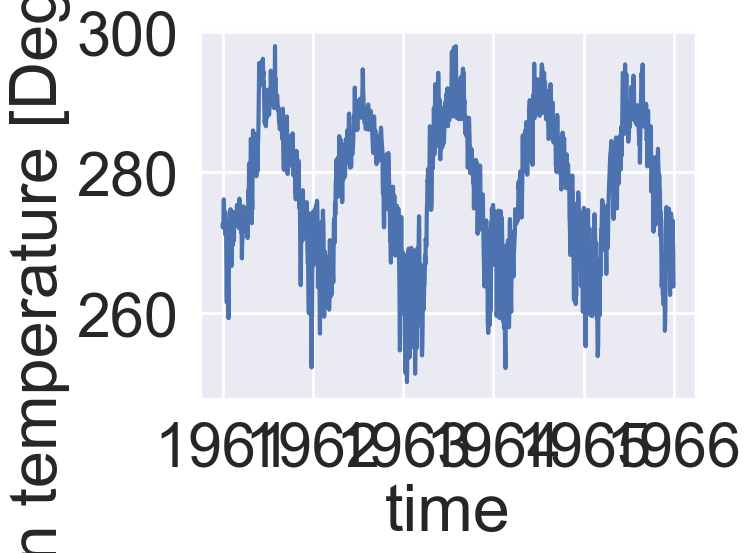

In [58]:
da_stp.tavg.sel(time=slice('1961','1965')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [61]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(285.329956)
Coordinates:
    lat       float64 8B 60.0
    lon       float64 8B 30.25
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [62]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 2.65 ms, sys: 2.06 ms, total: 4.71 ms
Wall time: 2.82 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(287.15)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [162]:
thresh.values - stp_75.values

np.float64(-1.8200439453124773)

#### St Petersburg 75th Percentile from GHCND data is 1.82 K warmer

### Try one year (2023) fit via Fourier

In [163]:
da.tavg.values[0]

NameError: name 'da' is not defined

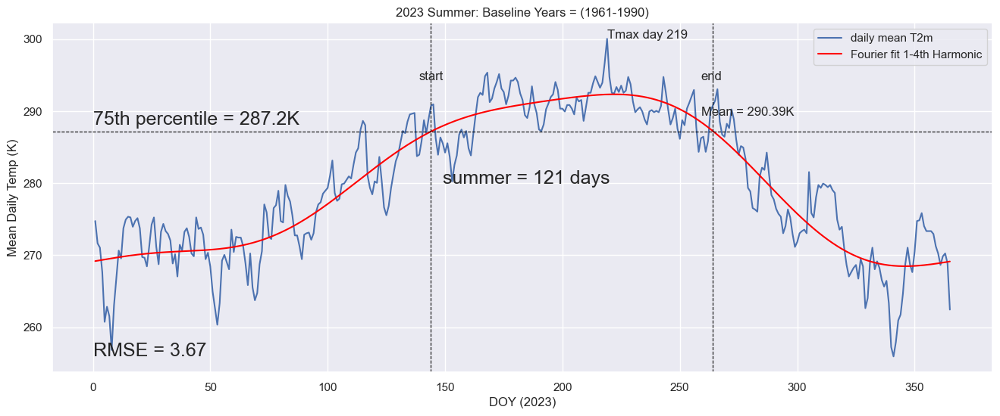

(144,
 264,
 0.16058423841016634,
 -0.26860664502149234,
 219,
 437.90000000000146,
 121,
 3.6683842001706317,
 0.0,
 290.3888429752065,
 4.379000000000019)

In [167]:
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

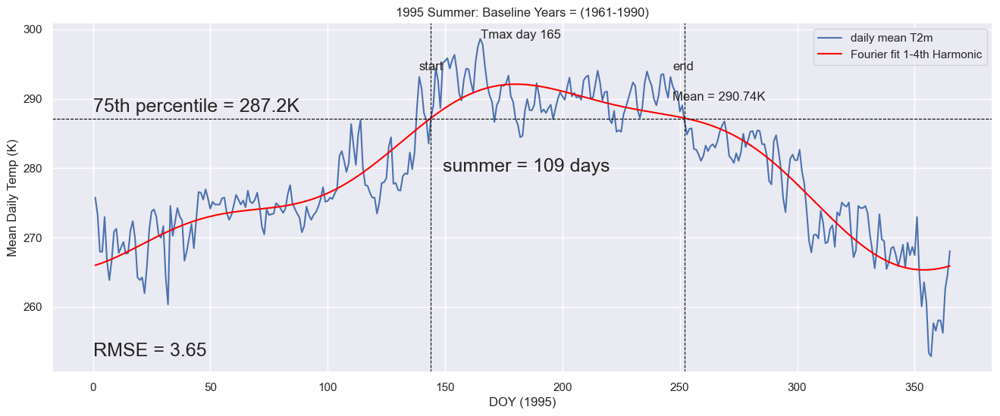

(144,
 252,
 0.2507197521059368,
 -0.07579022354443055,
 165,
 406.59999999999854,
 109,
 3.649420328476956,
 0.0,
 290.73623853211006,
 4.191752577319562)

In [168]:
# how about 1995
input_year = 1995
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Looks to be working!

### Climatology plots, 1961-2023 and 1990-2023

In [169]:
da_daily_clim_full = da_stp.tavg.groupby("time.dayofyear").mean()
da_daily_clim_an = da_stp.tavg.sel(time=slice('1990','2023')).groupby("time.dayofyear").mean()
da_daily_clim_full, da_daily_clim_an


#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()

(<xarray.DataArray 'tavg' (dayofyear: 366)> Size: 3kB
 array([268.19126984, 267.71984127, 267.36269841, 267.45634921,
        267.14365079, 266.70238095, 266.23412698, 266.90873016,
        267.41825397, 267.03730159, 266.69444444, 266.57857143,
        267.50714286, 268.28174603, 267.62619048, 267.89444444,
        267.33888889, 267.40079365, 267.1484127 , 266.46269841,
        265.80873016, 266.36428571, 266.44365079, 266.59285714,
        266.78809524, 266.31190476, 265.87698413, 265.78809524,
        265.4484127 , 266.09920635, 266.58333333, 266.47222222,
        266.7515873 , 267.17539683, 266.91666667, 266.50714286,
        265.96587302, 266.39603175, 266.96428571, 266.62460317,
        265.89444444, 265.86935484, 266.73064516, 267.50555556,
        267.47063492, 267.09761905, 267.68015873, 267.87222222,
        267.16587302, 266.35      , 266.55645161, 267.30714286,
        267.18492063, 267.60714286, 268.38650794, 268.94365079,
        268.63095238, 268.98809524, 269.12936508, 

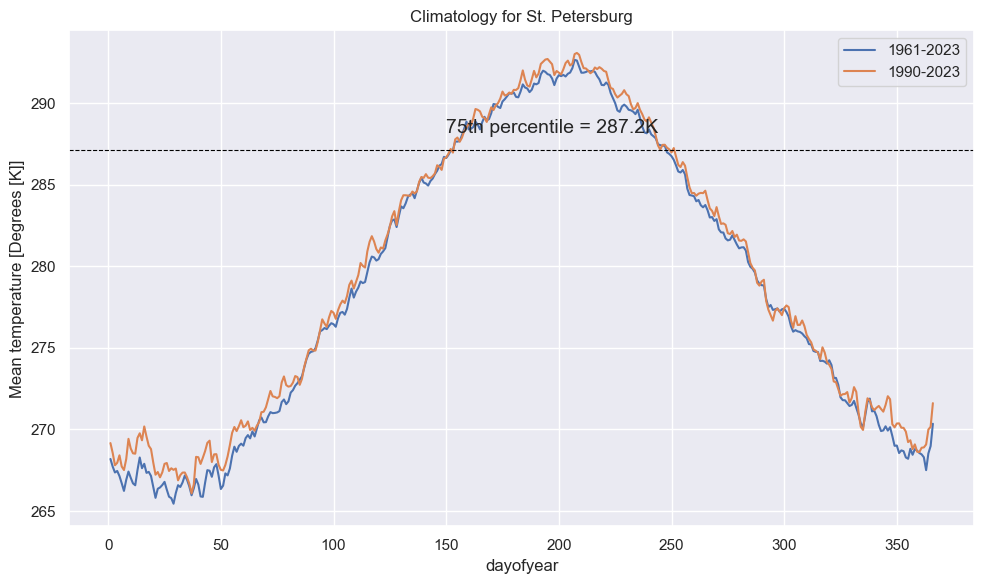

In [170]:
# plot both to compare
plt.figure(figsize=(10,6))
da_daily_clim_full.plot(label='1961-2023')
da_daily_clim_an.plot(label='1990-2023')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(150,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for St. Petersburg")
plt.tight_layout()
plt.show()

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats

In [ ]:
# testing the construction of the results DF
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})
print(df_summ)

df_tmp = pd.DataFrame({"Year":int(1990),
                        "SummerStart":4,
                        "SummerEnd":[10],
                        "SummerLength":[6],
                        "SummerAccHeat":[100],
                        "SummerTmaxDay":[5],
                        "SummerTavg":[280]})
df_summ = pd.concat([df_summ, df_tmp])
#df_summ = df_summ.set_index(["Year"])
df_summ

In [ ]:
df_summ["Year"]

In [171]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [172]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 275 ms, sys: 9.15 ms, total: 284 ms
Wall time: 307 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,146,229,0.281414,-0.127565,84,344.5,213,291.233333
1,1962,169,238,0.049403,-0.077616,70,95.5,203,288.325714
2,1963,144,260,0.150608,-0.225420,117,345.9,215,289.735470
3,1964,149,246,0.169730,-0.126963,98,242.3,166,289.295918
4,1965,170,252,0.059763,-0.179440,83,155.1,240,288.641566
5,1966,156,233,0.249116,-0.232970,78,302.2,177,291.014103
6,1967,163,253,0.192133,-0.121172,91,293.4,216,290.223626
7,1968,166,241,0.141323,-0.197757,76,216.1,171,289.523684
8,1969,166,240,0.145640,-0.176619,75,191.3,190,289.402000
9,1970,156,242,0.161865,-0.235332,87,305.2,200,290.408621


### write out resulting summer stats

In [173]:
# write out results
output_path = "../../../Data/GHCND/st_petersburg_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [59]:
# re-load 
input_path = "../../../Data/GHCND/st_petersburg_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,146,229,0.281414,-0.127565,84,344.5,213,291.233333
1,1,1962,169,238,0.049403,-0.077616,70,95.5,203,288.325714
2,2,1963,144,260,0.150608,-0.225420,117,345.9,215,289.735470
3,3,1964,149,246,0.169730,-0.126963,98,242.3,166,289.295918
4,4,1965,170,252,0.059763,-0.179440,83,155.1,240,288.641566
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,145,243,0.123754,-0.165985,99,296.3,159,289.856061
59,59,2020,151,252,0.227235,-0.107916,102,338.6,177,290.370588
60,60,2021,138,235,0.302093,-0.215440,98,537.9,171,292.294898
61,61,2022,153,249,0.246005,-0.171424,97,436.6,178,291.192268


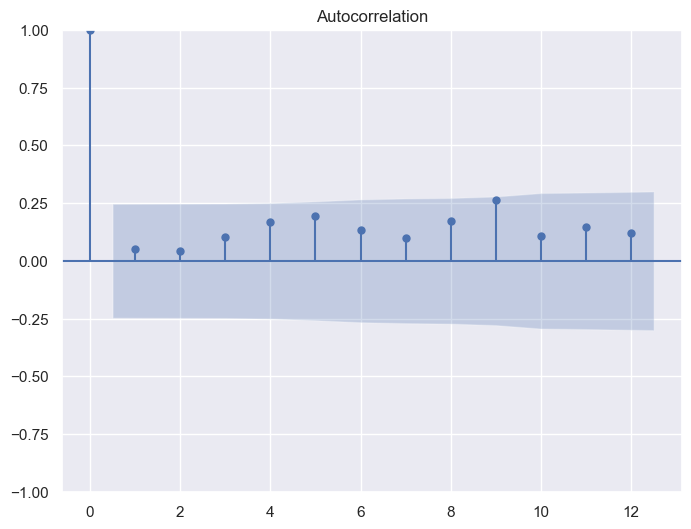

In [175]:
# set up vars to check for autocorrelation - do we need to run MK?
x = df_summ.Year
y = df_summ.SummerLength

# autocorrelation test from statsmodels
# https://www.statology.org/autocorrelation-python/
# Examples: https://github.com/mmhs013/pyMannKendall/blob/master/Examples/Example_pyMannKendall.ipynb
# https://www.statology.org/mann-kendall-test-python/¶
fig, ax = plt.subplots(figsize=(8, 6))
sm.graphics.tsa.plot_acf(y, lags=12, ax=ax);

### Autocorrelation test says NOT but we can still add the slope for comparison (and so we can say we checked). Because of the lack of autocorrelation we can use the original MK test

In [176]:
result_orig = mk.original_test(y)
print(result_orig,'\n\n')

Mann_Kendall_Test(trend='increasing', h=np.True_, p=np.float64(0.0006127288904091976), z=np.float64(3.4259164226493466), Tau=np.float64(0.29595494111623144), s=np.float64(578.0), var_s=np.float64(28366.0), slope=np.float64(0.36666666666666664), intercept=np.float64(82.63333333333334)) 




In [177]:
# will add this to the plot
result_orig.slope

np.float64(0.36666666666666664)

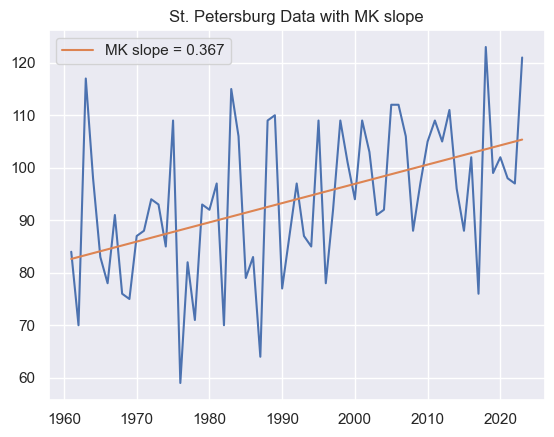

In [178]:
# quick test plot
trend_line = np.arange(len(y)) * result_orig.slope + result_orig.intercept
plt.plot(x,y)
plt.plot(x,trend_line, label="MK slope = "+str(np.round(result_orig.slope,3)))
plt.title("St. Petersburg Data with MK slope")
plt.legend()

### St. Pburg: Plot the summer stats

In [64]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

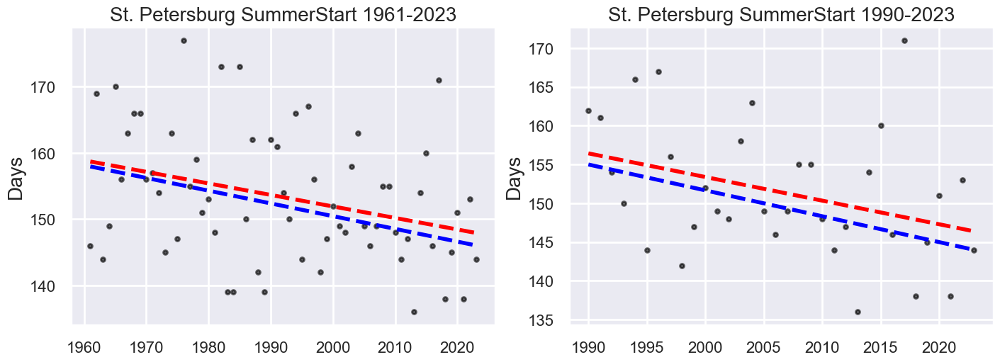

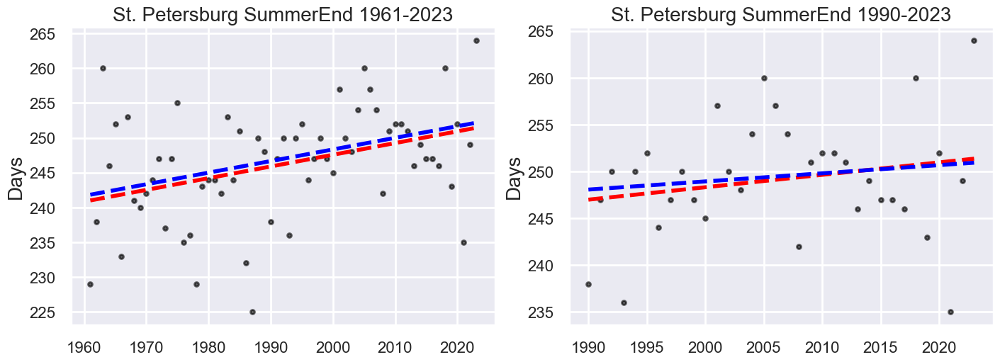

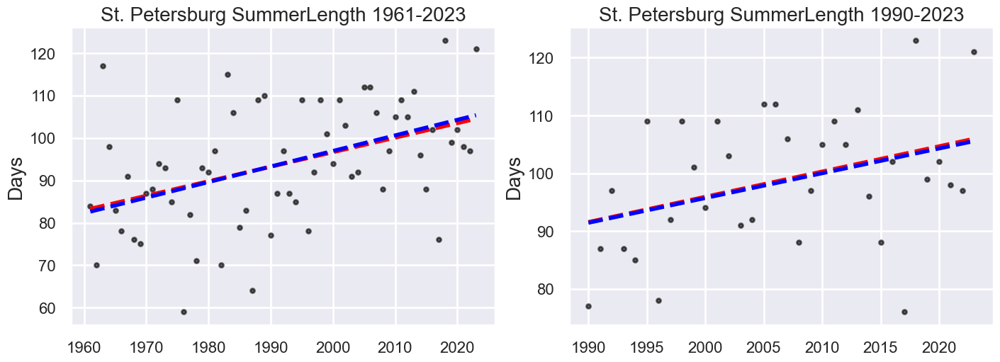

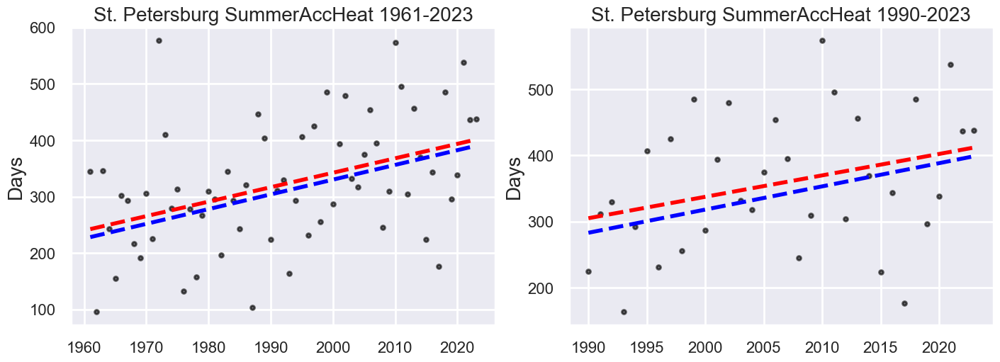

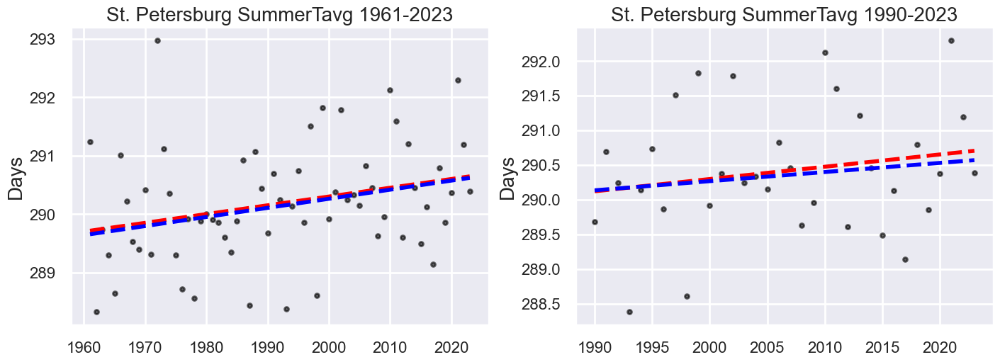

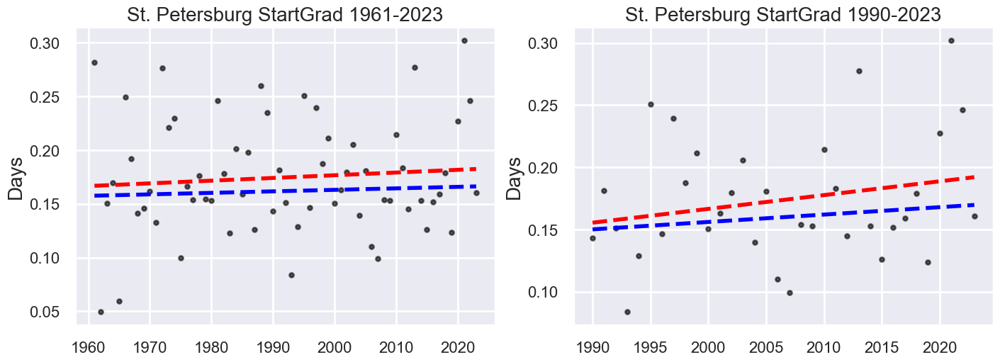

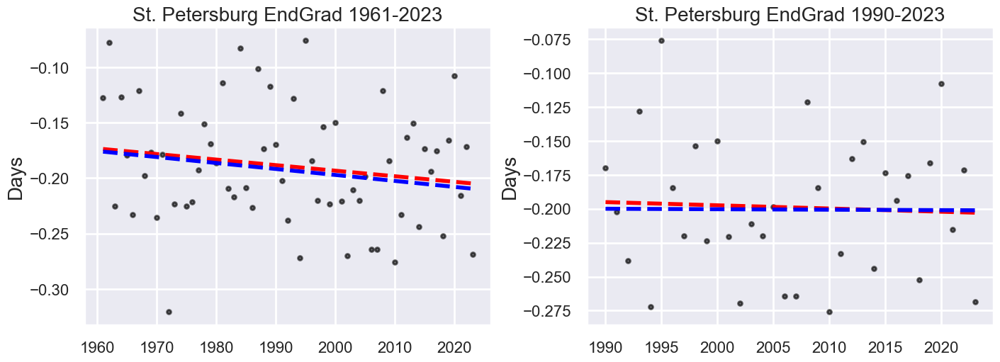

In [65]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("St. Petersburg "+v+" 1961-2023", fontsize=fs)
    #ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('Days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("St. Petersburg "+v+" 1990-2023", fontsize=fs)
    #ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('Days', fontsize=fs)
    


#### Summer Length Plot for Paper

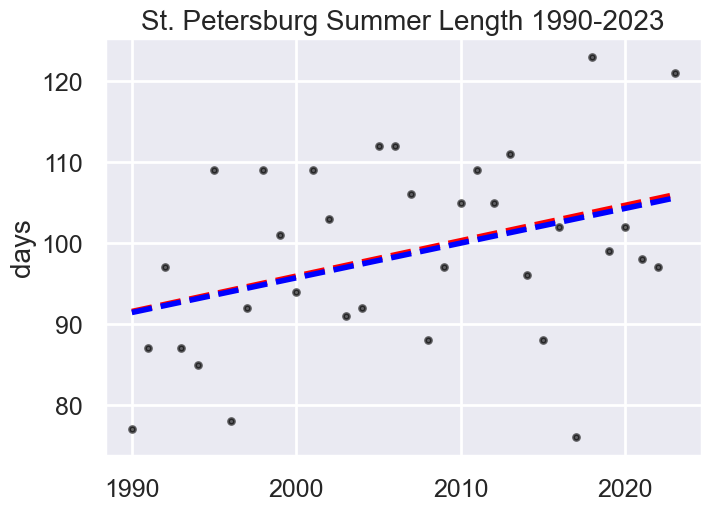

In [66]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("St. Petersburg Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/st_petersburg_summer_plot.png",bbox_inches='tight')



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [60]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 60.0
    lon      float64 8B 30.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 60.0
    lon      float64 8B 30.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 4.37 +/- 1.92
OLS Slope ERA5: 10.67 +/- 1.73


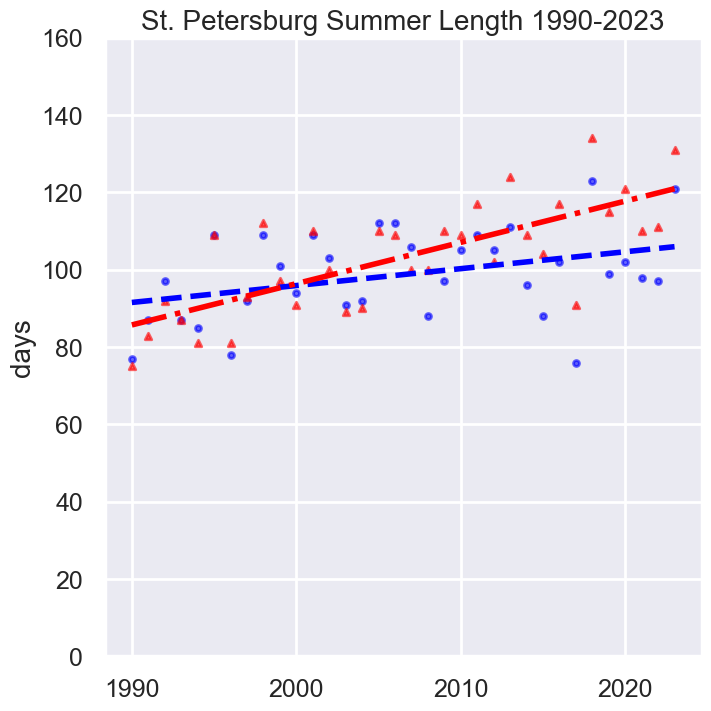

In [61]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,7), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("St. Petersburg Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(0,160)
plt.savefig("../../../Data/GHCND/Plots/st_petersburg_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/st_petersburg_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [62]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.139
Model:                            OLS   Adj. R-squared:                  0.112
Method:                 Least Squares   F-statistic:                     5.176
Date:                Wed, 11 Feb 2026   Prob (F-statistic):             0.0297
Time:                        10:32:56   Log-Likelihood:                -128.70
No. Observations:                  34   AIC:                             261.4
Df Residuals:                      32   BIC:                             264.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -778.0252    385.395     -2.019      0.0

In [63]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.542
Model:                            OLS   Adj. R-squared:                  0.528
Method:                 Least Squares   F-statistic:                     37.93
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           6.86e-07
Time:                        10:33:01   Log-Likelihood:                -125.21
No. Observations:                  34   AIC:                             254.4
Df Residuals:                      32   BIC:                             257.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2038.3444    347.751     -5.862      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: 32.38 +/- 17.549999999999997
OLS Slope ERA5: 104.59 +/- 16.39


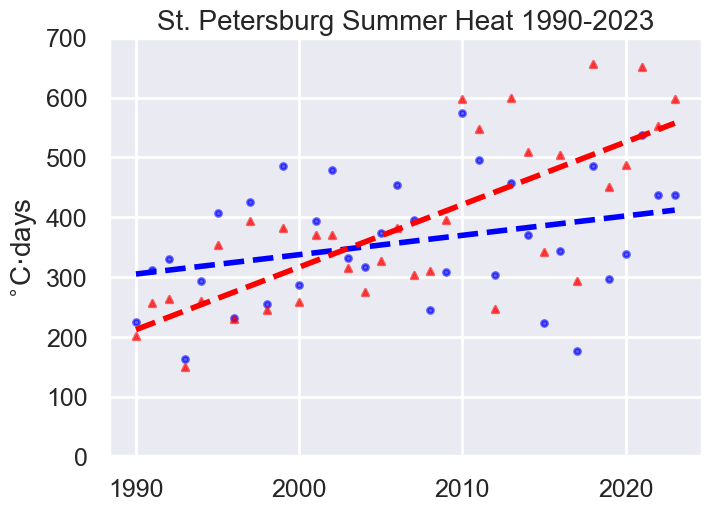

In [64]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("St. Petersburg Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/st_petersburg_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/st_petersburg_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [65]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.096
Model:                            OLS   Adj. R-squared:                  0.068
Method:                 Least Squares   F-statistic:                     3.404
Date:                Wed, 11 Feb 2026   Prob (F-statistic):             0.0743
Time:                        10:33:53   Log-Likelihood:                -203.92
No. Observations:                  34   AIC:                             411.8
Df Residuals:                      32   BIC:                             414.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -6138.0581   3521.357     -1.743      0.0

In [66]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.560
Model:                            OLS   Adj. R-squared:                  0.546
Method:                 Least Squares   F-statistic:                     40.71
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           3.62e-07
Time:                        10:33:55   Log-Likelihood:                -201.60
No. Observations:                  34   AIC:                             407.2
Df Residuals:                      32   BIC:                             410.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -2.06e+04   3289.031     -6.264      0.0

#### End Gradient with ERA5 data

In [82]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 60.0
    lon      float64 8B 30.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 60.0
    lon      float64 8B 30.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.0024000000000000002 +/- 0.0091
OLS Slope ERA5: -0.012899999999999998 +/- 0.005599999999999999


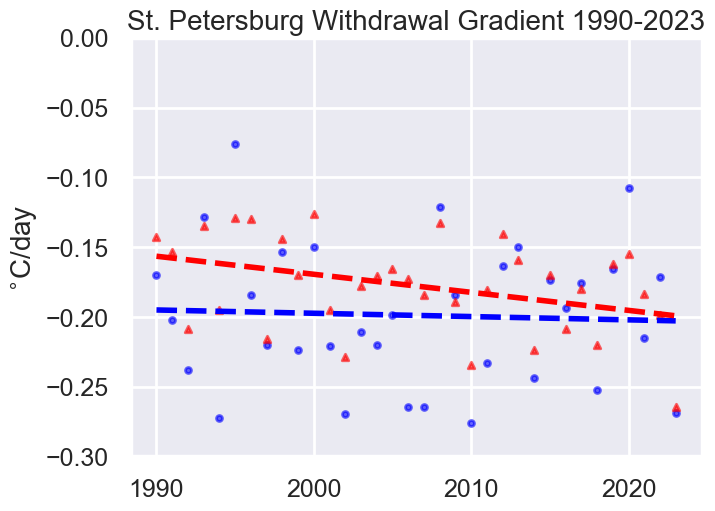

In [83]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("St. Petersburg Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/st_petersburg_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/st_petersburg_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: 0.0111 +/- 0.0086
OLS Slope ERA5: 0.024399999999999998 +/- 0.0067


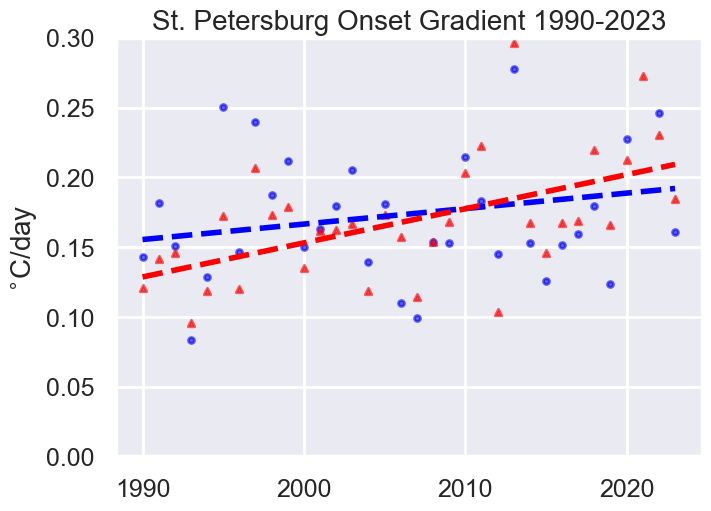

In [84]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("St. Petersburg Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/st_petersburg_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/st_petersburg_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

In [ ]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("St. Petersburg Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

## **New York (LaGuardia Airport)** has complete data

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USW00014732/detail

In [46]:
df = pd.read_csv("../../../Data/GHCND/new_york_laguardia_airport-2025-04-07T17-49-38.csv")
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,USW00014732,NaN,NaN,NaN,NaN,1961-01-01,NaN,6.7,1.1
1,USW00014732,NaN,NaN,NaN,NaN,1961-01-02,NaN,3.9,-1.7
2,USW00014732,NaN,NaN,NaN,NaN,1961-01-03,NaN,1.7,-0.6
3,USW00014732,NaN,NaN,NaN,NaN,1961-01-04,NaN,0.0,-5.0
4,USW00014732,NaN,NaN,NaN,NaN,1961-01-05,NaN,1.1,-6.1
...,...,...,...,...,...,...,...,...,...
23005,USW00014732,NaN,NaN,NaN,NaN,2023-12-27,6.7,8.9,6.1
23006,USW00014732,NaN,NaN,NaN,NaN,2023-12-28,9.5,11.1,8.3
23007,USW00014732,NaN,NaN,NaN,NaN,2023-12-29,9.8,13.3,7.8
23008,USW00014732,NaN,NaN,NaN,NaN,2023-12-30,7.2,8.3,4.4


In [216]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23010 entries, 0 to 23009
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    23010 non-null  object 
 1   NAME       0 non-null      float64
 2   LATITUDE   0 non-null      float64
 3   LONGITUDE  0 non-null      float64
 4   ELEVATION  0 non-null      float64
 5   DATE       23010 non-null  object 
 6   TAVG       6600 non-null   float64
 7   TMAX       23010 non-null  float64
 8   TMIN       23010 non-null  float64
dtypes: float64(7), object(2)
memory usage: 1.6+ MB


In [ ]:
df['TAVG'].to_list()[:5]

In [217]:
# 40.77945°, -73.88027°
df['LATITUDE'] = 40.77945
df['LONGITUDE'] = -73.88027


### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [218]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,USW00014732,NaN,40.77945,-73.88027,NaN,1961-01-01,3.90,6.7,1.1
1,USW00014732,NaN,40.77945,-73.88027,NaN,1961-01-02,1.10,3.9,-1.7
2,USW00014732,NaN,40.77945,-73.88027,NaN,1961-01-03,0.55,1.7,-0.6
3,USW00014732,NaN,40.77945,-73.88027,NaN,1961-01-04,-2.50,0.0,-5.0
4,USW00014732,NaN,40.77945,-73.88027,NaN,1961-01-05,-2.50,1.1,-6.1
...,...,...,...,...,...,...,...,...,...
23005,USW00014732,NaN,40.77945,-73.88027,NaN,2023-12-27,6.70,8.9,6.1
23006,USW00014732,NaN,40.77945,-73.88027,NaN,2023-12-28,9.50,11.1,8.3
23007,USW00014732,NaN,40.77945,-73.88027,NaN,2023-12-29,9.80,13.3,7.8
23008,USW00014732,NaN,40.77945,-73.88027,NaN,2023-12-30,7.20,8.3,4.4


In [219]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,277.05
1961-01-02,274.25
1961-01-03,273.70
1961-01-04,270.65
1961-01-05,270.65
...,...
2023-12-27,279.85
2023-12-28,282.65
2023-12-29,282.95


### Convert from Pandas to XArray

In [220]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 368kB
Dimensions:  (time: 23010)
Coordinates:
  * time     (time) datetime64[ns] 184kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 184kB 277.0 274.2 273.7 270.6 ... 282.9 280.3 278.5

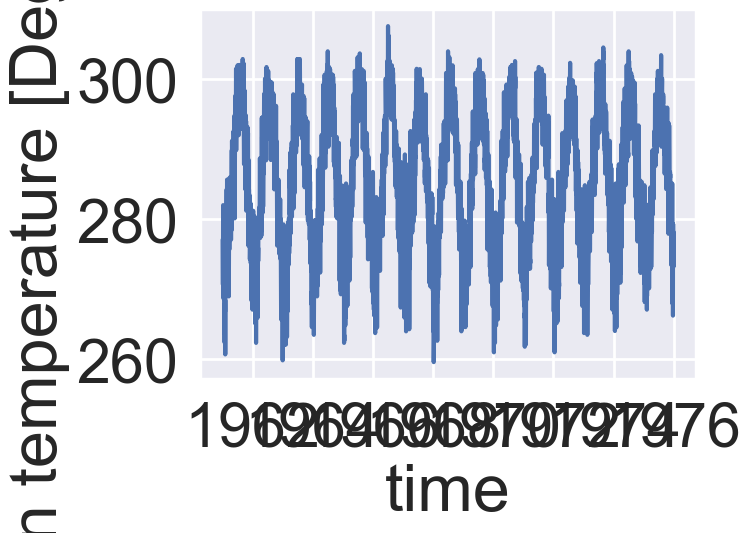

In [221]:
da_stp.tavg.sel(time=slice('1961','1975')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [222]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(293.660675)
Coordinates:
    lat       float64 8B 40.75
    lon       float64 8B -74.0
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [223]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 3.44 ms, sys: 3.81 ms, total: 7.25 ms
Wall time: 5.64 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(294.8)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [224]:
thresh.values - stp_75.values

np.float64(-1.1393249511718295)

#### New York LaGuardia 75th Percentile from GHCND data is 1.14 K warmer

### Try one year (2023) fit via Fourier

In [ ]:
da.tavg.values[0]

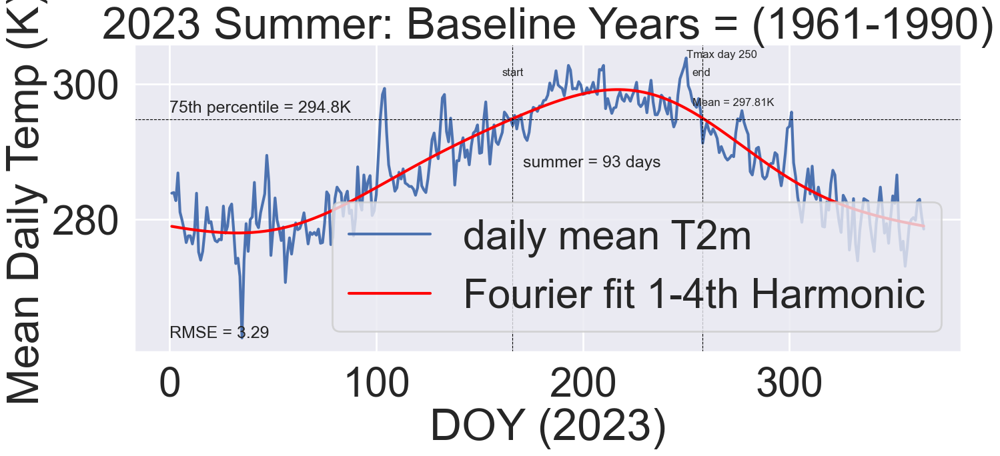

(166,
 258,
 0.13047106878963177,
 -0.19652276884912112,
 250,
 297.09999999999854,
 93,
 3.2910892063515713,
 0.0,
 297.808064516129,
 3.5369047619047365)

In [225]:
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

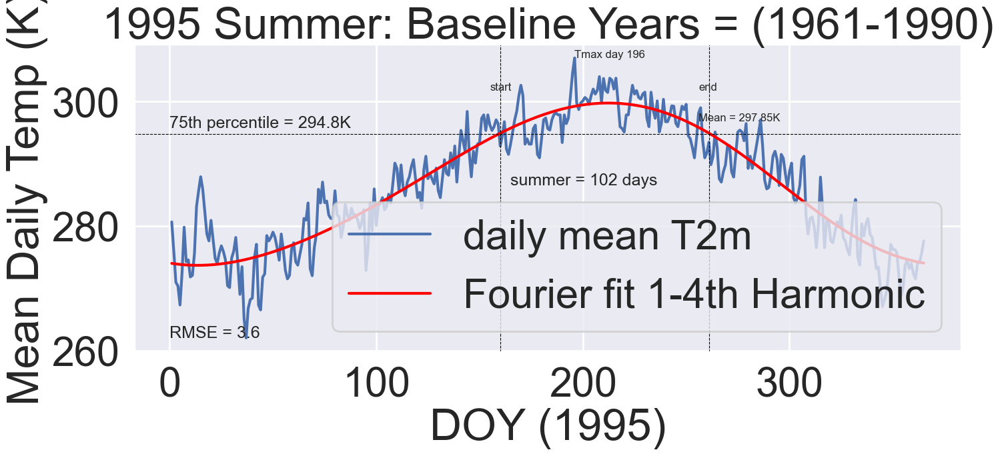

(160,
 261,
 0.1653997799116098,
 -0.19612539002201856,
 196,
 355.8999999999978,
 102,
 3.5965572986437655,
 0.0,
 297.8475490196078,
 4.448749999999961)

In [226]:
# how about 1995
input_year = 1995
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Looks to be working!

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats

In [227]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [228]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 557 ms, sys: 87.4 ms, total: 644 ms
Wall time: 688 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,171,261,0.158304,-0.143645,91,257.20,245,297.128571
1,1962,157,234,0.119207,-0.081337,78,137.35,169,295.992949
2,1963,169,239,0.153723,-0.129120,71,176.25,178,296.953521
3,1964,160,244,0.139185,-0.128892,85,207.30,182,296.884118
4,1965,156,251,0.134587,-0.166897,96,263.10,206,297.075521
5,1966,161,248,0.254079,-0.202357,88,366.85,184,298.792614
6,1967,174,247,0.124966,-0.153736,74,148.65,205,296.326351
7,1968,174,256,0.146480,-0.160547,83,220.15,182,297.046386
8,1969,171,252,0.088631,-0.157639,82,186.55,198,296.524390
9,1970,167,258,0.141932,-0.153621,92,249.30,228,297.053804


### write out resulting summer stats

In [229]:
# write out results
output_path = "../../../Data/GHCND/new_york_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [47]:
# re-load 
input_path = "../../../Data/GHCND/new_york_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,171,261,0.158304,-0.143645,91,257.20,245,297.128571
1,1,1962,157,234,0.119207,-0.081337,78,137.35,169,295.992949
2,2,1963,169,239,0.153723,-0.129120,71,176.25,178,296.953521
3,3,1964,160,244,0.139185,-0.128892,85,207.30,182,296.884118
4,4,1965,156,251,0.134587,-0.166897,96,263.10,206,297.075521
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,160,259,0.170115,-0.204791,100,344.85,202,297.941000
59,59,2020,160,256,0.262661,-0.177419,97,428.15,208,299.122165
60,60,2021,159,266,0.127543,-0.181741,108,355.20,181,297.871296
61,61,2022,162,255,0.215994,-0.183287,94,366.75,201,298.554255


### New York: Plot the summer stats

In [231]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

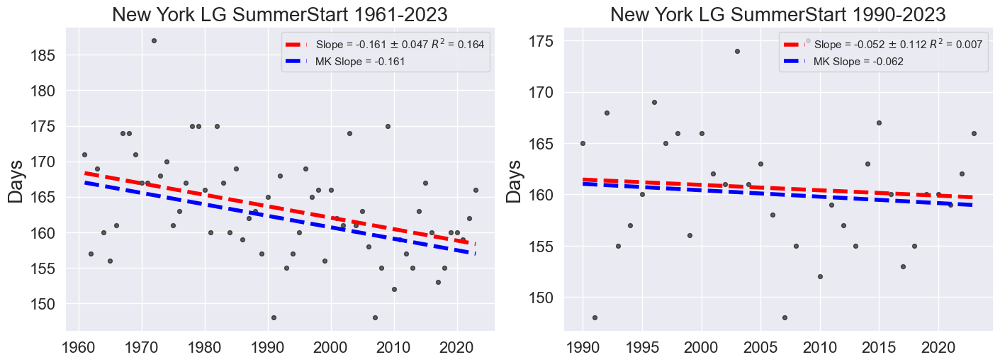

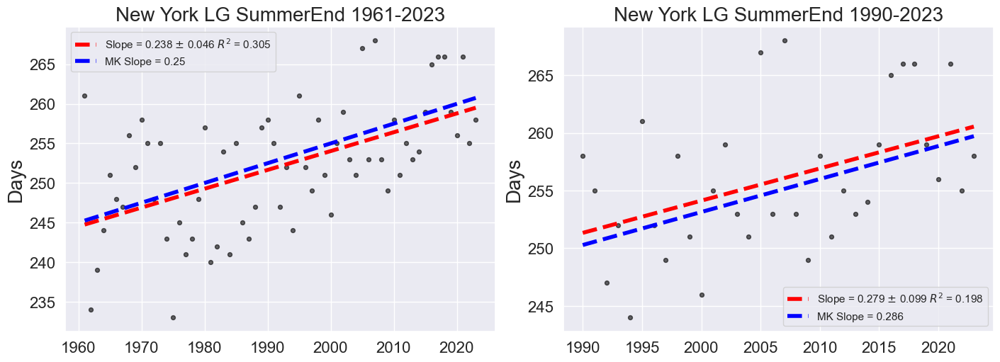

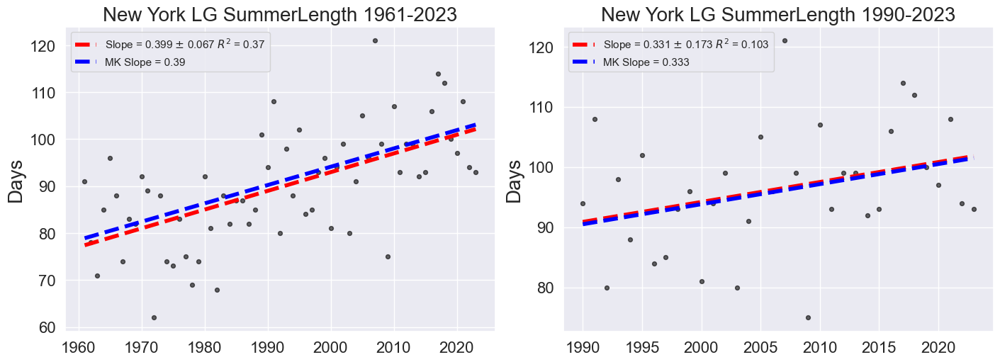

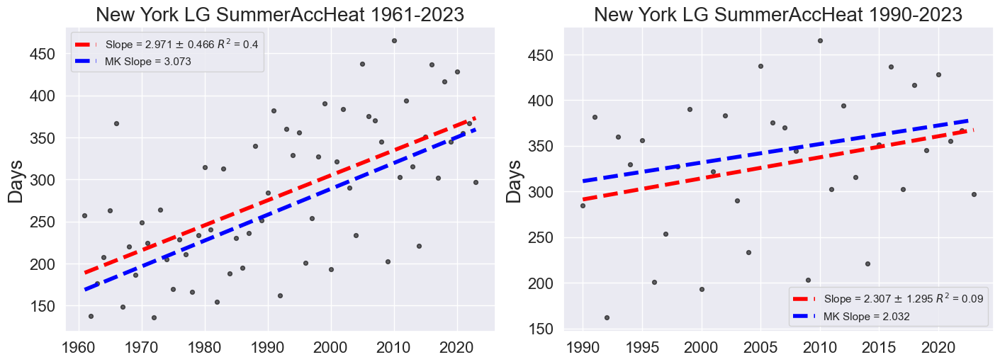

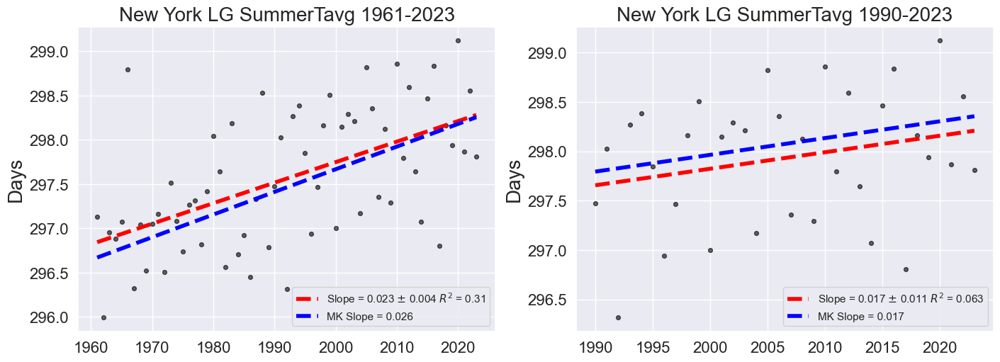

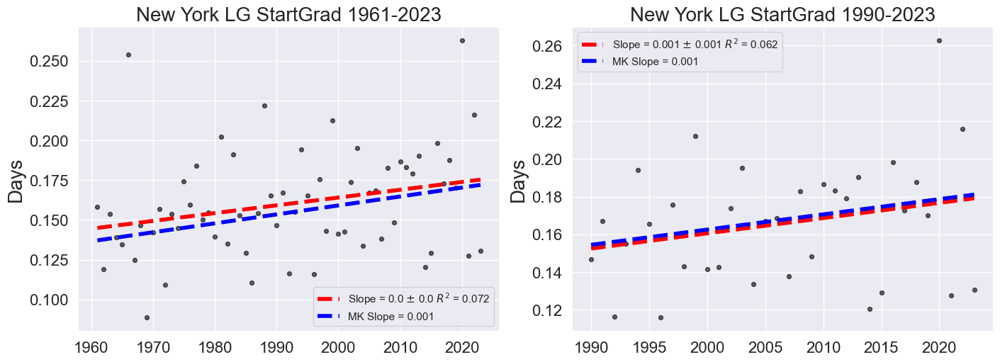

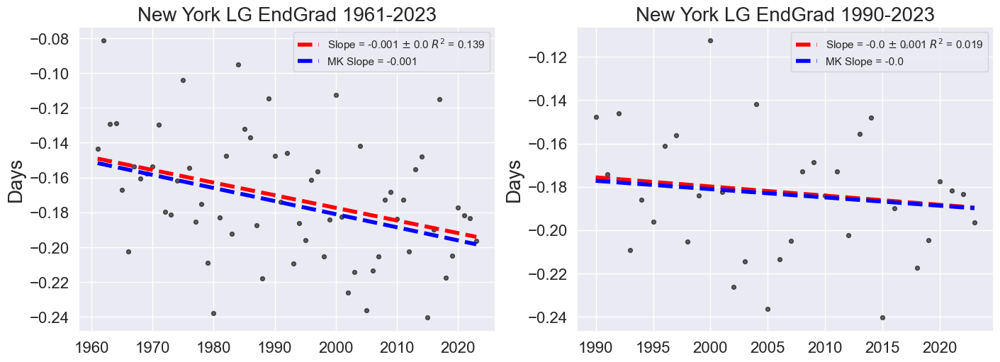

In [48]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("New York LG "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('Days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("New York LG "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('Days', fontsize=fs)
    


#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [49]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 90.0
    lon      float64 8B 179.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 90.0
    lon      float64 8B 179.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 3.31 +/- 1.73
OLS Slope ERA5: 1.1 +/- 1.43


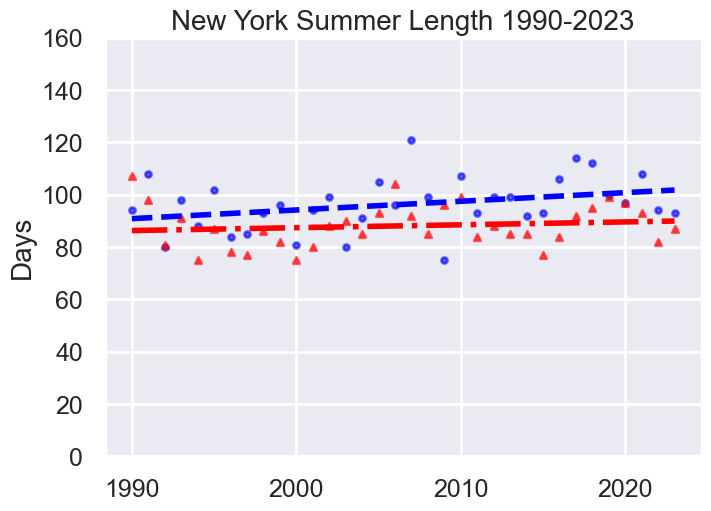

In [50]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("New York Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)
ax2.set_ylim(0,160)
plt.savefig("../../../Data/GHCND/Plots/new_york_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/new_york_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Accumulated Heat with ERA5 data

OLS Slope: 23.07 +/- 12.95
OLS Slope ERA5: 2.18 +/- 3.76


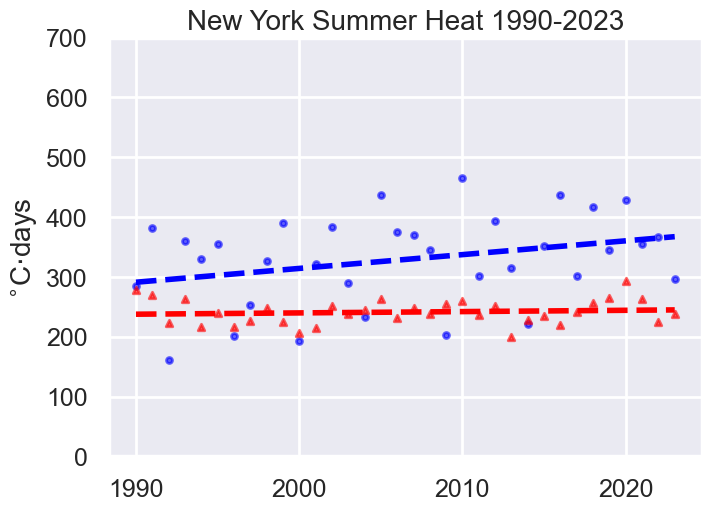

In [51]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("New York Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/new_york_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/new_york_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### End Gradient with ERA5 data

In [52]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 90.0
    lon      float64 8B 179.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 90.0
    lon      float64 8B 179.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.004200000000000001 +/- 0.0054
OLS Slope ERA5: 0.0138 +/- 0.0047


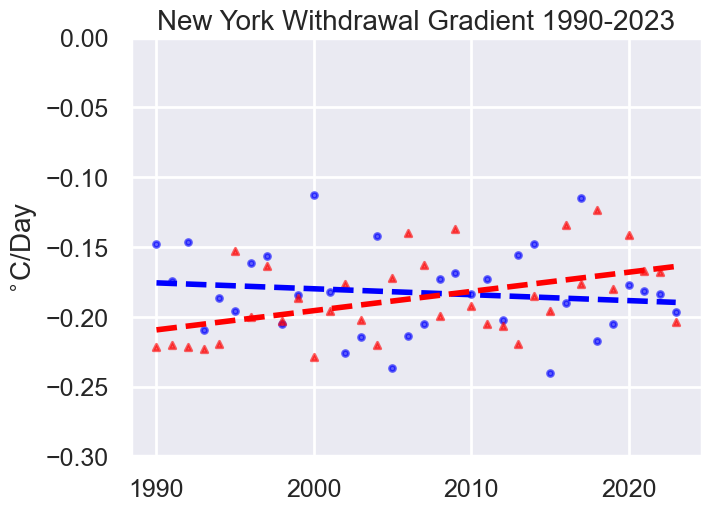

In [55]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("New York Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/Day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/new_york_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/new_york_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: 0.0081 +/- 0.005599999999999999
OLS Slope ERA5: -0.0039 +/- 0.0039


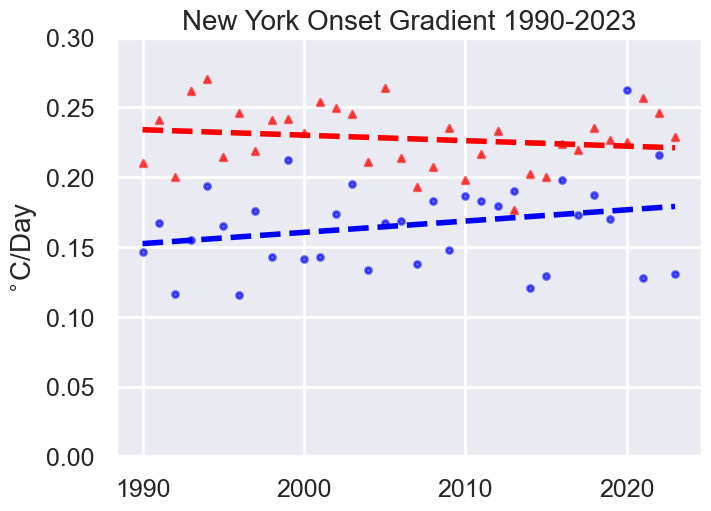

In [54]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("New York Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/Day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/new_york_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/new_york_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



## **Cordoba, Argentina (Airport)** has complete data

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:AR000087344/detail

### This is in the SH so we need 2024

In [67]:
df = pd.read_csv("../../../Data/GHCND/cordoba_argentina-2025-04-08T18-09-00.csv")
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,1961-01-01,NaN,NaN,16.4
1,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,1961-01-02,NaN,NaN,18.4
2,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,1961-01-03,NaN,NaN,12.6
3,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,1961-01-04,NaN,NaN,10.4
4,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,1961-01-05,NaN,NaN,14.4
...,...,...,...,...,...,...,...,...,...
23359,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,2024-12-27,22.1,NaN,11.4
23360,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,2024-12-28,22.8,31.0,16.1
23361,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,2024-12-29,23.2,NaN,15.7
23362,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,2024-12-30,23.3,NaN,15.3


### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [240]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,1961-01-01,NaN,NaN,16.4
1,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,1961-01-02,NaN,NaN,18.4
2,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,1961-01-03,NaN,NaN,12.6
3,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,1961-01-04,NaN,NaN,10.4
4,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,1961-01-05,NaN,NaN,14.4
...,...,...,...,...,...,...,...,...,...
23359,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,2024-12-27,22.1,NaN,11.4
23360,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,2024-12-28,22.8,31.0,16.1
23361,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,2024-12-29,23.2,NaN,15.7
23362,AR000087344,"CORDOBA AERO, AR",-31.317,-64.217,489.0,2024-12-30,23.3,NaN,15.3


#### Still some empty TAVG during 1961 but we have enough I think

In [241]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,NaN
1961-01-02,NaN
1961-01-03,NaN
1961-01-04,NaN
1961-01-05,NaN
...,...
2024-12-27,295.25
2024-12-28,295.95
2024-12-29,296.35


In [242]:
#pd.set_option('display.max_rows', 500)
df_sub['tavg'].tail(357)


time
2024-01-01    296.05
2024-01-02    296.65
2024-01-03    297.85
2024-01-04    298.45
2024-01-05    298.55
2024-01-06    296.75
2024-01-07    294.55
2024-01-08    296.25
2024-01-09    295.15
2024-01-10    296.65
2024-01-11    293.55
2024-01-12    294.95
2024-01-13    297.95
2024-01-14    297.45
2024-01-15    295.45
2024-01-16    295.05
2024-01-17    294.25
2024-01-18    295.75
2024-01-19    297.75
2024-01-20    295.05
2024-01-21    294.05
2024-01-22    293.85
2024-01-23    294.35
2024-01-24    295.05
2024-01-25    296.45
2024-01-26    296.35
2024-01-27    295.85
2024-01-28    296.55
2024-01-29    298.35
2024-01-30    299.65
2024-01-31    300.05
2024-02-01    300.15
2024-02-02    300.05
2024-02-03    302.05
2024-02-04    296.95
2024-02-05    297.55
2024-02-06    302.25
2024-02-07    302.15
2024-02-08    300.05
2024-02-09    294.55
2024-02-10    297.35
2024-02-11    298.45
2024-02-12    295.85
2024-02-13    291.95
2024-02-14    290.25
2024-02-15    293.35
2024-02-16    295.35
2024-02-

In [243]:
pd.reset_option('display.max_rows')

#### The following 9 rows are missing from 2024: 3/28-3/31, 11/18-11/21, 12/1

#### Will fill them in with NaN and then use linear interpolation to fill them in since FFT can't work with missing data

In [244]:
df_missing = pd.DataFrame({'time':pd.to_datetime(['2024-03-28','2024-03-29','2024-03-30','2024-03-31','2024-11-18','2024-11-19','2024-11-20','2024-11-21','2024-12-01']),
                           'tavg':np.repeat(np.nan, 9)})
df_missing = df_missing.set_index(['time'])
df_missing
                                                 

,tavg
time,
2024-03-28,NaN
2024-03-29,NaN
2024-03-30,NaN
2024-03-31,NaN
2024-11-18,NaN
2024-11-19,NaN
2024-11-20,NaN
2024-11-21,NaN
2024-12-01,NaN


In [245]:
df_sub = pd.concat([df_sub, df_missing], axis=0).sort_index()
df_sub

,tavg
time,
1961-01-01,NaN
1961-01-02,NaN
1961-01-03,NaN
1961-01-04,NaN
1961-01-05,NaN
...,...
2024-12-27,295.25
2024-12-28,295.95
2024-12-29,296.35


In [246]:
# linear interpolation
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
df_sub.head(10),df_sub.tail(40)

(            tavg
 time            
 1961-01-01   NaN
 1961-01-02   NaN
 1961-01-03   NaN
 1961-01-04   NaN
 1961-01-05   NaN
 1961-01-06   NaN
 1961-01-07   NaN
 1961-01-08   NaN
 1961-01-09   NaN
 1961-01-10   NaN,
               tavg
 time              
 2024-11-22  295.55
 2024-11-23  296.55
 2024-11-24  300.35
 2024-11-25  295.25
 2024-11-26  296.55
 2024-11-27  295.05
 2024-11-28  295.15
 2024-11-29  289.55
 2024-11-30  289.85
 2024-12-01  290.35
 2024-12-02  290.85
 2024-12-03  287.85
 2024-12-04  294.25
 2024-12-05  298.25
 2024-12-06  297.15
 2024-12-07  291.65
 2024-12-08  289.45
 2024-12-09  291.85
 2024-12-10  295.75
 2024-12-11  296.75
 2024-12-12  299.35
 2024-12-13  293.85
 2024-12-14  296.35
 2024-12-15  295.95
 2024-12-16  295.35
 2024-12-17  295.95
 2024-12-18  292.75
 2024-12-19  294.25
 2024-12-20  296.95
 2024-12-21  291.75
 2024-12-22  292.95
 2024-12-23  296.85
 2024-12-24  294.95
 2024-12-25  293.85
 2024-12-26  293.45
 2024-12-27  295.25
 2024-12-28  295.95
 20

In [247]:
df1 = df_sub[df_sub.isna().any(axis=1)]
print(df1)

            tavg
time            
1961-01-01   NaN
1961-01-02   NaN
1961-01-03   NaN
1961-01-04   NaN
1961-01-05   NaN
...          ...
1961-05-27   NaN
1961-05-28   NaN
1961-05-29   NaN
1961-05-30   NaN
1961-05-31   NaN

[150 rows x 1 columns]


#### 1961 can't be fixed by interpolation but since this is in the SH and the "year" doesn't start until June 30 in my analysis, we can still get the summer of 1961 (I think)

### Convert from Pandas to XArray

In [248]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 374kB
Dimensions:  (time: 23373)
Coordinates:
  * time     (time) datetime64[ns] 187kB 1961-01-01 1961-01-02 ... 2024-12-31
Data variables:
    tavg     (time) float64 187kB nan nan nan nan ... 295.9 296.3 296.4 298.0

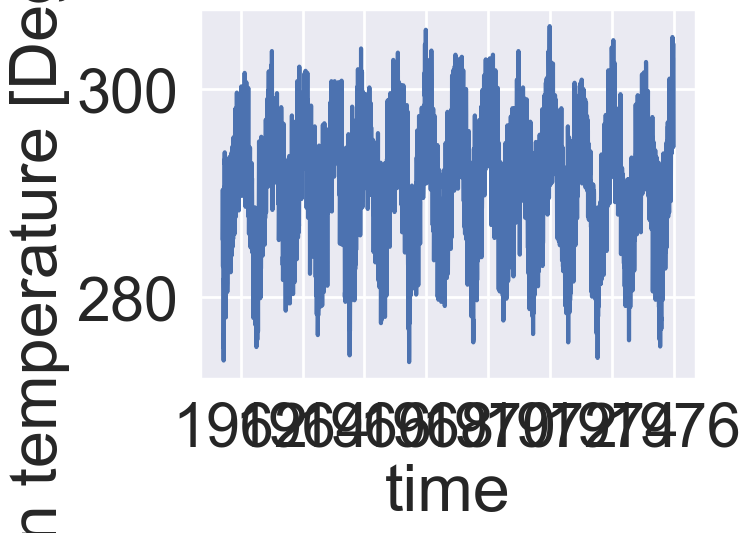

In [249]:
da_stp.tavg.sel(time=slice('1961','1975')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [250]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(293.82132)
Coordinates:
    lat       float64 8B -31.25
    lon       float64 8B -64.25
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [251]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 4.25 ms, sys: 1.88 ms, total: 6.13 ms
Wall time: 3.96 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(294.95)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [252]:
thresh.values - stp_75.values

np.float64(-1.1286804199218636)

#### Cordoba, Argentina 75th Percentile from GHCND data is 1.13 K warmer

### Try one year (2023) fit via Fourier

In [ ]:
da.tavg.values[0]

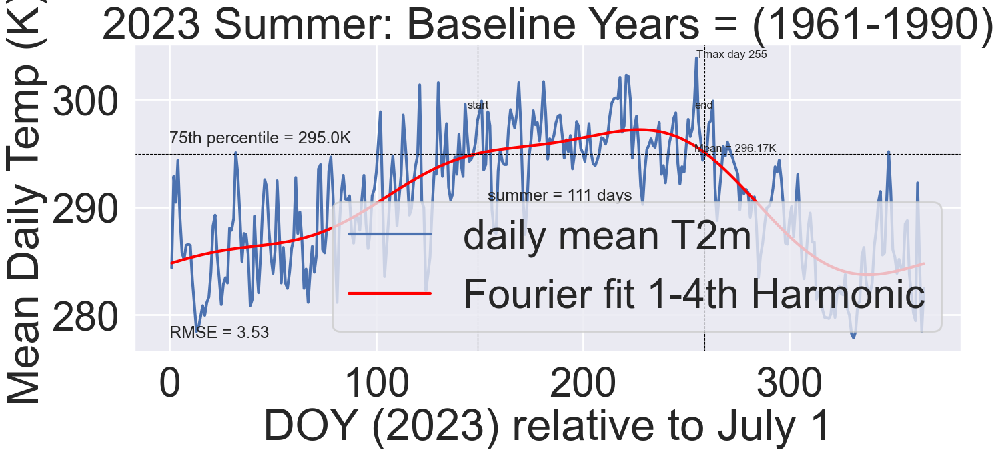

(149,
 259,
 0.041992530428160535,
 -0.14681511676161563,
 255,
 207.40000000000146,
 111,
 3.5303382803271712,
 0.0,
 296.17162162162157,
 2.6935064935065043)

In [253]:
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the SH we DO need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, False)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

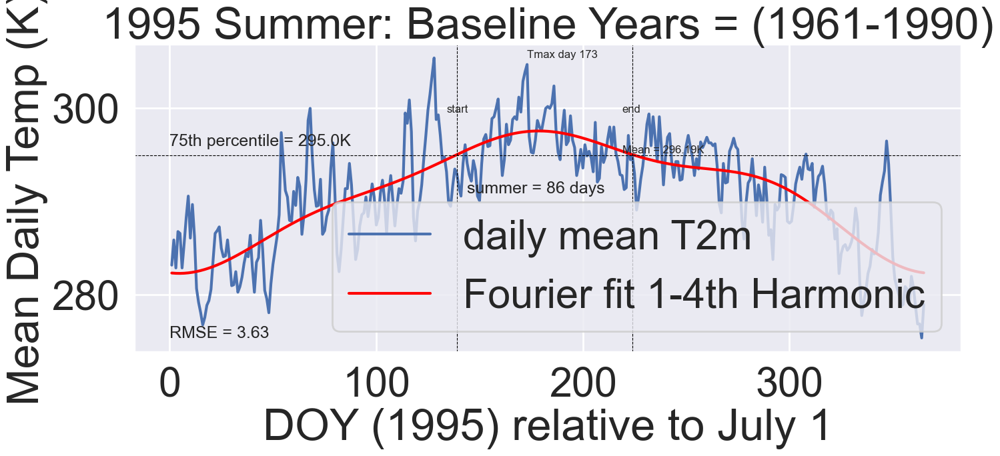

(139,
 224,
 0.10369469460306391,
 -0.06887799774548853,
 173,
 164.70000000000073,
 86,
 3.6252351204901916,
 0.0,
 296.1872093023256,
 3.0500000000000114)

In [254]:
# how about 1995
input_year = 1995
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, False)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Climatology plots, 1961-2023 and 1990-2023

In [255]:
da_daily_clim_full = da_stp.tavg.groupby("time.dayofyear").mean()
da_daily_clim_an = da_stp.tavg.sel(time=slice('1990','2023')).groupby("time.dayofyear").mean()
da_daily_clim_full, da_daily_clim_an


#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()

(<xarray.DataArray 'tavg' (dayofyear: 366)> Size: 3kB
 array([296.37857143, 296.22460317, 296.60992063, 297.2547619 ,
        296.94761905, 296.73253968, 296.52222222, 296.7015873 ,
        296.76349206, 296.49365079, 296.2984127 , 296.47460317,
        296.37380952, 296.53015873, 296.76825397, 296.82777778,
        296.59206349, 296.1452381 , 296.74761905, 296.69444444,
        296.64206349, 296.73492063, 296.91904762, 296.49920635,
        296.47063492, 296.56111111, 296.7015873 , 296.86428571,
        296.46507937, 296.67698413, 296.43809524, 296.00396825,
        295.90079365, 295.89920635, 295.82777778, 295.67380952,
        295.74126984, 295.85079365, 295.68095238, 295.48571429,
        295.12063492, 294.91451613, 294.86532258, 294.9468254 ,
        295.38015873, 295.34761905, 295.97698413, 295.78809524,
        295.28333333, 295.38571429, 295.12063492, 294.9515873 ,
        295.24920635, 295.28492063, 295.07936508, 295.16825397,
        295.54603175, 295.57539683, 295.52460317, 

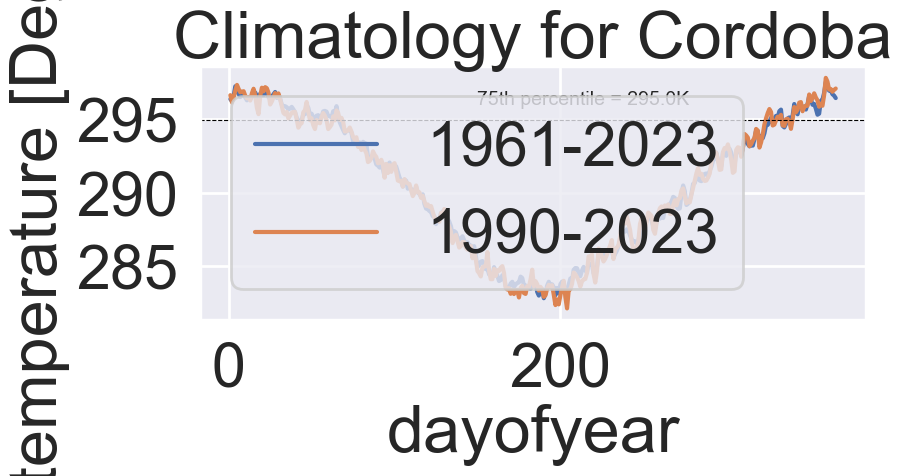

In [256]:
# plot both to compare
plt.figure(figsize=(10,6))
da_daily_clim_full.plot(label='1961-2023')
da_daily_clim_an.plot(label='1990-2023')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(150,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for Cordoba")
plt.tight_layout()
plt.show()

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats

In [ ]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

In [257]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the SH we need a next year
    da_next = da_stp.sel(time=str(input_year+1))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, False)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[grad_start],
                        "EndGrad":[grad_end],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 319 ms, sys: 10.5 ms, total: 330 ms
Wall time: 327 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,153,259,0.046881,-0.071555,107,132.300,231,295.419159
1,1962,142,233,0.088768,-0.056901,92,174.850,188,296.392935
2,1963,171,235,0.098320,-0.074802,65,97.650,220,295.805385
3,1964,172,253,0.072436,-0.121681,82,149.325,198,296.271646
4,1965,150,228,0.049794,-0.043383,79,110.000,151,295.478481
...,...,...,...,...,...,...,...,...,...
58,2019,140,242,0.087117,-0.050274,103,162.950,164,295.902913
59,2020,149,217,0.056845,-0.036075,69,82.900,163,295.287681
60,2021,145,230,0.126338,-0.105514,86,214.500,198,296.776744
61,2022,137,263,0.137002,-0.064311,127,336.900,160,297.105906


### write out resulting summer stats

In [258]:
# write out results
output_path = "../../../Data/GHCND/cordoba_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [68]:
# re-load 
input_path = "../../../Data/GHCND/cordoba_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,153,259,0.046881,-0.071555,107,132.300,231,295.419159
1,1,1962,142,233,0.088768,-0.056901,92,174.850,188,296.392935
2,2,1963,171,235,0.098320,-0.074802,65,97.650,220,295.805385
3,3,1964,172,253,0.072436,-0.121681,82,149.325,198,296.271646
4,4,1965,150,228,0.049794,-0.043383,79,110.000,151,295.478481
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,140,242,0.087117,-0.050274,103,162.950,164,295.902913
59,59,2020,149,217,0.056845,-0.036075,69,82.900,163,295.287681
60,60,2021,145,230,0.126338,-0.105514,86,214.500,198,296.776744
61,61,2022,137,263,0.137002,-0.064311,127,336.900,160,297.105906


### Cordoba: Plot the summer stats

In [73]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

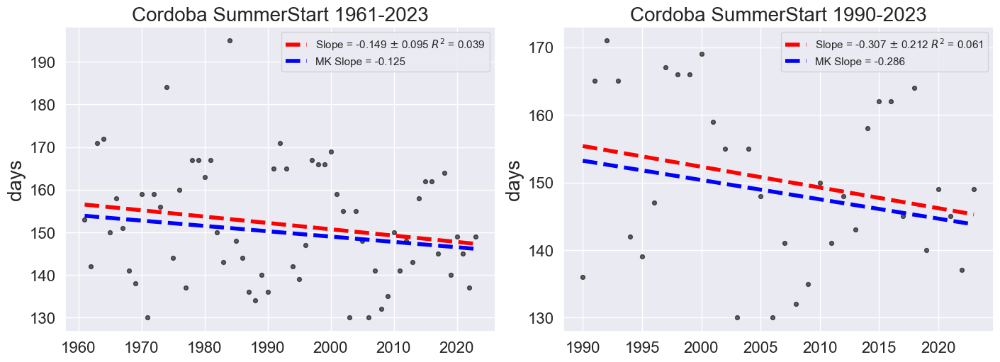

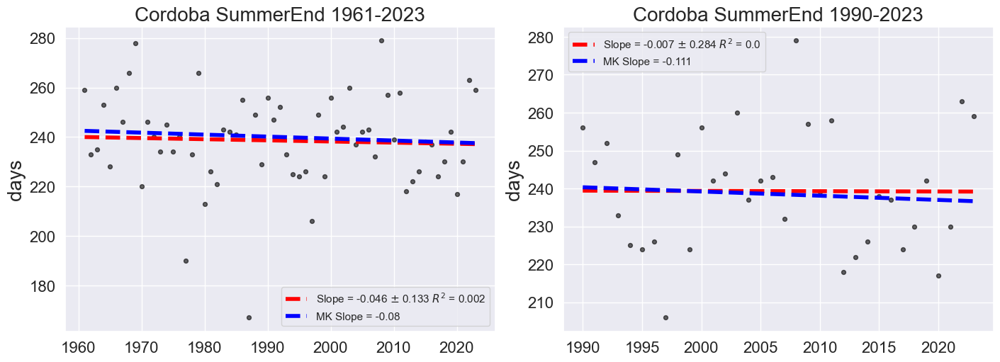

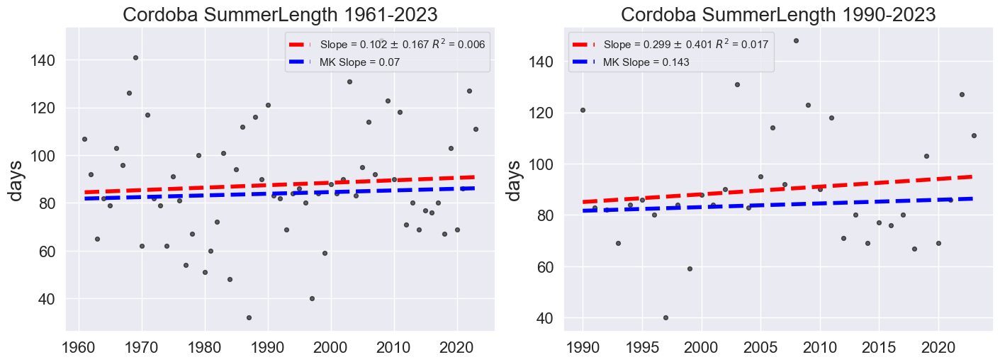

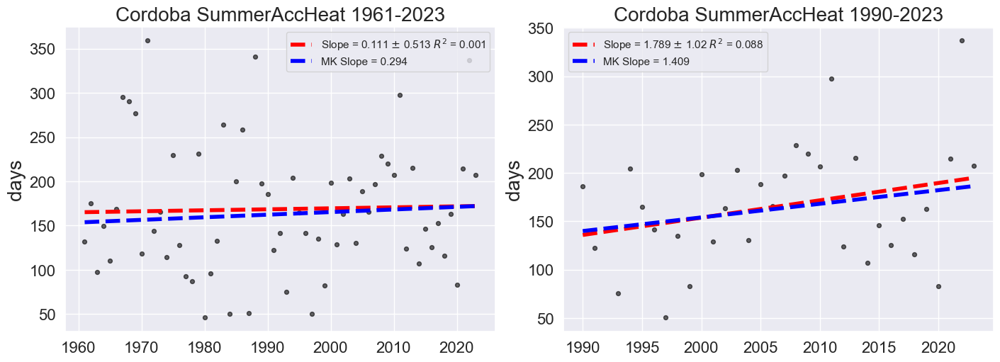

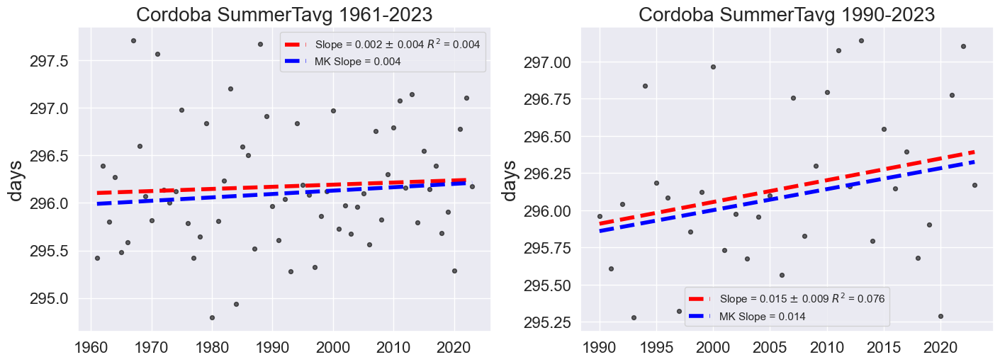

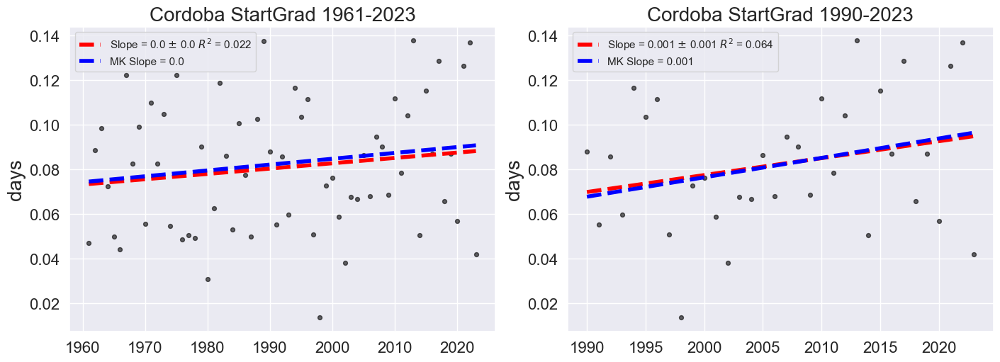

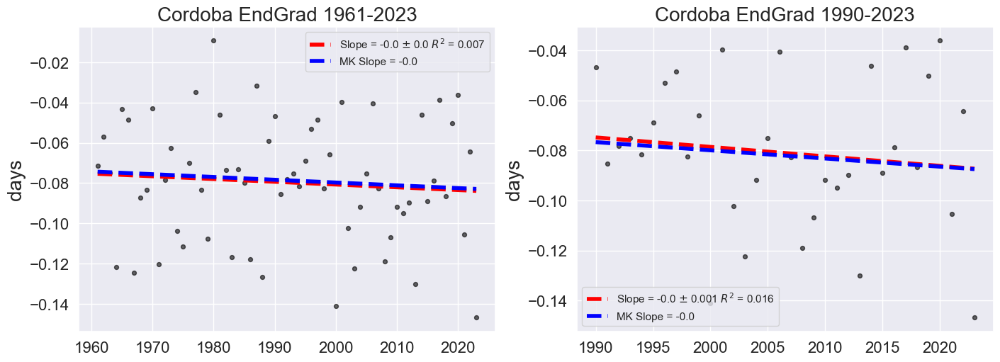

In [74]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Cordoba "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Cordoba "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


### Cordoba isn't the best candidate given the very narrow range of temps and nearly flat slopes for the metrics - will have to find another SH inland site?

#### Summer Length Plot for Paper

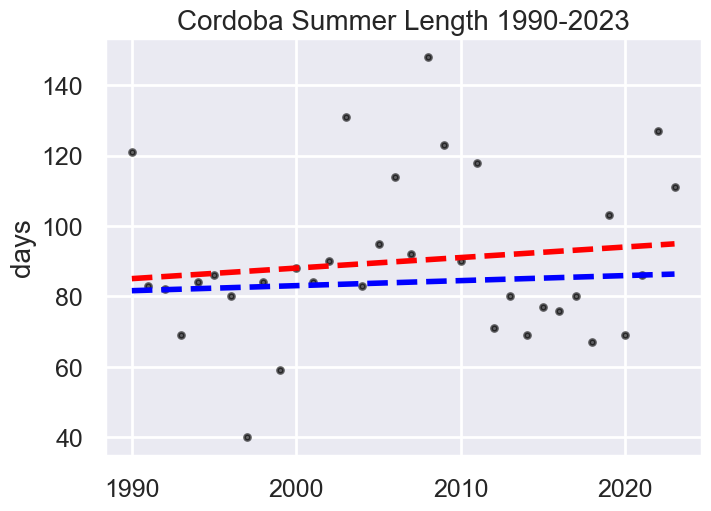

In [75]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Cordoba Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/cordoba_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [69]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -31.25
    lon      float64 8B -64.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -31.25
    lon      float64 8B -64.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 2.9899999999999998 +/- 4.01
OLS Slope ERA5: 10.42 +/- 3.4200000000000004


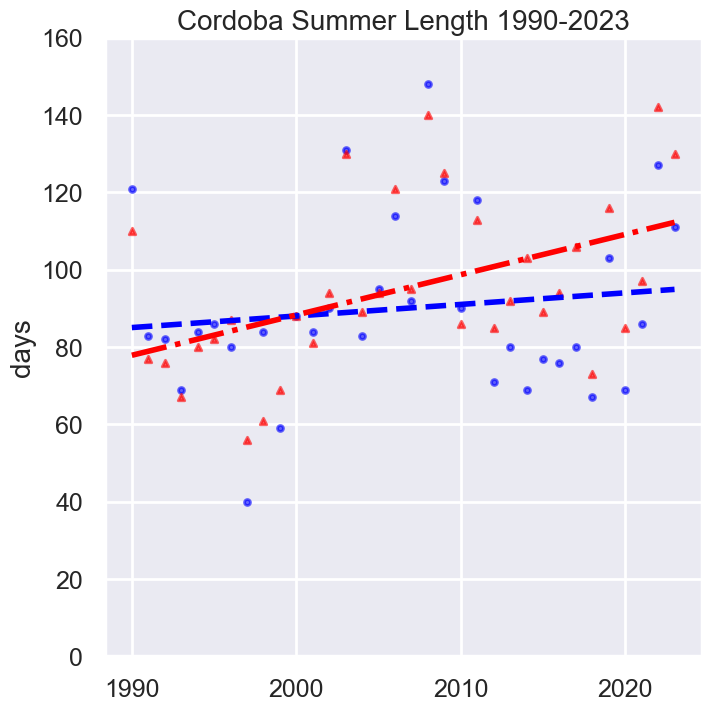

In [70]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,7), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Cordoba Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(0,160)
plt.savefig("../../../Data/GHCND/Plots/cordoba_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/cordoba_summer_plot_wERA5.pdf",bbox_inches='tight')





#### Statsmodels OLS for p-values

In [71]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.017
Model:                            OLS   Adj. R-squared:                 -0.014
Method:                 Least Squares   F-statistic:                    0.5574
Date:                Wed, 11 Feb 2026   Prob (F-statistic):              0.461
Time:                        10:37:03   Log-Likelihood:                -153.71
No. Observations:                  34   AIC:                             311.4
Df Residuals:                      32   BIC:                             314.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -510.2639    804.044     -0.635      0.5

In [72]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.225
Model:                            OLS   Adj. R-squared:                  0.201
Method:                 Least Squares   F-statistic:                     9.278
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00462
Time:                        10:37:05   Log-Likelihood:                -148.33
No. Observations:                  34   AIC:                             300.7
Df Residuals:                      32   BIC:                             303.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1996.0251    686.510     -2.907      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: 17.89 +/- 10.2
OLS Slope ERA5: 48.25 +/- 9.81


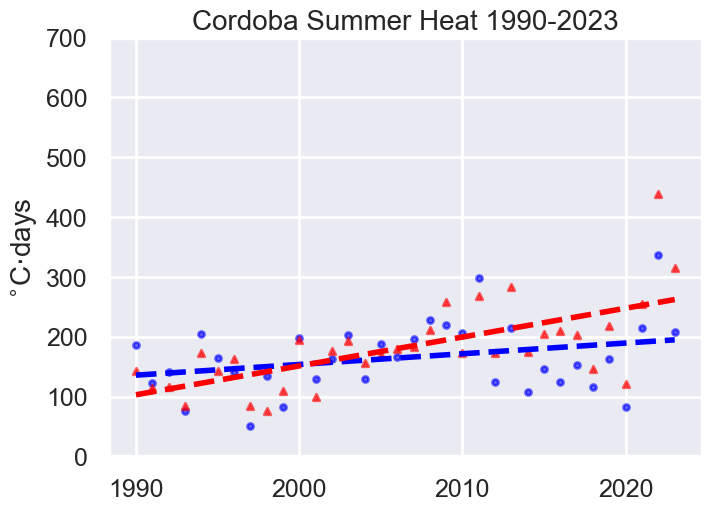

In [73]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Cordoba Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/cordoba_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/cordoba_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [74]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.088
Model:                            OLS   Adj. R-squared:                  0.059
Method:                 Least Squares   F-statistic:                     3.077
Date:                Wed, 11 Feb 2026   Prob (F-statistic):             0.0890
Time:                        10:37:19   Log-Likelihood:                -185.48
No. Observations:                  34   AIC:                             375.0
Df Residuals:                      32   BIC:                             378.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -3425.1370   2047.055     -1.673      0.1

In [75]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.430
Model:                            OLS   Adj. R-squared:                  0.413
Method:                 Least Squares   F-statistic:                     24.19
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           2.52e-05
Time:                        10:37:22   Log-Likelihood:                -184.15
No. Observations:                  34   AIC:                             372.3
Df Residuals:                      32   BIC:                             375.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -9498.4282   1968.558     -4.825      0.0

#### End Gradient with ERA5 data

In [92]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -31.25
    lon      float64 8B -64.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -31.25
    lon      float64 8B -64.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.0038000000000000004 +/- 0.0052
OLS Slope ERA5: -0.011000000000000001 +/- 0.0046


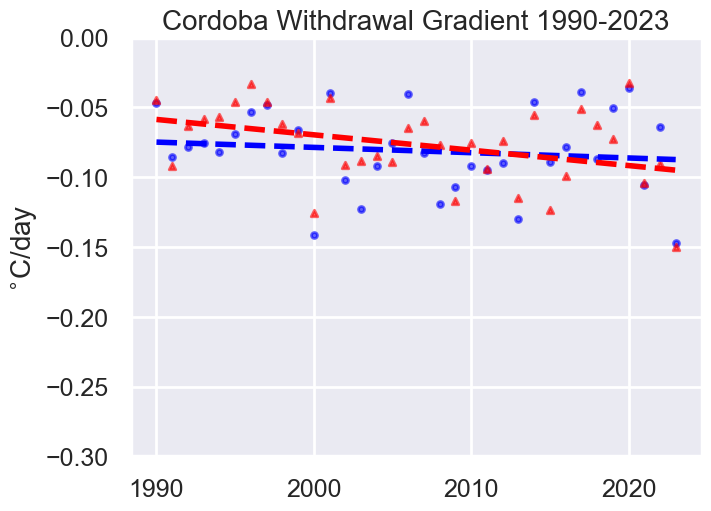

In [93]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Cordoba Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/cordoba_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/cordoba_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: 0.007600000000000001 +/- 0.0051
OLS Slope ERA5: 0.0104 +/- 0.0038000000000000004


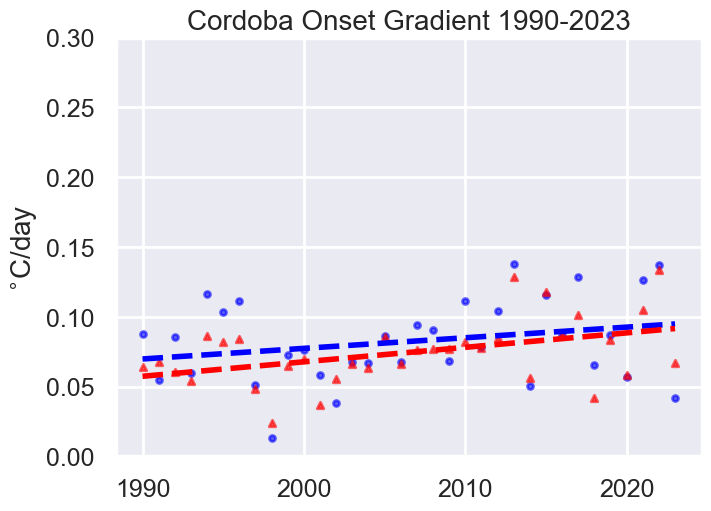

In [94]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Cordoba Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/cordoba_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/cordoba_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')


### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

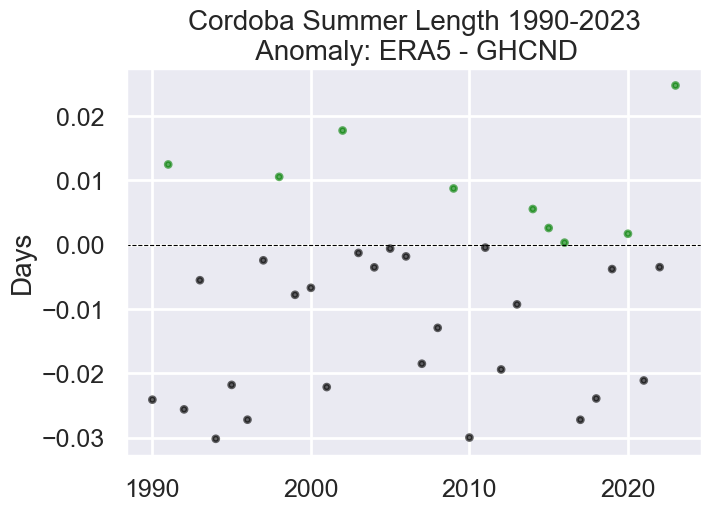

In [269]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Cordoba Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

## **Upington, SA** has complete data

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:SF003174470/detail

### This is in the SH so we need 2024

In [76]:
df = pd.read_csv("../../../Data/GHCND/upington-2025-04-30T18-01-45.csv")
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,1961-01-01,NaN,27.8,19.5
1,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,1961-01-02,NaN,28.7,17.0
2,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,1961-01-03,NaN,31.7,17.3
3,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,1961-01-04,NaN,29.2,15.3
4,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,1961-01-05,NaN,27.7,14.2
...,...,...,...,...,...,...,...,...,...
23351,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,2024-12-27,27.3,36.7,19.8
23352,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,2024-12-28,27.3,36.6,17.9
23353,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,2024-12-29,28.6,37.7,18.7
23354,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,2024-12-30,28.2,37.7,20.6


### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [272]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,1961-01-01,23.65,27.8,19.5
1,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,1961-01-02,22.85,28.7,17.0
2,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,1961-01-03,24.50,31.7,17.3
3,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,1961-01-04,22.25,29.2,15.3
4,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,1961-01-05,20.95,27.7,14.2
...,...,...,...,...,...,...,...,...,...
23351,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,2024-12-27,27.30,36.7,19.8
23352,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,2024-12-28,27.30,36.6,17.9
23353,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,2024-12-29,28.60,37.7,18.7
23354,SF003174470,"UPINGTON AGR., SF",-28.45,21.25,794.0,2024-12-30,28.20,37.7,20.6


In [273]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,296.80
1961-01-02,296.00
1961-01-03,297.65
1961-01-04,295.40
1961-01-05,294.10
...,...
2024-12-27,300.45
2024-12-28,300.45
2024-12-29,301.75


#### based on the plots I tried below, there are some missing dates - finding them

In [274]:
# need to find the missing days so we can have complete 2020 and 2023
pd.set_option('display.max_rows', 500)

In [121]:
df_sub.index

DatetimeIndex(['1961-01-01', '1961-01-02', '1961-01-03', '1961-01-04',
               '1961-01-05', '1961-01-06', '1961-01-07', '1961-01-08',
               '1961-01-09', '1961-01-10',
               ...
               '2023-12-22', '2023-12-23', '2023-12-24', '2023-12-25',
               '2023-12-26', '2023-12-27', '2023-12-28', '2023-12-29',
               '2023-12-30', '2023-12-31'],
              dtype='datetime64[ns]', name='time', length=23010, freq=None)

In [275]:
#df_sub.tail(365)
#df_sub.loc['2020-01-01':'2021-12-31'].head(300)

# got help from https://www.geeksforgeeks.org/check-missing-dates-in-pandas/
print(pd.date_range(
  start="1961-01-01", end="2024-12-31").difference(df_sub.index))

DatetimeIndex(['1991-08-15', '2002-10-26', '2003-05-09', '2003-05-10',
               '2010-05-23', '2015-04-11', '2021-02-11', '2021-02-12',
               '2021-02-20', '2024-03-28', '2024-03-29', '2024-03-30',
               '2024-03-31', '2024-05-01', '2024-08-12', '2024-11-18',
               '2024-11-19', '2024-11-20', '2024-11-21', '2024-12-01'],
              dtype='datetime64[ns]', freq=None)


In [276]:
df_missing = pd.DataFrame({'time':pd.to_datetime(['1991-08-15', '2002-10-26', '2003-05-09', '2003-05-10','2010-05-23', '2015-04-11',
                                                  '2021-02-11', '2021-02-12', '2021-02-20','2024-03-28','2024-03-29','2024-03-30','2024-03-31','2024-05-01']),
                            'tavg':np.repeat(np.nan, 14)})
df_missing = df_missing.set_index(['time'])
df_missing
                                                 

,tavg
time,
1991-08-15,NaN
2002-10-26,NaN
2003-05-09,NaN
2003-05-10,NaN
2010-05-23,NaN
2015-04-11,NaN
2021-02-11,NaN
2021-02-12,NaN
2021-02-20,NaN


In [277]:
df_sub = pd.concat([df_sub, df_missing], axis=0).sort_index()
df_sub

,tavg
time,
1961-01-01,296.80
1961-01-02,296.00
1961-01-03,297.65
1961-01-04,295.40
1961-01-05,294.10
...,...
2024-12-27,300.45
2024-12-28,300.45
2024-12-29,301.75


In [278]:
# linear interpolation to fill the missing ones
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
print(df_sub[df_sub.isna().any(axis=1)])

Empty DataFrame
Columns: [tavg]
Index: []


#### all cleaned up!

### Convert from Pandas to XArray

In [279]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 374kB
Dimensions:  (time: 23370)
Coordinates:
  * time     (time) datetime64[ns] 187kB 1961-01-01 1961-01-02 ... 2024-12-31
Data variables:
    tavg     (time) float64 187kB 296.8 296.0 297.6 295.4 ... 301.8 301.3 299.9

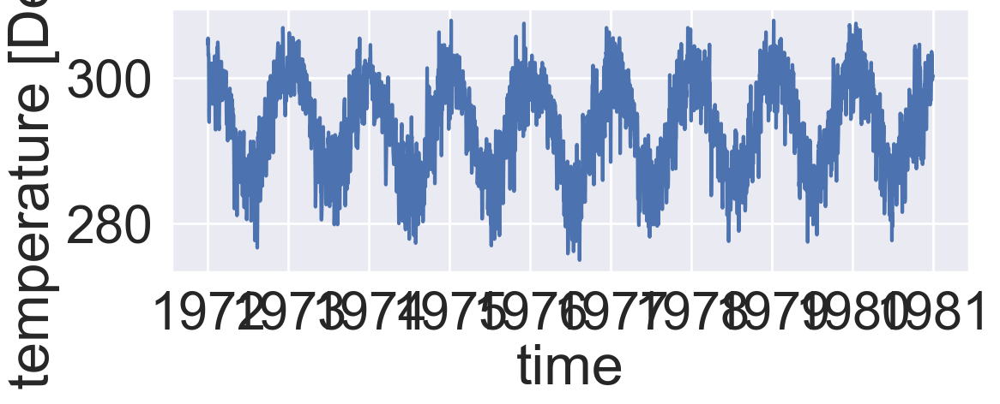

In [280]:
plt.figure(figsize=(12,4))
da_stp.tavg.sel(time=slice('1972','1980')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [281]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(299.180511)
Coordinates:
    lat       float64 8B -28.5
    lon       float64 8B 21.25
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [282]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 3.62 ms, sys: 1.92 ms, total: 5.55 ms
Wall time: 3.75 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(299.55)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [283]:
thresh.values - stp_75.values

np.float64(-0.3694885253905795)

#### Upington 75th Percentile from GHCND data is 0.37 K warmer

### Try one year (2023) fit via Fourier

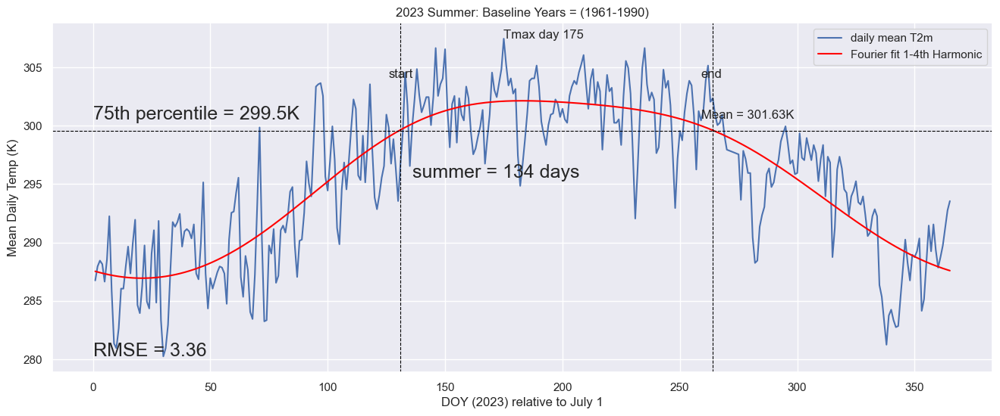

(131,
 264,
 0.10847070638007494,
 -0.08579043157129718,
 175,
 338.15000000000146,
 134,
 3.3613584052236773,
 0.0,
 301.6324626865671,
 3.1900943396226467)

In [286]:
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the SH we DO need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, False)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

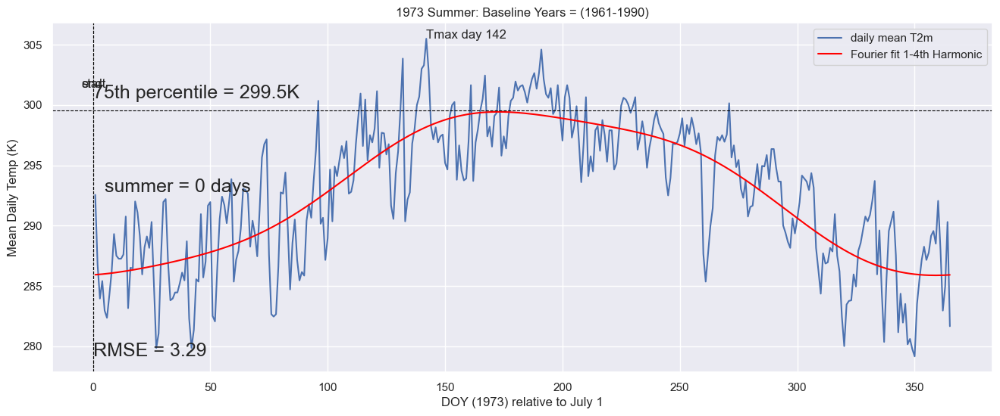

(0, 0, nan, nan, 142, 0.0, 0, 3.2887152732483096, 0.0, 0.0, 0.0)

In [287]:
# how about 1973
input_year = 1973

da = da_stp.sel(time=str(input_year))
# since this is in the SH we DO need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, False)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### 1973 legit has no summer for this location!

### Climatology plots, 1961-2023 and 1990-2023

In [288]:
da_daily_clim_full = da_stp.tavg.groupby("time.dayofyear").mean()
da_daily_clim_an = da_stp.tavg.sel(time=slice('1990','2023')).groupby("time.dayofyear").mean()
da_daily_clim_full, da_daily_clim_an


#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()

(<xarray.DataArray 'tavg' (dayofyear: 366)> Size: 3kB
 array([301.03828125, 301.13125   , 301.86171875, 301.86328125,
        301.828125  , 301.60625   , 300.90234375, 301.37265625,
        301.08359375, 300.721875  , 300.84296875, 300.784375  ,
        300.83203125, 301.41484375, 301.7453125 , 301.69375   ,
        302.1671875 , 301.83984375, 301.309375  , 301.1375    ,
        301.328125  , 301.3125    , 301.36484375, 300.92265625,
        300.94453125, 300.93125   , 301.0359375 , 301.31171875,
        301.5875    , 301.49921875, 301.5296875 , 301.3328125 ,
        300.81015625, 300.9140625 , 301.13203125, 301.70078125,
        301.8921875 , 301.5484375 , 301.08125   , 301.04296875,
        300.278125  , 300.3875    , 300.36171875, 300.4234375 ,
        300.59375   , 300.3046875 , 300.3171875 , 300.38359375,
        300.3       , 300.20546875, 300.03671875, 299.7953125 ,
        300.3453125 , 300.15546875, 300.20078125, 300.1765625 ,
        300.40546875, 300.49765625, 300.36171875, 

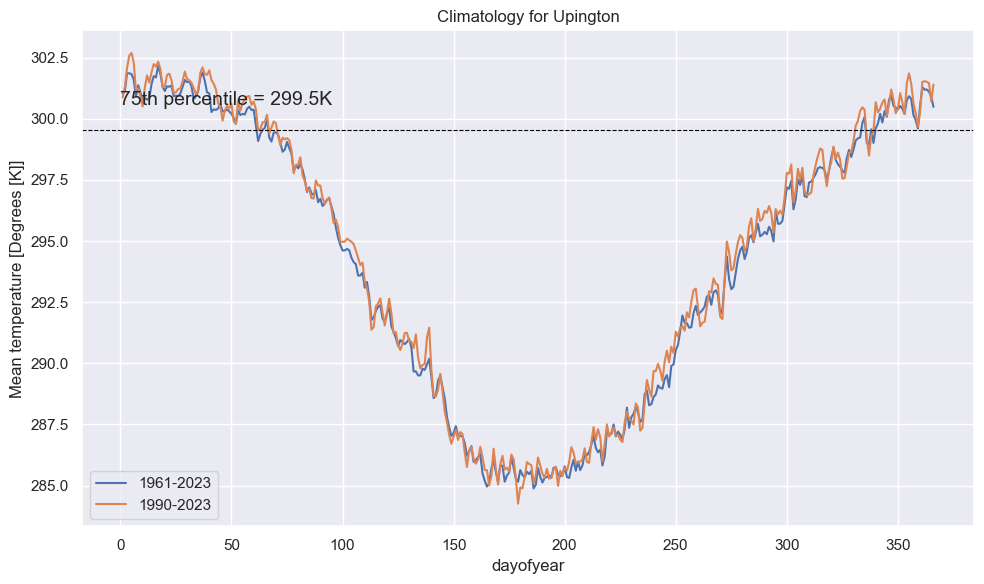

In [289]:
# plot both to compare
plt.figure(figsize=(10,6))
da_daily_clim_full.plot(label='1961-2023')
da_daily_clim_an.plot(label='1990-2023')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for Upington")
plt.tight_layout()
plt.show()

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats

In [290]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [291]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the SH we need a next year
    da_next = da_stp.sel(time=str(input_year+1))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, False)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[grad_start],
                        "EndGrad":[grad_end],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 330 ms, sys: 10.7 ms, total: 341 ms
Wall time: 363 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,171,241,0.054415,-0.069622,71,101.75,186,299.992958
1,1962,154,241,0.087258,-0.082368,88,172.70,204,300.992045
2,1963,164,241,0.059806,-0.084146,78,125.15,181,300.292949
3,1964,173,241,0.083109,-0.088569,69,112.25,222,300.472464
4,1965,168,237,0.102941,-0.090196,70,133.60,187,300.535714
5,1966,145,240,0.060480,-0.085530,96,162.75,182,300.676562
6,1967,146,210,0.089267,-0.045945,65,91.45,172,300.026923
7,1968,166,246,0.050618,-0.112954,81,142.65,215,300.609259
8,1969,162,260,0.078553,-0.102676,99,189.30,243,301.026263
9,1970,191,241,0.054805,-0.083777,51,58.30,192,300.083333


### write out resulting summer stats

In [292]:
# write out results
output_path = "../../../Data/GHCND/upington_summer_stats.csv"
df_summ.to_csv(output_path)

In [293]:
pd.set_option('display.max_rows', 100)

### read back in for adding MK slopes (2025-04-21)

In [77]:
# re-load 
input_path = "../../../Data/GHCND/upington_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,171,241,0.054415,-0.069622,71,101.75,186,299.992958
1,1,1962,154,241,0.087258,-0.082368,88,172.70,204,300.992045
2,2,1963,164,241,0.059806,-0.084146,78,125.15,181,300.292949
3,3,1964,173,241,0.083109,-0.088569,69,112.25,222,300.472464
4,4,1965,168,237,0.102941,-0.090196,70,133.60,187,300.535714
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,157,250,0.077037,-0.112390,94,200.80,200,301.063830
59,59,2020,140,251,0.066804,-0.058557,112,159.60,172,300.119643
60,60,2021,179,239,0.085546,-0.119825,61,93.60,212,300.576230
61,61,2022,148,252,0.043972,-0.157354,105,264.30,200,301.533810


### Upington: Plot the summer stats

In [295]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

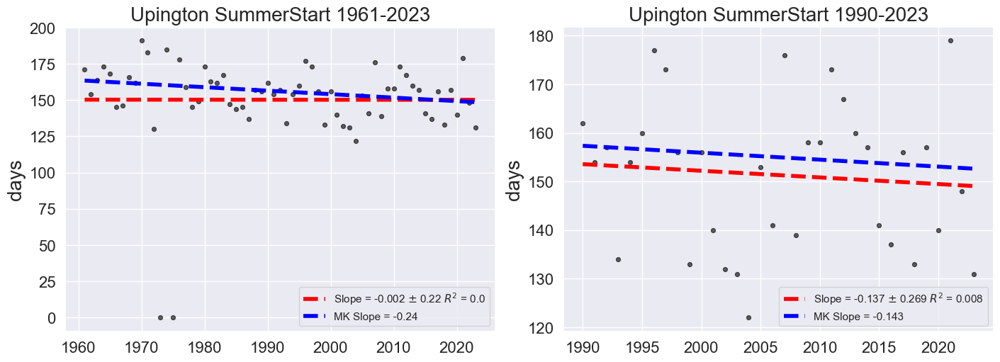

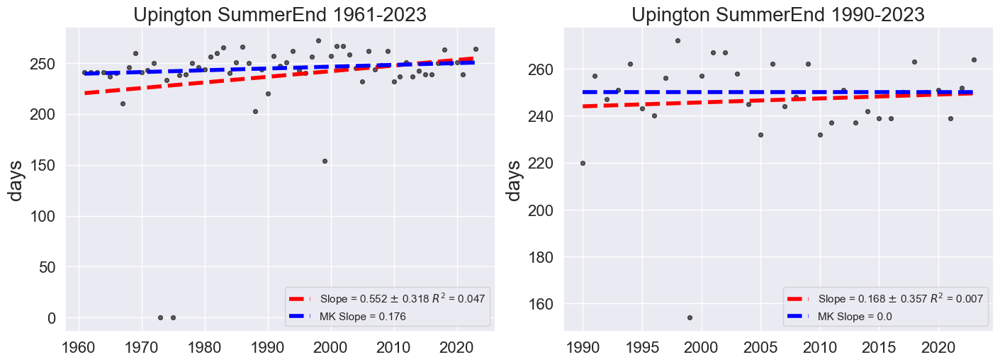

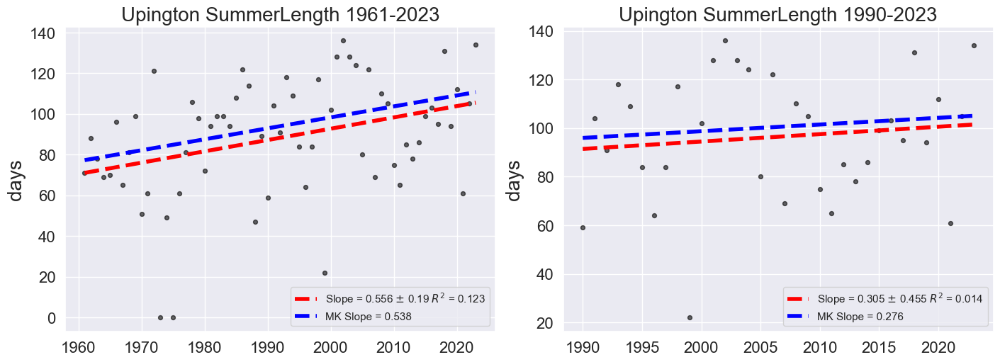

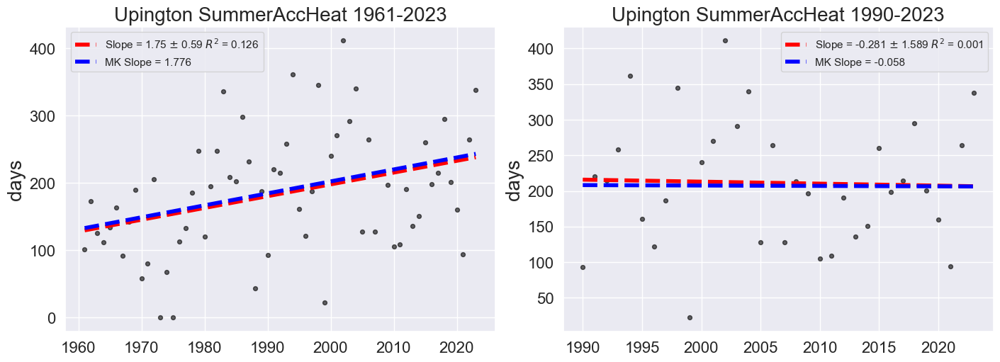

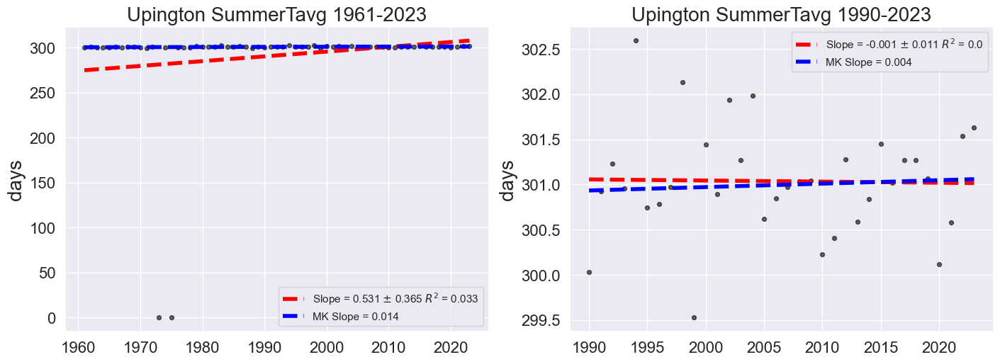

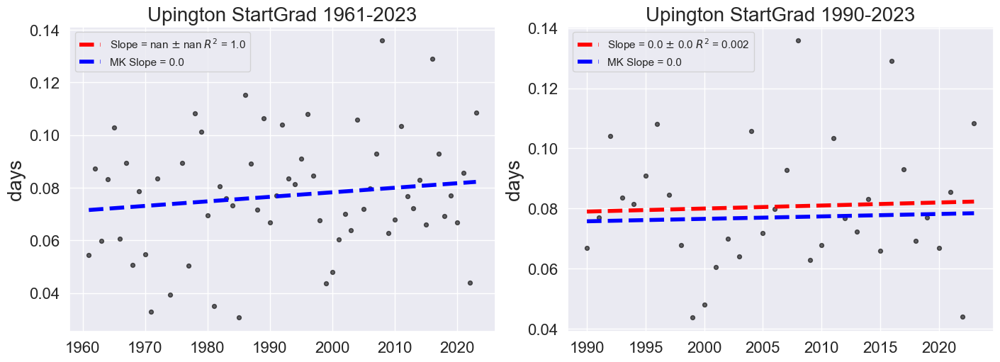

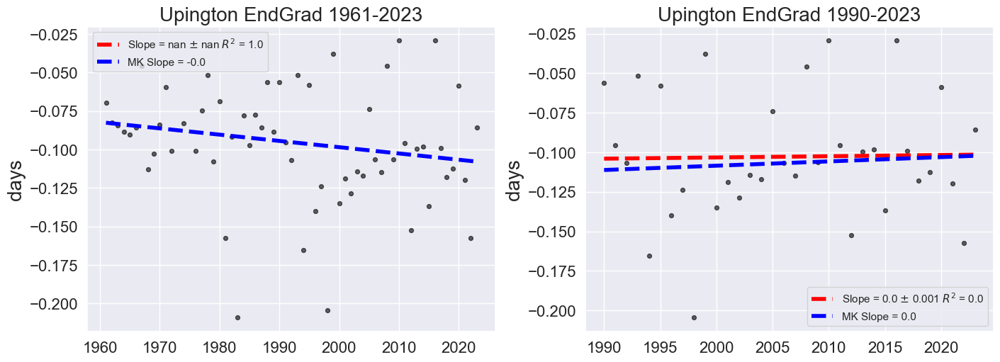

In [80]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Upington "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Upington "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


### I epected Upington to show significant growth in summer length but I guess it isn't one of the spots in S Africa that is "deep red" for summer length slope

#### Summer Length Plot for Paper

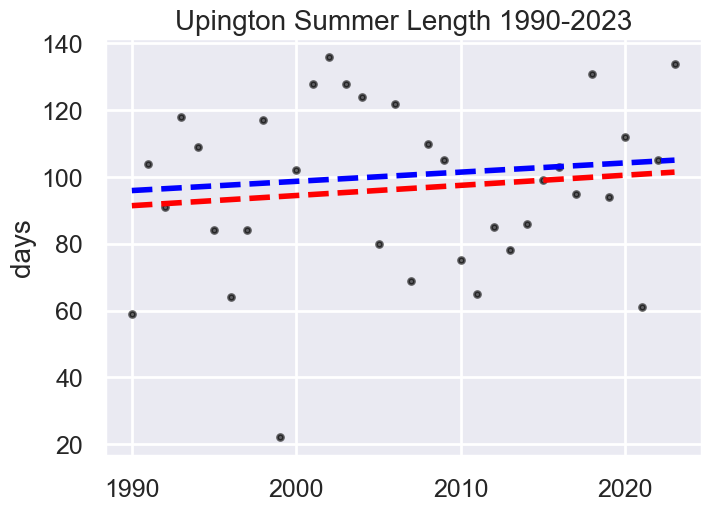

In [81]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Upington Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/upington_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [78]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -28.5
    lon      float64 8B 21.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -28.5
    lon      float64 8B 21.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 3.05 +/- 4.55
OLS Slope ERA5: 12.190000000000001 +/- 3.6799999999999997


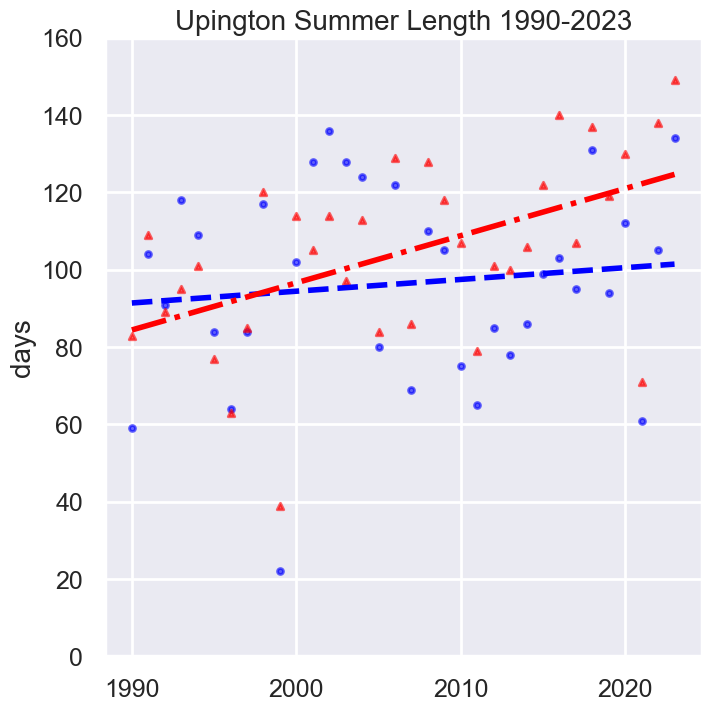

In [79]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,7), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Upington Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(0,160)
plt.savefig("../../../Data/GHCND/Plots/upington_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/upington_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [80]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                 -0.017
Method:                 Least Squares   F-statistic:                    0.4479
Date:                Wed, 11 Feb 2026   Prob (F-statistic):              0.508
Time:                        10:39:18   Log-Likelihood:                -158.02
No. Observations:                  34   AIC:                             320.0
Df Residuals:                      32   BIC:                             323.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -514.5526    912.911     -0.564      0.5

In [81]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.256
Model:                            OLS   Adj. R-squared:                  0.232
Method:                 Least Squares   F-statistic:                     11.00
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00228
Time:                        10:39:21   Log-Likelihood:                -150.79
No. Observations:                  34   AIC:                             305.6
Df Residuals:                      32   BIC:                             308.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2342.1756    737.847     -3.174      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: -2.8100000000000005 +/- 15.89
OLS Slope ERA5: 36.339999999999996 +/- 13.200000000000001


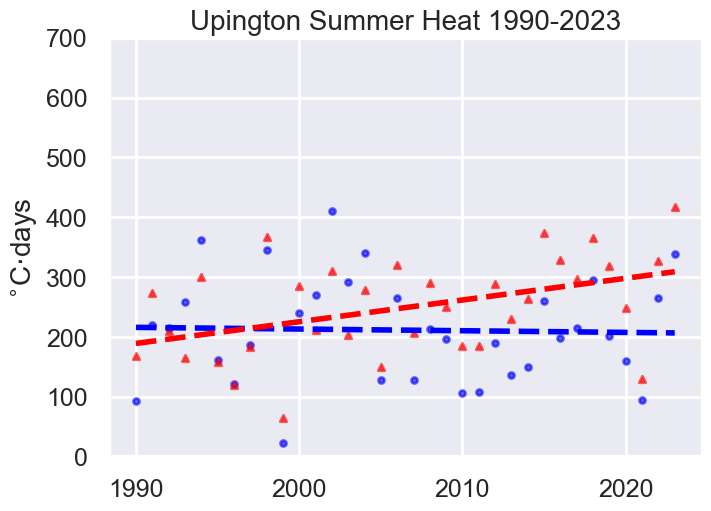

In [82]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Upington Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/upington_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/upington_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [83]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.030
Method:                 Least Squares   F-statistic:                   0.03123
Date:                Wed, 11 Feb 2026   Prob (F-statistic):              0.861
Time:                        10:39:36   Log-Likelihood:                -200.54
No. Observations:                  34   AIC:                             405.1
Df Residuals:                      32   BIC:                             408.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        774.5684   3187.752      0.243      0.8

In [84]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.192
Model:                            OLS   Adj. R-squared:                  0.166
Method:                 Least Squares   F-statistic:                     7.581
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00964
Time:                        10:39:38   Log-Likelihood:                -194.23
No. Observations:                  34   AIC:                             392.5
Df Residuals:                      32   BIC:                             395.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7041.7878   2648.038     -2.659      0.0

#### End Gradient with ERA5 data

In [101]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -28.5
    lon      float64 8B 21.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -28.5
    lon      float64 8B 21.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: 0.0008 +/- 0.007200000000000001
OLS Slope ERA5: -0.004200000000000001 +/- 0.0049


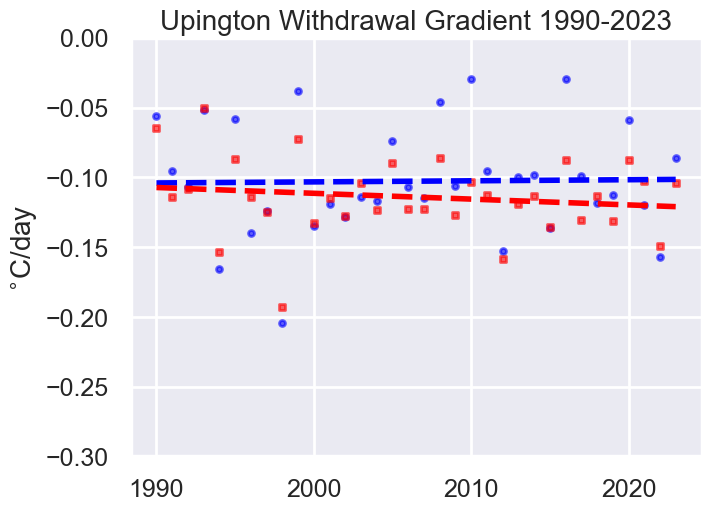

In [102]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='s', alpha=alpha)

ax2.set_title("Upington Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/upington_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/upington_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: 0.001 +/- 0.0038000000000000004
OLS Slope ERA5: 0.0049 +/- 0.0034000000000000002


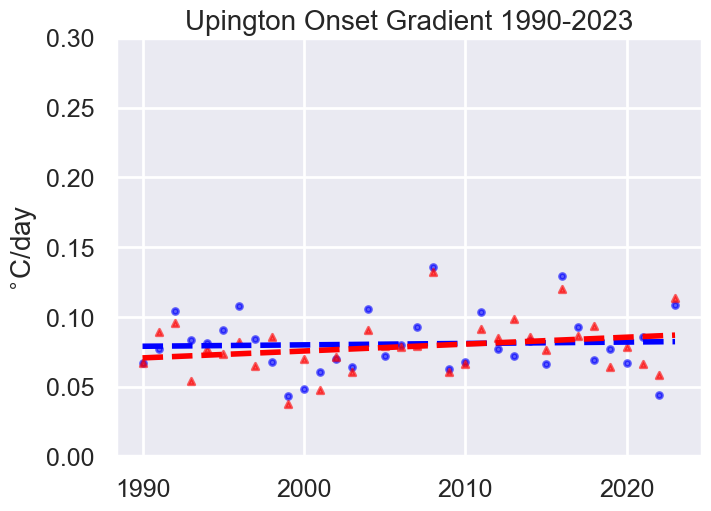

In [103]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Upington Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/upington_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/upington_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

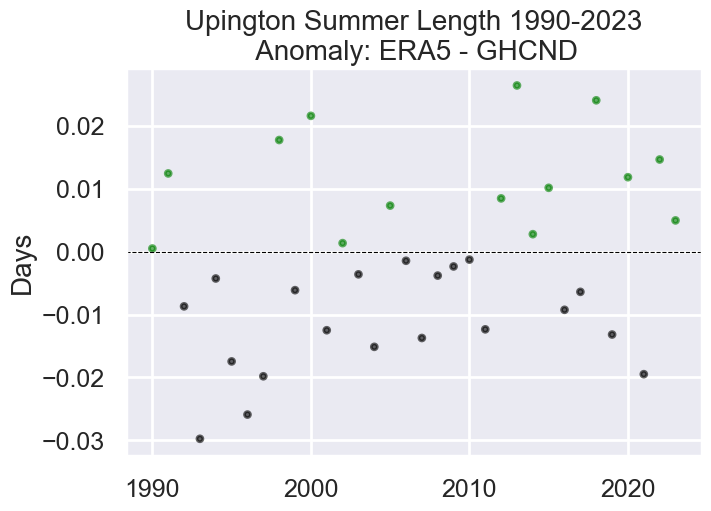

In [304]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Upington Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

## **Paris, Orly ** has complete data

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:FRM00007149/detail

In [85]:
df = pd.read_csv("../../../Data/GHCND/paris_orly-2025-04-07T18-03-51.csv")
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,1961-01-01,NaN,5.0,-1.2
1,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,1961-01-02,NaN,10.3,2.3
2,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,1961-01-03,NaN,7.3,2.5
3,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,1961-01-04,NaN,7.3,2.3
4,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,1961-01-05,NaN,6.9,1.1
...,...,...,...,...,...,...,...,...,...
23005,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,2023-12-27,9.4,11.1,7.5
23006,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,2023-12-28,10.0,11.0,9.1
23007,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,2023-12-29,10.2,11.3,8.8
23008,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,2023-12-30,9.3,11.5,6.8


In [306]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23010 entries, 0 to 23009
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    23010 non-null  object 
 1   NAME       23010 non-null  object 
 2   LATITUDE   23010 non-null  float64
 3   LONGITUDE  23010 non-null  float64
 4   ELEVATION  23010 non-null  float64
 5   DATE       23010 non-null  object 
 6   TAVG       18213 non-null  float64
 7   TMAX       23010 non-null  float64
 8   TMIN       23010 non-null  float64
dtypes: float64(6), object(3)
memory usage: 1.6+ MB


### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [307]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,1961-01-01,1.9,5.0,-1.2
1,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,1961-01-02,6.3,10.3,2.3
2,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,1961-01-03,4.9,7.3,2.5
3,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,1961-01-04,4.8,7.3,2.3
4,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,1961-01-05,4.0,6.9,1.1
...,...,...,...,...,...,...,...,...,...
23005,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,2023-12-27,9.4,11.1,7.5
23006,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,2023-12-28,10.0,11.0,9.1
23007,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,2023-12-29,10.2,11.3,8.8
23008,FRM00007149,"ORLY, FR",48.7167,2.3842,89.0,2023-12-30,9.3,11.5,6.8


In [ ]:
# check counts again
df.info()

In [308]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,275.05
1961-01-02,279.45
1961-01-03,278.05
1961-01-04,277.95
1961-01-05,277.15
...,...
2023-12-27,282.55
2023-12-28,283.15
2023-12-29,283.35


### Convert from Pandas to XArray

In [309]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 368kB
Dimensions:  (time: 23010)
Coordinates:
  * time     (time) datetime64[ns] 184kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 184kB 275.0 279.4 278.0 277.9 ... 283.3 282.4 282.4

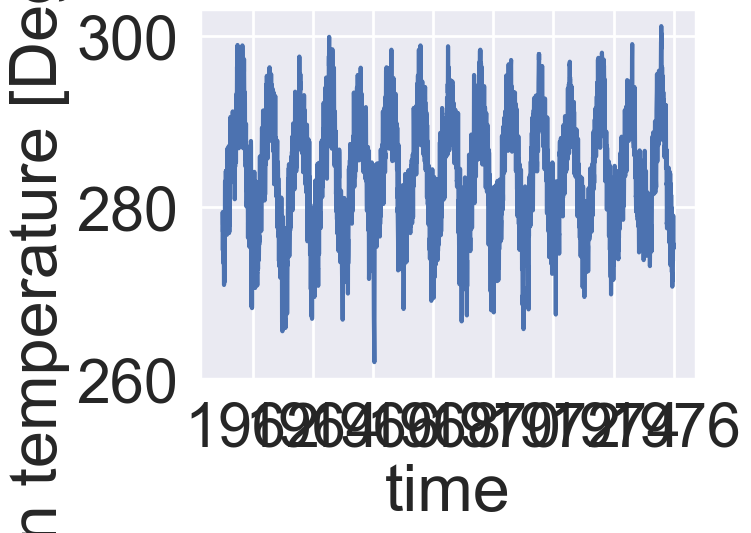

In [310]:
da_stp.tavg.sel(time=slice('1961','1975')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [311]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(288.722626)
Coordinates:
    lat       float64 8B 48.75
    lon       float64 8B 2.5
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [312]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 3.9 ms, sys: 2 ms, total: 5.9 ms
Wall time: 4.47 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(289.75)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [313]:
thresh.values - stp_75.values

np.float64(-1.027374267578125)

#### Paris (Orly) 75th Percentile from GHCND data is 1.02 K warmer

### Try one year (2023) fit via Fourier

In [ ]:
da.tavg.values[0]

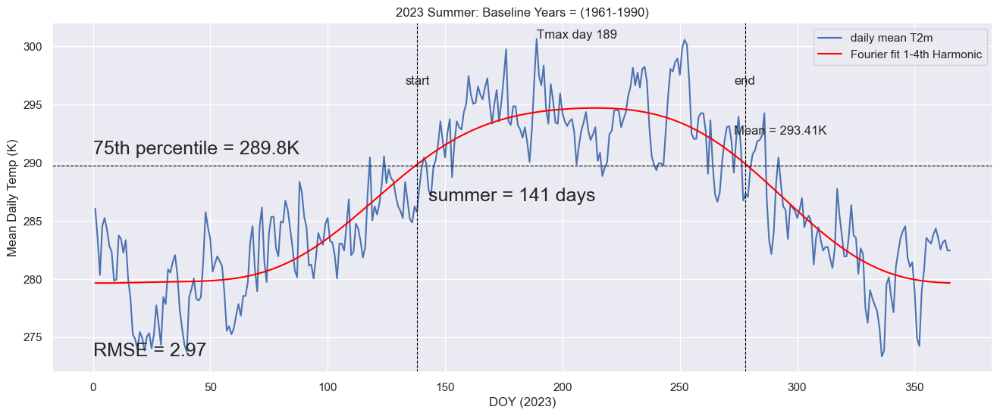

(138,
 278,
 0.15284527583389718,
 -0.17049703668200777,
 189,
 543.0999999999913,
 141,
 2.968795128479331,
 0.0,
 293.4109929078014,
 4.379838709677358)

In [314]:
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

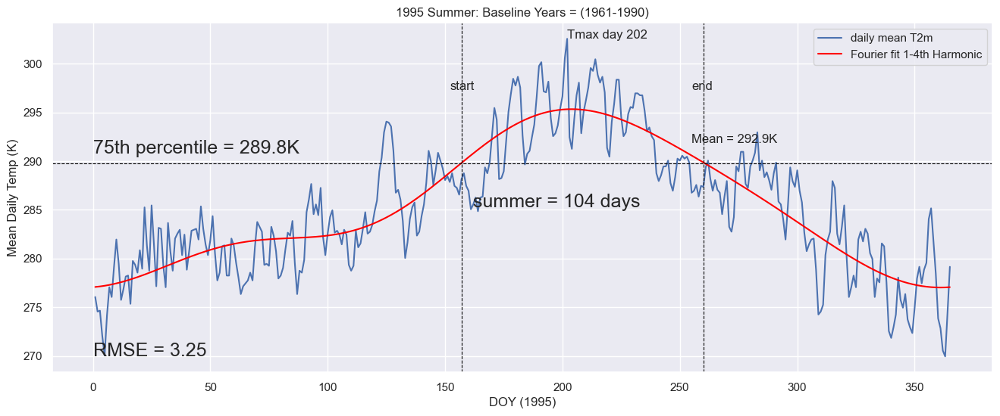

(157,
 260,
 0.1966001313803929,
 -0.14355350410414758,
 202,
 390.7999999999993,
 104,
 3.2539096801273137,
 0.0,
 292.901923076923,
 5.2810810810810835)

In [315]:
# how about 1995
input_year = 1995

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Looks to be working!

### Climatology plots, 1961-2023 and 1990-2023

In [316]:
da_daily_clim_full = da_stp.tavg.groupby("time.dayofyear").mean()
da_daily_clim_an = da_stp.tavg.sel(time=slice('1990','2023')).groupby("time.dayofyear").mean()
da_daily_clim_full, da_daily_clim_an


#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()

(<xarray.DataArray 'tavg' (dayofyear: 366)> Size: 3kB
 array([276.64126984, 277.19365079, 276.98095238, 276.63015873,
        276.85952381, 276.88968254, 276.74920635, 277.        ,
        277.5452381 , 277.38571429, 277.12063492, 276.56111111,
        276.85714286, 277.07857143, 277.08333333, 276.76904762,
        276.78809524, 276.44444444, 277.04206349, 277.36746032,
        277.23492063, 277.34285714, 277.32857143, 277.19444444,
        277.1515873 , 277.05555556, 277.45079365, 277.63333333,
        277.51746032, 277.52063492, 277.07698413, 277.42539683,
        277.58253968, 277.57222222, 277.65873016, 278.40793651,
        278.30952381, 278.08174603, 277.93492063, 277.58333333,
        277.34920635, 277.5547619 , 277.57460317, 277.11031746,
        276.93730159, 277.26428571, 277.40634921, 277.66111111,
        277.59444444, 277.71984127, 278.19206349, 278.13968254,
        278.28333333, 278.46507937, 278.71428571, 278.84603175,
        278.42301587, 278.09206349, 278.23968254, 

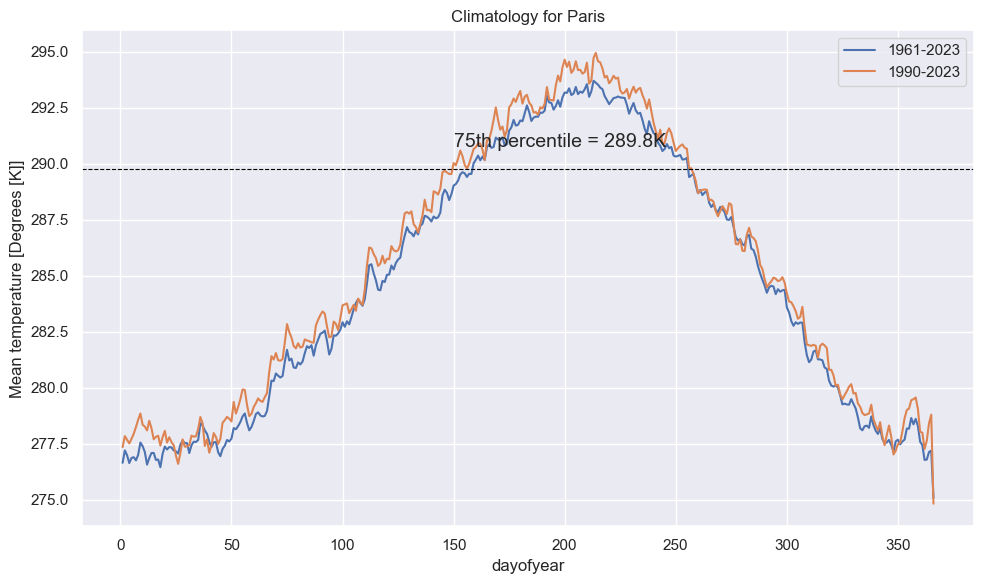

In [317]:
# plot both to compare
plt.figure(figsize=(10,6))
da_daily_clim_full.plot(label='1961-2023')
da_daily_clim_an.plot(label='1990-2023')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(150,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for Paris")
plt.tight_layout()
plt.show()

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats

In [318]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [319]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 266 ms, sys: 8.59 ms, total: 275 ms
Wall time: 274 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,176,268,0.076463,-0.143674,93,202.55,182,291.660753
1,1962,180,257,0.037758,-0.113206,78,111.50,206,290.689103
2,1963,170,231,0.104705,-0.089287,62,94.45,203,290.795161
3,1964,158,256,0.091833,-0.159714,99,255.20,198,291.898990
4,1965,184,236,0.051099,-0.072932,53,66.55,217,290.160377
5,1966,156,256,0.075494,-0.071174,101,169.95,225,290.898515
6,1967,163,255,0.143306,-0.077535,93,204.80,213,291.368817
7,1968,173,256,0.064758,-0.091844,84,134.00,182,290.992262
8,1969,164,261,0.104723,-0.110236,98,226.10,209,291.326531
9,1970,152,260,0.123764,-0.084262,109,215.30,218,291.220642


### write out resulting summer stats

In [320]:
# write out results
output_path = "../../../Data/GHCND/paris-orly_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [86]:
# re-load 
input_path = "../../../Data/GHCND/paris-orly_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,176,268,0.076463,-0.143674,93,202.55,182,291.660753
1,1,1962,180,257,0.037758,-0.113206,78,111.50,206,290.689103
2,2,1963,170,231,0.104705,-0.089287,62,94.45,203,290.795161
3,3,1964,158,256,0.091833,-0.159714,99,255.20,198,291.898990
4,4,1965,184,236,0.051099,-0.072932,53,66.55,217,290.160377
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,152,262,0.171760,-0.156739,111,458.10,206,293.587838
59,59,2020,149,267,0.096385,-0.189992,119,470.40,221,293.416387
60,60,2021,152,264,0.138654,-0.139764,113,338.40,167,292.658850
61,61,2022,138,270,0.141879,-0.146968,133,539.10,200,293.401880


### Paris: Plot the summer stats

In [322]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

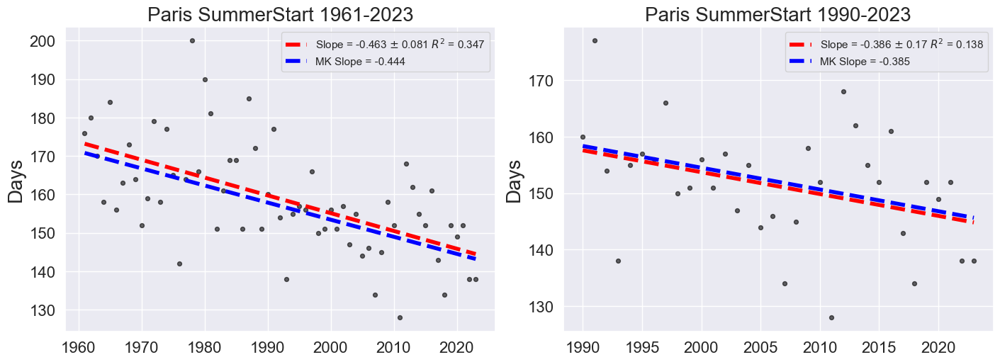

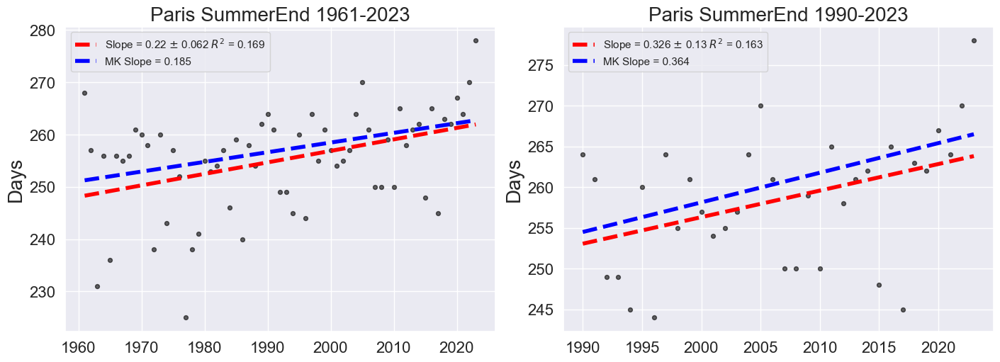

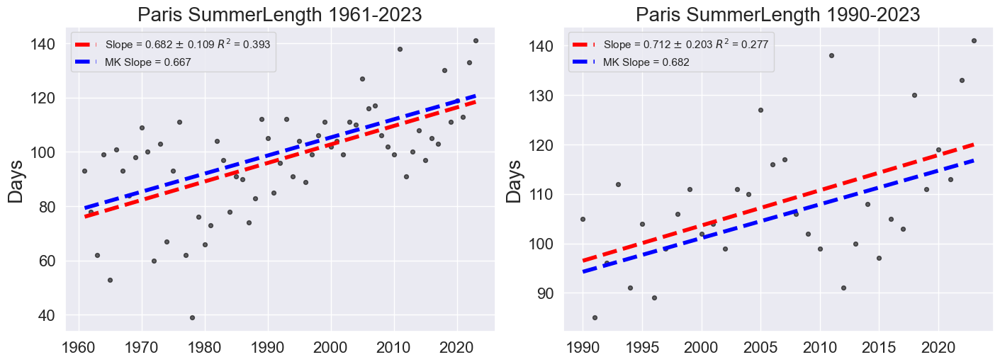

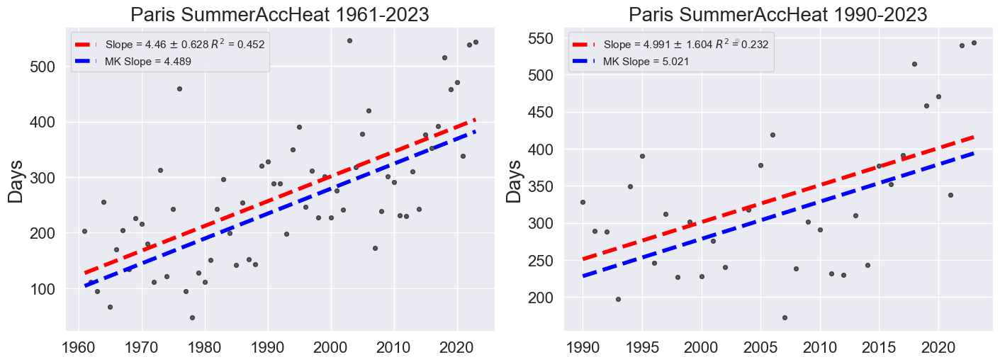

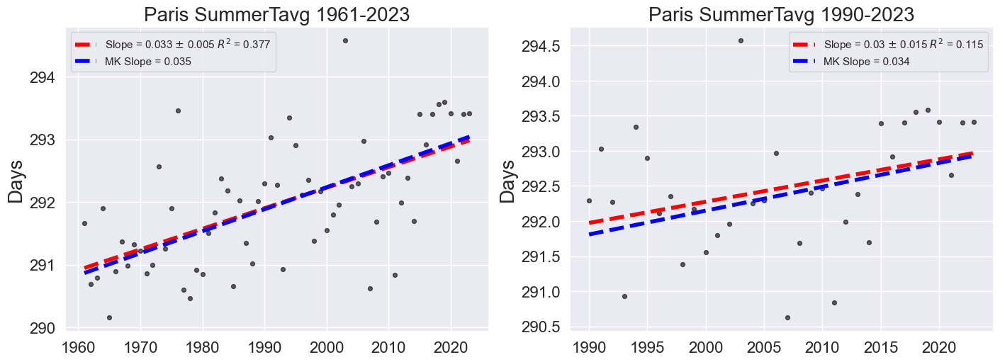

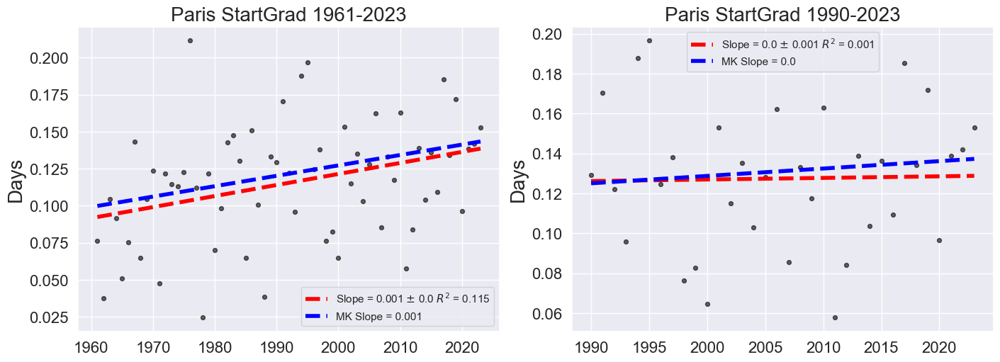

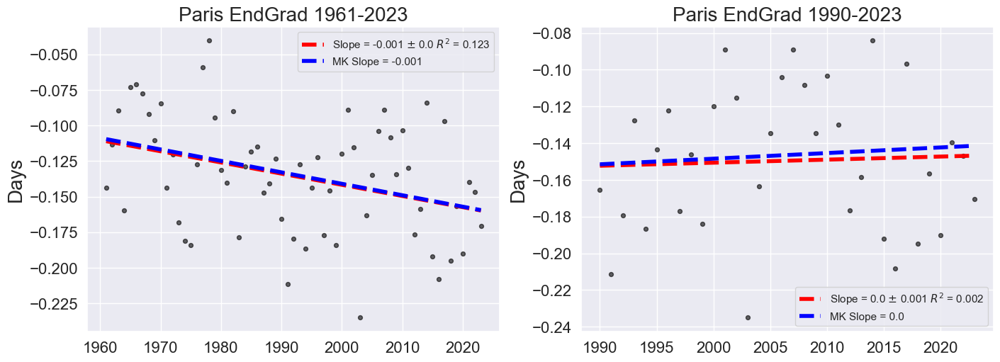

In [86]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Paris "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('Days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Paris "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('Days', fontsize=fs)
    


#### Summer Length Plot for Paper

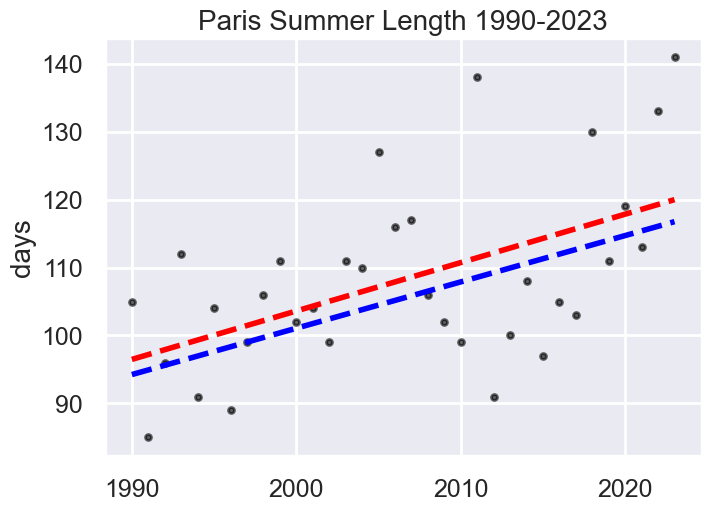

In [87]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Paris Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/paris_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [87]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 48.75
    lon      float64 8B 2.5
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 48.75
    lon      float64 8B 2.5
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 7.119999999999999 +/- 2.0300000000000002
OLS Slope ERA5: 8.18 +/- 2.11


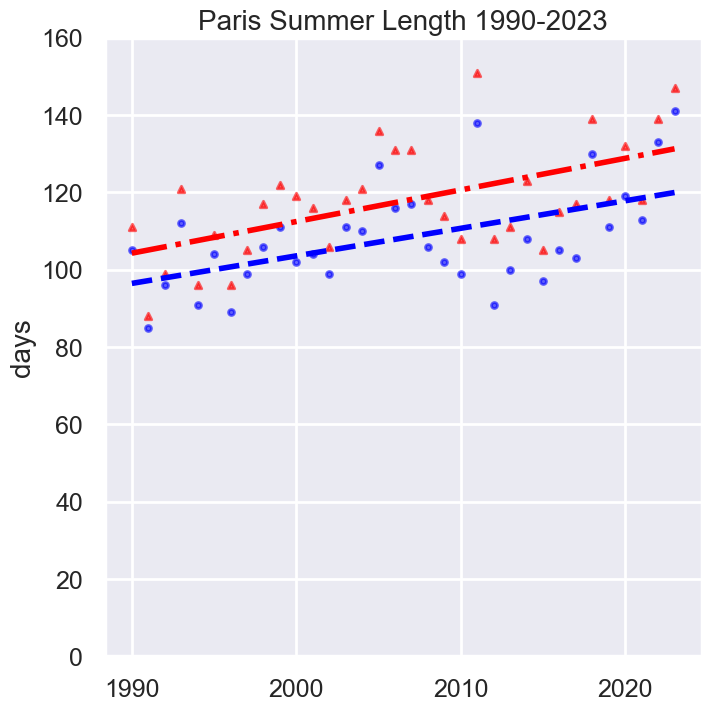

In [88]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,7), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Paris Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(0,160)
plt.savefig("../../../Data/GHCND/Plots/paris_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/paris_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [89]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.277
Model:                            OLS   Adj. R-squared:                  0.255
Method:                 Least Squares   F-statistic:                     12.27
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00138
Time:                        10:41:50   Log-Likelihood:                -130.64
No. Observations:                  34   AIC:                             265.3
Df Residuals:                      32   BIC:                             268.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1320.9936    408.001     -3.238      0.0

In [90]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.320
Model:                            OLS   Adj. R-squared:                  0.298
Method:                 Least Squares   F-statistic:                     15.03
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           0.000494
Time:                        10:41:52   Log-Likelihood:                -131.89
No. Observations:                  34   AIC:                             267.8
Df Residuals:                      32   BIC:                             270.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1523.2746    423.298     -3.599      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: 49.91 +/- 16.04
OLS Slope ERA5: 64.44 +/- 14.42


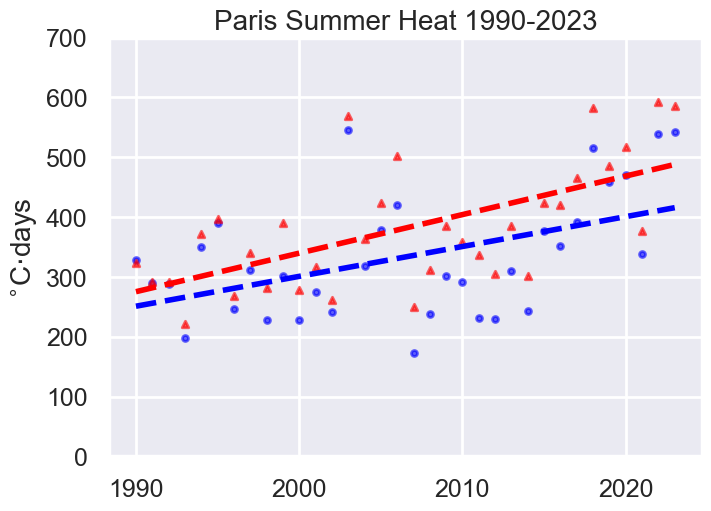

In [91]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Paris Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/paris_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/paris_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [92]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.232
Model:                            OLS   Adj. R-squared:                  0.208
Method:                 Least Squares   F-statistic:                     9.678
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00391
Time:                        10:42:04   Log-Likelihood:                -200.87
No. Observations:                  34   AIC:                             405.7
Df Residuals:                      32   BIC:                             408.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -9681.2248   3219.290     -3.007      0.0

In [93]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.384
Model:                            OLS   Adj. R-squared:                  0.365
Method:                 Least Squares   F-statistic:                     19.97
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           9.23e-05
Time:                        10:42:06   Log-Likelihood:                -197.24
No. Observations:                  34   AIC:                             398.5
Df Residuals:                      32   BIC:                             401.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.255e+04   2893.304     -4.337      0.0

#### End Gradient with ERA5 data

In [73]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 48.75
    lon      float64 8B 2.5
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 48.75
    lon      float64 8B 2.5
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: 0.0017000000000000001 +/- 0.0069
OLS Slope ERA5: -0.0004 +/- 0.0045


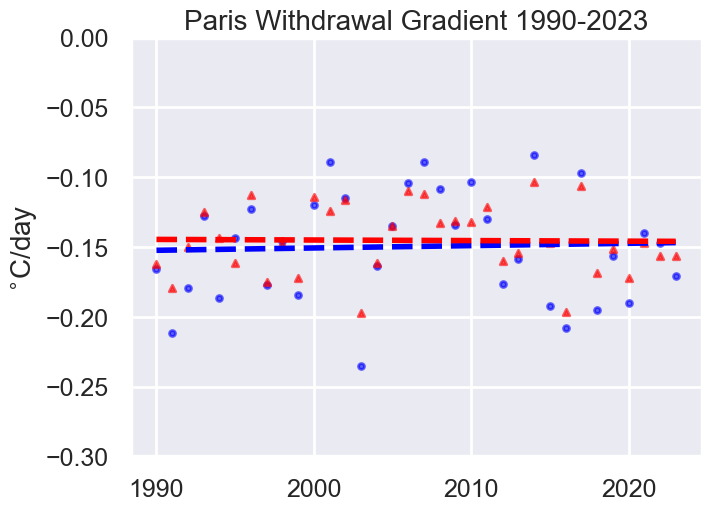

In [74]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Paris Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/paris_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/paris_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: 0.0008 +/- 0.0063
OLS Slope ERA5: 0.0033 +/- 0.004200000000000001


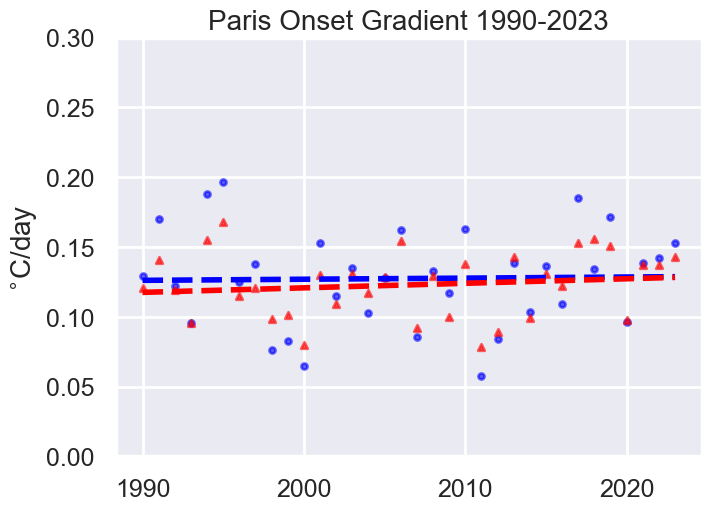

In [75]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Paris Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/paris_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/paris_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

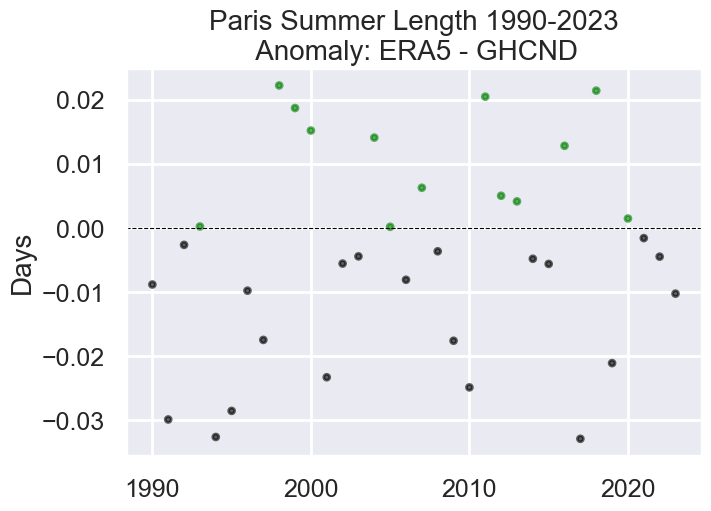

In [331]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Paris Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

## **MSP airport, MN ** has complete data

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USW00014922/detail

In [8]:
df = pd.read_csv("../../../Data/GHCND/msp_airport_minnesota-2025-04-07T18-23-05.csv")
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,1961-01-01,NaN,-4.4,-13.9
1,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,1961-01-02,NaN,-11.7,-19.4
2,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,1961-01-03,NaN,-12.8,-18.3
3,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,1961-01-04,NaN,-3.3,-17.8
4,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,1961-01-05,NaN,1.7,-16.1
...,...,...,...,...,...,...,...,...,...
23005,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,2023-12-27,1.3,3.3,-2.1
23006,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,2023-12-28,-0.1,2.2,-3.8
23007,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,2023-12-29,0.1,5.6,-3.8
23008,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,2023-12-30,-0.9,-0.5,-3.2


In [ ]:
df.info()

### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [9]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,1961-01-01,-9.15,-4.4,-13.9
1,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,1961-01-02,-15.55,-11.7,-19.4
2,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,1961-01-03,-15.55,-12.8,-18.3
3,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,1961-01-04,-10.55,-3.3,-17.8
4,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,1961-01-05,-7.20,1.7,-16.1
...,...,...,...,...,...,...,...,...,...
23005,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,2023-12-27,1.30,3.3,-2.1
23006,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,2023-12-28,-0.10,2.2,-3.8
23007,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,2023-12-29,0.10,5.6,-3.8
23008,USW00014922,"MINNEAPOLIS ST. PAUL INTERNATIONAL AIRPORT, MN US",44.88523,-93.23133,254.5,2023-12-30,-0.90,-0.5,-3.2


In [ ]:
# check counts again
df.info()

In [10]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,264.00
1961-01-02,257.60
1961-01-03,257.60
1961-01-04,262.60
1961-01-05,265.95
...,...
2023-12-27,274.45
2023-12-28,273.05
2023-12-29,273.25


### Convert from Pandas to XArray

In [11]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 368kB
Dimensions:  (time: 23010)
Coordinates:
  * time     (time) datetime64[ns] 184kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 184kB 264.0 257.6 257.6 262.6 ... 273.2 272.2 270.5

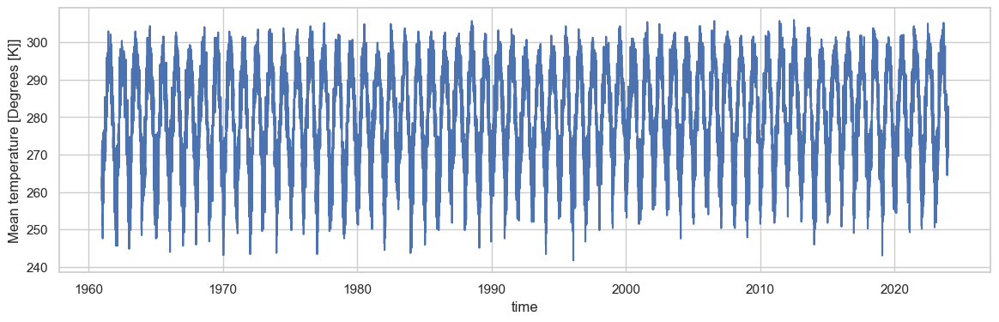

In [12]:

sns.set_theme(context='notebook', style='whitegrid')
plt.figure(figsize=(14,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [13]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(291.309174)
Coordinates:
    lat       float64 8B 45.0
    lon       float64 8B -93.25
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [14]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 3.48 ms, sys: 4.13 ms, total: 7.6 ms
Wall time: 7.03 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(292.05)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [15]:
thresh.values - stp_75.values

np.float64(-0.7408264160155795)

#### MSP airport MN 75th Percentile from GHCND data is 0.74 K warmer

### Try one year (2023) fit via Fourier

In [ ]:
da.tavg.values[0]

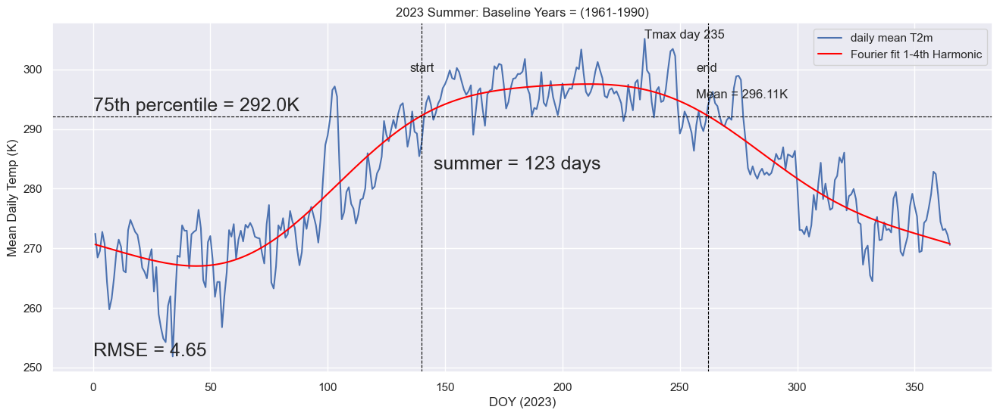

(140,
 262,
 0.21695018049885562,
 -0.23955740261234837,
 235,
 525.3000000000029,
 123,
 4.648343857365803,
 0.0,
 296.10853658536575,
 4.86388888888888)

In [16]:
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

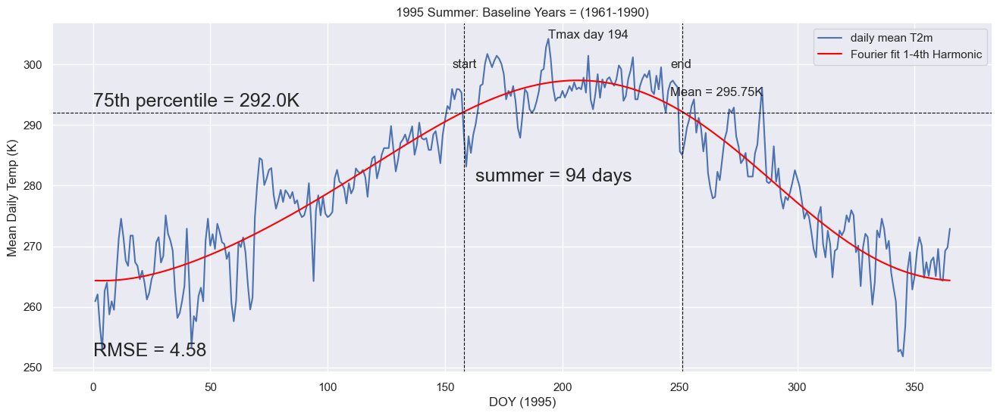

(158,
 251,
 0.19139555399800656,
 -0.23576375425565743,
 194,
 397.7000000000007,
 94,
 4.5798110577633455,
 0.0,
 295.7452127659574,
 4.791566265060283)

In [17]:
# how about 1995
input_year = 1995

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Looks to be working!

#### Plot of 1970 and 2023 time series

Threshold in C: 18.899999999999977


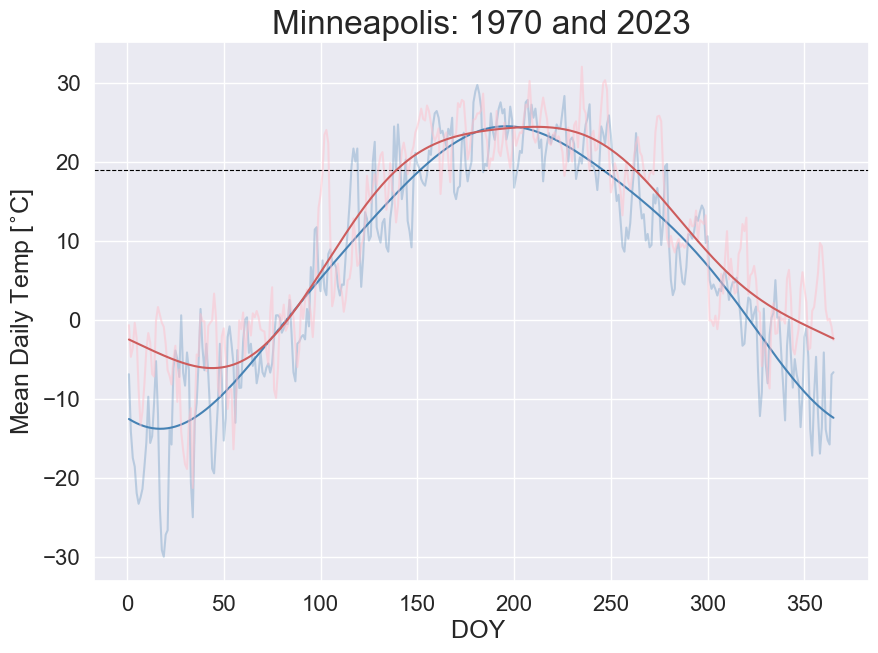

In [18]:
# have to essentially do the fourier fit process twice and put both on the figure


### 1970
input_year = 1970
da = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
thresh = stp_75


# DOY and T2m values for those days
x1 = np.arange(1,len(da.time)+1) 
y1 = da.tavg.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean = np.mean(y1)
y_norm = y1 - ymean
# perform DFT of temp data
coef = fft(y_norm)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp = np.copy(coef)
Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp = np.real(np.fft.ifft(Z_lp))

# add back in the original mean temp
y_lp = y_norm_lp + ymean

# create some x values for plotting polynomial fit
x_values = np.linspace(min(x1), max(x1), 365) 


### 2023
input_year = 2023
da = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
thresh = stp_75

# DOY and T2m values for those days
x2 = np.arange(1,len(da.time)+1) 
y2 = da.tavg.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean2 = np.mean(y2)
y_norm2 = y2 - ymean2
# perform DFT of temp data
coef2 = fft(y_norm2)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp2 = np.copy(coef2)
Z_lp2[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp2 = np.real(np.fft.ifft(Z_lp2))

# add back in the original mean temp
y_lp2 = y_norm_lp2 + ymean2

# create some x values for plotting polynomial fit
#x_values = np.linspace(min(x1), max(x1), 365) 

# convert values to Celsius
y1 = y1 + KtoC
y2 = y2 + KtoC
y_lp2 = y_lp2 + KtoC
y_lp = y_lp + KtoC
thresh = thresh + KtoC
print("Threshold in C: "+str(thresh.values))


# make plot if desired

plt.figure(figsize=(10,7))
plt.plot(x1,y1, label='T2m 1970', color='steelblue', alpha=0.3)
plt.plot(x_values, y_lp, label='1970 4th Harmonic', color='steelblue')
plt.axhline(thresh.values, color="black", linewidth=0.8, linestyle="dashed") 
# plt.axvline(first_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.axvline(last_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.annotate('start', xy=(first_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('end', xy=(last_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('summer = '+str(summer_length)+' days', xy=(first_day+5,np.mean(y_lp)), fontsize=18)
#plt.annotate('75th percentile = '+str(np.round(thresh.values,1))+'K', xy=(0,thresh.values+1), fontsize=12)
# plt.annotate('RMSE = '+str(np.round(rmse,2)), xy=(0, np.min(y1)), fontsize=18)
# plt.annotate('Mean = '+str(np.round(mean_t,2))+'K', xy=(last_day-5, mean_t-1), fontsize=12)

plt.plot(x1,y2, label='T2m 2023', color='pink', alpha=0.5)
plt.plot(x1, y_lp2, label='2023 4th Harmonic', color='indianred')



# SH days are relative to July 1
plt.xlabel('DOY ', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.title("Minneapolis: 1970 and 2023", fontsize=24)
#plt.legend()
plt.savefig("./Plots/minneapolis_1970_2023.png",bbox_inches='tight')
plt.savefig("./Plots/minneapolis_1970_2023.pdf",bbox_inches='tight')
plt.show()

#### 1961 vs 2023?

Threshold in C: 18.899999999999977


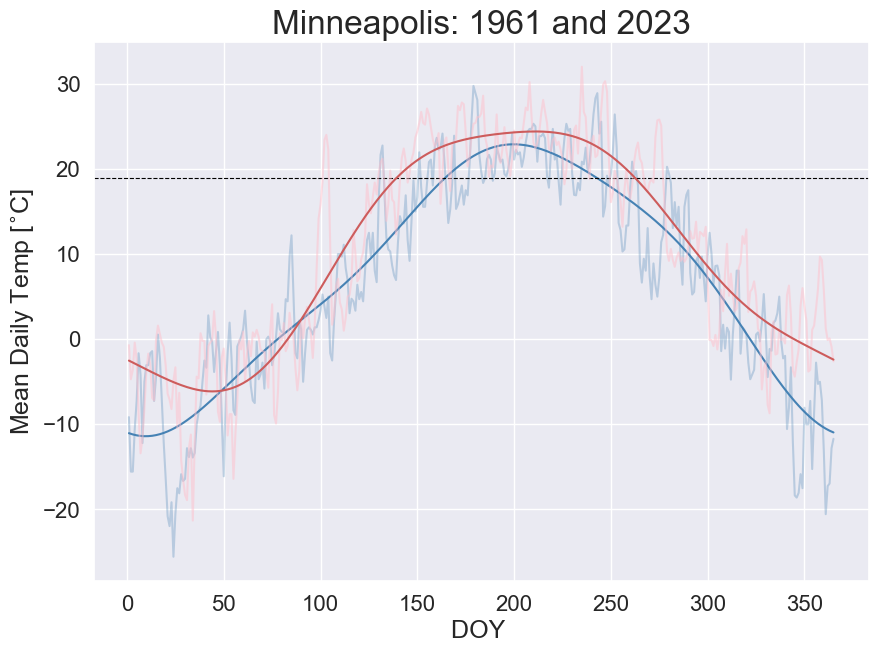

In [19]:
# have to essentially do the fourier fit process twice and put both on the figure


### 1961
input_year = 1961
da = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
thresh = stp_75


# DOY and T2m values for those days
x1 = np.arange(1,len(da.time)+1) 
y1 = da.tavg.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean = np.mean(y1)
y_norm = y1 - ymean
# perform DFT of temp data
coef = fft(y_norm)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp = np.copy(coef)
Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp = np.real(np.fft.ifft(Z_lp))

# add back in the original mean temp
y_lp = y_norm_lp + ymean

# create some x values for plotting polynomial fit
x_values = np.linspace(min(x1), max(x1), 365) 


### 2023
input_year = 2023
da = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
thresh = stp_75

# DOY and T2m values for those days
x2 = np.arange(1,len(da.time)+1) 
y2 = da.tavg.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean2 = np.mean(y2)
y_norm2 = y2 - ymean2
# perform DFT of temp data
coef2 = fft(y_norm2)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp2 = np.copy(coef2)
Z_lp2[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp2 = np.real(np.fft.ifft(Z_lp2))

# add back in the original mean temp
y_lp2 = y_norm_lp2 + ymean2

# create some x values for plotting polynomial fit
#x_values = np.linspace(min(x1), max(x1), 365) 

# convert values to Celsius
y1 = y1 + KtoC
y2 = y2 + KtoC
y_lp2 = y_lp2 + KtoC
y_lp = y_lp + KtoC
thresh = thresh + KtoC
print("Threshold in C: "+str(thresh.values))


# make plot if desired

plt.figure(figsize=(10,7))
plt.plot(x1,y1, label='T2m 1970', color='steelblue', alpha=0.3)
plt.plot(x_values, y_lp, label='1970 4th Harmonic', color='steelblue')
plt.axhline(thresh.values, color="black", linewidth=0.8, linestyle="dashed") 
# plt.axvline(first_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.axvline(last_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.annotate('start', xy=(first_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('end', xy=(last_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('summer = '+str(summer_length)+' days', xy=(first_day+5,np.mean(y_lp)), fontsize=18)
#plt.annotate('75th percentile = '+str(np.round(thresh.values,1))+'K', xy=(0,thresh.values+1), fontsize=12)
# plt.annotate('RMSE = '+str(np.round(rmse,2)), xy=(0, np.min(y1)), fontsize=18)
# plt.annotate('Mean = '+str(np.round(mean_t,2))+'K', xy=(last_day-5, mean_t-1), fontsize=12)

plt.plot(x1,y2, label='T2m 2023', color='pink', alpha=0.5)
plt.plot(x1, y_lp2, label='2023 4th Harmonic', color='indianred')



# SH days are relative to July 1
plt.xlabel('DOY ', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.title("Minneapolis: 1961 and 2023", fontsize=24)
#plt.legend()
plt.savefig("./Plots/minneapolis_1961_2023.png",bbox_inches='tight')
plt.savefig("./Plots/minneapolis_1961_2023.pdf",bbox_inches='tight')
plt.show()

#### Make plot of accumulated heat area for paper - using 1995 profile

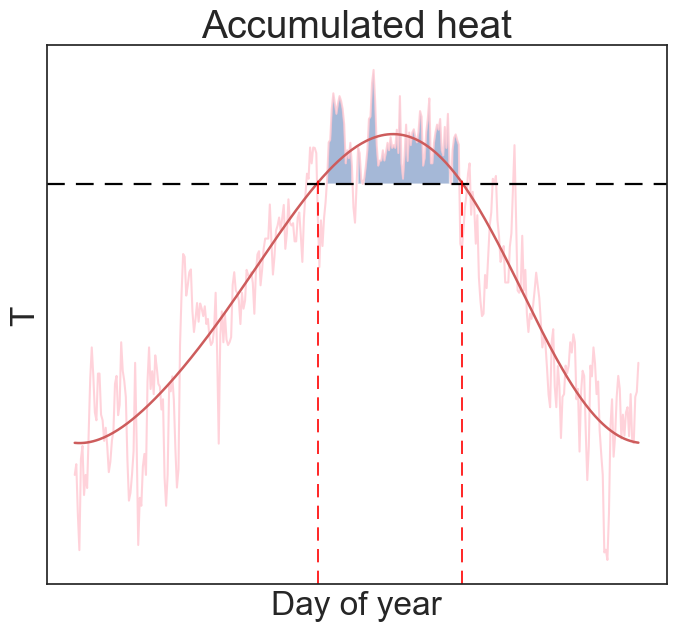

In [50]:
# set to whitegrid
#sns.set_theme(context='notebook', style='whitegrid')
sns.set_theme(context='notebook', style='white')


### 1970
input_year = 1995
da = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
thresh = stp_75


# DOY and T2m values for those days
x1 = np.arange(1,len(da.time)+1) 
y1 = da.tavg.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean = np.mean(y1)
y_norm = y1 - ymean
# perform DFT of temp data
coef = fft(y_norm)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp = np.copy(coef)
Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp = np.real(np.fft.ifft(Z_lp))

# add back in the original mean temp
y_lp = y_norm_lp + ymean

# create some x values for plotting polynomial fit
x_values = np.linspace(min(x1), max(x1), 365) 

# for filling in summer area only
x_fill = np.arange(158,252,1)


# convert values to Celsius
y1 = y1 + KtoC


y_lp = y_lp + KtoC
thresh = thresh + KtoC



# make plot if desired

plt.figure(figsize=(8,7))
plt.plot(x1,y1, label='T2m 1970', color='pink', alpha=0.7)
plt.plot(x_values, y_lp, label='1970 4th Harmonic', color='indianred', linewidth=1.8)
plt.axhline(thresh.values, color="black", linewidth=1.6, linestyle=(0, (8, 5))) 
plt.fill_between(x_values, thresh.values, y1, where=(x_values >= 158)&(x_values<252)&(y1 > thresh.values), alpha=0.5)
plt.axvline(158, ymin=0, ymax=0.75, color="red", linewidth=1.2, linestyle=(0, (8, 5)))
plt.axvline(251, ymin=0, ymax=0.75, color="red", linewidth=1.2, linestyle=(0, (8, 5)))
# plt.annotate('start', xy=(first_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('end', xy=(last_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('summer = '+str(summer_length)+' days', xy=(first_day+5,np.mean(y_lp)), fontsize=18)
#plt.annotate('75th percentile = '+str(np.round(thresh.values,1))+'K', xy=(0,thresh.values+1), fontsize=12)
# plt.annotate('RMSE = '+str(np.round(rmse,2)), xy=(0, np.min(y1)), fontsize=18)
# plt.annotate('Mean = '+str(np.round(mean_t,2))+'K', xy=(last_day-5, mean_t-1), fontsize=12)



# SH days are relative to July 1
plt.xlabel('Day of year', fontsize=24)

#plt.ylabel('Mean daily temperature ($^{\circ}$C)', fontsize=24)
plt.ylabel('T', fontsize=24)
#plt.xticks((0,100,200,300),fontsize=16)
#plt.yticks( fontsize=16)
plt.xticks((),fontsize=16)
plt.yticks((), fontsize=16)
plt.title("Accumulated heat", fontsize=28)
#plt.legend()
#plt.savefig("fourierfit_stats_"+str(cell_lat)+"_"+str(cell_lon)+"_"+str(yr)+".png")
plt.savefig("./Plots/AccumulatedHeat_Schematic.png",bbox_inches='tight')
plt.savefig("./Plots/AccumulatedHeat_Schematic.pdf",bbox_inches='tight')
plt.show()

In [33]:
np.round(thresh.values,1)

np.float64(18.9)

#### get mean temps for 1970-1975 and 2018-2023

In [344]:
mt_7075 = da_stp.tavg.sel(time=slice('1970','1975')).mean()
mt_1823 = da_stp.tavg.sel(time=slice('2018','2023')).mean()
print(mt_7075, mt_1823, mt_1823 - mt_7075)

<xarray.DataArray 'tavg' ()> Size: 8B
array(280.02736194) <xarray.DataArray 'tavg' ()> Size: 8B
array(281.85908261) <xarray.DataArray 'tavg' ()> Size: 8B
array(1.83172068)


### Climatology plots, 1961-2023 and 1990-2023

In [20]:
da_daily_clim_full = da_stp.tavg.groupby("time.dayofyear").mean()
da_daily_clim_an = da_stp.tavg.sel(time=slice('1990','2023')).groupby("time.dayofyear").mean()
da_daily_clim_base = da_stp.tavg.sel(time=slice('1961','1990')).groupby("time.dayofyear").mean()
da_daily_clim_full, da_daily_clim_an, da_daily_clim_base


#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()


#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()

(<xarray.DataArray 'tavg' (dayofyear: 366)> Size: 3kB
 array([263.65714286, 263.27539683, 263.48174603, 263.32936508,
        263.04126984, 262.83253968, 261.95714286, 262.64285714,
        262.2484127 , 262.53015873, 263.25396825, 263.50079365,
        262.99206349, 262.72301587, 262.41190476, 263.27380952,
        262.89047619, 262.93809524, 262.34603175, 262.65079365,
        264.32698413, 264.77380952, 263.65      , 264.15238095,
        263.57857143, 263.07857143, 263.11428571, 263.22142857,
        262.97460317, 262.66666667, 264.00079365, 263.63809524,
        262.95714286, 262.65396825, 262.90714286, 263.70873016,
        264.15793651, 264.04761905, 263.63412698, 264.59761905,
        264.52857143, 264.87698413, 265.34761905, 265.72380952,
        265.96031746, 265.09761905, 265.75079365, 267.24761905,
        267.98571429, 266.99126984, 267.94920635, 267.71349206,
        267.92698413, 268.00634921, 267.66746032, 266.85873016,
        268.00952381, 268.79047619, 269.08174603, 

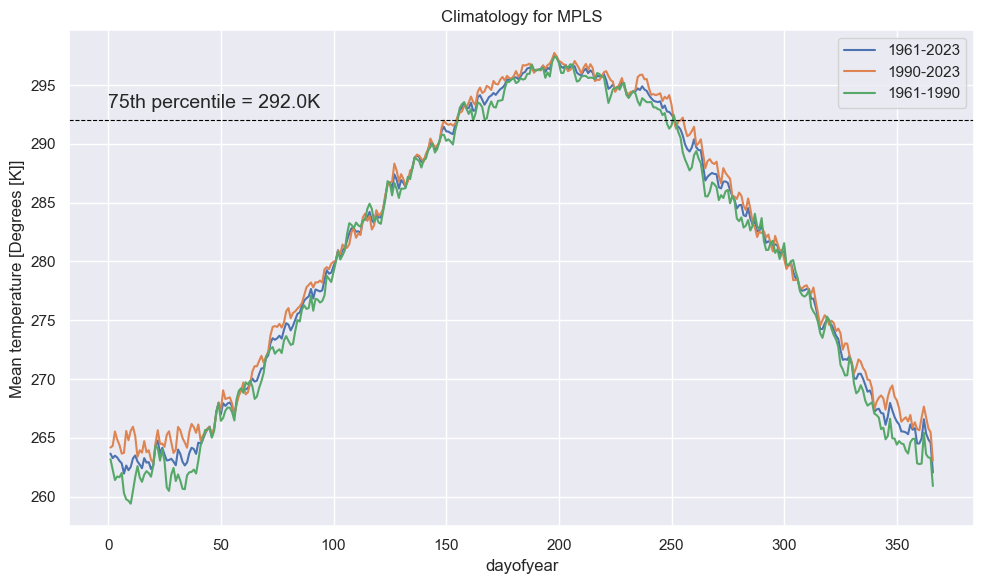

In [21]:
# plot both to compare
plt.figure(figsize=(10,6))
da_daily_clim_full.plot(label='1961-2023')
da_daily_clim_an.plot(label='1990-2023')
da_daily_clim_base.plot(label='1961-1990')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for MPLS")
plt.tight_layout()
plt.show()

In [22]:
# get 30D rolling clim
da_daily_clim_full_30dayroll = da_daily_clim_full.rolling(dayofyear=30,center=True, min_periods=2).mean()
da_daily_clim_base_30dayroll = da_daily_clim_base.rolling(dayofyear=30,center=True, min_periods=2).mean()
da_daily_clim_an_30dayroll = da_daily_clim_an.rolling(dayofyear=30,center=True, min_periods=2).mean()
#da_daily_clim_full_30dayroll

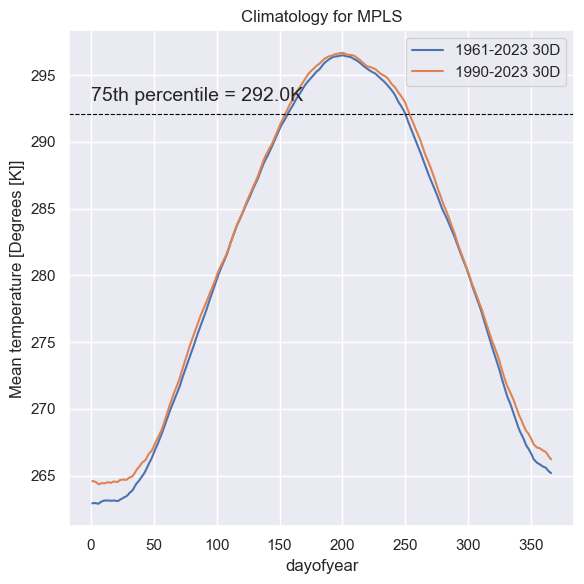

In [23]:
# plot both to compare
plt.figure(figsize=(6,6))
da_daily_clim_full_30dayroll.plot(label='1961-2023 30D')
da_daily_clim_an_30dayroll.plot(label='1990-2023 30D')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for MPLS")
plt.tight_layout()
plt.show()

#### Climatology plot for paper

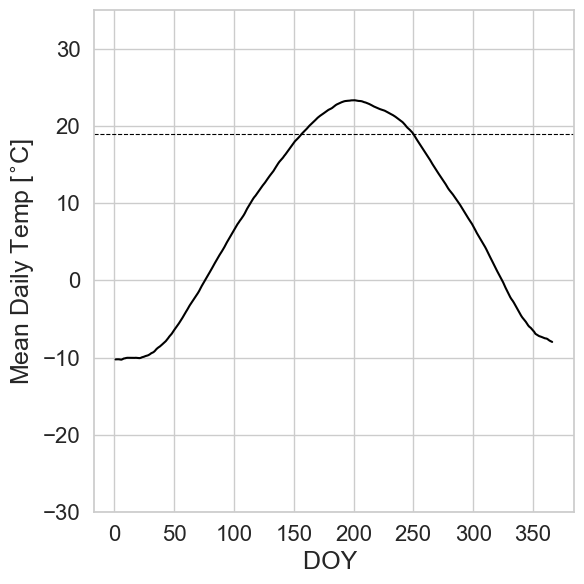

In [113]:

sns.set_theme(context='notebook', style='whitegrid')

plt.figure(figsize=(6,6))
(da_daily_clim_full_30dayroll+KtoC).plot(color="black", label='1961-2023 30D')
#da_daily_clim_an_30dayroll.plot(label='1990-2023 30D')
plt.axhline(stp_75.values+KtoC, color="black", linewidth=0.8, linestyle="dashed")
#plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
#plt.legend()
#plt.title("Climatology for MPLS")


plt.xlabel('DOY ', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.ylim(-30,35)
#plt.title("Minneapolis: 1970 and 2023", fontsize=24)
plt.tight_layout()
#plt.legend()
plt.savefig("./Plots/minneapolis_1961-2023_climatology.png",bbox_inches='tight')
plt.savefig("./Plots/minneapolis_1961-2023_climatology.pdf",bbox_inches='tight')

plt.show()

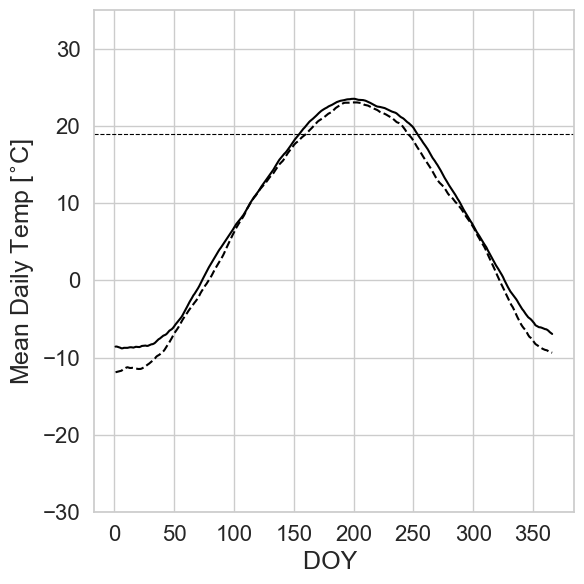

In [115]:

sns.set_theme(context='notebook', style='whitegrid')

plt.figure(figsize=(6,6))
(da_daily_clim_an_30dayroll+KtoC).plot(color="black", label='1990-2023 30D')
(da_daily_clim_base_30dayroll+KtoC).plot(color="black", linestyle='dashed', label='1961-1990 30D')
#da_daily_clim_an_30dayroll.plot(label='1990-2023 30D')
plt.axhline(stp_75.values+KtoC, color="black", linewidth=0.8, linestyle="dashed")
#plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
#plt.legend()
#plt.title("Climatology for MPLS")


plt.xlabel('DOY ', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.ylim(-30,35)
#plt.title("Minneapolis: 1970 and 2023", fontsize=24)
plt.tight_layout()
#plt.legend()
plt.savefig("./Plots/minneapolis_1961-1990_1990-2023_climatology.png",bbox_inches='tight')
plt.savefig("./Plots/minneapolis_1961-1990_1990-2023_climatology.pdf",bbox_inches='tight')

plt.show()

In [21]:
sns.set_theme(context='notebook', style='darkgrid')

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats

In [349]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [350]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 265 ms, sys: 8.03 ms, total: 273 ms
Wall time: 271 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,165,243,0.205268,-0.146340,79,231.65,179,294.517722
1,1962,160,229,0.094240,-0.091589,70,117.60,179,293.053571
2,1963,162,244,0.197626,-0.127999,83,264.30,181,294.690361
3,1964,148,238,0.252824,-0.137940,91,334.00,213,294.718681
4,1965,162,231,0.134586,-0.155505,70,171.50,204,294.252143
5,1966,163,240,0.260860,-0.249328,78,305.80,192,295.447436
6,1967,176,239,0.114781,-0.165603,64,132.30,202,293.156250
7,1968,170,244,0.150863,-0.152793,75,209.25,234,294.022000
8,1969,170,255,0.137728,-0.256550,86,313.35,241,295.123837
9,1970,152,246,0.220402,-0.180637,95,385.20,181,295.843158


### write out resulting summer stats

In [351]:
# write out results
output_path = "../../../Data/GHCND/msp_minnesota_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [24]:
# re-load 
input_path = "../../../Data/GHCND/msp_minnesota_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,165,243,0.205268,-0.146340,79,231.65,179,294.517722
1,1,1962,160,229,0.094240,-0.091589,70,117.60,179,293.053571
2,2,1963,162,244,0.197626,-0.127999,83,264.30,181,294.690361
3,3,1964,148,238,0.252824,-0.137940,91,334.00,213,294.718681
4,4,1965,162,231,0.134586,-0.155505,70,171.50,204,294.252143
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,159,253,0.124908,-0.283768,95,304.10,200,295.018421
59,59,2020,152,245,0.225283,-0.223677,94,412.80,238,296.393617
60,60,2021,146,260,0.192252,-0.196772,115,533.40,156,296.270000
61,61,2022,150,254,0.256945,-0.165532,105,443.30,171,296.127143


#### get mean Summer temps for 1965-1970 and 2018-2023

In [353]:
mt_7075 = df_summ.query("Year >= 1965 & Year <= 1970")['SummerTavg'].mean()
mt_1823 = df_summ.query("Year >= 2018 & Year <= 2023")['SummerTavg'].mean()
print(mt_7075, mt_1823, mt_1823 - mt_7075)

294.6408039764363 296.03385262441753 1.3930486479812316


### MSP Minnesota: Plot the summer stats

In [25]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

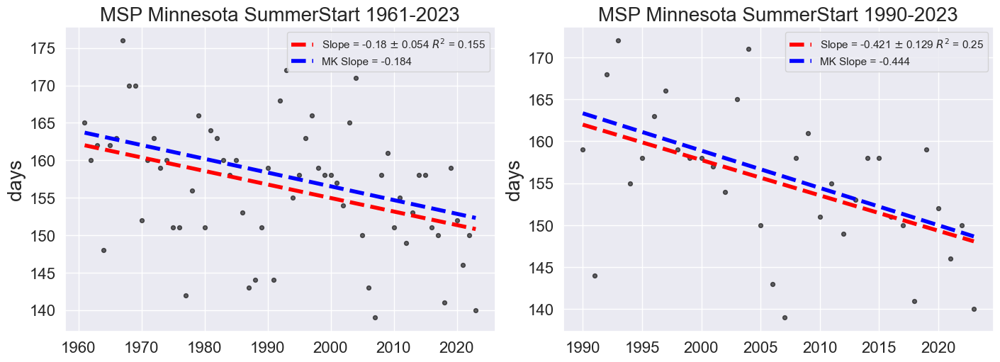

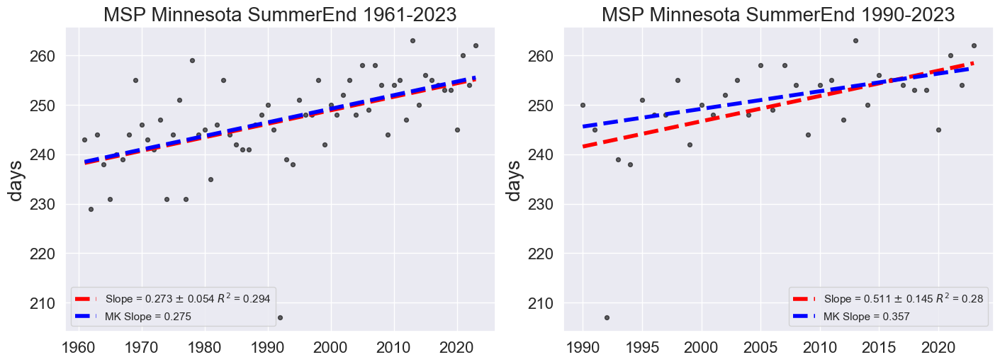

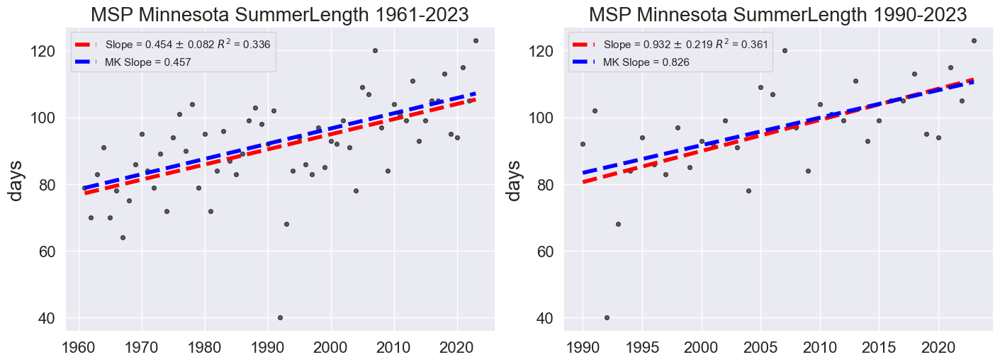

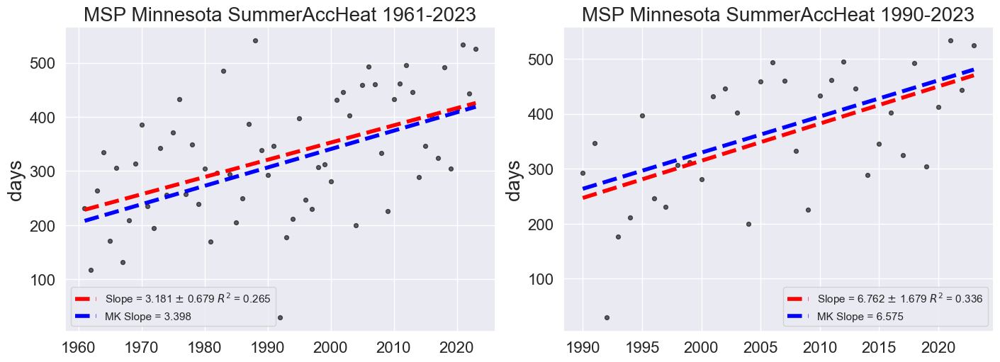

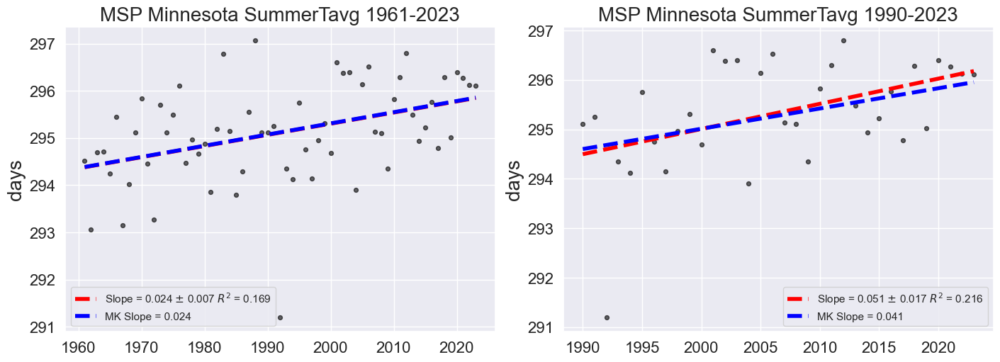

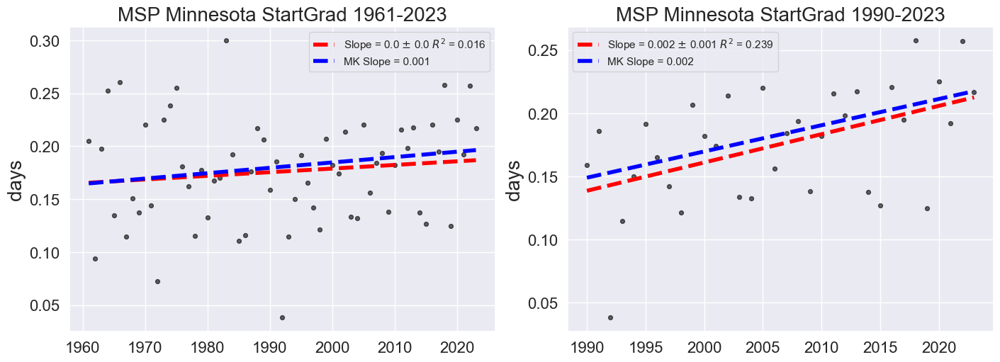

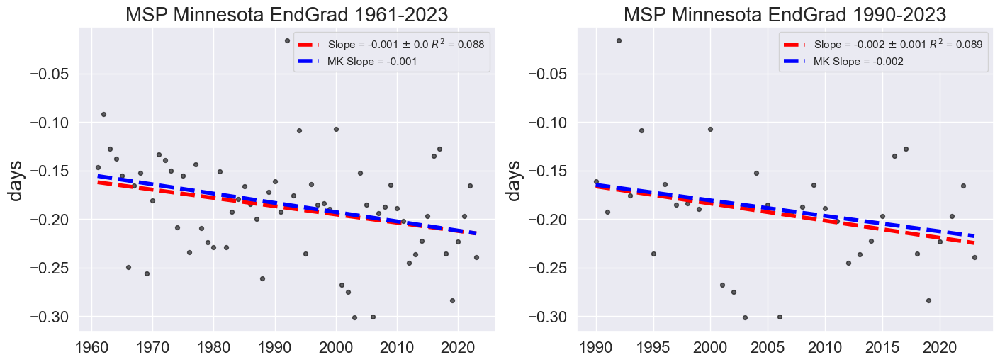

In [26]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("MSP Minnesota "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("MSP Minnesota "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

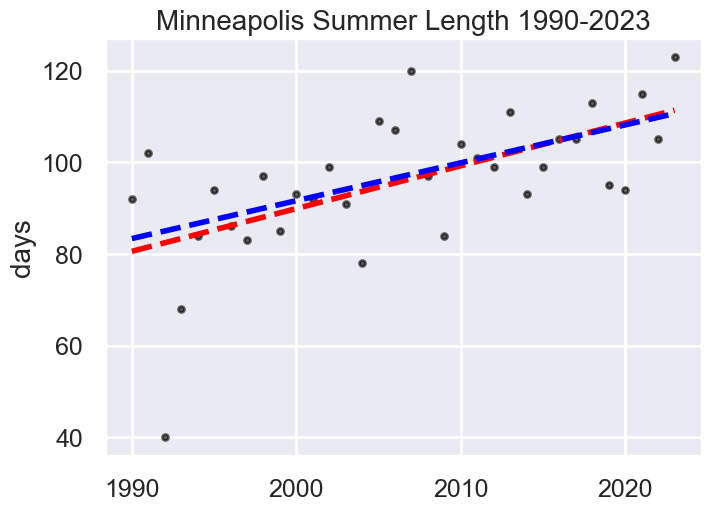

In [93]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Minneapolis Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/minneapolis_summer_plot.png")



#### MPLS length vs mean summer T

Text(0, 0.5, 'days')

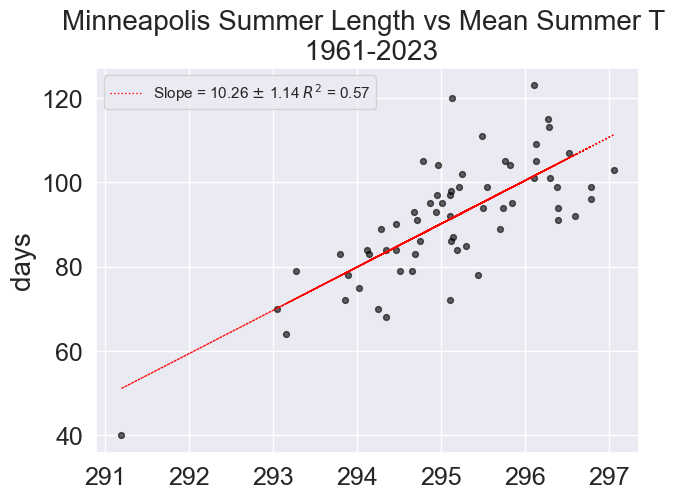

In [42]:
# plot properties so I can more easily tweak them
s = 18
lw = 1
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('notebook', font_scale = 1)



# variables for plot
x = df_summ.SummerTavg
y = df_summ.SummerLength

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],2)
slope_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),2)

# # add MK slope
# res_mk = mk.original_test(y)
# mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5))#, layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle=":", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
# ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Minneapolis Summer Length vs Mean Summer T \n 1961-2023", fontsize=fs)
ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)

Text(0, 0.5, 'days')

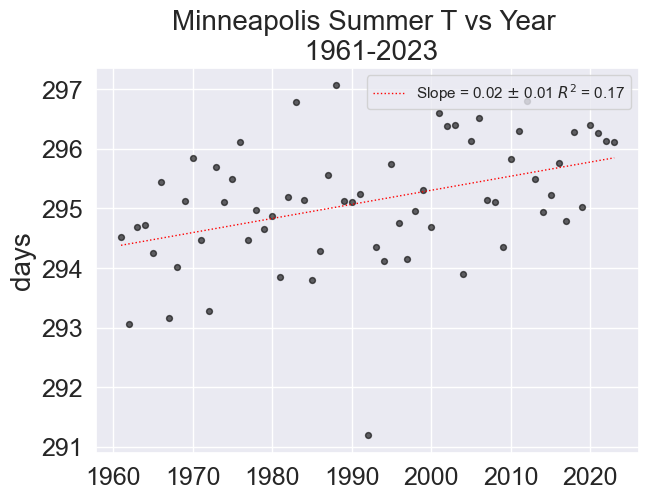

In [44]:
# plot properties so I can more easily tweak them
s = 18
lw = 1
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('notebook', font_scale = 1)



# variables for plot
x = df_summ.Year
y = df_summ.SummerTavg

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],2)
slope_sd = np.round(np.sqrt(V[0][0]),2)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),2)

# # add MK slope
# res_mk = mk.original_test(y)
# mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5))#, layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle=":", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
# ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Minneapolis Summer T vs Year \n 1961-2023", fontsize=fs)
ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)

#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [47]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 45.0
    lon      float64 8B -93.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 45.0
    lon      float64 8B -93.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 9.32 +/- 2.19
OLS Slope ERA5: 6.790000000000001 +/- 1.7999999999999998


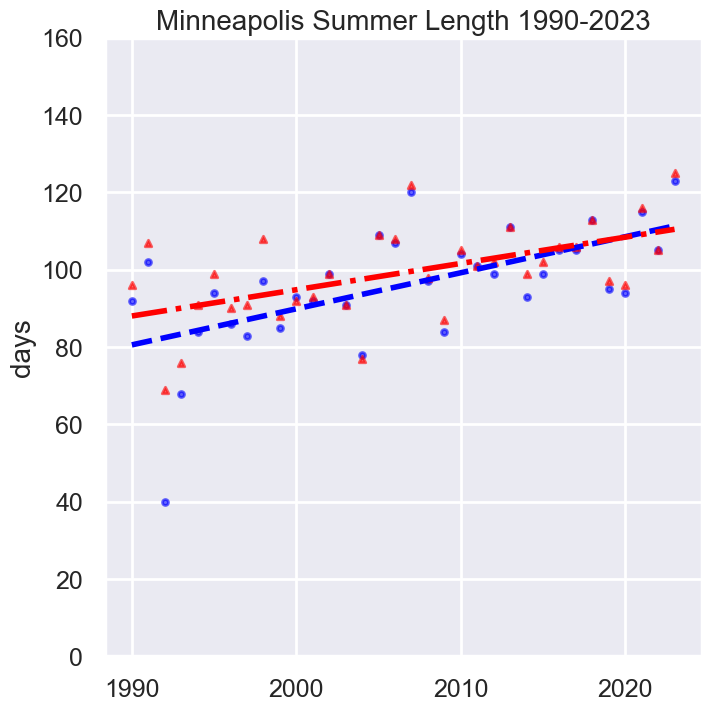

In [48]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,7), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Minneapolis Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(0,160)
plt.savefig("../../../Data/GHCND/Plots/minneapolis_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/minneapolis_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [49]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.361
Model:                            OLS   Adj. R-squared:                  0.341
Method:                 Least Squares   F-statistic:                     18.11
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           0.000170
Time:                        10:24:52   Log-Likelihood:                -133.18
No. Observations:                  34   AIC:                             270.4
Df Residuals:                      32   BIC:                             273.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1775.0255    439.650     -4.037      0.0

In [50]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.308
Model:                            OLS   Adj. R-squared:                  0.286
Method:                 Least Squares   F-statistic:                     14.23
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           0.000662
Time:                        10:24:54   Log-Likelihood:                -126.52
No. Observations:                  34   AIC:                             257.0
Df Residuals:                      32   BIC:                             260.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1264.0516    361.437     -3.497      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: 67.61999999999999 +/- 16.79
OLS Slope ERA5: 56.260000000000005 +/- 16.0


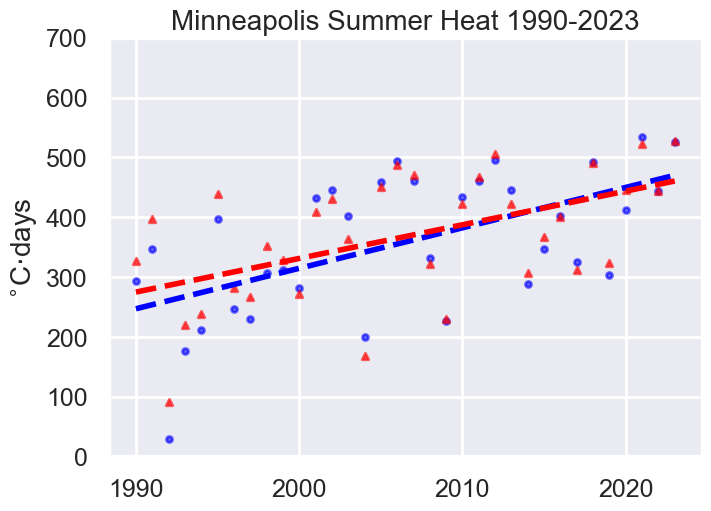

In [51]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Minneapolis Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/minneapolis_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/minneapolis_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [52]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.336
Model:                            OLS   Adj. R-squared:                  0.316
Method:                 Least Squares   F-statistic:                     16.21
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           0.000325
Time:                        10:29:43   Log-Likelihood:                -202.43
No. Observations:                  34   AIC:                             408.9
Df Residuals:                      32   BIC:                             411.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.321e+04   3369.910     -3.920      0.0

In [53]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.279
Model:                            OLS   Adj. R-squared:                  0.256
Method:                 Least Squares   F-statistic:                     12.36
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00134
Time:                        10:29:45   Log-Likelihood:                -200.79
No. Observations:                  34   AIC:                             405.6
Df Residuals:                      32   BIC:                             408.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.092e+04   3211.310     -3.401      0.0

#### End Gradient with ERA5 data

In [116]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 45.0
    lon      float64 8B -93.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 45.0
    lon      float64 8B -93.25
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.0177 +/- 0.01
OLS Slope ERA5: -0.0111 +/- 0.007


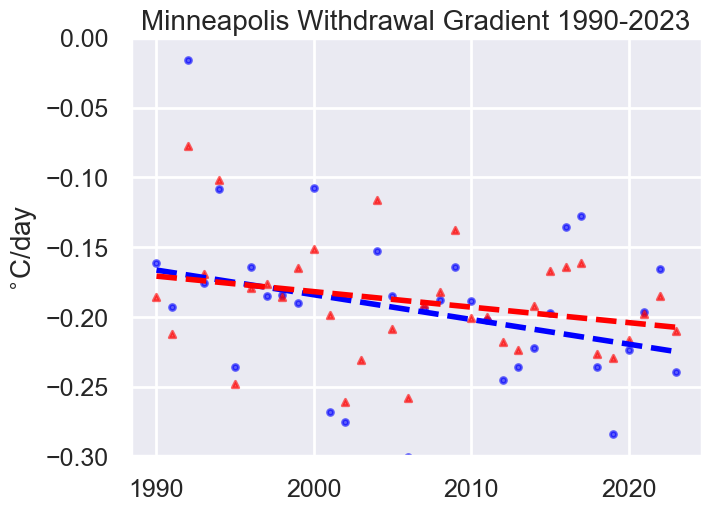

In [117]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Minneapolis Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/minneapolis_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/minneapolis_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: 0.022399999999999996 +/- 0.0071
OLS Slope ERA5: 0.0176 +/- 0.0064


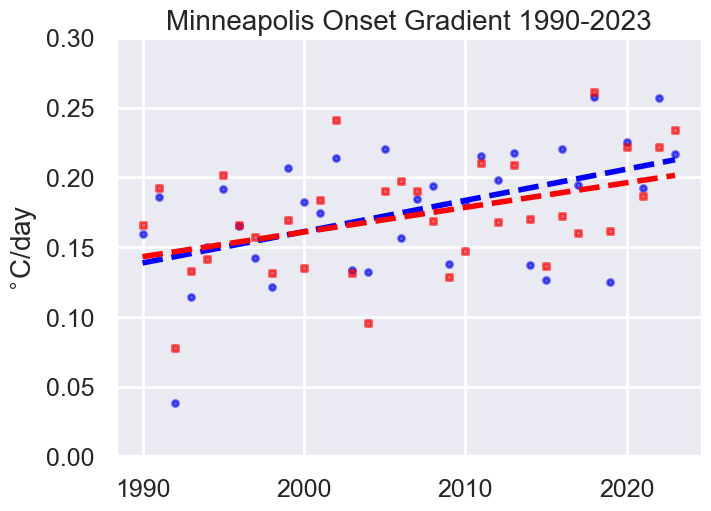

In [118]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='s', alpha=alpha)

ax2.set_title("Minneapolis Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/minneapolis_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/minneapolis_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

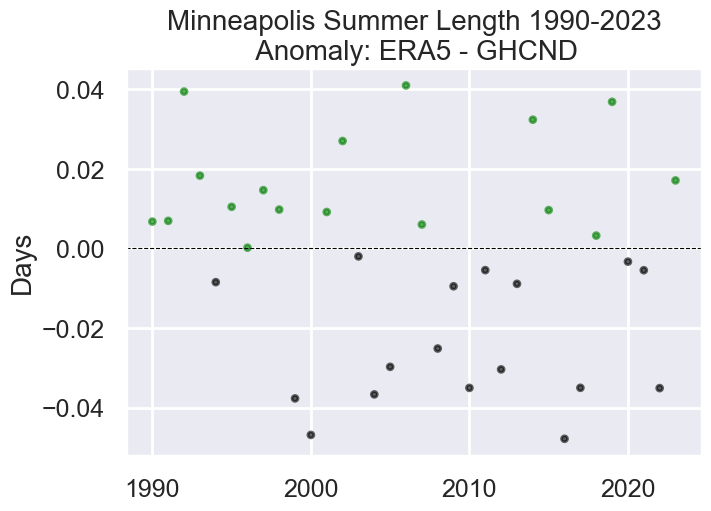

In [363]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Minneapolis Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

## **Sydney (Australia) Airport

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:ASN00066037/detail

### This is in the SH so we need 2024

In [94]:
df = pd.read_csv("../../../Data/GHCND/sydney-airport-2025-04-09T18-15-56.csv")
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,1961-01-01,21.6,27.8,20.0
1,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,1961-01-02,21.3,23.2,19.4
2,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,1961-01-03,18.9,21.1,18.2
3,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,1961-01-04,22.3,24.9,15.0
4,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,1961-01-05,20.9,24.3,18.2
...,...,...,...,...,...,...,...,...,...
23371,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,2024-12-27,25.6,39.5,21.8
23372,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,2024-12-28,23.0,27.1,18.9
23373,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,2024-12-29,23.3,29.8,18.0
23374,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,2024-12-30,23.7,27.7,19.8


In [ ]:
df.info()

### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [157]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,1961-01-01,21.6,27.8,20.0
1,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,1961-01-02,21.3,23.2,19.4
2,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,1961-01-03,18.9,21.1,18.2
3,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,1961-01-04,22.3,24.9,15.0
4,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,1961-01-05,20.9,24.3,18.2
...,...,...,...,...,...,...,...,...,...
23371,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,2024-12-27,25.6,39.5,21.8
23372,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,2024-12-28,23.0,27.1,18.9
23373,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,2024-12-29,23.3,29.8,18.0
23374,ASN00066037,"SYDNEY AIRPORT AMO, AS",-33.9465,151.1731,6.0,2024-12-30,23.7,27.7,19.8


In [ ]:
df.info()

#### Missing one TAVG but I'll interpolate to fill it hopefully

In [158]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,294.75
1961-01-02,294.45
1961-01-03,292.05
1961-01-04,295.45
1961-01-05,294.05
...,...
2024-12-27,298.75
2024-12-28,296.15
2024-12-29,296.45


In [159]:
#pd.set_option('display.max_rows', 500)
df_sub['tavg'].tail(357)


time
2024-01-10    298.75
2024-01-11    297.95
2024-01-12    298.55
2024-01-13    297.95
2024-01-14    295.85
               ...  
2024-12-27    298.75
2024-12-28    296.15
2024-12-29    296.45
2024-12-30    296.85
2024-12-31    297.75
Name: tavg, Length: 357, dtype: float64

In [160]:
# linear interpolation to fill the last one
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
df_sub.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 23376 entries, 1961-01-01 to 2024-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tavg    23376 non-null  float64
dtypes: float64(1)
memory usage: 365.2 KB


In [ ]:
# df1 = df_sub[df_sub.isna().any(axis=1)]
# print(df1)

### Convert from Pandas to XArray

In [161]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 374kB
Dimensions:  (time: 23376)
Coordinates:
  * time     (time) datetime64[ns] 187kB 1961-01-01 1961-01-02 ... 2024-12-31
Data variables:
    tavg     (time) float64 187kB 294.8 294.4 292.0 295.4 ... 296.4 296.8 297.8

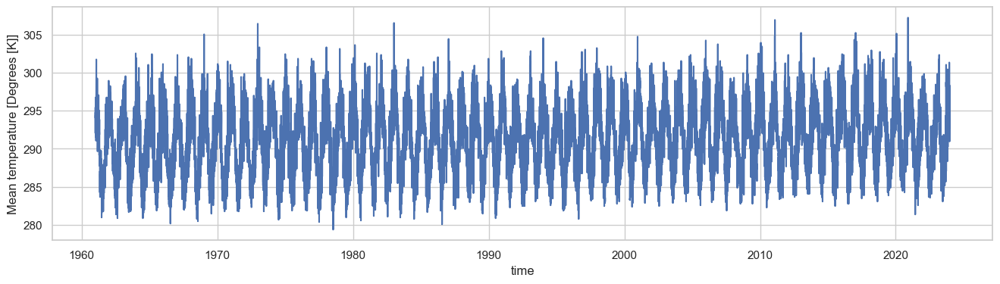

In [162]:
plt.figure(figsize=(16,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [163]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(293.461273)
Coordinates:
    lat       float64 8B -34.0
    lon       float64 8B 151.2
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [164]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 2.56 ms, sys: 809 μs, total: 3.37 ms
Wall time: 2.64 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(294.55)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [92]:
thresh.values - stp_75.values

np.float64(-1.0887268066405795)

#### Sydney Australia 75th Percentile from GHCND data is 1.09 K warmer

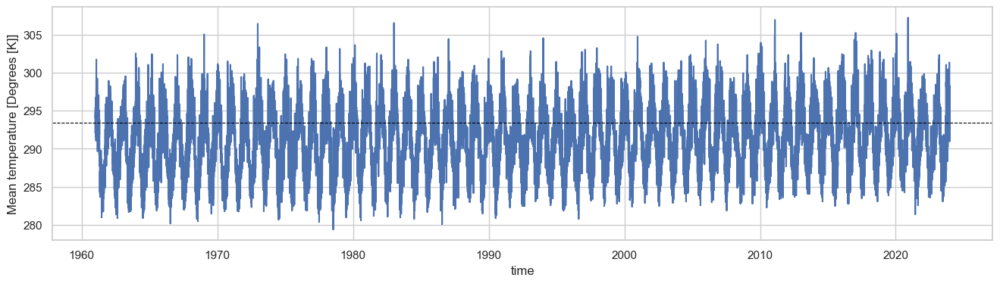

In [165]:
plt.figure(figsize=(16,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()
plt.axhline(thresh.values, color="black", linewidth=0.8, linestyle="dashed")

### Try one year (2023) fit via Fourier

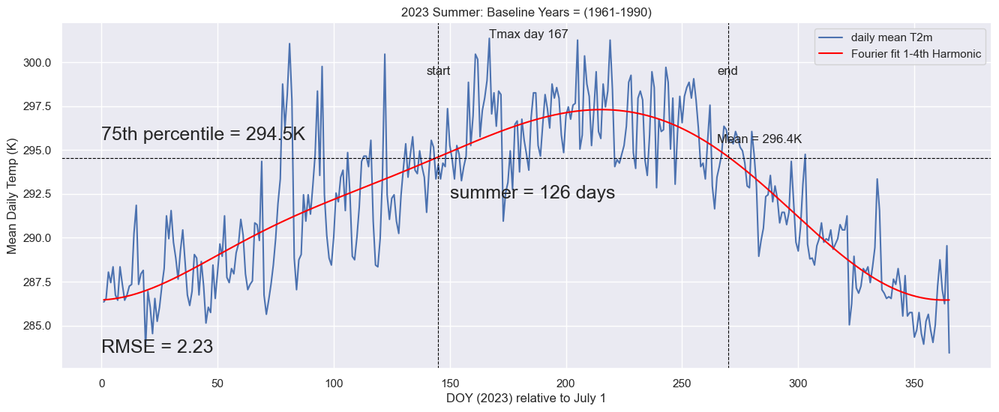

(145,
 270,
 0.0562053678597465,
 -0.09921457945824841,
 167,
 262.7000000000007,
 126,
 2.227892238259502,
 0.0,
 296.40238095238095,
 2.6806122448979295)

In [208]:
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the SH we DO need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, False)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

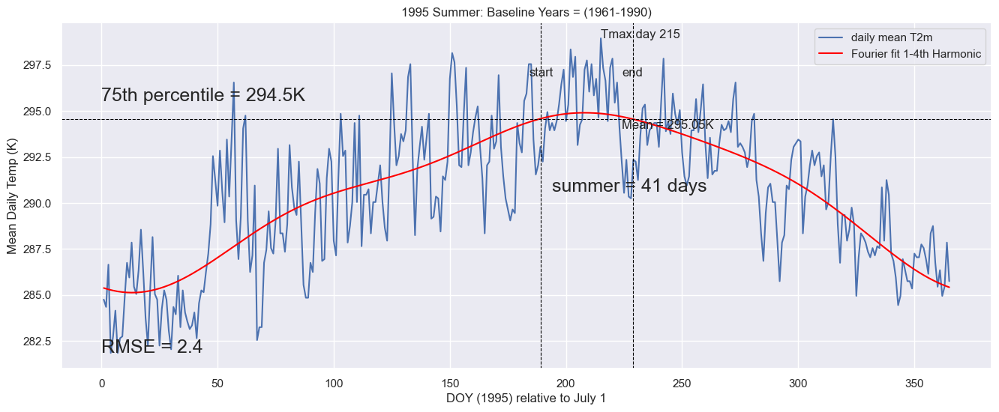

(189,
 229,
 0.03210884128091607,
 -0.03173983585764972,
 215,
 48.400000000000546,
 41,
 2.4040309826114235,
 0.0,
 295.04512195121947,
 2.1043478260869506)

In [376]:
# how about 1995
input_year = 1995
da = da_stp.sel(time=str(input_year))
# since this is in the SH we DO need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, False)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Wow 1995 was a cold summer for Sydney

### also 1970

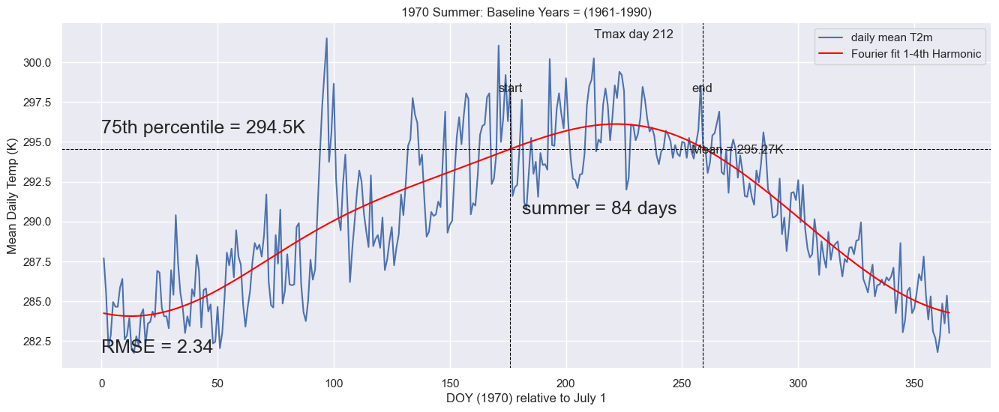

(176,
 259,
 0.05397987416398564,
 -0.08093975284015187,
 212,
 104.39999999999964,
 84,
 2.3363094293901727,
 0.0,
 295.2708333333333,
 2.0076923076923094)

In [377]:
# how about 1995
input_year = 1970

da = da_stp.sel(time=str(input_year))
# since this is in the SH we DO need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, False)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Make plot of 1970 and 2023 time series and fits for paper - they have similar shapes

Threshold in C: 21.399999999999977


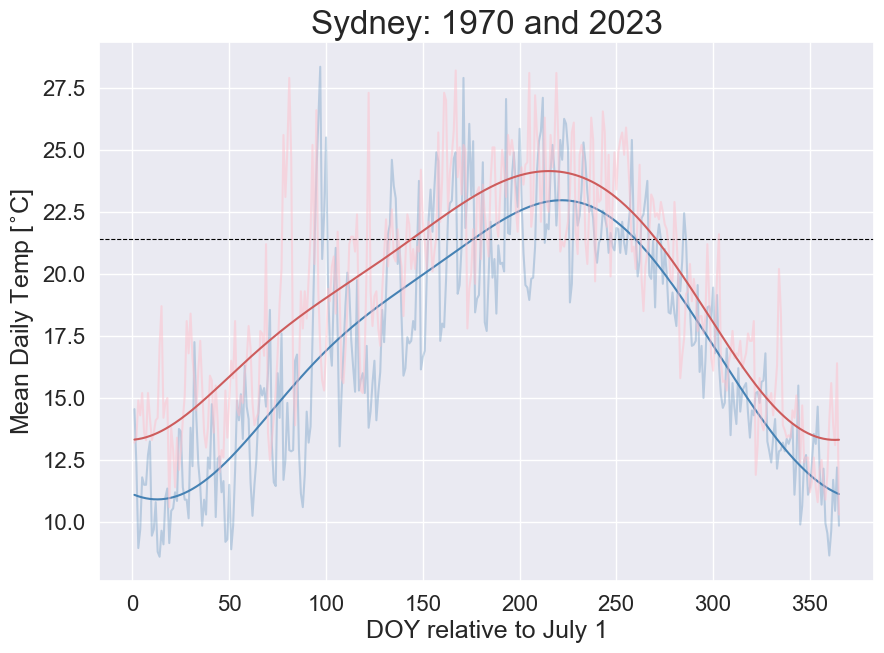

In [209]:
# have to essentially do the fourier fit process twice and put both on the figure


### 1970
input_year = 1970
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)
curr = da.tavg
nxt = da_next.tavg
thresh = stp_75

# data for fit
ds_1970 = xr.concat([curr, nxt], dim="time")

# get the current year for slicing
input_year = curr.time.dt.year.values[0]

# select July 1 - June 30 across the two years to do fit
startdate = str(input_year)+'-07-01' # 182nd day of a normal year
enddate = str(input_year+1)+'-06-30'

sh_yr = ds_1970.sel(time=slice(startdate,enddate))

# DOY (relative to July 1) and T2m values for those days
x1 = np.arange(1,len(sh_yr.time)+1) 
y1 = sh_yr.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean = np.mean(y1)
y_norm = y1 - ymean
# perform DFT of temp data
coef = fft(y_norm)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp = np.copy(coef)
Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp = np.real(np.fft.ifft(Z_lp))

# add back in the original mean temp
y_lp = y_norm_lp + ymean

# create some x values for plotting polynomial fit
x_values = np.linspace(min(x1), max(x1), 365) 


### 2023
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)
curr = da.tavg
nxt = da_next.tavg
thresh = stp_75

# data for fit
ds_2023 = xr.concat([curr, nxt], dim="time")

# get the current year for slicing
input_year = curr.time.dt.year.values[0]

# select July 1 - June 30 across the two years to do fit
startdate = str(input_year)+'-07-01' # 182nd day of a normal year
enddate = str(input_year+1)+'-06-30'

sh_yr = ds_2023.sel(time=slice(startdate,enddate))

# DOY (relative to July 1) and T2m values for those days
x2 = np.arange(1,len(sh_yr.time)+1) 
y2 = sh_yr.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean2 = np.mean(y2)
y_norm2 = y2 - ymean2
# perform DFT of temp data
coef2 = fft(y_norm2)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp2 = np.copy(coef2)
Z_lp2[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp2 = np.real(np.fft.ifft(Z_lp2))

# add back in the original mean temp
y_lp2 = y_norm_lp2 + ymean2

# create some x values for plotting polynomial fit
#x_values = np.linspace(min(x1), max(x1), 365) 

# convert values to Celsius
y1 = y1 + KtoC
y2 = y2 + KtoC
y_lp2 = y_lp2 + KtoC
y_lp = y_lp + KtoC
thresh = thresh + KtoC
print("Threshold in C: "+str(thresh.values))


# make plot if desired

plt.figure(figsize=(10,7))
plt.plot(x1,y1, label='T2m 1970', color='steelblue', alpha=0.3)
plt.plot(x_values, y_lp, label='1970 4th Harmonic', color='steelblue')
plt.axhline(thresh.values, color="black", linewidth=0.8, linestyle="dashed") 
# plt.axvline(first_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.axvline(last_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.annotate('start', xy=(first_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('end', xy=(last_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('summer = '+str(summer_length)+' days', xy=(first_day+5,np.mean(y_lp)), fontsize=18)
#plt.annotate('75th percentile = '+str(np.round(thresh.values,1))+'K', xy=(0,thresh.values+1), fontsize=12)
# plt.annotate('RMSE = '+str(np.round(rmse,2)), xy=(0, np.min(y1)), fontsize=18)
# plt.annotate('Mean = '+str(np.round(mean_t,2))+'K', xy=(last_day-5, mean_t-1), fontsize=12)

plt.plot(x1,y2, label='T2m 2023', color='pink', alpha=0.5)
plt.plot(x1, y_lp2, label='2023 4th Harmonic', color='indianred')



# SH days are relative to July 1
plt.xlabel('DOY relative to July 1', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.title("Sydney: 1970 and 2023", fontsize=24)
#plt.legend()
plt.savefig("./Plots/sydney_1970_2023.png",bbox_inches='tight')
plt.savefig("./Plots/sydney_1970_2023.pdf",bbox_inches='tight')
plt.show()



#### 1961 and 2023 ?

Threshold in C: 21.399999999999977


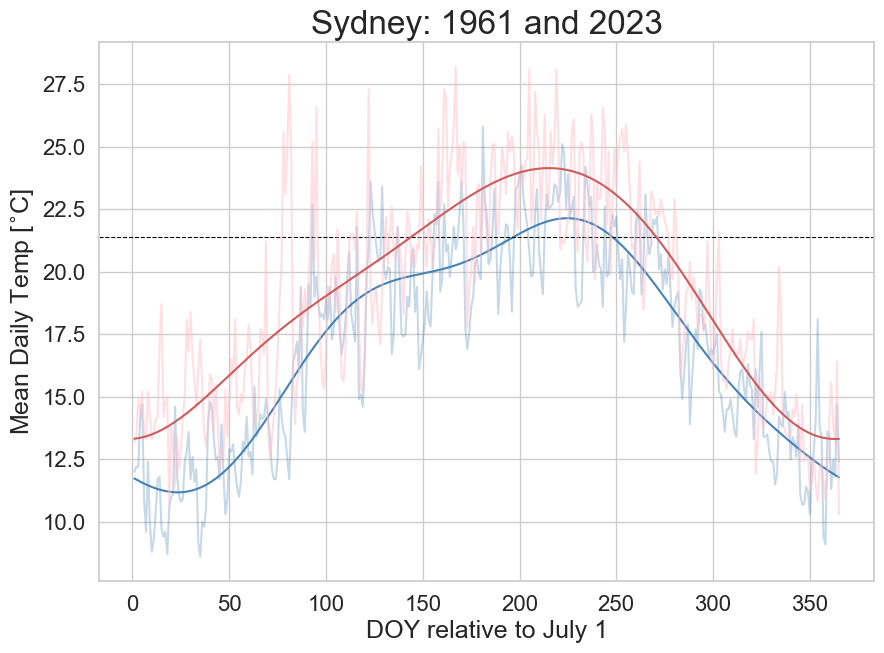

In [166]:
# have to essentially do the fourier fit process twice and put both on the figure


### 1970
input_year = 1961
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)
curr = da.tavg
nxt = da_next.tavg
thresh = stp_75

# data for fit
ds_1970 = xr.concat([curr, nxt], dim="time")

# get the current year for slicing
input_year = curr.time.dt.year.values[0]

# select July 1 - June 30 across the two years to do fit
startdate = str(input_year)+'-07-01' # 182nd day of a normal year
enddate = str(input_year+1)+'-06-30'

sh_yr = ds_1970.sel(time=slice(startdate,enddate))

# DOY (relative to July 1) and T2m values for those days
x1 = np.arange(1,len(sh_yr.time)+1) 
y1 = sh_yr.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean = np.mean(y1)
y_norm = y1 - ymean
# perform DFT of temp data
coef = fft(y_norm)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp = np.copy(coef)
Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp = np.real(np.fft.ifft(Z_lp))

# add back in the original mean temp
y_lp = y_norm_lp + ymean

# create some x values for plotting polynomial fit
x_values = np.linspace(min(x1), max(x1), 365) 


### 2023
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year+1))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)
curr = da.tavg
nxt = da_next.tavg
thresh = stp_75

# data for fit
ds_2023 = xr.concat([curr, nxt], dim="time")

# get the current year for slicing
input_year = curr.time.dt.year.values[0]

# select July 1 - June 30 across the two years to do fit
startdate = str(input_year)+'-07-01' # 182nd day of a normal year
enddate = str(input_year+1)+'-06-30'

sh_yr = ds_2023.sel(time=slice(startdate,enddate))

# DOY (relative to July 1) and T2m values for those days
x2 = np.arange(1,len(sh_yr.time)+1) 
y2 = sh_yr.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean2 = np.mean(y2)
y_norm2 = y2 - ymean2
# perform DFT of temp data
coef2 = fft(y_norm2)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp2 = np.copy(coef2)
Z_lp2[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp2 = np.real(np.fft.ifft(Z_lp2))

# add back in the original mean temp
y_lp2 = y_norm_lp2 + ymean2

# create some x values for plotting polynomial fit
#x_values = np.linspace(min(x1), max(x1), 365) 

# convert values to Celsius
y1 = y1 + KtoC
y2 = y2 + KtoC
y_lp2 = y_lp2 + KtoC
y_lp = y_lp + KtoC
thresh = thresh + KtoC
print("Threshold in C: "+str(thresh.values))


# make plot if desired

plt.figure(figsize=(10,7))
plt.plot(x1,y1, label='T2m 1961', color='steelblue', alpha=0.3)
plt.plot(x_values, y_lp, label='1961 4th Harmonic', color='steelblue')
plt.axhline(thresh.values, color="black", linewidth=0.8, linestyle="dashed") 
# plt.axvline(first_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.axvline(last_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.annotate('start', xy=(first_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('end', xy=(last_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('summer = '+str(summer_length)+' days', xy=(first_day+5,np.mean(y_lp)), fontsize=18)
#plt.annotate('75th percentile = '+str(np.round(thresh.values,1))+'K', xy=(0,thresh.values+1), fontsize=12)
# plt.annotate('RMSE = '+str(np.round(rmse,2)), xy=(0, np.min(y1)), fontsize=18)
# plt.annotate('Mean = '+str(np.round(mean_t,2))+'K', xy=(last_day-5, mean_t-1), fontsize=12)

plt.plot(x1,y2, label='T2m 2023', color='pink', alpha=0.5)
plt.plot(x1, y_lp2, label='2023 4th Harmonic', color='indianred')



# SH days are relative to July 1
plt.xlabel('DOY relative to July 1', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.title("Sydney: 1961 and 2023", fontsize=24)
#plt.legend()
plt.savefig("./Plots/sydney_1961_2023.png",bbox_inches='tight')
plt.savefig("./Plots/sydney_1961_2023.pdf",bbox_inches='tight')
plt.show()



### Climatology plots, 1961-2023 and 1990-2023

In [126]:
da_daily_clim_full = da_stp.tavg.groupby("time.dayofyear").mean()
da_daily_clim_an = da_stp.tavg.sel(time=slice('1990','2023')).groupby("time.dayofyear").mean()
da_daily_clim_base = da_stp.tavg.sel(time=slice('1961','1990')).groupby("time.dayofyear").mean()
da_daily_clim_full, da_daily_clim_an, da_daily_clim_base



#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()

(<xarray.DataArray 'tavg' (dayofyear: 366)> Size: 3kB
 array([295.9234375 , 295.42578125, 295.5921875 , 295.3234375 ,
        295.121875  , 295.31484375, 295.61875   , 295.81171875,
        295.9015625 , 295.86171875, 296.12421875, 296.        ,
        295.60859375, 295.99765625, 295.9875    , 295.7578125 ,
        295.95625   , 295.5796875 , 295.43203125, 296.30546875,
        296.36015625, 296.17578125, 295.825     , 296.2140625 ,
        296.496875  , 296.1328125 , 295.8625    , 296.2171875 ,
        296.37734375, 296.6609375 , 296.3515625 , 296.315625  ,
        295.84375   , 295.8890625 , 296.07734375, 296.525     ,
        296.0015625 , 295.8671875 , 296.1984375 , 296.175     ,
        295.57421875, 295.81875   , 295.89453125, 295.72734375,
        295.5171875 , 296.0515625 , 295.8265625 , 295.63828125,
        296.03046875, 295.86640625, 295.8703125 , 295.73828125,
        296.009375  , 295.66328125, 295.55      , 295.48515625,
        295.596875  , 295.4984375 , 295.48046875, 

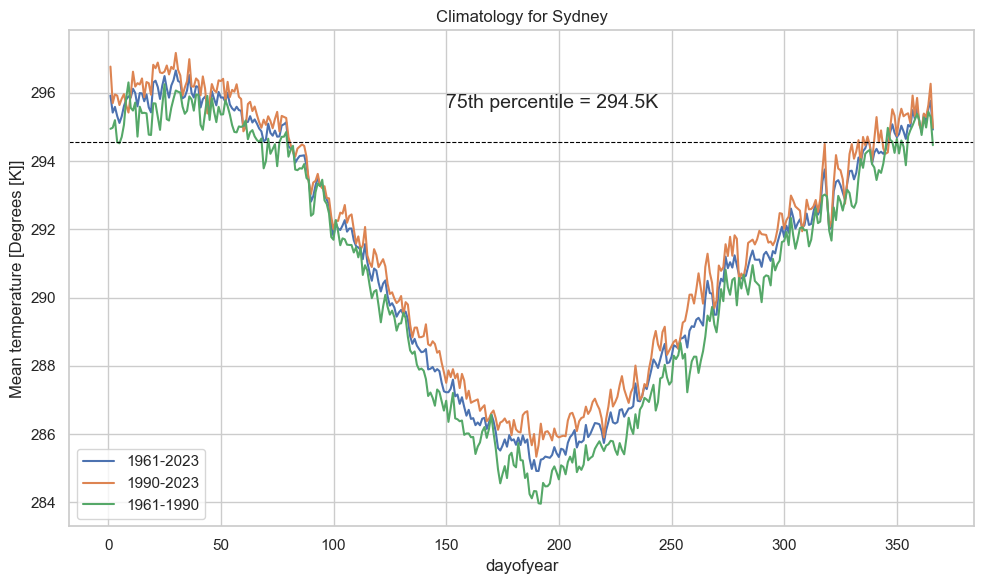

In [127]:
# plot both to compare
plt.figure(figsize=(10,6))
da_daily_clim_full.plot(label='1961-2023')
da_daily_clim_an.plot(label='1990-2023')
da_daily_clim_base.plot(label='1961-1990')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(150,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for Sydney")
plt.tight_layout()
plt.show()

#### shift climatology so it runs from July 1 - Jun 30


In [128]:
# help from https://xarray.pydata.org/en/v2024.10.0/generated/xarray.DataArray.roll.html
clim_full = da_daily_clim_full.roll(dayofyear=183)
clim_an = da_daily_clim_an.roll(dayofyear=183)
clim_base = da_daily_clim_base.roll(dayofyear=183)


In [129]:
da_daily_clim_full_30dayroll = clim_full.rolling(dayofyear=30,center=True, min_periods=2).mean()
da_daily_clim_an_30dayroll = clim_an.rolling(dayofyear=30,center=True, min_periods=2).mean()
da_daily_clim_base_30dayroll = clim_base.rolling(dayofyear=30,center=True, min_periods=2).mean()


#### Climatology plot for paper

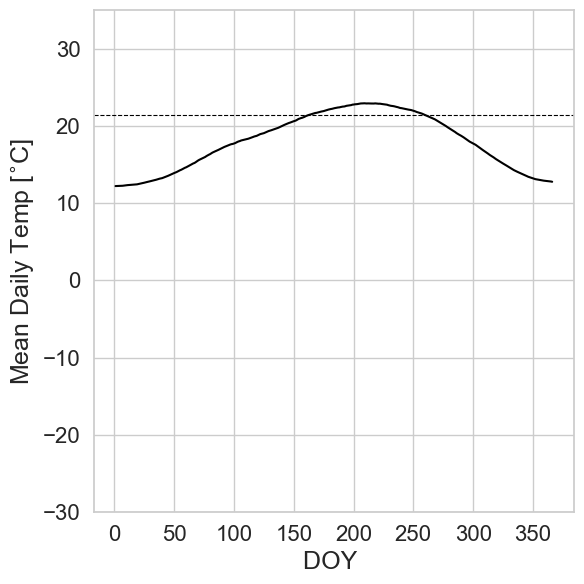

In [130]:

sns.set_theme(context='notebook', style='whitegrid')

plt.figure(figsize=(6,6))
(da_daily_clim_full_30dayroll+KtoC).plot(color="black", label='1961-2023 30D')
#da_daily_clim_an_30dayroll.plot(label='1990-2023 30D')
plt.axhline(stp_75.values+KtoC, color="black", linewidth=0.8, linestyle="dashed")
#plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
#plt.legend()
#plt.title("Climatology for MPLS")


plt.xlabel('DOY ', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.ylim(-30,35)
#plt.title("Minneapolis: 1970 and 2023", fontsize=24)
plt.tight_layout()
#plt.legend()
plt.savefig("./Plots/sydney_1961-2023_climatology.png",bbox_inches='tight')
plt.savefig("./Plots/sydney_1961-2023_climatology.pdf",bbox_inches='tight')

plt.show()

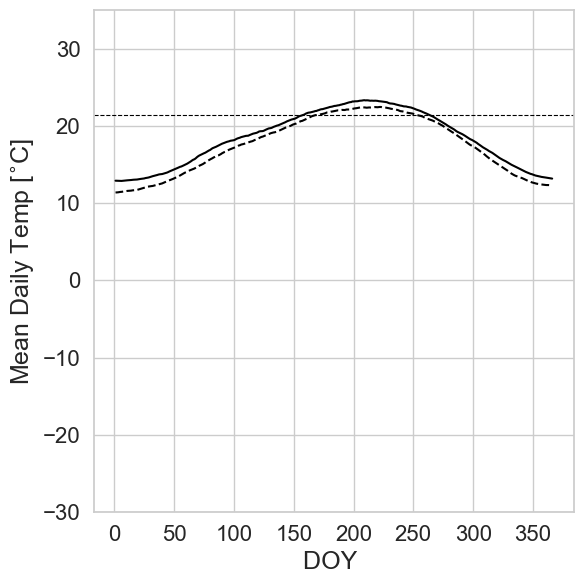

In [131]:

sns.set_theme(context='notebook', style='whitegrid')

plt.figure(figsize=(6,6))
(da_daily_clim_an_30dayroll+KtoC).plot(color="black", label='1990-2023 30D')
(da_daily_clim_base_30dayroll+KtoC).plot(color="black", linestyle='dashed', label='1961-1990 30D')
#da_daily_clim_an_30dayroll.plot(label='1990-2023 30D')
plt.axhline(stp_75.values+KtoC, color="black", linewidth=0.8, linestyle="dashed")
#plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
#plt.legend()
#plt.title("Climatology for MPLS")


plt.xlabel('DOY ', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.ylim(-30,35)
#plt.title("Minneapolis: 1970 and 2023", fontsize=24)
plt.tight_layout()
#plt.legend()
plt.savefig("./Plots/sydney_1961-1990_1990-2023_climatology.png",bbox_inches='tight')
plt.savefig("./Plots/sydney_1961-1990_1990-2023_climatology.pdf",bbox_inches='tight')

plt.show()

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats

In [381]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [382]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the SH we need a next year
    da_next = da_stp.sel(time=str(input_year+1))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, False)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[grad_start],
                        "EndGrad":[grad_end],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 333 ms, sys: 11.7 ms, total: 345 ms
Wall time: 367 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,198,247,0.042298,-0.064160,50,50.50,222,294.970000
1,1962,181,254,0.050942,-0.047475,74,89.70,236,295.241892
2,1963,173,253,0.055165,-0.070084,81,114.55,178,295.439506
3,1964,227,247,0.015545,-0.023384,21,33.90,246,296.007143
4,1965,200,242,0.026294,-0.036864,43,37.20,213,294.359302
5,1966,174,231,0.045529,-0.042584,58,63.40,205,294.981034
6,1967,196,273,0.052887,-0.108125,78,125.55,216,295.699359
7,1968,175,256,0.033751,-0.058266,82,103.40,192,295.181707
8,1969,175,252,0.050706,-0.064803,78,88.95,195,295.244231
9,1970,176,259,0.053980,-0.080940,84,104.40,212,295.270833


### write out resulting summer stats

In [383]:
# write out results
output_path = "../../../Data/GHCND/sydney-australia_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [95]:
# re-load 
input_path = "../../../Data/GHCND/sydney-australia_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,198,247,0.042298,-0.064160,50,50.50,222,294.970000
1,1,1962,181,254,0.050942,-0.047475,74,89.70,236,295.241892
2,2,1963,173,253,0.055165,-0.070084,81,114.55,178,295.439506
3,3,1964,227,247,0.015545,-0.023384,21,33.90,246,296.007143
4,4,1965,200,242,0.026294,-0.036864,43,37.20,213,294.359302
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,141,261,0.058981,-0.089370,121,223.15,207,295.985950
59,59,2020,151,259,0.044131,-0.064706,109,159.95,210,295.515596
60,60,2021,167,259,0.078854,-0.061552,93,161.30,216,296.009140
61,61,2022,187,270,0.073065,-0.130883,84,170.10,259,296.292857


#### get mean Summer temps for 1970-1975 and 2018-2023

In [385]:
mt_7075 = df_summ.query("Year >= 1965 & Year <= 1970")['SummerTavg'].mean()
mt_1823 = df_summ.query("Year >= 2018 & Year <= 2023")['SummerTavg'].mean()
print(mt_7075, mt_1823, mt_1823 - mt_7075)

295.1227445337227 296.11179472894713 0.9890501952244222


### Sydney: Plot the summer stats

In [386]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

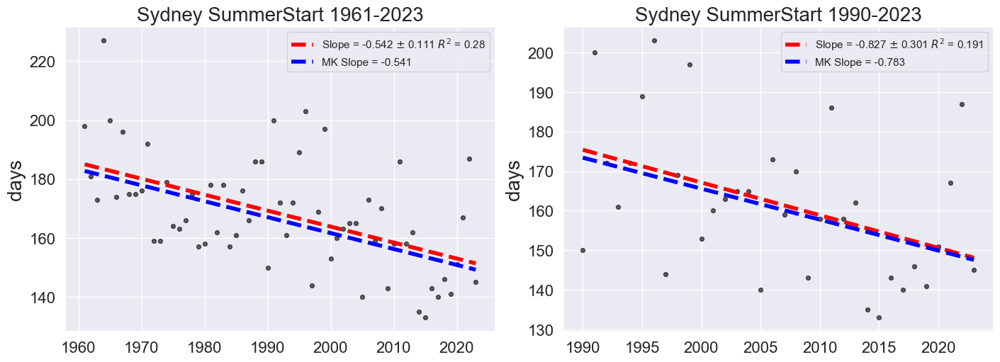

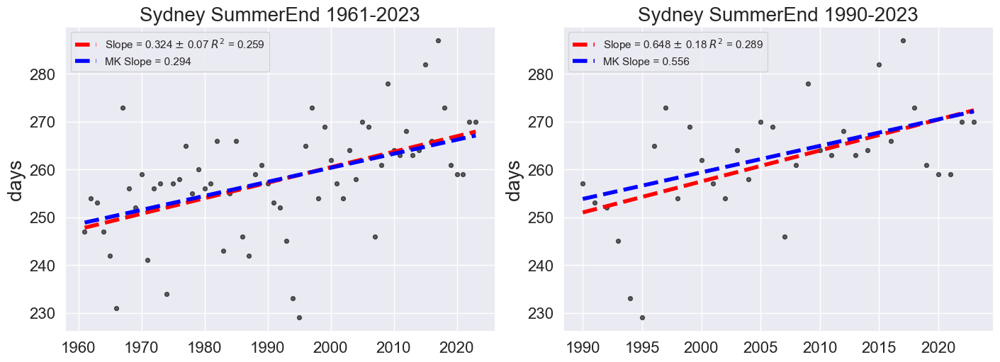

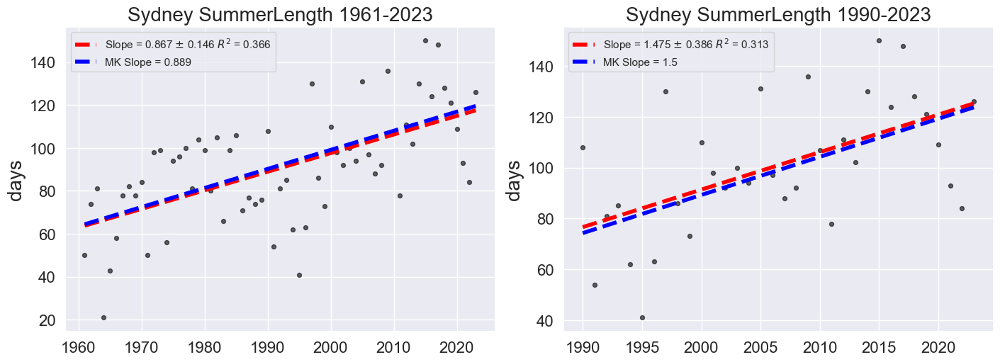

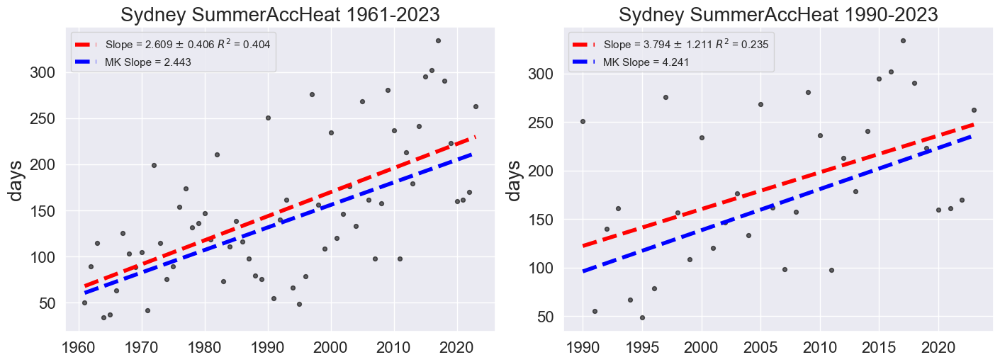

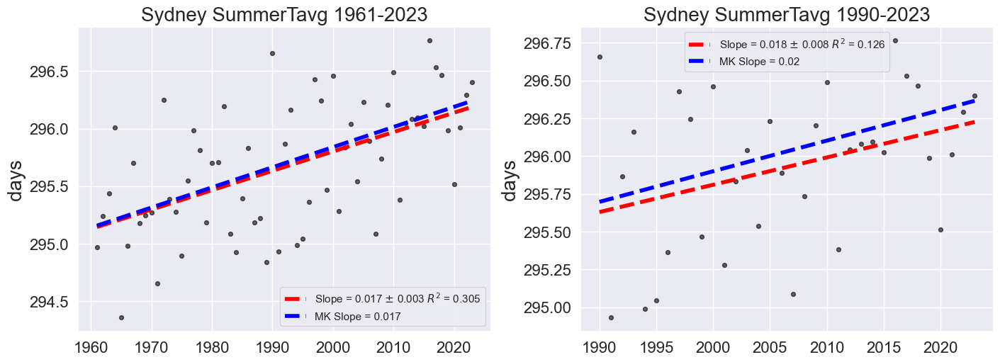

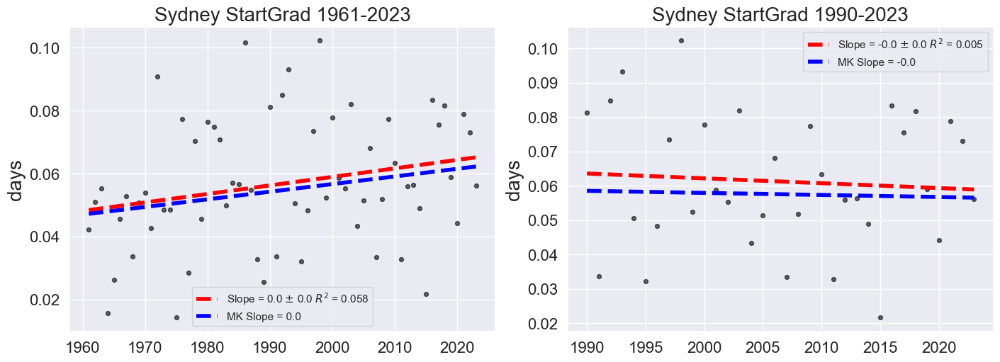

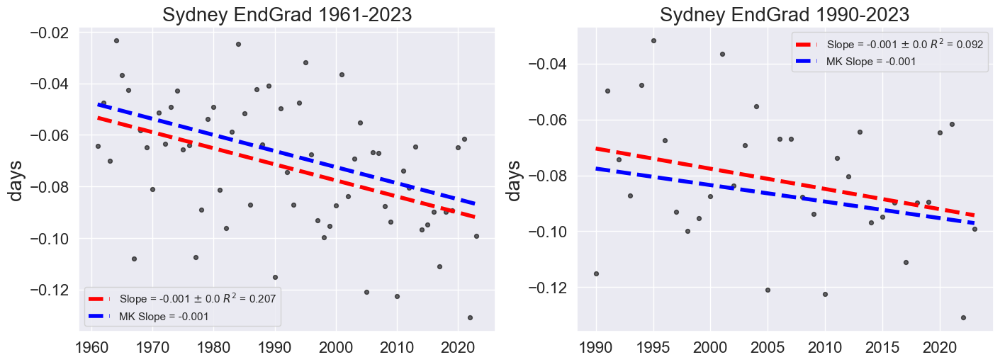

In [98]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Sydney "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Sydney "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

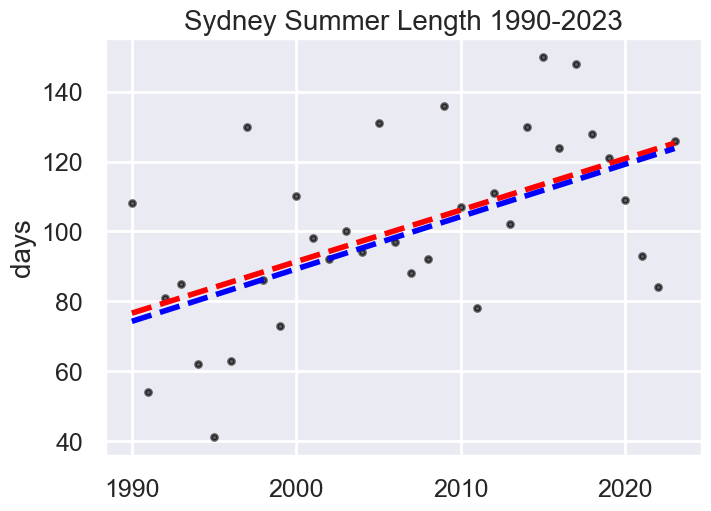

In [99]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Sydney Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/sydney_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [96]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -34.0
    lon      float64 8B 151.2
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -34.0
    lon      float64 8B 151.2
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 14.75 +/- 3.8600000000000003
OLS Slope ERA5: 11.0 +/- 3.09


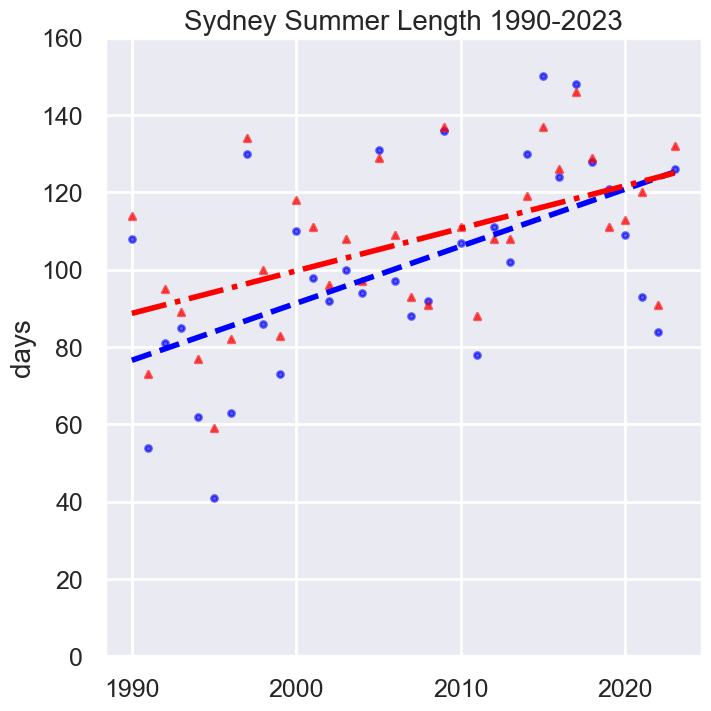

In [97]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,7), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Sydney Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(0,160)
plt.savefig("../../../Data/GHCND/Plots/sydney_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/sydney_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [98]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.313
Model:                            OLS   Adj. R-squared:                  0.292
Method:                 Least Squares   F-statistic:                     14.58
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           0.000582
Time:                        10:43:53   Log-Likelihood:                -152.47
No. Observations:                  34   AIC:                             308.9
Df Residuals:                      32   BIC:                             312.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2859.2978    775.316     -3.688      0.0

In [99]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.284
Model:                            OLS   Adj. R-squared:                  0.262
Method:                 Least Squares   F-statistic:                     12.70
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00117
Time:                        10:43:55   Log-Likelihood:                -144.84
No. Observations:                  34   AIC:                             293.7
Df Residuals:                      32   BIC:                             296.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2101.0341    619.528     -3.391      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: 37.94 +/- 12.110000000000001
OLS Slope ERA5: 28.0 +/- 10.14


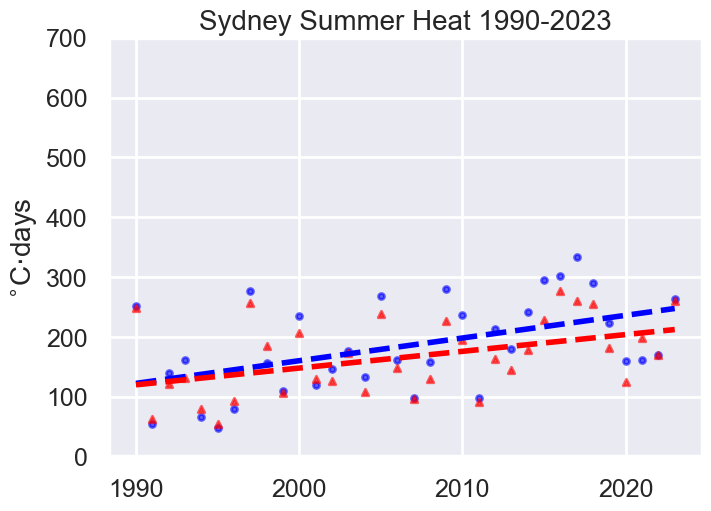

In [100]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Sydney Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/sydney_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/sydney_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [101]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.235
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     9.814
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00369
Time:                        10:44:07   Log-Likelihood:                -191.31
No. Observations:                  34   AIC:                             386.6
Df Residuals:                      32   BIC:                             389.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7428.1811   2430.219     -3.057      0.0

In [102]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.192
Model:                            OLS   Adj. R-squared:                  0.167
Method:                 Least Squares   F-statistic:                     7.626
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00945
Time:                        10:44:09   Log-Likelihood:                -185.27
No. Observations:                  34   AIC:                             374.5
Df Residuals:                      32   BIC:                             377.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -5452.5690   2034.605     -2.680      0.0

#### End Gradient with ERA5 data

In [127]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -34.0
    lon      float64 8B 151.2
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B -34.0
    lon      float64 8B 151.2
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.007200000000000001 +/- 0.004
OLS Slope ERA5: -0.007200000000000001 +/- 0.0025


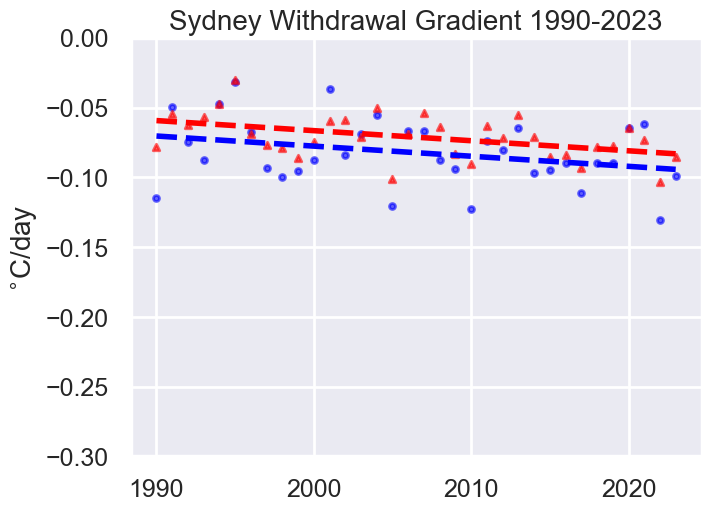

In [128]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Sydney Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/sydney_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/sydney_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: -0.0013999999999999998 +/- 0.0035
OLS Slope ERA5: -0.0013999999999999998 +/- 0.0026


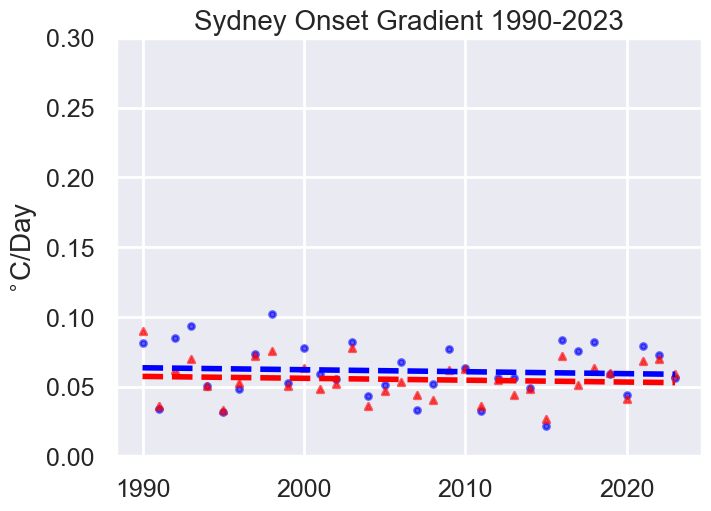

In [129]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Sydney Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/Day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/sydney_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/sydney_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

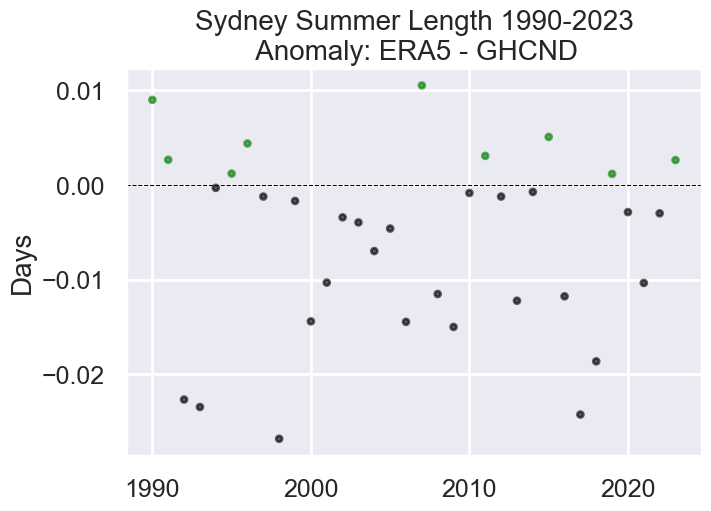

In [395]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Sydney Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

## **Tokyo, Japan ** has complete data

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:JA000047662/detail

In [103]:
df = pd.read_csv("../../../Data/GHCND/tokyo-2025-04-10T16-54-09.csv")
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,JA000047662,"TOKYO, JA",35.683,139.767,36.0,1961-01-01,1.8,7.9,-3.9
1,JA000047662,"TOKYO, JA",35.683,139.767,36.0,1961-01-02,1.7,9.2,-3.3
2,JA000047662,"TOKYO, JA",35.683,139.767,36.0,1961-01-03,3.8,7.3,-2.4
3,JA000047662,"TOKYO, JA",35.683,139.767,36.0,1961-01-04,4.5,11.5,0.6
4,JA000047662,"TOKYO, JA",35.683,139.767,36.0,1961-01-05,3.5,7.7,1.4
...,...,...,...,...,...,...,...,...,...
22635,JA000047662,"TOKYO, JA",35.683,139.767,36.0,2023-12-27,8.4,NaN,4.3
22636,JA000047662,"TOKYO, JA",35.683,139.767,36.0,2023-12-28,6.2,NaN,NaN
22637,JA000047662,"TOKYO, JA",35.683,139.767,36.0,2023-12-29,8.7,NaN,2.2
22638,JA000047662,"TOKYO, JA",35.683,139.767,36.0,2023-12-30,9.2,NaN,4.4


In [133]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22640 entries, 0 to 22639
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    22640 non-null  object 
 1   NAME       22640 non-null  object 
 2   LATITUDE   22640 non-null  float64
 3   LONGITUDE  22640 non-null  float64
 4   ELEVATION  22640 non-null  float64
 5   DATE       22640 non-null  object 
 6   TAVG       22573 non-null  float64
 7   TMAX       20068 non-null  float64
 8   TMIN       17511 non-null  float64
dtypes: float64(6), object(3)
memory usage: 1.6+ MB


### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [168]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,JA000047662,"TOKYO, JA",35.683,139.767,36.0,1961-01-01,1.8,7.9,-3.9
1,JA000047662,"TOKYO, JA",35.683,139.767,36.0,1961-01-02,1.7,9.2,-3.3
2,JA000047662,"TOKYO, JA",35.683,139.767,36.0,1961-01-03,3.8,7.3,-2.4
3,JA000047662,"TOKYO, JA",35.683,139.767,36.0,1961-01-04,4.5,11.5,0.6
4,JA000047662,"TOKYO, JA",35.683,139.767,36.0,1961-01-05,3.5,7.7,1.4
...,...,...,...,...,...,...,...,...,...
22635,JA000047662,"TOKYO, JA",35.683,139.767,36.0,2023-12-27,8.4,NaN,4.3
22636,JA000047662,"TOKYO, JA",35.683,139.767,36.0,2023-12-28,6.2,NaN,NaN
22637,JA000047662,"TOKYO, JA",35.683,139.767,36.0,2023-12-29,8.7,NaN,2.2
22638,JA000047662,"TOKYO, JA",35.683,139.767,36.0,2023-12-30,9.2,NaN,4.4


In [144]:
# check counts again
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22640 entries, 0 to 22639
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    22640 non-null  object 
 1   NAME       22640 non-null  object 
 2   LATITUDE   22640 non-null  float64
 3   LONGITUDE  22640 non-null  float64
 4   ELEVATION  22640 non-null  float64
 5   DATE       22640 non-null  object 
 6   TAVG       22640 non-null  float64
 7   TMAX       20068 non-null  float64
 8   TMIN       17511 non-null  float64
dtypes: float64(6), object(3)
memory usage: 1.6+ MB


In [169]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,274.95
1961-01-02,274.85
1961-01-03,276.95
1961-01-04,277.65
1961-01-05,276.65
...,...
2023-12-27,281.55
2023-12-28,279.35
2023-12-29,281.85


In [170]:
df['DATE'].dt.year.unique()

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016,
       2017, 2018, 2019, 2020, 2021, 2022, 2023], dtype=int32)

### Convert from Pandas to XArray

In [171]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 362kB
Dimensions:  (time: 22640)
Coordinates:
  * time     (time) datetime64[ns] 181kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 181kB 274.9 274.8 276.9 277.6 ... 281.8 282.3 283.2

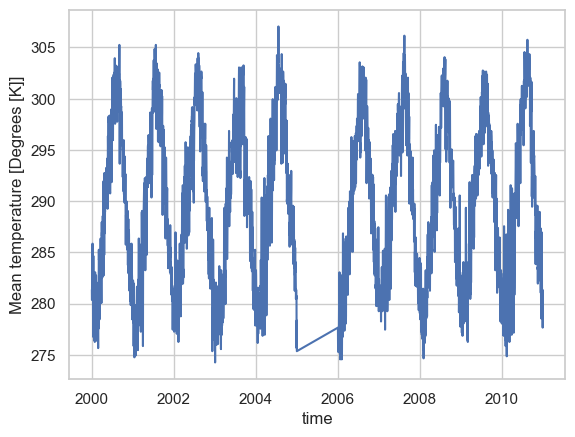

In [172]:
da_stp.tavg.sel(time=slice('2000','2010')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [173]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(295.010468)
Coordinates:
    lat       float64 8B 35.75
    lon       float64 8B 139.8
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [174]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 3.18 ms, sys: 1.5 ms, total: 4.68 ms
Wall time: 3.27 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(295.75)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [195]:
thresh.values - stp_75.values

np.float64(-0.739532470703125)

#### Tokyo 75th Percentile from GHCND data is 0.74 K warmer

### Try one year (2023) fit via Fourier

In [18]:
da_stp.tavg.values[0]

np.float64(274.95)

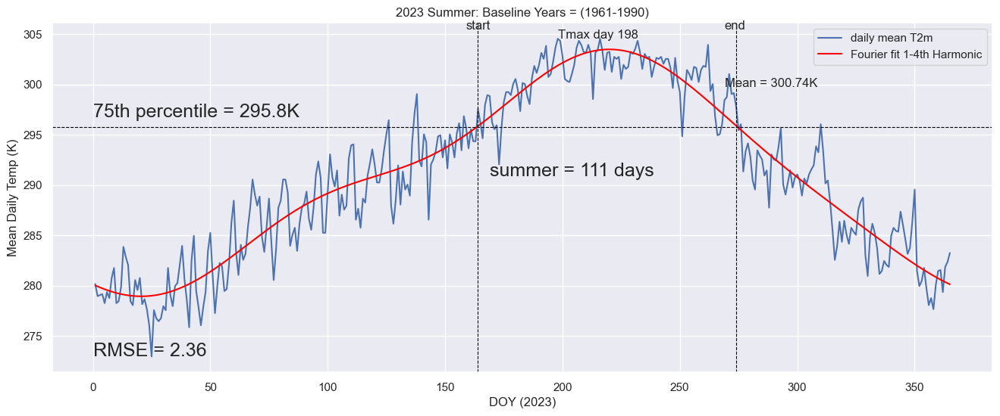

(164,
 274,
 0.17694256264238106,
 -0.20676766256082146,
 198,
 561.7999999999993,
 111,
 2.361651283074961,
 0.0,
 300.74099099099095,
 5.454368932038847)

In [196]:
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

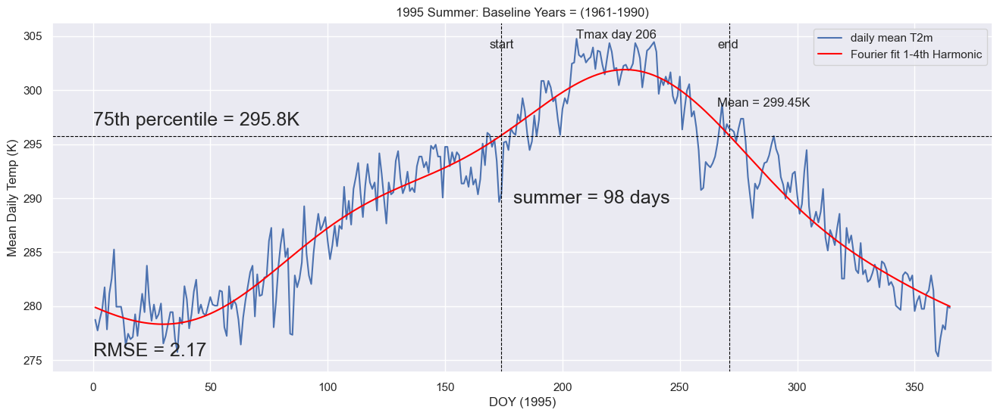

(174,
 271,
 0.14942367697918257,
 -0.2328980385126158,
 206,
 391.2999999999993,
 98,
 2.165464634587969,
 0.0,
 299.4530612244898,
 4.658333333333303)

In [20]:
# how about 1995
input_year = 1995

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Looks to be working!

In [ ]:
#sns.set_theme(context='notebook', style='whitegrid')

### Make plot of 1970 and 2023 time series and fits for paper - they have similar shapes

Threshold in C: 22.600000000000023


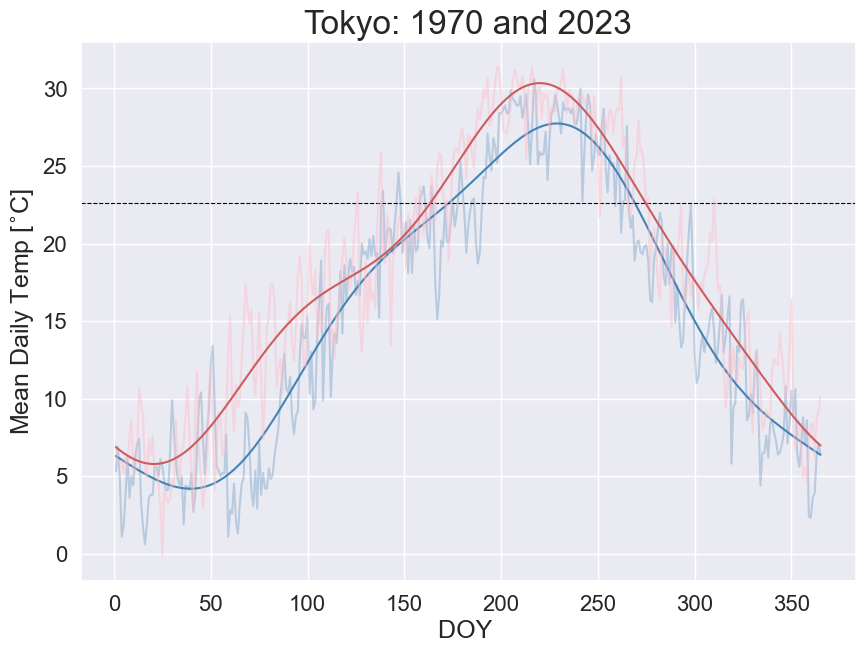

In [197]:
# have to essentially do the fourier fit process twice and put both on the figure



### 1970
input_year = 1970
da = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
thresh = stp_75


# DOY and T2m values for those days
x1 = np.arange(1,len(da.time)+1) 
y1 = da.tavg.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean = np.mean(y1)
y_norm = y1 - ymean
# perform DFT of temp data
coef = fft(y_norm)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp = np.copy(coef)
Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp = np.real(np.fft.ifft(Z_lp))

# add back in the original mean temp
y_lp = y_norm_lp + ymean

# create some x values for plotting polynomial fit
x_values = np.linspace(min(x1), max(x1), 365) 


### 2023
input_year = 2023
da = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
thresh = stp_75

# DOY and T2m values for those days
x2 = np.arange(1,len(da.time)+1) 
y2 = da.tavg.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean2 = np.mean(y2)
y_norm2 = y2 - ymean2
# perform DFT of temp data
coef2 = fft(y_norm2)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp2 = np.copy(coef2)
Z_lp2[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp2 = np.real(np.fft.ifft(Z_lp2))

# add back in the original mean temp
y_lp2 = y_norm_lp2 + ymean2

# create some x values for plotting polynomial fit
#x_values = np.linspace(min(x1), max(x1), 365) 
        
# make plot if desired

# convert values to Celsius
y1 = y1 + KtoC
y2 = y2 + KtoC
y_lp2 = y_lp2 + KtoC
y_lp = y_lp + KtoC
thresh = thresh + KtoC
print("Threshold in C: "+str(thresh.values))


plt.figure(figsize=(10,7))
plt.plot(x1,y1, label='T2m 1970', color='steelblue', alpha=0.3)
plt.plot(x_values, y_lp, label='1970 4th Harmonic', color='steelblue')
plt.axhline(thresh.values, color="black", linewidth=0.8, linestyle="dashed") 
# plt.axvline(first_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.axvline(last_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.annotate('start', xy=(first_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('end', xy=(last_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('summer = '+str(summer_length)+' days', xy=(first_day+5,np.mean(y_lp)), fontsize=18)
#plt.annotate('75th percentile = '+str(np.round(thresh.values,1))+'K', xy=(0,thresh.values+1), fontsize=12)
# plt.annotate('RMSE = '+str(np.round(rmse,2)), xy=(0, np.min(y1)), fontsize=18)
# plt.annotate('Mean = '+str(np.round(mean_t,2))+'K', xy=(last_day-5, mean_t-1), fontsize=12)

plt.plot(x1,y2, label='T2m 2023', color='pink', alpha=0.5)
plt.plot(x1, y_lp2, label='2023 4th Harmonic', color='indianred')



# SH days are relative to July 1
plt.xlabel('DOY ', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.title("Tokyo: 1970 and 2023", fontsize=24)
#plt.legend()
plt.savefig("./Plots/tokyo_1970_2023.png",bbox_inches='tight')
plt.savefig("./Plots/tokyo_1970_2023.pdf",bbox_inches='tight')
plt.show()




In [ ]:
sns.reset_defaults()

#### 1961 and 2023 ?

Threshold in C: 22.600000000000023


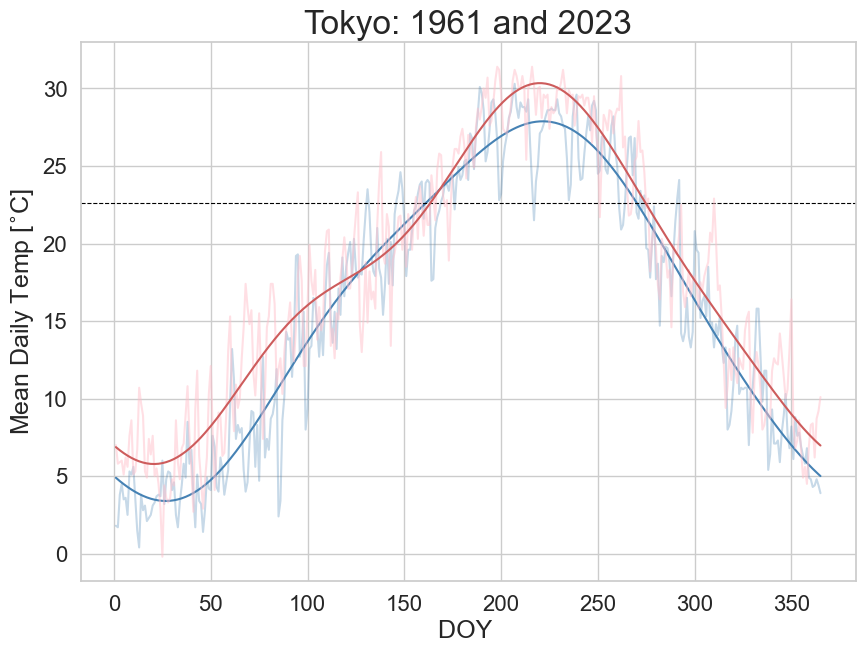

In [175]:
# have to essentially do the fourier fit process twice and put both on the figure



### 1970
input_year = 1961
da = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
thresh = stp_75


# DOY and T2m values for those days
x1 = np.arange(1,len(da.time)+1) 
y1 = da.tavg.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean = np.mean(y1)
y_norm = y1 - ymean
# perform DFT of temp data
coef = fft(y_norm)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp = np.copy(coef)
Z_lp[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp = np.real(np.fft.ifft(Z_lp))

# add back in the original mean temp
y_lp = y_norm_lp + ymean

# create some x values for plotting polynomial fit
x_values = np.linspace(min(x1), max(x1), 365) 


### 2023
input_year = 2023
da = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
thresh = stp_75

# DOY and T2m values for those days
x2 = np.arange(1,len(da.time)+1) 
y2 = da.tavg.values

# Fourier fit, up to 4th harmonic (mean + 3 more) as in Weller et al 2020
ymean2 = np.mean(y2)
y_norm2 = y2 - ymean2
# perform DFT of temp data
coef2 = fft(y_norm2)
# low-pass filter: retain only the mean and the first three harmonics, set all other frequencies to zero
# help from https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week6/filtering_in_freq2.html
Z_lp2 = np.copy(coef2)
Z_lp2[4:-3:] = 0.0  # we have to set both the positive and negative frequencies to zero
# apply inverse fourier transform to convert back to time domain (just want the real part)
y_norm_lp2 = np.real(np.fft.ifft(Z_lp2))

# add back in the original mean temp
y_lp2 = y_norm_lp2 + ymean2

# create some x values for plotting polynomial fit
#x_values = np.linspace(min(x1), max(x1), 365) 
        
# make plot if desired

# convert values to Celsius
y1 = y1 + KtoC
y2 = y2 + KtoC
y_lp2 = y_lp2 + KtoC
y_lp = y_lp + KtoC
thresh = thresh + KtoC
print("Threshold in C: "+str(thresh.values))


plt.figure(figsize=(10,7))
plt.plot(x1,y1, label='T2m 1961', color='steelblue', alpha=0.3)
plt.plot(x_values, y_lp, label='1961 4th Harmonic', color='steelblue')
plt.axhline(thresh.values, color="black", linewidth=0.8, linestyle="dashed") 
# plt.axvline(first_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.axvline(last_day, color="black", linewidth=0.8, linestyle="dashed")
# plt.annotate('start', xy=(first_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('end', xy=(last_day-5,np.max(y_lp)+2), fontsize=12)
# plt.annotate('summer = '+str(summer_length)+' days', xy=(first_day+5,np.mean(y_lp)), fontsize=18)
#plt.annotate('75th percentile = '+str(np.round(thresh.values,1))+'K', xy=(0,thresh.values+1), fontsize=12)
# plt.annotate('RMSE = '+str(np.round(rmse,2)), xy=(0, np.min(y1)), fontsize=18)
# plt.annotate('Mean = '+str(np.round(mean_t,2))+'K', xy=(last_day-5, mean_t-1), fontsize=12)

plt.plot(x1,y2, label='T2m 2023', color='pink', alpha=0.5)
plt.plot(x1, y_lp2, label='2023 4th Harmonic', color='indianred')



# SH days are relative to July 1
plt.xlabel('DOY ', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.title("Tokyo: 1961 and 2023", fontsize=24)
#plt.legend()
plt.savefig("./Plots/tokyo_1961_2023.png",bbox_inches='tight')
plt.savefig("./Plots/tokyo_1961_2023.pdf",bbox_inches='tight')
plt.show()




### Climatology plots, 1961-2023 and 1990-2023

In [141]:
da_daily_clim_full = da_stp.tavg.groupby("time.dayofyear").mean()
da_daily_clim_an = da_stp.tavg.sel(time=slice('1990','2023')).groupby("time.dayofyear").mean()
da_daily_clim_base = da_stp.tavg.sel(time=slice('1961','1990')).groupby("time.dayofyear").mean()
da_daily_clim_full, da_daily_clim_an, da_daily_clim_base


#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()

(<xarray.DataArray 'tavg' (dayofyear: 366)> Size: 3kB
 array([279.20645161, 279.0483871 , 278.90967742, 279.11129032,
        278.98548387, 278.76774194, 278.96129032, 279.12419355,
        279.26451613, 279.25491803, 278.96129032, 278.74516129,
        279.18387097, 278.86129032, 278.38709677, 278.39032258,
        278.66290323, 278.60241935, 278.5233871 , 278.80806452,
        278.32741935, 278.67258065, 278.70322581, 278.36129032,
        278.43548387, 278.59032258, 278.95967742, 278.72096774,
        278.71935484, 278.83387097, 278.55967742, 278.67419355,
        278.59193548, 278.62741935, 278.58709677, 278.69354839,
        278.93548387, 279.32258065, 278.88870968, 278.82177419,
        278.92983871, 278.92622951, 279.20409836, 279.59354839,
        280.01290323, 279.3483871 , 279.38790323, 278.96290323,
        279.22580645, 279.65806452, 280.06147541, 279.89516129,
        280.45967742, 280.13870968, 279.31048387, 279.58951613,
        279.87741935, 280.3       , 280.96451613, 

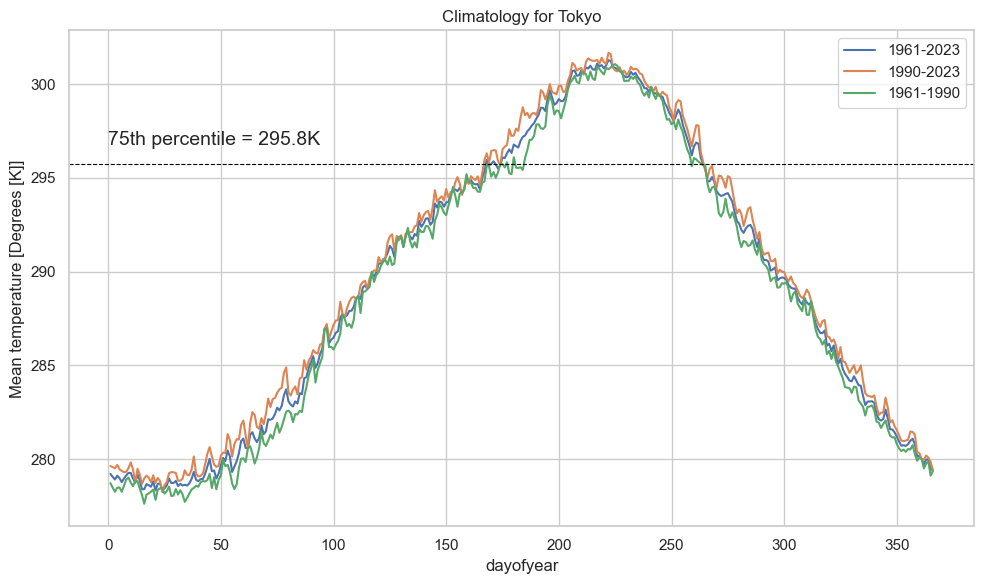

In [142]:
# plot both to compare
plt.figure(figsize=(10,6))
da_daily_clim_full.plot(label='1961-2023')
da_daily_clim_an.plot(label='1990-2023')
da_daily_clim_base.plot(label='1961-1990')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for Tokyo")
plt.tight_layout()
plt.show()

In [143]:
# get 30D rolling clim
da_daily_clim_full_30dayroll = da_daily_clim_full.rolling(dayofyear=30,center=True, min_periods=2).mean()
da_daily_clim_base_30dayroll = da_daily_clim_base.rolling(dayofyear=30,center=True, min_periods=2).mean()
da_daily_clim_an_30dayroll = da_daily_clim_an.rolling(dayofyear=30,center=True, min_periods=2).mean()
#da_daily_clim_full_30dayroll

#### Climatology plot for paper

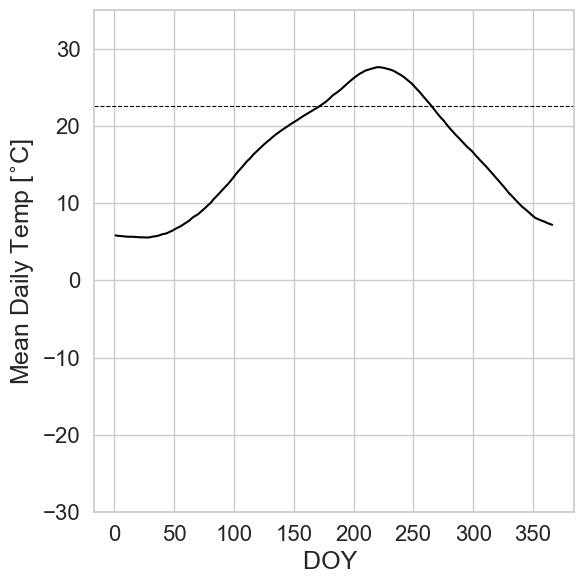

In [144]:

sns.set_theme(context='notebook', style='whitegrid')

plt.figure(figsize=(6,6))
(da_daily_clim_full_30dayroll+KtoC).plot(color="black", label='1961-2023 30D')
#da_daily_clim_an_30dayroll.plot(label='1990-2023 30D')
plt.axhline(stp_75.values+KtoC, color="black", linewidth=0.8, linestyle="dashed")
#plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
#plt.legend()
#plt.title("Climatology for MPLS")


plt.xlabel('DOY ', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.ylim(-30,35)
#plt.title("Minneapolis: 1970 and 2023", fontsize=24)
plt.tight_layout()
#plt.legend()
plt.savefig("./Plots/tokyo_1961-2023_climatology.png",bbox_inches='tight')
plt.savefig("./Plots/tokyo_1961-2023_climatology.pdf",bbox_inches='tight')

plt.show()

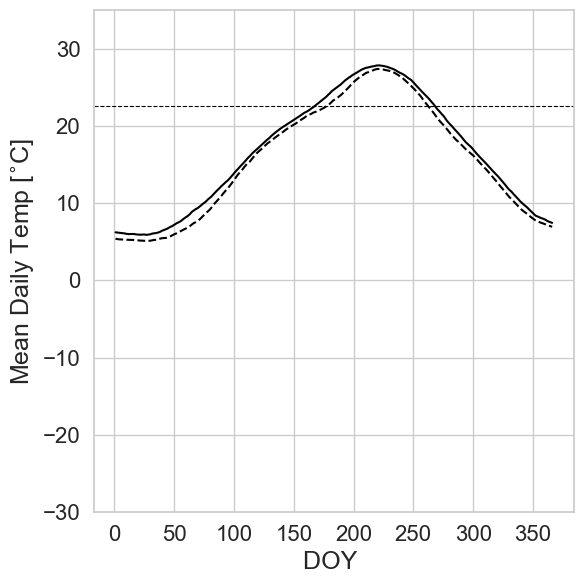

In [145]:

sns.set_theme(context='notebook', style='whitegrid')

plt.figure(figsize=(6,6))
(da_daily_clim_an_30dayroll+KtoC).plot(color="black", label='1990-2023 30D')
(da_daily_clim_base_30dayroll+KtoC).plot(color="black", linestyle='dashed', label='1961-1990 30D')
#da_daily_clim_an_30dayroll.plot(label='1990-2023 30D')
plt.axhline(stp_75.values+KtoC, color="black", linewidth=0.8, linestyle="dashed")
#plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
#plt.legend()
#plt.title("Climatology for MPLS")


plt.xlabel('DOY ', fontsize=18)

plt.ylabel('Mean Daily Temp [$^{\circ}$C]', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.ylim(-30,35)
#plt.title("Minneapolis: 1970 and 2023", fontsize=24)
plt.tight_layout()
#plt.legend()
plt.savefig("./Plots/tokyo_1961-1990_1990-2023_climatology.png",bbox_inches='tight')
plt.savefig("./Plots/tokyo_1961-1990_1990-2023_climatology.pdf",bbox_inches='tight')

plt.show()

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats. For Tokyo, 2005 is missing

In [411]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2005,1)
process_yrs2 = np.arange(2006,2024,1)

process_yrs = np.append(process_yrs, process_yrs2)
process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016,
       2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [412]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 288 ms, sys: 13.7 ms, total: 302 ms
Wall time: 326 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,161,270,0.121906,-0.196060,110,386.80,207,299.090000
1,1962,179,268,0.136752,-0.251181,90,339.50,221,299.247778
2,1963,170,253,0.155934,-0.195066,84,277.80,207,298.939286
3,1964,176,260,0.137114,-0.256443,85,297.00,213,299.131176
4,1965,172,260,0.138056,-0.151595,89,247.45,219,298.223596
5,1966,178,269,0.145528,-0.175530,92,283.50,224,298.346739
6,1967,160,262,0.132026,-0.199513,103,364.75,223,299.151456
7,1968,175,255,0.157361,-0.189685,81,225.60,220,298.278395
8,1969,171,265,0.102353,-0.205470,95,312.40,211,298.692105
9,1970,173,269,0.109237,-0.236005,97,338.70,217,298.927320


### write out resulting summer stats

In [413]:
# write out results
output_path = "../../../Data/GHCND/tokyo_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [104]:
# re-load 
input_path = "../../../Data/GHCND/tokyo_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,161,270,0.121906,-0.196060,110,386.80,207,299.090000
1,1,1962,179,268,0.136752,-0.251181,90,339.50,221,299.247778
2,2,1963,170,253,0.155934,-0.195066,84,277.80,207,298.939286
3,3,1964,176,260,0.137114,-0.256443,85,297.00,213,299.131176
4,4,1965,172,260,0.138056,-0.151595,89,247.45,219,298.223596
...,...,...,...,...,...,...,...,...,...,...
57,57,2019,174,275,0.106887,-0.218994,102,342.30,229,298.763725
58,58,2020,167,269,0.126148,-0.203632,103,349.70,223,298.727670
59,59,2021,163,261,0.136669,-0.146102,99,287.40,219,298.229798
60,60,2022,164,263,0.171839,-0.188188,100,417.40,214,299.734000


#### get mean Summer temps for 1970-1975 and 2018-2023

In [415]:
mt_7075 = df_summ.query("Year >= 1965 & Year <= 1970")['SummerTavg'].mean()
mt_1823 = df_summ.query("Year >= 2018 & Year <= 2023")['SummerTavg'].mean()
print(mt_7075, mt_1823, mt_1823 - mt_7075)

298.60326847654125 299.26908353259677 0.6658150560555214


### Tokyo: Plot the summer stats

In [416]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

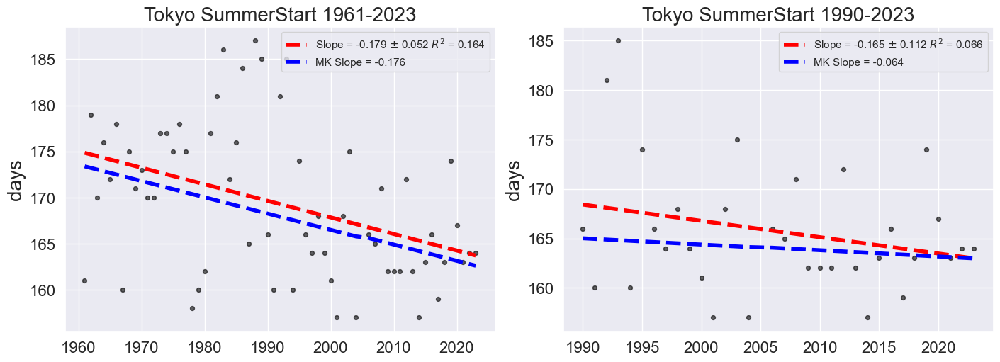

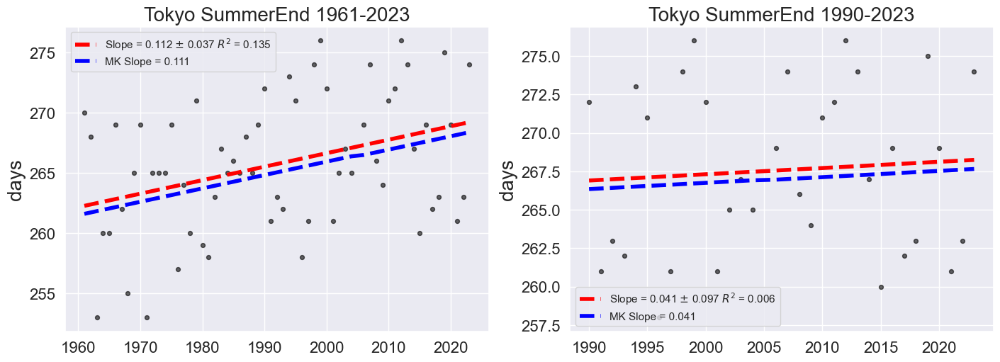

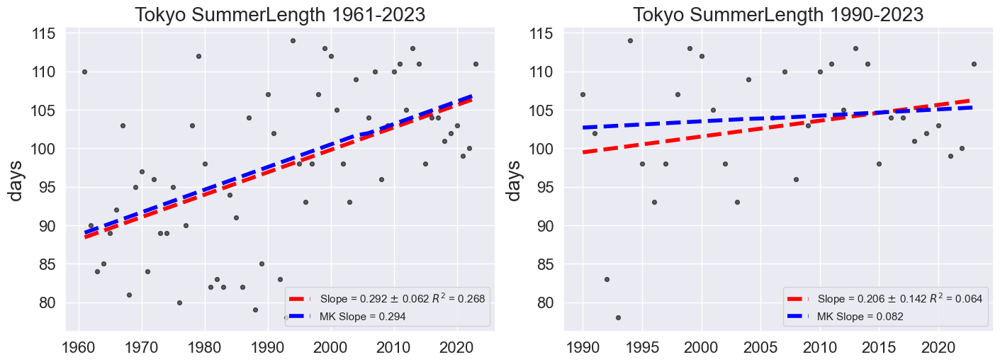

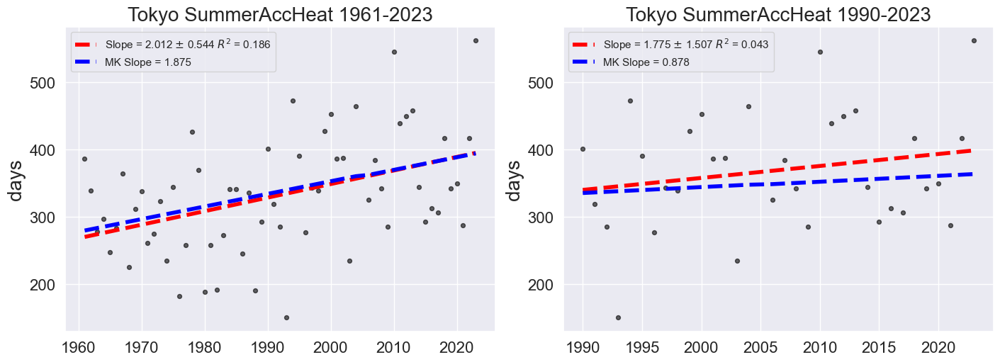

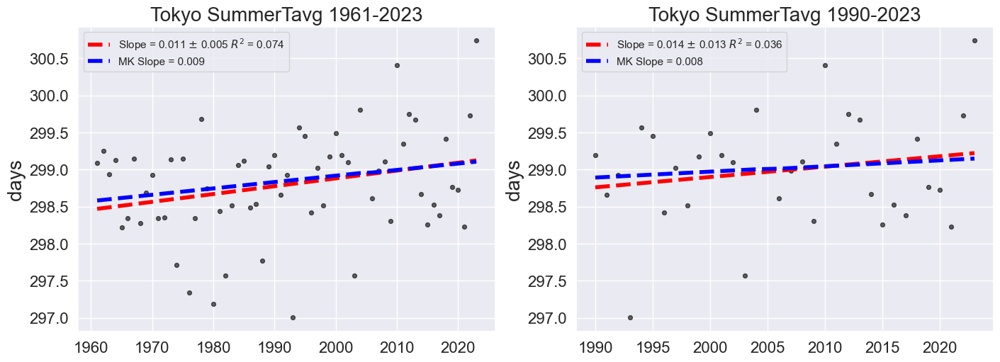

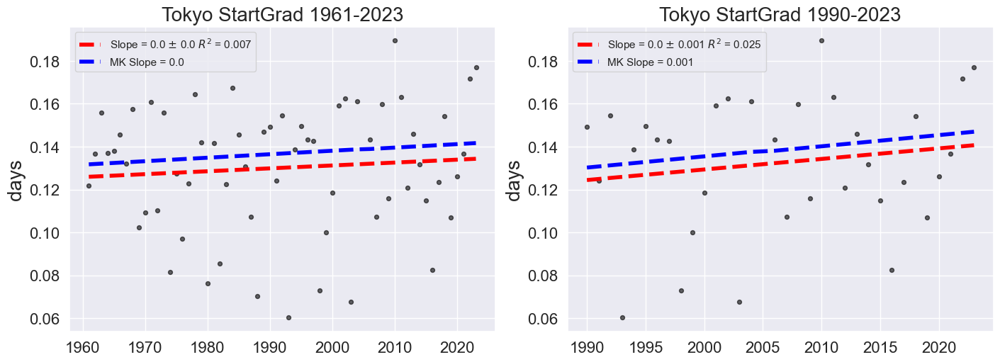

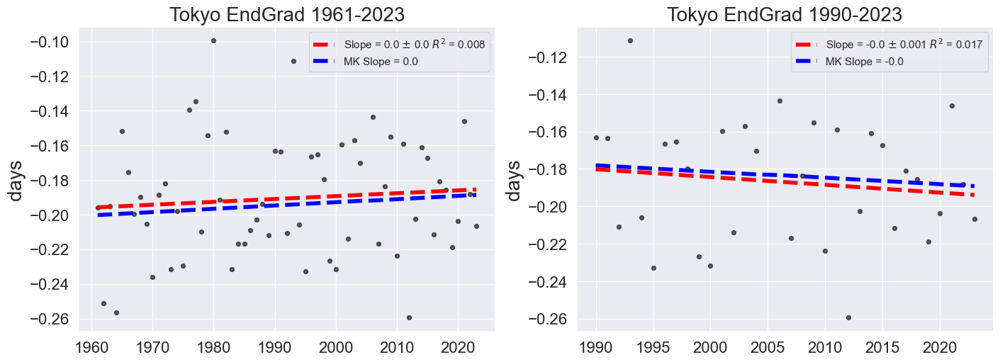

In [104]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Tokyo "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Tokyo "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

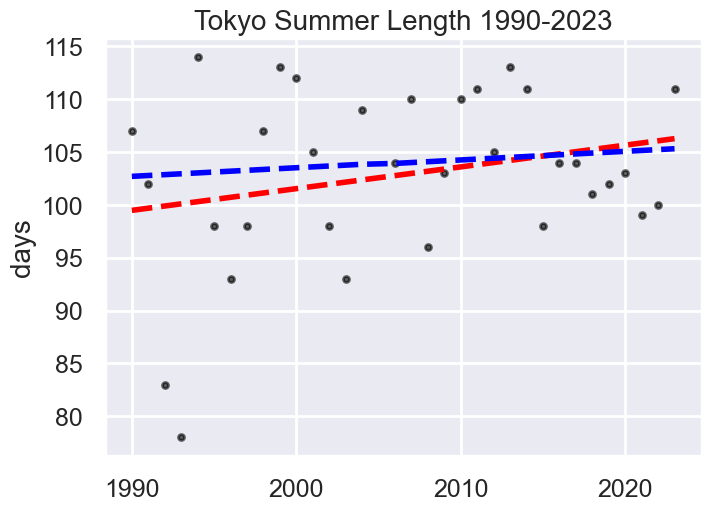

In [105]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Tokyo Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/tokyo_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [105]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 35.75
    lon      float64 8B 139.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 35.75
    lon      float64 8B 139.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 2.06 +/- 1.42
OLS Slope ERA5: 4.699999999999999 +/- 1.2


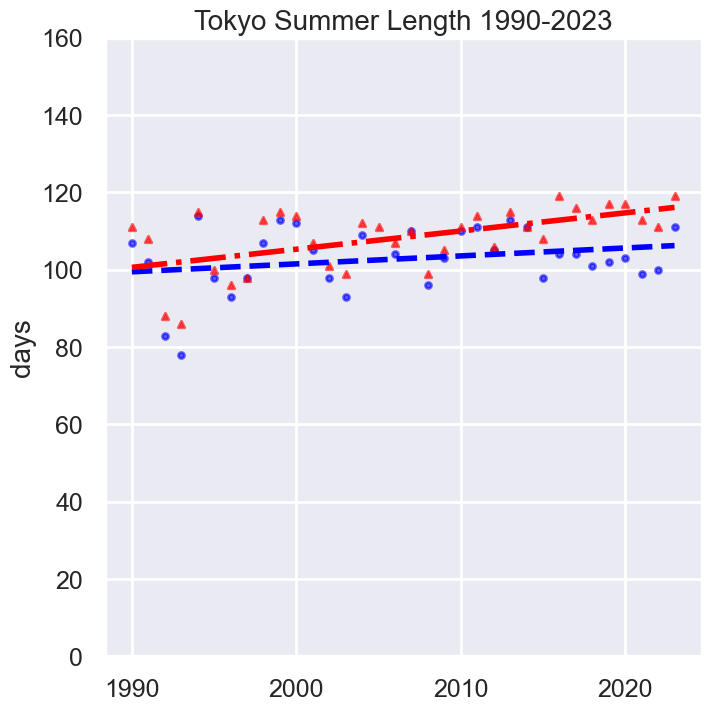

In [106]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,7), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Tokyo Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(0,160)
plt.savefig("../../../Data/GHCND/Plots/tokyo_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/tokyo_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [107]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.064
Model:                            OLS   Adj. R-squared:                  0.033
Method:                 Least Squares   F-statistic:                     2.102
Date:                Wed, 11 Feb 2026   Prob (F-statistic):              0.157
Time:                        10:45:28   Log-Likelihood:                -114.85
No. Observations:                  33   AIC:                             233.7
Df Residuals:                      31   BIC:                             236.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -309.5641    284.459     -1.088      0.2

In [108]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.323
Model:                            OLS   Adj. R-squared:                  0.302
Method:                 Least Squares   F-statistic:                     15.26
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           0.000455
Time:                        10:45:31   Log-Likelihood:                -112.81
No. Observations:                  34   AIC:                             229.6
Df Residuals:                      32   BIC:                             232.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -834.9332    241.482     -3.458      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: 17.75 +/- 15.069999999999999
OLS Slope ERA5: 40.339999999999996 +/- 14.850000000000001


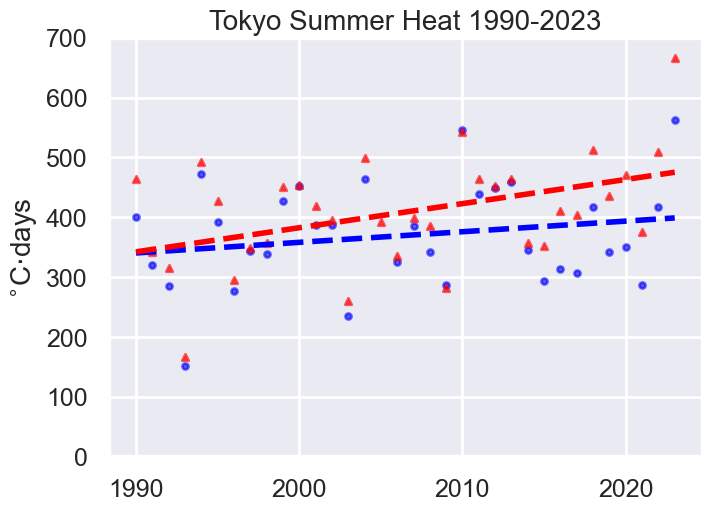

In [109]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Tokyo Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/tokyo_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/tokyo_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [110]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.043
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     1.388
Date:                Wed, 11 Feb 2026   Prob (F-statistic):              0.248
Time:                        10:45:50   Log-Likelihood:                -192.85
No. Observations:                  33   AIC:                             389.7
Df Residuals:                      31   BIC:                             392.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -3192.7612   3023.752     -1.056      0.2

In [111]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.187
Model:                            OLS   Adj. R-squared:                  0.162
Method:                 Least Squares   F-statistic:                     7.373
Date:                Wed, 11 Feb 2026   Prob (F-statistic):             0.0106
Time:                        10:45:52   Log-Likelihood:                -198.25
No. Observations:                  34   AIC:                             400.5
Df Residuals:                      32   BIC:                             403.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7684.7194   2980.654     -2.578      0.0

#### End Gradient with ERA5 data

In [137]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 35.75
    lon      float64 8B 139.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 35.75
    lon      float64 8B 139.8
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.004200000000000001 +/- 0.0057
OLS Slope ERA5: -0.0068000000000000005 +/- 0.005


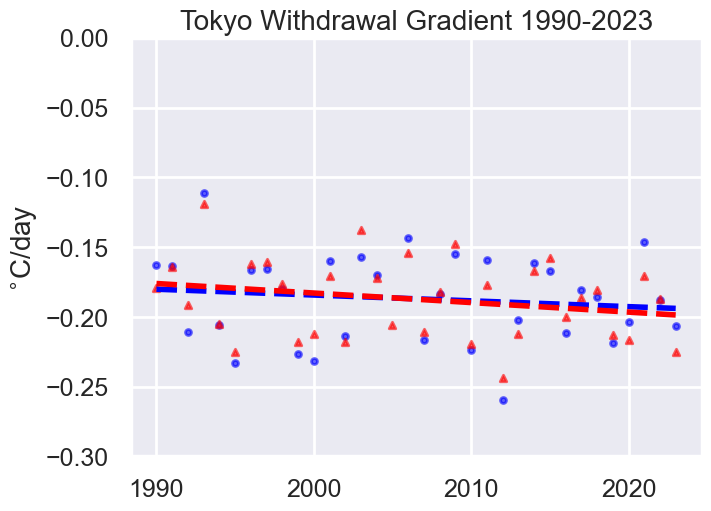

In [139]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Tokyo Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/tokyo_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/tokyo_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: 0.0049 +/- 0.0055000000000000005
OLS Slope ERA5: 0.0033 +/- 0.0038000000000000004


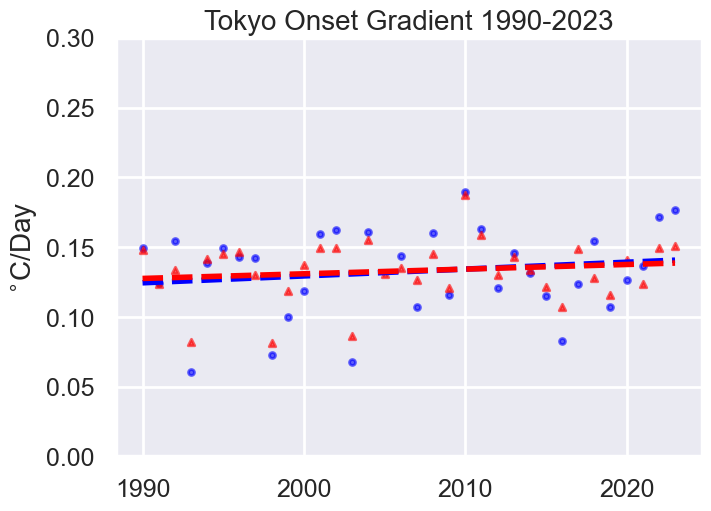

In [140]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Tokyo Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/Day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/tokyo_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/tokyo_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



In [436]:
x_era,y_era,len(y_era),len(y),x_era[0:15]

(array([1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000,
        2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011,
        2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022,
        2023]),
 array([0.14776611, 0.12347412, 0.1335144 , 0.08226013, 0.14151001,
        0.14529419, 0.14682007, 0.13037109, 0.08111572, 0.11843872,
        0.13713074, 0.14936829, 0.14915466, 0.08622742, 0.15525818,
        0.13076782, 0.13491821, 0.12680054, 0.14485168, 0.12081909,
        0.18714905, 0.15895081, 0.13005066, 0.14328003, 0.13394165,
        0.12123108, 0.10691833, 0.14860535, 0.12771606, 0.11567688,
        0.14093018, 0.12364197, 0.14920044, 0.15106201]),
 34,
 33,
 array([1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000,
        2001, 2002, 2003, 2004]))

In [437]:
# have to drop 2005 from ERA5 data since it doesn't exist in the GHCND data
temp=np.append(y_era[0:15],y_era[16:])
temp

array([0.14776611, 0.12347412, 0.1335144 , 0.08226013, 0.14151001,
       0.14529419, 0.14682007, 0.13037109, 0.08111572, 0.11843872,
       0.13713074, 0.14936829, 0.14915466, 0.08622742, 0.15525818,
       0.13491821, 0.12680054, 0.14485168, 0.12081909, 0.18714905,
       0.15895081, 0.13005066, 0.14328003, 0.13394165, 0.12123108,
       0.10691833, 0.14860535, 0.12771606, 0.11567688, 0.14093018,
       0.12364197, 0.14920044, 0.15106201])

### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

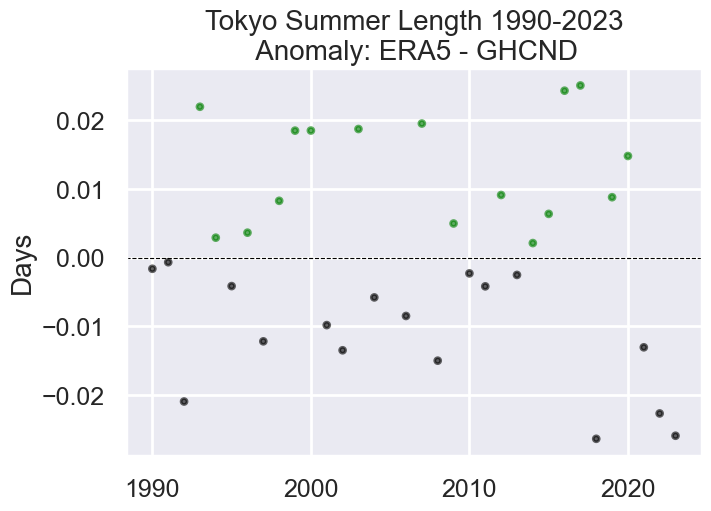

In [438]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = temp - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Tokyo Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

In [439]:
df[df['DATE'] == pd.to_datetime('1961-01-01')]['TMIN'].values[0]

np.float64(-3.9)

In [440]:
#df.query("team=='A'")["points"]
df.query("DATE == '1961-01-01'")['TMIN'].values[0]

np.float64(-3.9)

In [441]:
df.loc[df['DATE'] == '1961-01-01','TMIN'].squeeze()

np.float64(-3.9)

## Still need to find a site in the PNW, ideally Vancouver or Victoria area. Can use https://www.climdex.org/access/ ?

## **Toronto Intl Airport, ONT ** has complete data if we merge two sites that appear to be the same site but moved (one ends and the next one starts in june 2013)

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:CA006158733/detail and then https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:CA006158731/detail

In [436]:
df1 = pd.read_csv("../../../Data/GHCND/toronto_ont_a-2025-04-22T19-52-42.csv")
df2 = pd.read_csv("../../../Data/GHCND/toronto_ont_b-2025-04-22T19-52-12.csv")
df = pd.concat([df1, df2], axis=0, ignore_index=True)
#df.reset_index()
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA006158733,"TORONTO LESTER B. PEARSON INT, ON CA",43.6833,-79.6333,173.0,1961-01-01,NaN,-2.8,-8.3
1,CA006158733,"TORONTO LESTER B. PEARSON INT, ON CA",43.6833,-79.6333,173.0,1961-01-02,NaN,-2.8,-11.1
2,CA006158733,"TORONTO LESTER B. PEARSON INT, ON CA",43.6833,-79.6333,173.0,1961-01-03,NaN,-1.7,-9.4
3,CA006158733,"TORONTO LESTER B. PEARSON INT, ON CA",43.6833,-79.6333,173.0,1961-01-04,NaN,-4.4,-12.8
4,CA006158733,"TORONTO LESTER B. PEARSON INT, ON CA",43.6833,-79.6333,173.0,1961-01-05,NaN,-0.6,-12.2
...,...,...,...,...,...,...,...,...,...
22931,CA006158731,"TORONTO INTERNATIONAL A, ON CA",43.6767,-79.6306,173.4,2023-12-27,7.3,8.2,6.3
22932,CA006158731,"TORONTO INTERNATIONAL A, ON CA",43.6767,-79.6306,173.4,2023-12-28,6.8,7.7,5.8
22933,CA006158731,"TORONTO INTERNATIONAL A, ON CA",43.6767,-79.6306,173.4,2023-12-29,3.9,6.4,1.3
22934,CA006158731,"TORONTO INTERNATIONAL A, ON CA",43.6767,-79.6306,173.4,2023-12-30,0.2,1.3,-0.9


In [ ]:
df.info()

### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [443]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA006158733,"TORONTO LESTER B. PEARSON INT, ON CA",43.6833,-79.6333,173.0,1961-01-01,-5.55,-2.8,-8.3
1,CA006158733,"TORONTO LESTER B. PEARSON INT, ON CA",43.6833,-79.6333,173.0,1961-01-02,-6.95,-2.8,-11.1
2,CA006158733,"TORONTO LESTER B. PEARSON INT, ON CA",43.6833,-79.6333,173.0,1961-01-03,-5.55,-1.7,-9.4
3,CA006158733,"TORONTO LESTER B. PEARSON INT, ON CA",43.6833,-79.6333,173.0,1961-01-04,-8.60,-4.4,-12.8
4,CA006158733,"TORONTO LESTER B. PEARSON INT, ON CA",43.6833,-79.6333,173.0,1961-01-05,-6.40,-0.6,-12.2
...,...,...,...,...,...,...,...,...,...
22931,CA006158731,"TORONTO INTERNATIONAL A, ON CA",43.6767,-79.6306,173.4,2023-12-27,7.30,8.2,6.3
22932,CA006158731,"TORONTO INTERNATIONAL A, ON CA",43.6767,-79.6306,173.4,2023-12-28,6.80,7.7,5.8
22933,CA006158731,"TORONTO INTERNATIONAL A, ON CA",43.6767,-79.6306,173.4,2023-12-29,3.90,6.4,1.3
22934,CA006158731,"TORONTO INTERNATIONAL A, ON CA",43.6767,-79.6306,173.4,2023-12-30,0.20,1.3,-0.9


In [ ]:
# check counts again
df.info()

In [444]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,267.60
1961-01-02,266.20
1961-01-03,267.60
1961-01-04,264.55
1961-01-05,266.75
...,...
2023-12-27,280.45
2023-12-28,279.95
2023-12-29,277.05


In [445]:
# linear interpolation to fill the last few
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
df_sub.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 22936 entries, 1961-01-01 to 2023-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tavg    22936 non-null  float64
dtypes: float64(1)
memory usage: 358.4 KB


### Convert from Pandas to XArray

In [446]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 367kB
Dimensions:  (time: 22936)
Coordinates:
  * time     (time) datetime64[ns] 183kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 183kB 267.6 266.2 267.6 264.5 ... 277.0 273.3 273.0

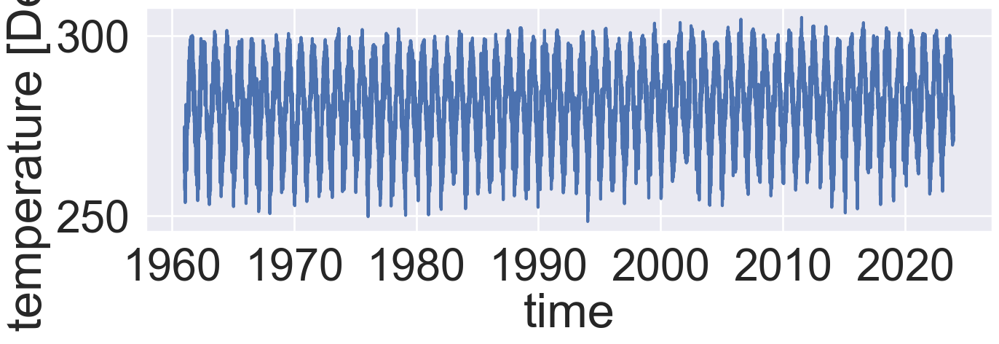

In [447]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [448]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(289.816132)
Coordinates:
    lat       float64 8B 43.75
    lon       float64 8B -79.75
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [449]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 2.61 ms, sys: 1.14 ms, total: 3.76 ms
Wall time: 2.6 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(290.45)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [450]:
thresh.values - stp_75.values

np.float64(-0.6338684082031136)

#### Toronto ONT 75th Percentile from GHCND data is 0.63 K warmer

### Try one year (2023) fit via Fourier

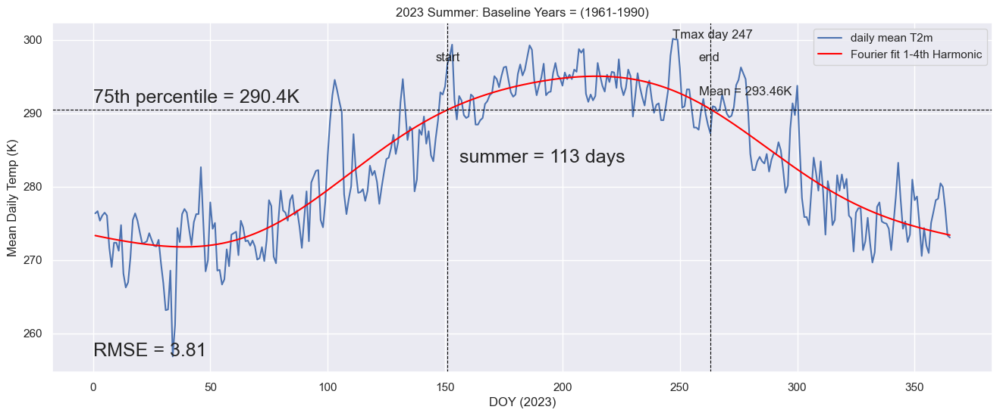

(151,
 263,
 0.14767563295350783,
 -0.19328313642500916,
 247,
 367.90000000000146,
 113,
 3.8126123352517536,
 0.0,
 293.4561946902654,
 3.9138297872340786)

In [451]:
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

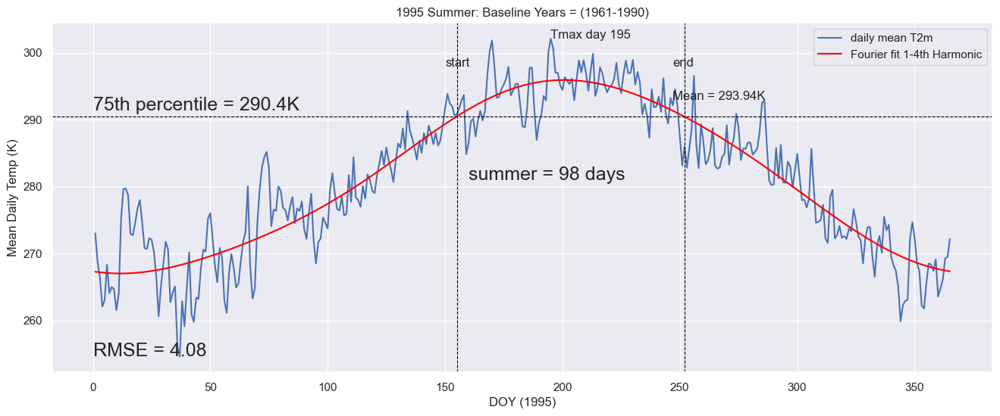

(155,
 252,
 0.21777049552559902,
 -0.18755935653209121,
 195,
 390.3999999999978,
 98,
 4.083659649399616,
 0.0,
 293.94030612244893,
 4.819753086419723)

In [452]:
# how about 1995
input_year = 1995

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Looks to be working!

### Climatology plots, 1961-2023 and 1990-2023

In [453]:
da_daily_clim_full = da_stp.tavg.groupby("time.dayofyear").mean()
da_daily_clim_an = da_stp.tavg.sel(time=slice('1990','2023')).groupby("time.dayofyear").mean()
da_daily_clim_full, da_daily_clim_an


#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()

(<xarray.DataArray 'tavg' (dayofyear: 366)> Size: 3kB
 array([268.75079365, 268.49920635, 268.92777778, 268.77619048,
        268.51587302, 268.29603175, 267.33650794, 266.5468254 ,
        267.36111111, 267.24435484, 267.73095238, 268.17857143,
        267.97460317, 266.71507937, 265.62142857, 265.71269841,
        266.82142857, 267.27936508, 266.87777778, 265.87936508,
        265.51507937, 267.47539683, 268.35873016, 267.65564516,
        267.4952381 , 267.36190476, 267.26507937, 267.09920635,
        266.78412698, 266.61904762, 266.76984127, 267.57380952,
        266.94206349, 267.1484127 , 266.86269841, 266.46507937,
        266.68809524, 266.89206349, 266.12983871, 266.67142857,
        267.03730159, 266.63492063, 266.68571429, 266.31587302,
        267.48888889, 267.95238095, 267.54444444, 267.70079365,
        268.88809524, 270.04365079, 269.86666667, 270.22258065,
        270.28095238, 269.8       , 269.6984127 , 268.73412698,
        268.5468254 , 269.28225806, 269.30080645, 

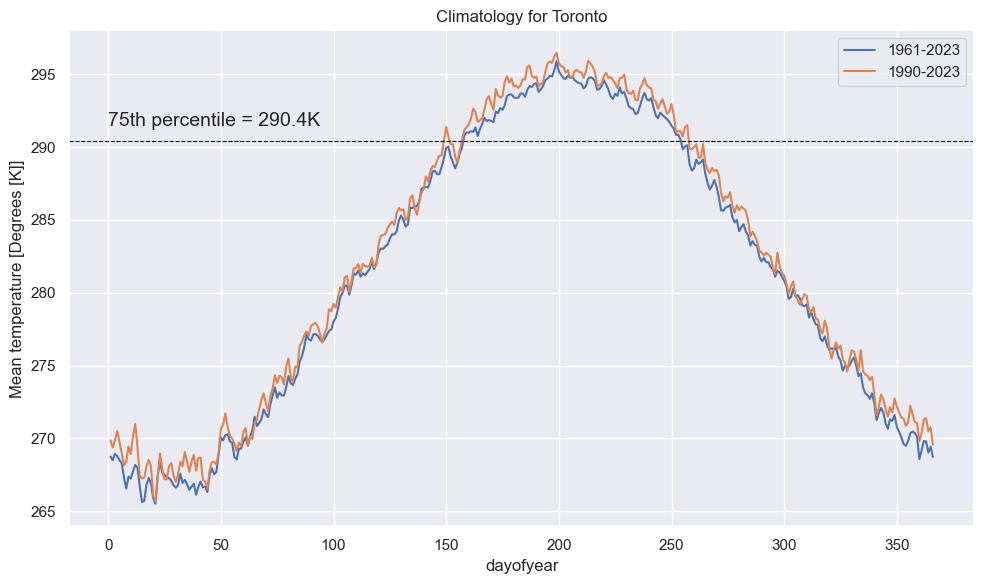

In [454]:
# plot both to compare
plt.figure(figsize=(10,6))
da_daily_clim_full.plot(label='1961-2023')
da_daily_clim_an.plot(label='1990-2023')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for Toronto")
plt.tight_layout()
plt.show()

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats 

In [455]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [456]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 273 ms, sys: 7.85 ms, total: 281 ms
Wall time: 280 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,167,264,0.179406,-0.178050,98,357.05,243,293.634184
1,1962,148,250,0.119715,-0.154788,103,259.10,189,292.577670
2,1963,160,240,0.189688,-0.135459,81,247.05,182,292.920988
3,1964,160,235,0.132678,-0.120557,76,194.50,181,292.055921
4,1965,177,236,0.058178,-0.088667,60,102.90,179,291.286667
5,1966,167,239,0.236027,-0.210901,73,229.60,184,293.354795
6,1967,172,241,0.115065,-0.150227,70,131.10,204,291.650000
7,1968,179,249,0.124136,-0.138569,71,170.40,197,292.098592
8,1969,174,254,0.155877,-0.197062,81,268.15,198,293.292593
9,1970,166,246,0.146124,-0.130776,81,216.55,209,292.438889


### write out resulting summer stats

In [457]:
# write out results
output_path = "../../../Data/GHCND/toronto_ont_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [437]:
# re-load 
input_path = "../../../Data/GHCND/toronto_ont_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,167,264,0.179406,-0.178050,98,357.05,243,293.634184
1,1,1962,148,250,0.119715,-0.154788,103,259.10,189,292.577670
2,2,1963,160,240,0.189688,-0.135459,81,247.05,182,292.920988
3,3,1964,160,235,0.132678,-0.120557,76,194.50,181,292.055921
4,4,1965,177,236,0.058178,-0.088667,60,102.90,179,291.286667
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,162,258,0.174103,-0.251686,97,371.20,201,294.062371
59,59,2020,154,252,0.280900,-0.206033,99,512.10,189,295.388384
60,60,2021,150,266,0.143323,-0.216700,117,500.60,178,294.581624
61,61,2022,151,258,0.183307,-0.197952,108,448.50,218,294.480556


### Toronto: Plot the summer stats

In [459]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

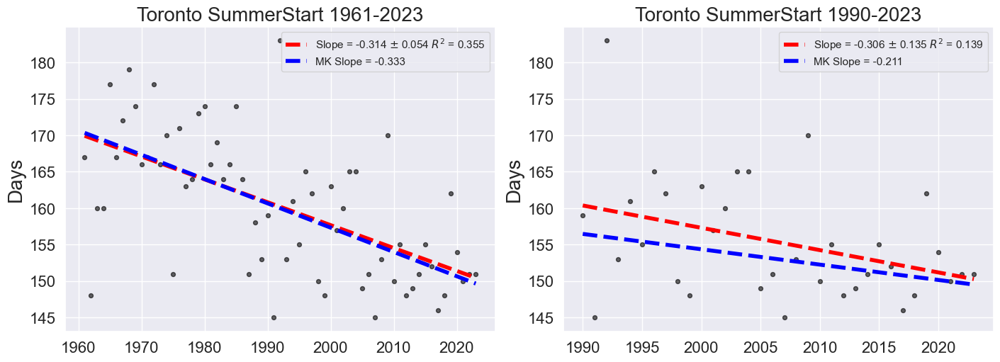

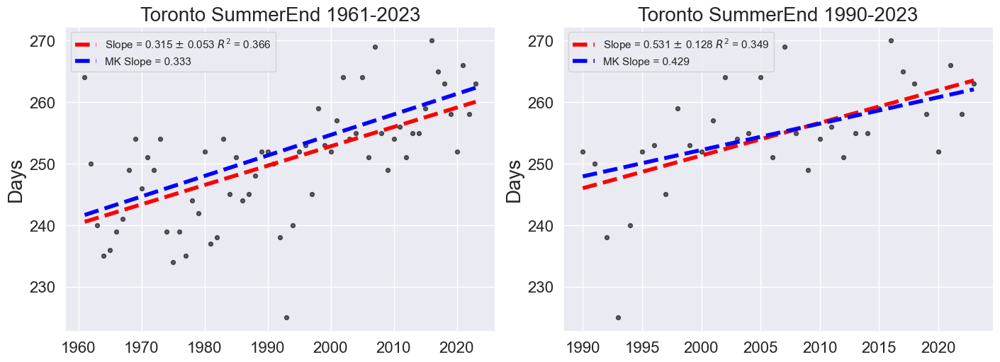

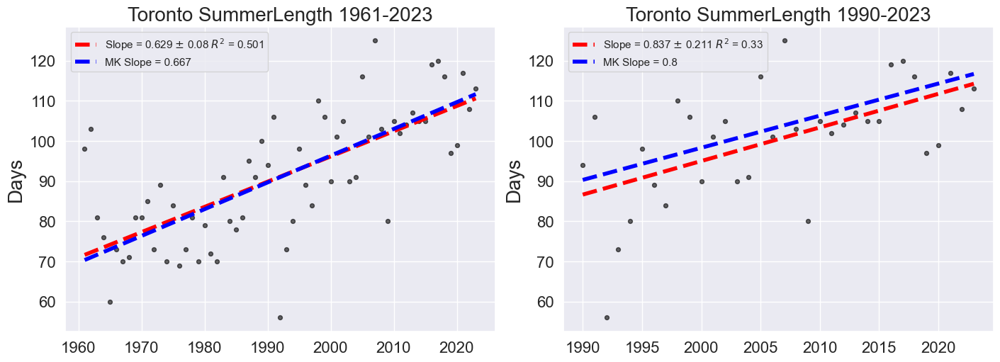

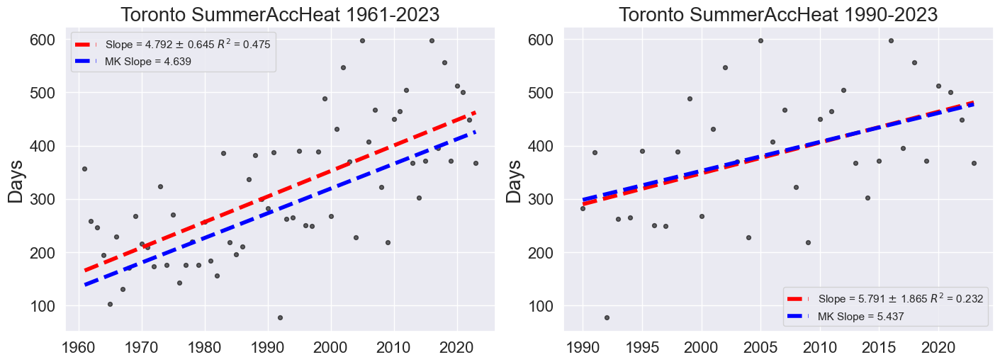

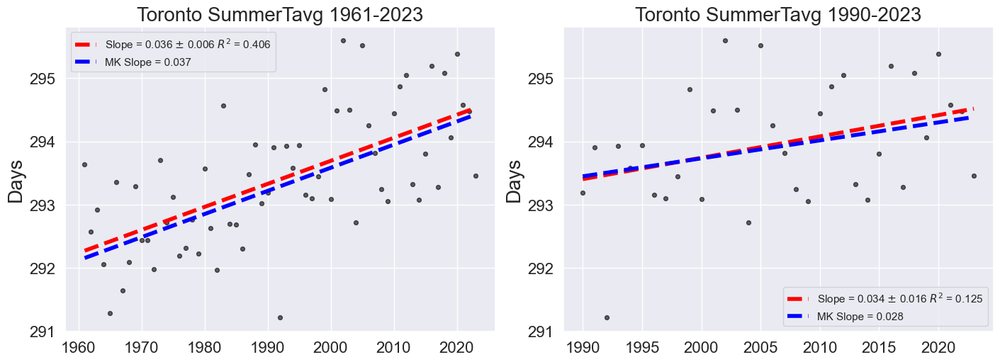

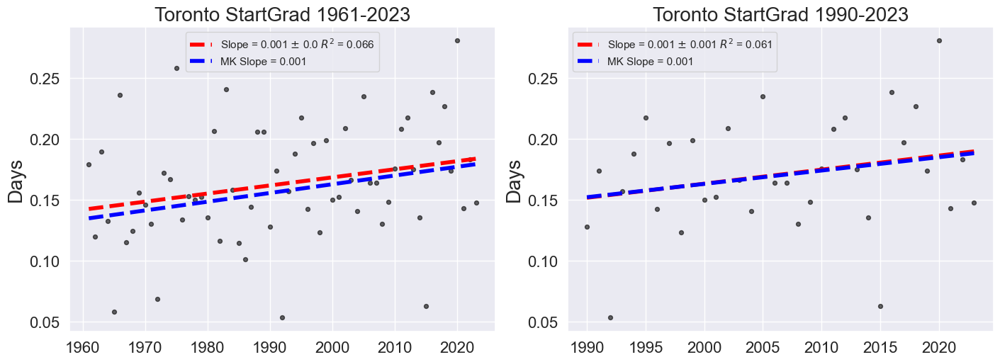

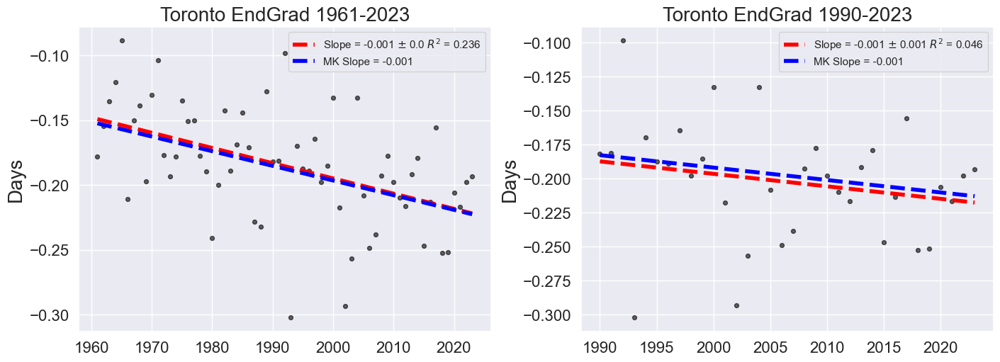

In [110]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Toronto "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('Days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Toronto "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('Days', fontsize=fs)
    


#### Summer Length Plot for Paper

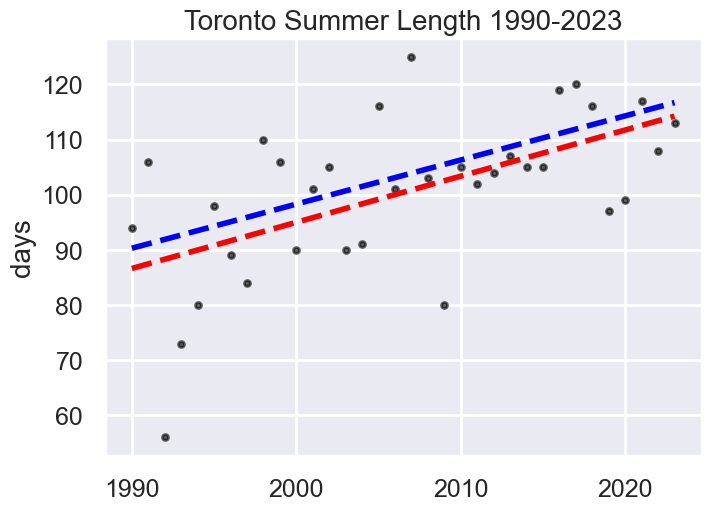

In [111]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Toronto Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/toronto_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [438]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 43.75
    lon      float64 8B -79.75
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 43.75
    lon      float64 8B -79.75
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 8.37 +/- 2.11
OLS Slope ERA5: 5.5 +/- 1.9900000000000002


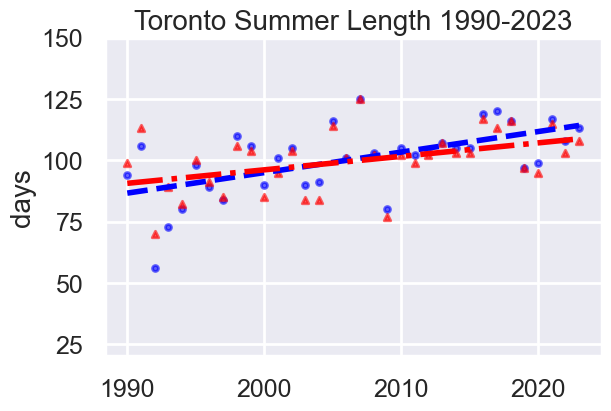

In [439]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Toronto Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(20,150)
plt.savefig("../../../Data/GHCND/Plots/toronto_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/toronto_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [116]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.330
Model:                            OLS   Adj. R-squared:                  0.309
Method:                 Least Squares   F-statistic:                     15.78
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           0.000378
Time:                        10:47:11   Log-Likelihood:                -131.84
No. Observations:                  34   AIC:                             267.7
Df Residuals:                      32   BIC:                             270.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1578.6422    422.672     -3.735      0.0

In [117]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.193
Model:                            OLS   Adj. R-squared:                  0.168
Method:                 Least Squares   F-statistic:                     7.651
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00934
Time:                        10:47:14   Log-Likelihood:                -129.86
No. Observations:                  34   AIC:                             263.7
Df Residuals:                      32   BIC:                             266.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1003.3326    398.772     -2.516      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: 57.910000000000004 +/- 18.65
OLS Slope ERA5: 33.56 +/- 17.43


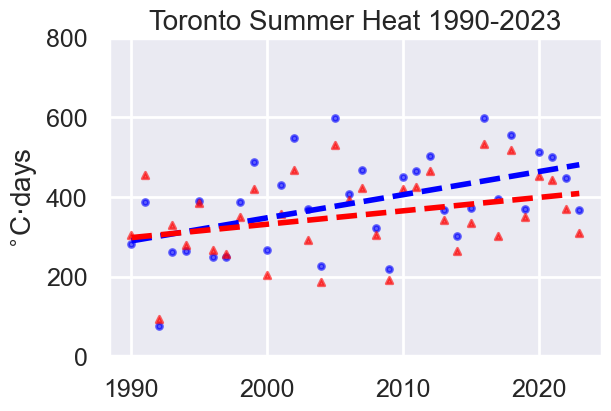

In [440]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Toronto Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,800)
plt.savefig("../../../Data/GHCND/Plots/toronto_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/toronto_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [119]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.232
Model:                            OLS   Adj. R-squared:                  0.208
Method:                 Least Squares   F-statistic:                     9.643
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00396
Time:                        10:47:26   Log-Likelihood:                -205.99
No. Observations:                  34   AIC:                             416.0
Df Residuals:                      32   BIC:                             419.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.123e+04   3741.606     -3.002      0.0

In [120]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.104
Model:                            OLS   Adj. R-squared:                  0.076
Method:                 Least Squares   F-statistic:                     3.708
Date:                Wed, 11 Feb 2026   Prob (F-statistic):             0.0631
Time:                        10:47:28   Log-Likelihood:                -203.69
No. Observations:                  34   AIC:                             411.4
Df Residuals:                      32   BIC:                             414.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -6380.4127   3497.191     -1.824      0.0

#### End Gradient with ERA5 data

In [148]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 43.75
    lon      float64 8B -79.75
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 43.75
    lon      float64 8B -79.75
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.0092 +/- 0.0074
OLS Slope ERA5: -0.0075 +/- 0.0057


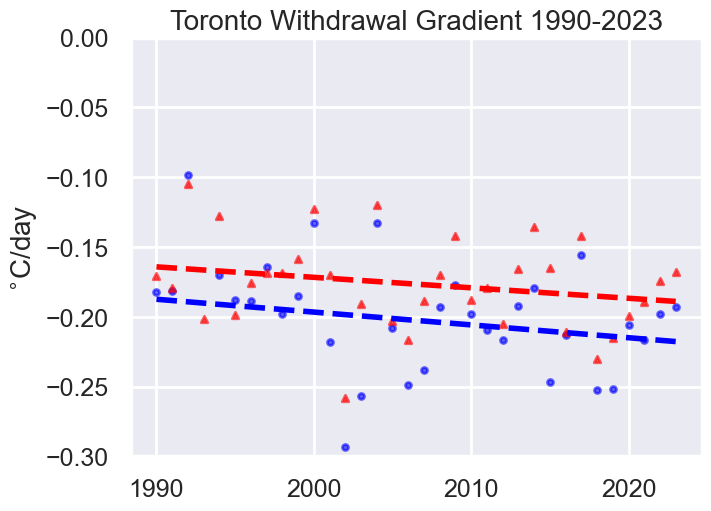

In [151]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Toronto Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/toronto_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/toronto_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: 0.0115 +/- 0.008
OLS Slope ERA5: 0.0087 +/- 0.0063


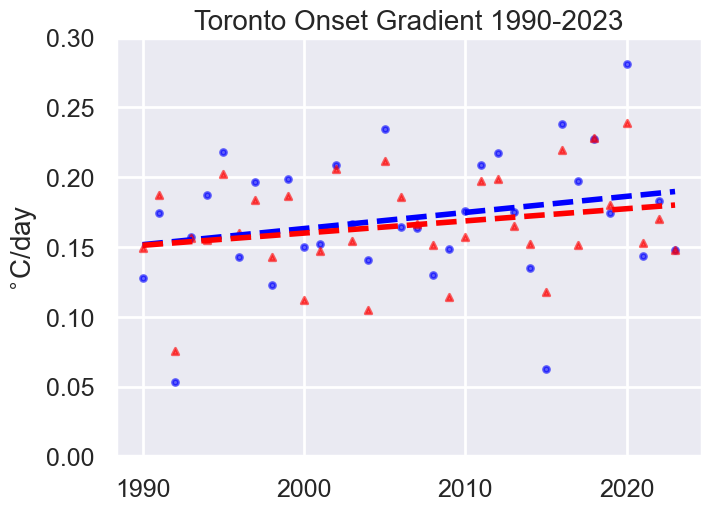

In [152]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Toronto Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/toronto_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/toronto_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

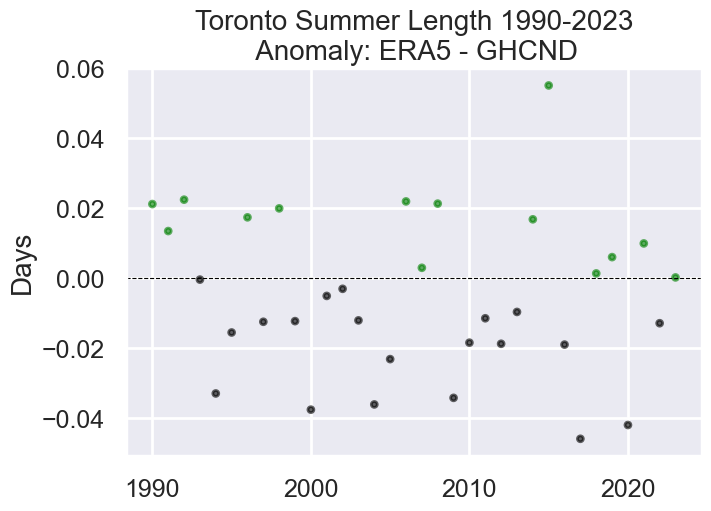

In [468]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Toronto Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

## **Bellingham Airport, WA ** has complete data (except for 1996 & 1997)

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USW00024217/detail

In [121]:
df = pd.read_csv("../../../Data/GHCND/bellingham-2025-04-23T15-57-46.csv")

#df.reset_index()
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,1961-01-01,NaN,6.1,-1.1
1,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,1961-01-02,NaN,4.4,-3.3
2,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,1961-01-03,NaN,7.2,-3.9
3,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,1961-01-04,NaN,10.6,6.1
4,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,1961-01-05,NaN,7.8,4.4
...,...,...,...,...,...,...,...,...,...
22200,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,2023-12-27,NaN,13.9,7.2
22201,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,2023-12-28,NaN,13.9,8.9
22202,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,2023-12-29,NaN,15.6,7.2
22203,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,2023-12-30,NaN,15.0,7.8


In [ ]:
df.info()

### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [470]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,1961-01-01,2.50,6.1,-1.1
1,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,1961-01-02,0.55,4.4,-3.3
2,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,1961-01-03,1.65,7.2,-3.9
3,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,1961-01-04,8.35,10.6,6.1
4,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,1961-01-05,6.10,7.8,4.4
...,...,...,...,...,...,...,...,...,...
22200,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,2023-12-27,10.55,13.9,7.2
22201,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,2023-12-28,11.40,13.9,8.9
22202,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,2023-12-29,11.40,15.6,7.2
22203,USW00024217,"BELLINGHAM INTERNATIONAL AIRPORT, WA US",48.7991,-122.54069,45.9,2023-12-30,11.40,15.0,7.8


In [ ]:
# check counts again
df.info()

In [471]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,275.65
1961-01-02,273.70
1961-01-03,274.80
1961-01-04,281.50
1961-01-05,279.25
...,...
2023-12-27,283.70
2023-12-28,284.55
2023-12-29,284.55


In [472]:
# linear interpolation to fill the last few
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
df_sub.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 22205 entries, 1961-01-01 to 2023-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tavg    22205 non-null  float64
dtypes: float64(1)
memory usage: 347.0 KB


### Convert from Pandas to XArray

In [473]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 355kB
Dimensions:  (time: 22205)
Coordinates:
  * time     (time) datetime64[ns] 178kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 178kB 275.6 273.7 274.8 281.5 ... 284.5 284.5 277.9

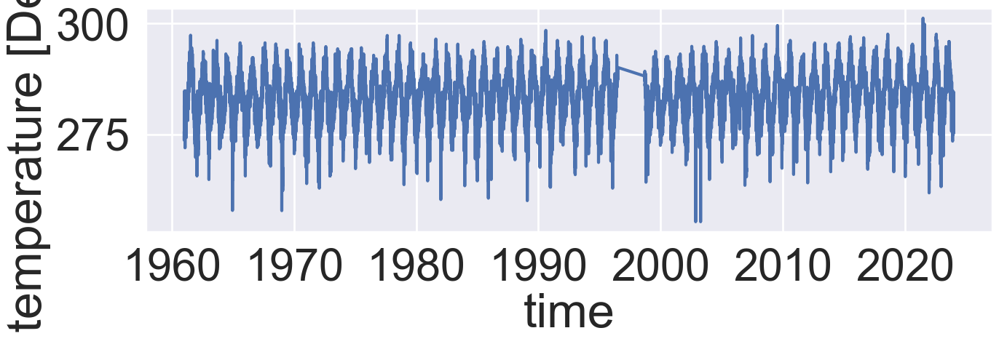

In [474]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

In [475]:
np.unique(da_stp.time.dt.year)

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005,
       2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016,
       2017, 2018, 2019, 2020, 2021, 2022, 2023])

#### 1996, 1997, and 1998 have big missing bits - will have to interpolate later

### Calculate the threshold temp from 1961-1990, 75%-ile

In [476]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(286.887848)
Coordinates:
    lat       float64 8B 48.75
    lon       float64 8B -122.5
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [477]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 4.35 ms, sys: 2.46 ms, total: 6.81 ms
Wall time: 5.15 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(287.85)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [478]:
thresh.values - stp_75.values

np.float64(-0.9621520996093409)

#### Bellingham 75th Percentile from GHCND data is 0.96 K warmer

### Try one year fits via Fourier

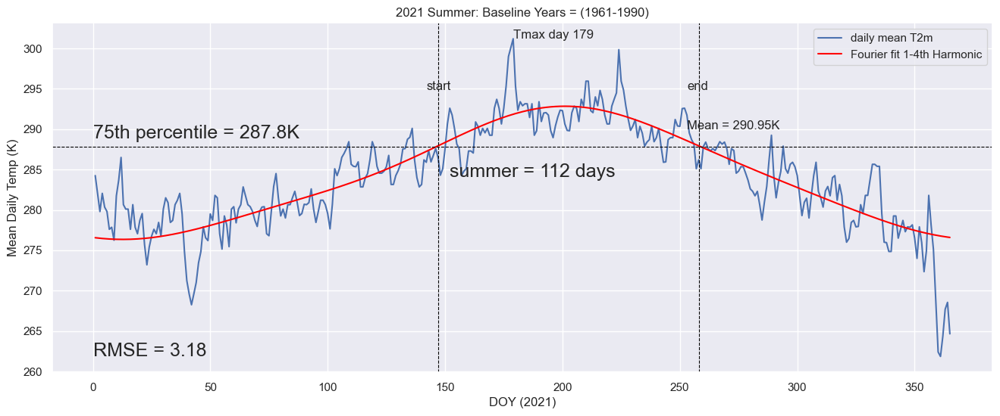

(147,
 258,
 0.13913067653311373,
 -0.12814120382074634,
 179,
 376.40000000000146,
 112,
 3.1772715121906923,
 0.0,
 290.9508928571428,
 3.880412371134014)

In [479]:
input_year = 2021

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

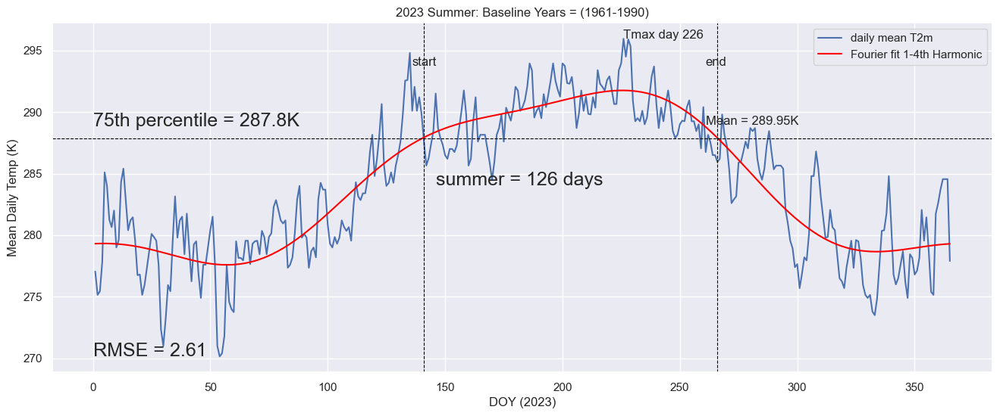

(141,
 266,
 0.09332446733506572,
 -0.18973926824992304,
 226,
 296.450000000008,
 126,
 2.6051027555887165,
 0.0,
 289.94920634920635,
 2.935148514851562)

In [480]:
input_year = 2023
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

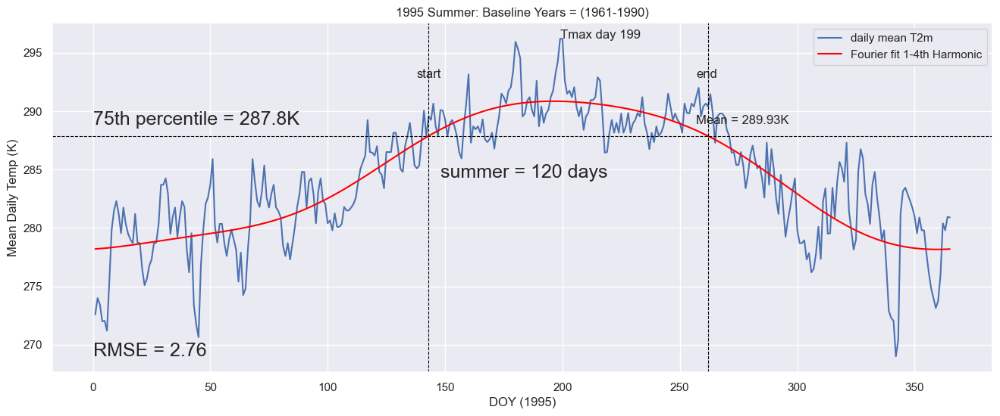

(143,
 262,
 0.11348989472793392,
 -0.10311789650722858,
 199,
 260.3500000000022,
 120,
 2.7581273999859337,
 0.0,
 289.9345833333333,
 2.3885321100917736)

In [481]:
# how about 1995
input_year = 1995

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Looks to be working!

### Climatology plots, 1961-2023 and 1990-2023

In [482]:
da_daily_clim_full = da_stp.tavg.groupby("time.dayofyear").mean()
da_daily_clim_an = da_stp.tavg.sel(time=slice('1990','2023')).groupby("time.dayofyear").mean()
da_daily_clim_full, da_daily_clim_an


#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()

(<xarray.DataArray 'tavg' (dayofyear: 366)> Size: 3kB
 array([276.09754098, 276.2557377 , 276.10409836, 276.04344262,
        276.05983607, 275.7852459 , 276.49590164, 277.24262295,
        277.42295082, 276.84180328, 276.73852459, 277.14344262,
        277.48114754, 277.70819672, 277.28606557, 277.4       ,
        277.2352459 , 277.41885246, 277.30081967, 277.4295082 ,
        277.25409836, 277.30819672, 277.29180328, 277.19590164,
        277.07786885, 276.81885246, 276.76393443, 276.87131148,
        276.8557377 , 276.78770492, 277.36557377, 277.41721311,
        277.44098361, 277.61147541, 277.94262295, 277.59672131,
        278.08442623, 277.91147541, 277.87377049, 277.68688525,
        277.92295082, 278.17377049, 278.74180328, 278.33688525,
        278.21885246, 278.51065574, 278.79262295, 278.39016393,
        278.58442623, 278.73770492, 278.48360656, 278.12786885,
        278.60983607, 278.09016393, 278.01967213, 277.79262295,
        278.14262295, 278.68934426, 278.99      , 

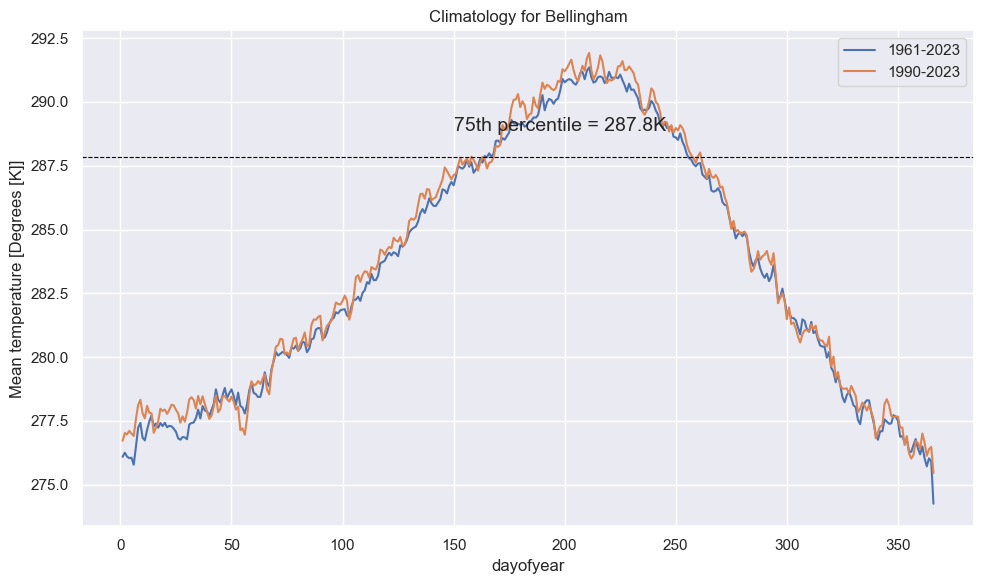

In [483]:
# plot both to compare
plt.figure(figsize=(10,6))
da_daily_clim_full.plot(label='1961-2023')
da_daily_clim_an.plot(label='1990-2023')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(150,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for Bellingham")
plt.tight_layout()
plt.show()

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats - here we have to drop 1996-1998 since missing

In [484]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs1 = np.arange(1961, 1996,1)
process_yrs2 = np.arange(1999,2024,1)
process_yrs = np.append(process_yrs1, process_yrs2)
process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007,
       2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018,
       2019, 2020, 2021, 2022, 2023])

In [485]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 255 ms, sys: 7.07 ms, total: 262 ms
Wall time: 260 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,155,255,0.116034,-0.170631,101,275.20,193,290.441089
1,1962,175,250,0.087674,-0.093374,76,116.90,204,289.159868
2,1963,169,269,0.066421,-0.122911,101,168.95,252,289.183168
3,1964,168,243,0.074174,-0.043333,76,81.60,192,288.490789
4,1965,164,248,0.133669,-0.075729,85,176.35,211,289.554118
5,1966,185,249,0.094888,-0.123654,65,87.85,231,289.020769
6,1967,156,270,0.128495,-0.149504,115,311.90,228,290.469565
7,1968,159,243,0.148119,-0.101149,85,181.70,184,289.870000
8,1969,157,230,0.087574,-0.084241,74,102.20,169,288.920270
9,1970,158,242,0.128848,-0.068940,85,148.20,196,289.369412


#### Fill in the missing years via interpolation?

In [486]:
df_tmp = pd.DataFrame({"Year":[1996,1997,1998],
                        "SummerStart":[np.nan, np.nan, np.nan],
                        "SummerEnd":[np.nan, np.nan, np.nan],
                        "StartGrad":[np.nan, np.nan, np.nan],
                        "EndGrad":[np.nan, np.nan, np.nan],
                        "SummerLength":[np.nan, np.nan, np.nan],
                        "SummerAccHeat":[np.nan, np.nan, np.nan],
                        "SummerTmaxDay":[np.nan, np.nan, np.nan],
                        "SummerTavg":[np.nan, np.nan, np.nan]
                          })
df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)
df_summ = df_summ.sort_values('Year')
df_summ = df_summ.interpolate(method='linear')
df_summ.reset_index(drop=True, inplace=True)

df_summ.query("Year >= 1994 & Year <= 2000")

,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
33,1994,162.0,264.00,0.050295,-0.200284,103.00,247.8500,201.0,290.115534
34,1995,143.0,262.00,0.113490,-0.103118,120.00,260.3500,199.0,289.934583
35,1996,151.0,258.75,0.111668,-0.106836,108.75,227.8375,203.5,289.744937
36,1997,159.0,255.50,0.109846,-0.110554,97.50,195.3250,208.0,289.555292
37,1998,167.0,252.25,0.108024,-0.114272,86.25,162.8125,212.5,289.365646
38,1999,175.0,249.00,0.106202,-0.117991,75.00,130.3000,217.0,289.176000
39,2000,169.0,250.00,0.077920,-0.092288,82.00,116.3000,178.0,288.921951


### write out resulting summer stats

In [487]:
# write out results
output_path = "../../../Data/GHCND/bellingham_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [122]:
# re-load 
input_path = "../../../Data/GHCND/bellingham_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,155.0,255.0,0.116034,-0.170631,101.0,275.20,193.0,290.441089
1,1,1962,175.0,250.0,0.087674,-0.093374,76.0,116.90,204.0,289.159868
2,2,1963,169.0,269.0,0.066421,-0.122911,101.0,168.95,252.0,289.183168
3,3,1964,168.0,243.0,0.074174,-0.043333,76.0,81.60,192.0,288.490789
4,4,1965,164.0,248.0,0.133669,-0.075729,85.0,176.35,211.0,289.554118
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,149.0,261.0,0.032103,-0.192958,113.0,301.00,163.0,290.438938
59,59,2020,152.0,269.0,0.056303,-0.177980,118.0,273.05,228.0,289.996610
60,60,2021,147.0,258.0,0.139131,-0.128141,112.0,376.40,179.0,290.950893
61,61,2022,159.0,273.0,0.120831,-0.215298,115.0,356.60,210.0,290.884348


### Bellngham: Plot the summer stats

In [489]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

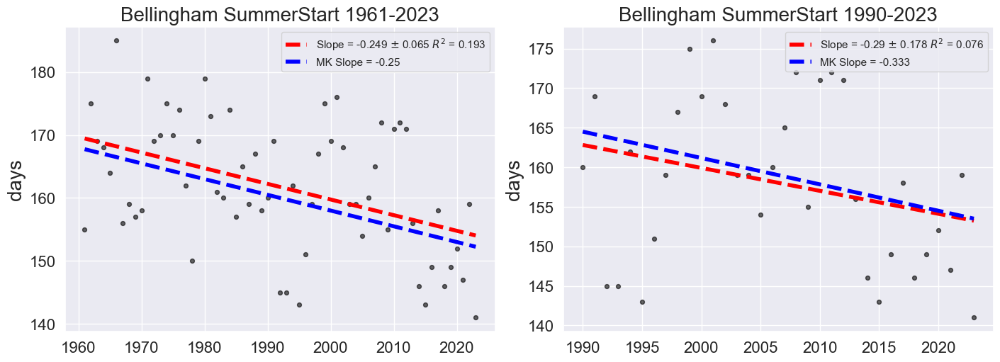

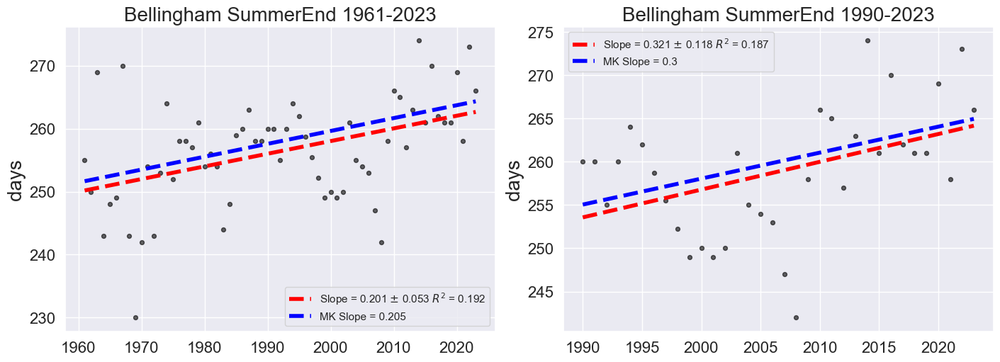

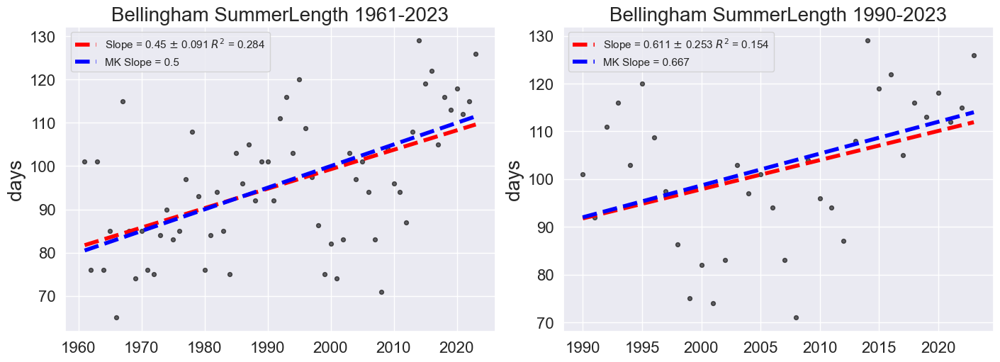

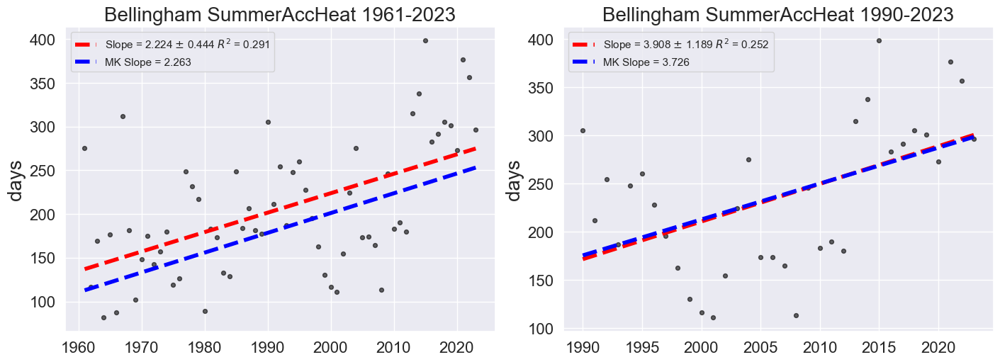

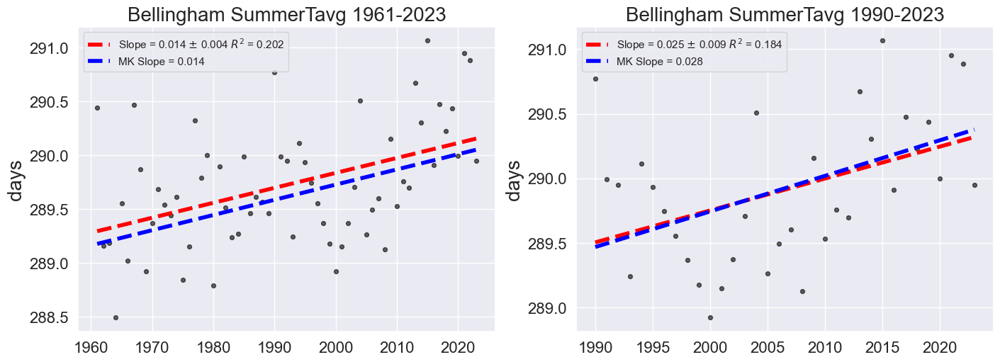

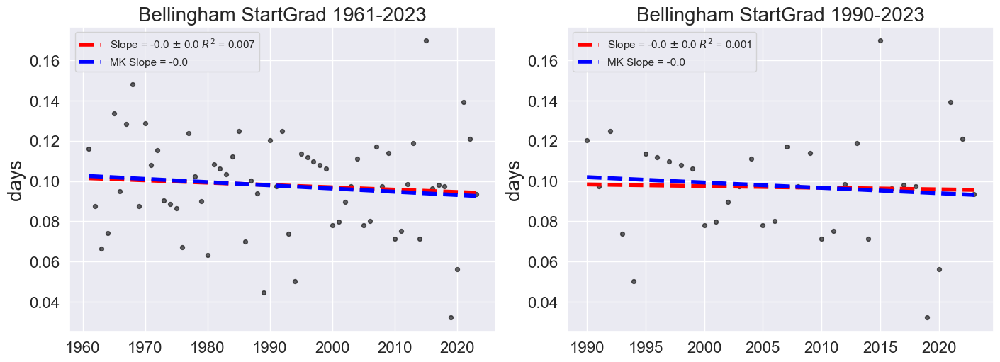

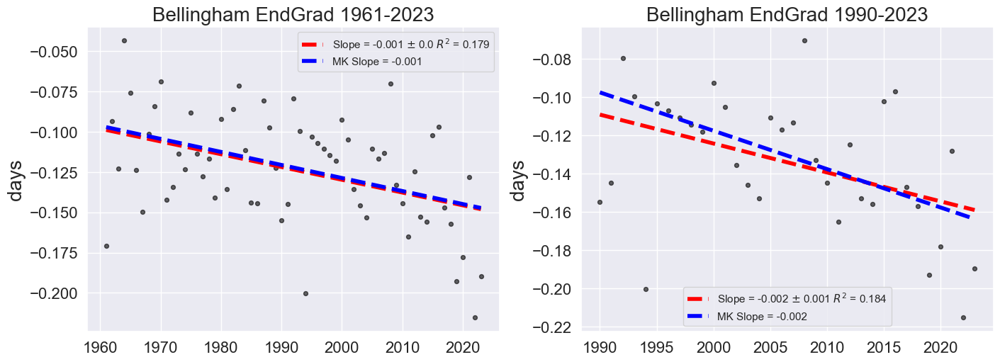

In [116]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Bellingham "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Bellingham "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

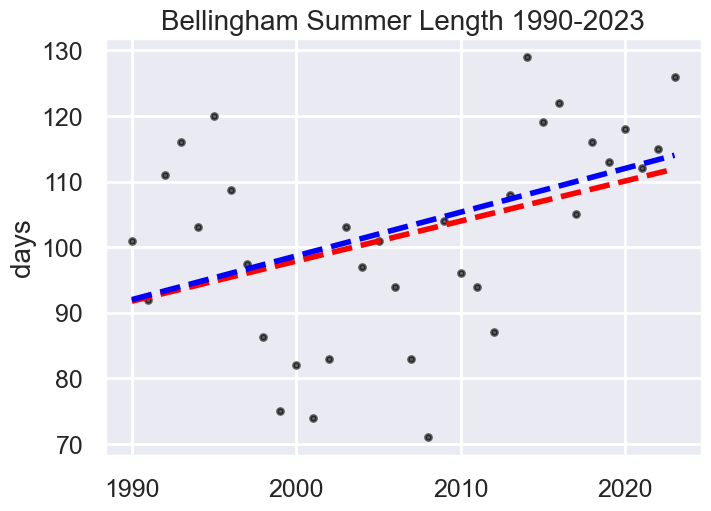

In [117]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Bellingham Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/bellingham_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [123]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 48.75
    lon      float64 8B -122.5
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 48.75
    lon      float64 8B -122.5
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 6.109999999999999 +/- 2.5300000000000002
OLS Slope ERA5: 3.7199999999999998 +/- 1.9500000000000002


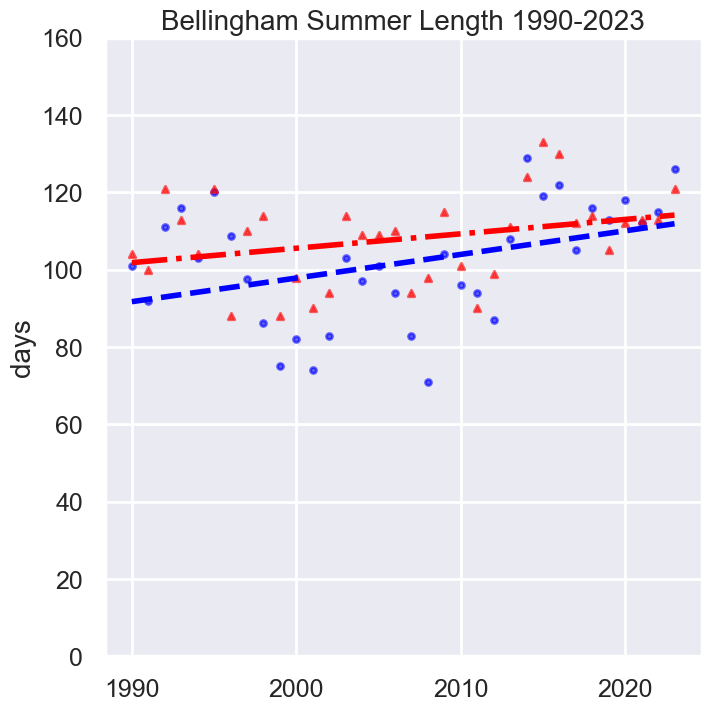

In [124]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,7), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Bellingham Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(0,160)
plt.savefig("../../../Data/GHCND/Plots/bellingham_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/bellingham_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [125]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.154
Model:                            OLS   Adj. R-squared:                  0.128
Method:                 Least Squares   F-statistic:                     5.837
Date:                Wed, 11 Feb 2026   Prob (F-statistic):             0.0216
Time:                        10:48:46   Log-Likelihood:                -138.04
No. Observations:                  34   AIC:                             280.1
Df Residuals:                      32   BIC:                             283.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1123.6749    507.241     -2.215      0.0

In [126]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.103
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     3.655
Date:                Wed, 11 Feb 2026   Prob (F-statistic):             0.0649
Time:                        10:48:49   Log-Likelihood:                -129.19
No. Observations:                  34   AIC:                             262.4
Df Residuals:                      32   BIC:                             265.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -639.4174    390.975     -1.635      0.1

#### Accumulated Heat with ERA5 data

OLS Slope: 39.08 +/- 11.89
OLS Slope ERA5: 30.419999999999998 +/- 9.73


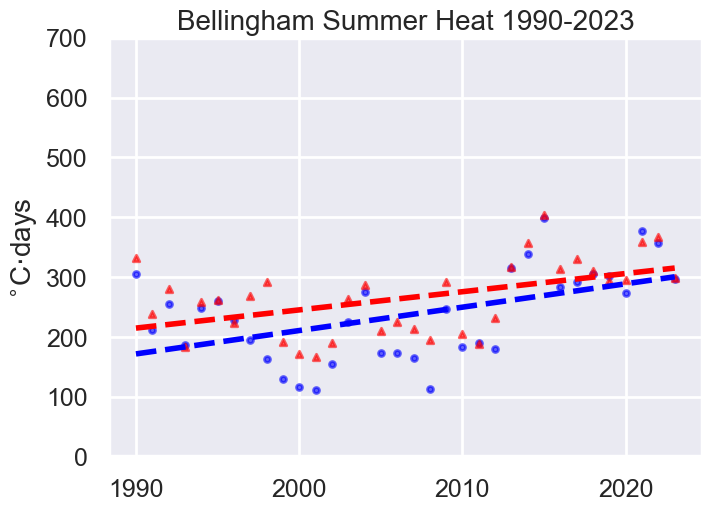

In [127]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Bellingham Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/bellingham_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/bellingham_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [128]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.252
Model:                            OLS   Adj. R-squared:                  0.229
Method:                 Least Squares   F-statistic:                     10.81
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00246
Time:                        10:49:02   Log-Likelihood:                -190.67
No. Observations:                  34   AIC:                             385.3
Df Residuals:                      32   BIC:                             388.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7605.1375   2385.027     -3.189      0.0

In [129]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.234
Model:                            OLS   Adj. R-squared:                  0.210
Method:                 Least Squares   F-statistic:                     9.781
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00374
Time:                        10:49:04   Log-Likelihood:                -183.86
No. Observations:                  34   AIC:                             371.7
Df Residuals:                      32   BIC:                             374.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -5839.6447   1951.936     -2.992      0.0

#### End Gradient with ERA5 data

In [160]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 48.75
    lon      float64 8B -122.5
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 48.75
    lon      float64 8B -122.5
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.0151 +/- 0.005599999999999999
OLS Slope ERA5: -0.005900000000000001 +/- 0.0032


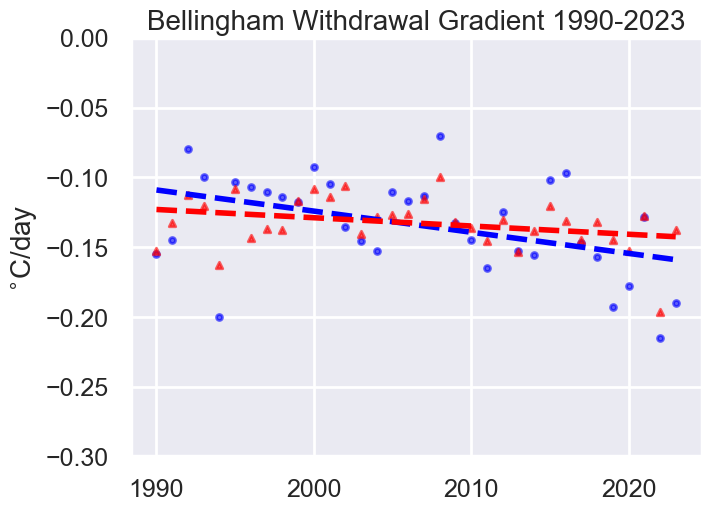

In [161]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Bellingham Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/bellingham_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/bellingham_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: -0.0008 +/- 0.0047
OLS Slope ERA5: 0.0044 +/- 0.0027999999999999995


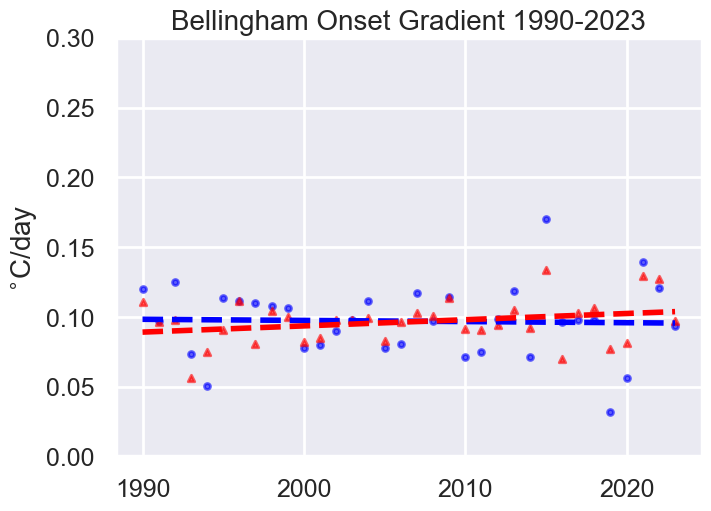

In [163]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Bellingham Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/bellingham_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/bellingham_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

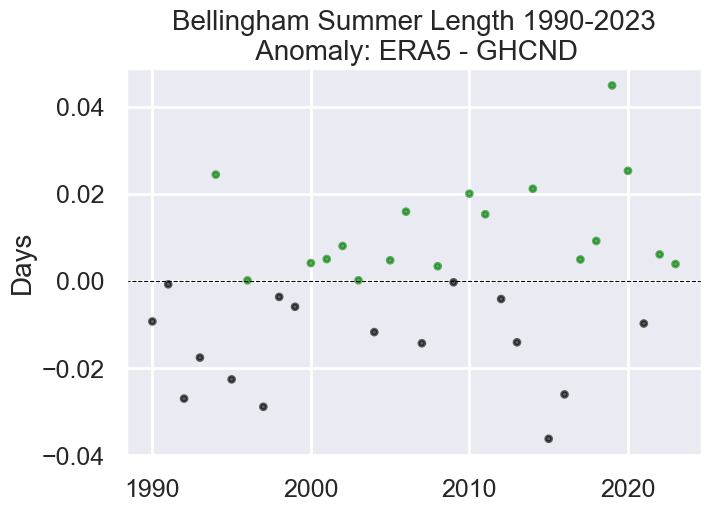

In [498]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Bellingham Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

# **** [not updated] Try some high latitude sites

# Northern Canada Interior Sites expected to see summer getting shorter based on ERA5 analysis

## **Coral Harbour, Nu ** has complete data 

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:CA002301000/detail

In [404]:

df = pd.read_csv("../../../Data/GHCND/coralharbour-nu-2025-04-29T21-37-18.csv")
#df.reset_index()
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,1961-01-01,NaN,-32.8,-37.2
1,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,1961-01-02,NaN,-28.9,-37.2
2,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,1961-01-03,NaN,-23.3,-35.6
3,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,1961-01-04,NaN,-23.3,-28.9
4,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,1961-01-05,NaN,-26.7,-33.9
...,...,...,...,...,...,...,...,...,...
22920,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,2023-12-27,-22.7,-20.4,-25.6
22921,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,2023-12-28,-11.4,-8.7,-25.6
22922,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,2023-12-29,-9.6,NaN,NaN
22923,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,2023-12-30,-16.1,NaN,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22925 entries, 0 to 22924
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    22925 non-null  str    
 1   NAME       22925 non-null  str    
 2   LATITUDE   22925 non-null  float64
 3   LONGITUDE  22925 non-null  float64
 4   ELEVATION  22925 non-null  float64
 5   DATE       22925 non-null  str    
 6   TAVG       16521 non-null  float64
 7   TMAX       20822 non-null  float64
 8   TMIN       20813 non-null  float64
dtypes: float64(6), str(3)
memory usage: 2.5 MB


### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [5]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,1961-01-01,-35.00,-32.8,-37.2
1,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,1961-01-02,-33.05,-28.9,-37.2
2,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,1961-01-03,-29.45,-23.3,-35.6
3,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,1961-01-04,-26.10,-23.3,-28.9
4,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,1961-01-05,-30.30,-26.7,-33.9
...,...,...,...,...,...,...,...,...,...
22920,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,2023-12-27,-22.70,-20.4,-25.6
22921,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,2023-12-28,-11.40,-8.7,-25.6
22922,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,2023-12-29,-9.60,NaN,NaN
22923,CA002301000,"CORAL HARBOUR A, NU CA",64.2,-83.3667,62.0,2023-12-30,-16.10,NaN,NaN


In [6]:
# check counts again
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22925 entries, 0 to 22924
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    22925 non-null  str    
 1   NAME       22925 non-null  str    
 2   LATITUDE   22925 non-null  float64
 3   LONGITUDE  22925 non-null  float64
 4   ELEVATION  22925 non-null  float64
 5   DATE       22925 non-null  str    
 6   TAVG       22915 non-null  float64
 7   TMAX       20822 non-null  float64
 8   TMIN       20813 non-null  float64
dtypes: float64(6), str(3)
memory usage: 2.5 MB


In [7]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,238.15
1961-01-02,240.10
1961-01-03,243.70
1961-01-04,247.05
1961-01-05,242.85
...,...
2023-12-27,250.45
2023-12-28,261.75
2023-12-29,263.55


#### based on the plots I tried below, there are some missing dates - finding them

In [8]:
df_sub.index

DatetimeIndex(['1961-01-01', '1961-01-02', '1961-01-03', '1961-01-04',
               '1961-01-05', '1961-01-06', '1961-01-07', '1961-01-08',
               '1961-01-09', '1961-01-10',
               ...
               '2023-12-21', '2023-12-22', '2023-12-23', '2023-12-24',
               '2023-12-26', '2023-12-27', '2023-12-28', '2023-12-29',
               '2023-12-30', '2023-12-31'],
              dtype='datetime64[us]', name='time', length=22925, freq=None)

In [9]:
#df_sub.tail(365)
#df_sub.loc['2020-01-01':'2021-12-31'].head(300)

# got help from https://www.geeksforgeeks.org/check-missing-dates-in-pandas/
print(pd.date_range(
  start="1961-01-01", end="2023-12-31").difference(df_sub.index))

DatetimeIndex(['1979-10-21', '1979-10-22', '1979-10-23', '1979-10-24',
               '1979-10-25', '1979-10-27', '1979-11-01', '1979-11-02',
               '1996-02-01', '1997-05-18', '1999-12-21', '1999-12-22',
               '2001-02-23', '2001-05-09', '2004-01-25', '2005-01-14',
               '2005-01-15', '2005-02-04', '2005-03-11', '2005-04-29',
               '2008-03-23', '2008-03-24', '2008-12-30', '2010-01-15',
               '2010-03-27', '2010-12-07', '2010-12-08', '2011-05-06',
               '2012-01-09', '2012-02-08', '2012-04-26', '2014-01-08',
               '2014-01-27', '2015-05-01', '2015-05-02', '2015-05-07',
               '2015-05-08', '2015-05-09', '2015-05-10', '2015-05-11',
               '2015-05-12', '2015-05-13', '2015-05-14', '2015-05-15',
               '2015-05-16', '2015-05-17', '2015-05-18', '2015-05-19',
               '2015-05-20', '2015-05-21', '2015-05-22', '2015-05-23',
               '2015-05-24', '2015-05-25', '2015-05-26', '2015-05-27',
      

In [10]:
missingdates = (pd.date_range(start="1961-01-01", end="2023-12-31").difference(df_sub.index))
missingdates, len(missingdates)

(DatetimeIndex(['1979-10-21', '1979-10-22', '1979-10-23', '1979-10-24',
                '1979-10-25', '1979-10-27', '1979-11-01', '1979-11-02',
                '1996-02-01', '1997-05-18', '1999-12-21', '1999-12-22',
                '2001-02-23', '2001-05-09', '2004-01-25', '2005-01-14',
                '2005-01-15', '2005-02-04', '2005-03-11', '2005-04-29',
                '2008-03-23', '2008-03-24', '2008-12-30', '2010-01-15',
                '2010-03-27', '2010-12-07', '2010-12-08', '2011-05-06',
                '2012-01-09', '2012-02-08', '2012-04-26', '2014-01-08',
                '2014-01-27', '2015-05-01', '2015-05-02', '2015-05-07',
                '2015-05-08', '2015-05-09', '2015-05-10', '2015-05-11',
                '2015-05-12', '2015-05-13', '2015-05-14', '2015-05-15',
                '2015-05-16', '2015-05-17', '2015-05-18', '2015-05-19',
                '2015-05-20', '2015-05-21', '2015-05-22', '2015-05-23',
                '2015-05-24', '2015-05-25', '2015-05-26', '2015-

## **** Looks like 2015 has a large gap in May that interpolation might not be able to fix up but time to fill the rest

In [11]:
df_missing = pd.DataFrame({'time':pd.to_datetime(missingdates),
                            'tavg':np.repeat(np.nan, len(missingdates))})
df_missing = df_missing.set_index(['time'])
df_missing
                                                 

,tavg
time,
1979-10-21,NaN
1979-10-22,NaN
1979-10-23,NaN
1979-10-24,NaN
1979-10-25,NaN
...,...
2022-11-01,NaN
2022-12-04,NaN
2022-12-25,NaN


In [12]:
df_sub = pd.concat([df_sub, df_missing], axis=0).sort_index()
df_sub

,tavg
time,
1961-01-01,238.15
1961-01-02,240.10
1961-01-03,243.70
1961-01-04,247.05
1961-01-05,242.85
...,...
2023-12-27,250.45
2023-12-28,261.75
2023-12-29,263.55


In [13]:
# linear interpolation to fill the missing ones
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
print(df_sub[df_sub.isna().any(axis=1)])

Empty DataFrame
Columns: [tavg]
Index: []


#### all cleaned up!

In [14]:
df_sub.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 23010 entries, 1961-01-01 to 2023-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tavg    23010 non-null  float64
dtypes: float64(1)
memory usage: 359.5 KB


### Convert from Pandas to XArray

In [15]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 368kB
Dimensions:  (time: 23010)
Coordinates:
  * time     (time) datetime64[us] 184kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 184kB 238.1 240.1 243.7 247.0 ... 263.5 257.0 245.0

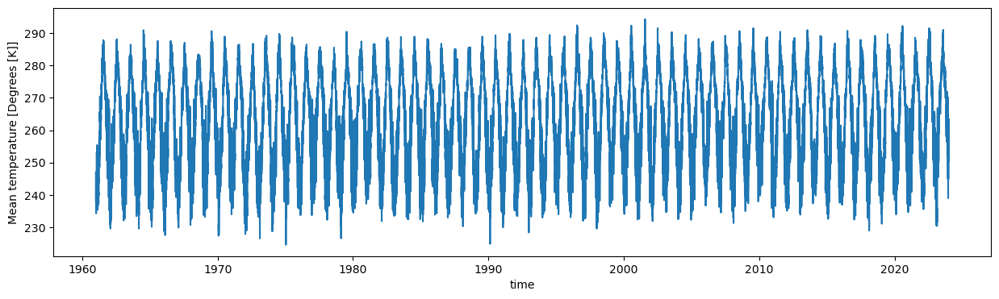

In [16]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

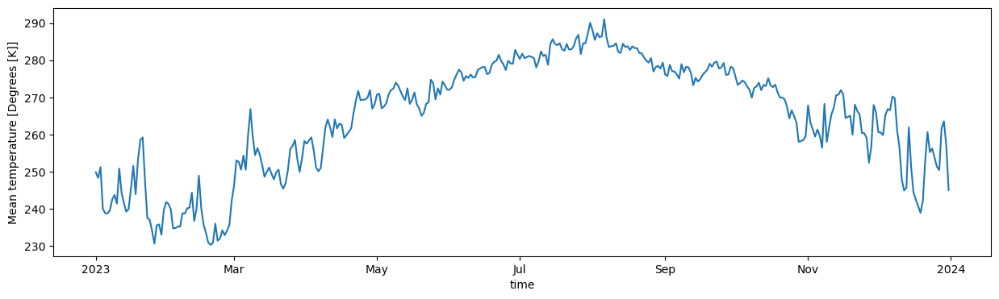

In [17]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('2023','2023')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [21]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(274.300201)
Coordinates:
    lat       float64 8B 64.25
    lon       float64 8B -83.25
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [22]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 4.24 ms, sys: 4.33 ms, total: 8.57 ms
Wall time: 7.5 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(275.45)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [23]:
thresh.values - stp_75.values

np.float64(-1.1497985839843636)

#### Coral Harbour NU 75th Percentile from GHCND data is 1.15 K warmer

### Try one year (2023) fit via Fourier

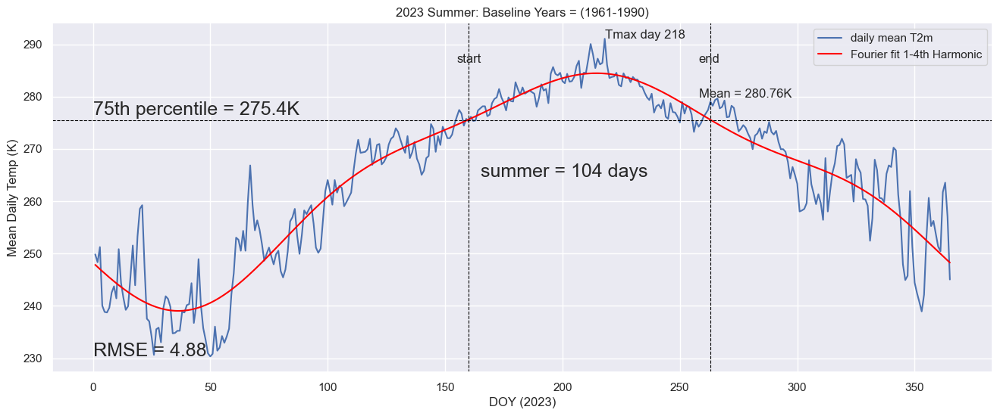

(160,
 263,
 0.2062992604842293,
 -0.2629645058587471,
 218,
 557.0999999999985,
 104,
 4.875431656933498,
 0.0,
 280.76249999999993,
 5.6846938775510125)

In [28]:
input_year = 2023

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

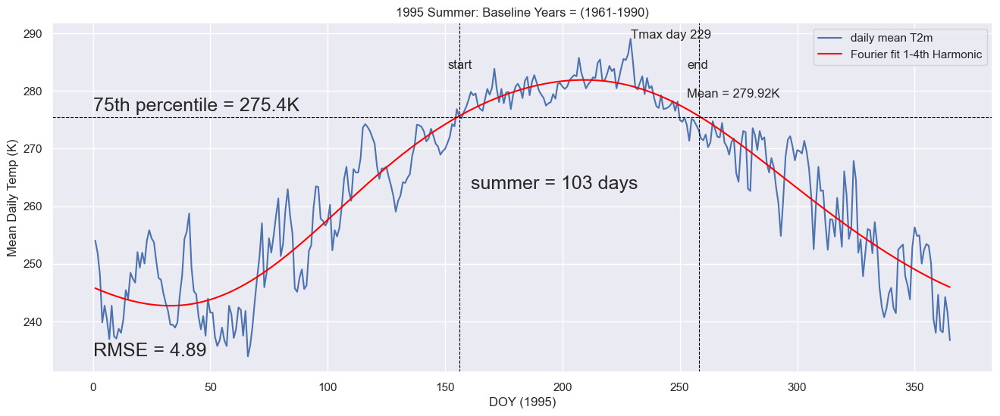

(156,
 258,
 0.2235419043603315,
 -0.2515168551396414,
 229,
 476.2000000000007,
 103,
 4.894282677986017,
 0.0,
 279.92475728155335,
 5.176086956521715)

In [29]:
# how about 1995
input_year = 1995
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats

In [30]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [31]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 254 ms, sys: 19.9 ms, total: 274 ms
Wall time: 290 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,164,249,0.277882,-0.315885,86,427.55,204,280.368023
1,1962,171,252,0.368218,-0.272436,82,411.40,205,280.460366
2,1963,170,251,0.238632,-0.240983,82,332.90,210,279.410366
3,1964,162,262,0.262787,-0.263641,101,424.80,192,279.356436
4,1965,170,246,0.237926,-0.321005,77,289.85,209,279.155195
...,...,...,...,...,...,...,...,...,...
58,2019,154,268,0.315018,-0.217329,115,636.70,180,280.918696
59,2020,162,260,0.377099,-0.347803,99,730.00,216,282.710606
60,2021,164,274,0.216012,-0.253201,111,428.30,191,279.077928
61,2022,154,262,0.309295,-0.332270,109,763.60,205,282.443578


### write out resulting summer stats

In [32]:
# write out results
output_path = "../../../Data/GHCND/coralharbour_nu_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [405]:
# re-load 
input_path = "../../../Data/GHCND/coralharbour_nu_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,164,249,0.277882,-0.315885,86,427.55,204,280.368023
1,1,1962,171,252,0.368218,-0.272436,82,411.40,205,280.460366
2,2,1963,170,251,0.238632,-0.240983,82,332.90,210,279.410366
3,3,1964,162,262,0.262787,-0.263641,101,424.80,192,279.356436
4,4,1965,170,246,0.237926,-0.321005,77,289.85,209,279.155195
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,154,268,0.315018,-0.217329,115,636.70,180,280.918696
59,59,2020,162,260,0.377099,-0.347803,99,730.00,216,282.710606
60,60,2021,164,274,0.216012,-0.253201,111,428.30,191,279.077928
61,61,2022,154,262,0.309295,-0.332270,109,763.60,205,282.443578


### Coral Harbour: Plot the summer stats

In [34]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

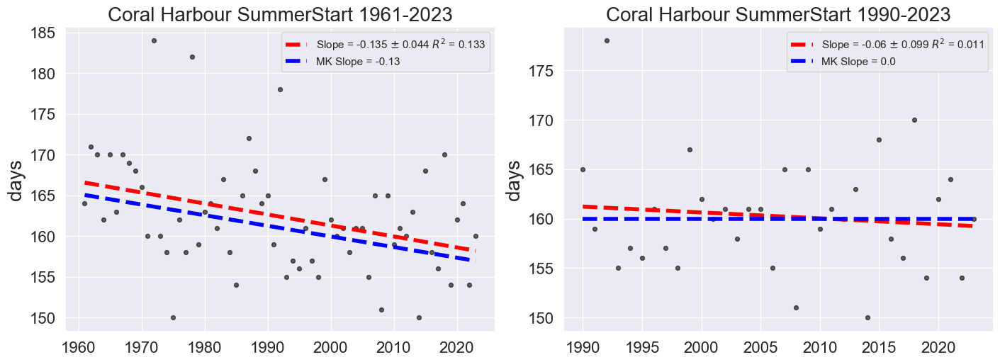

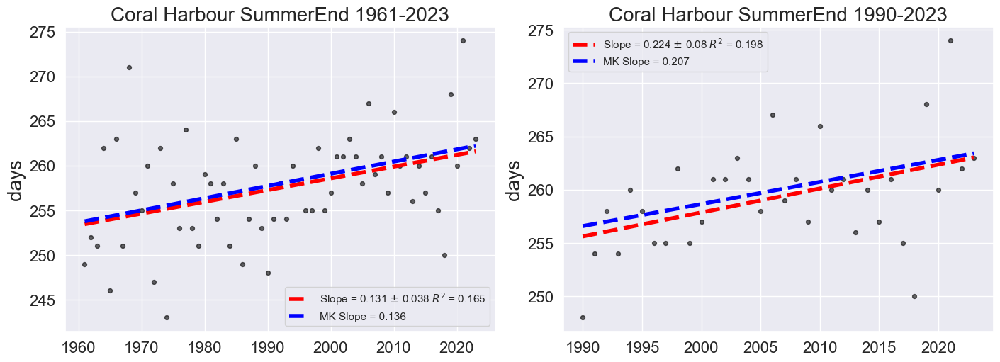

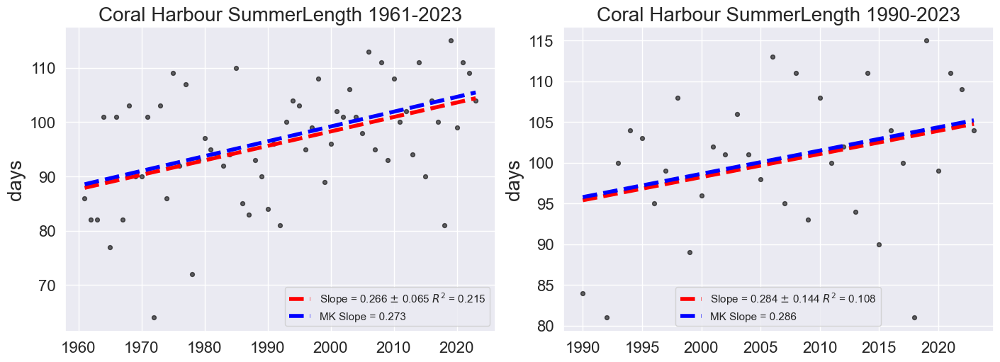

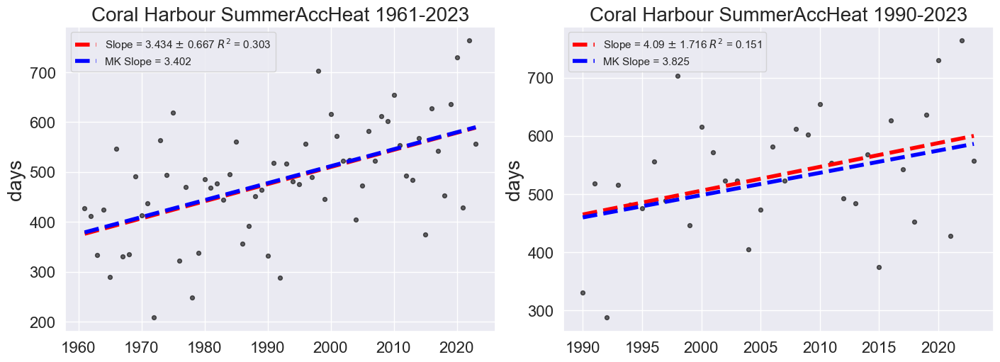

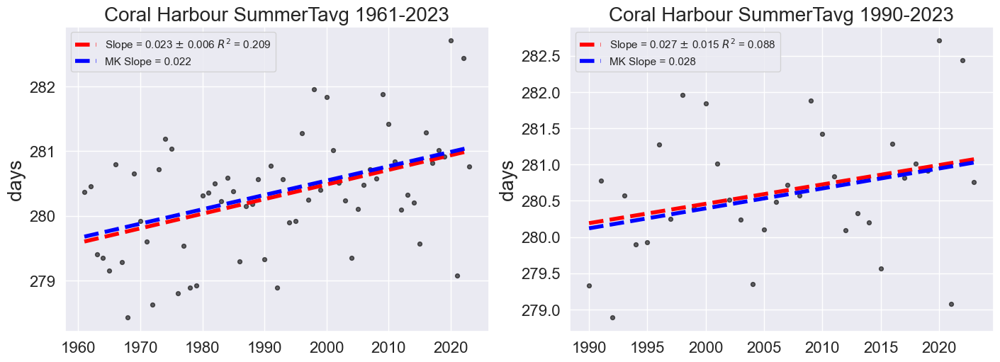

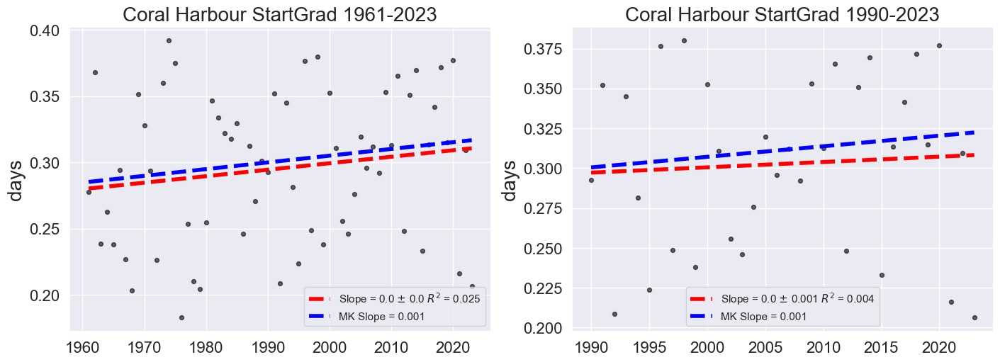

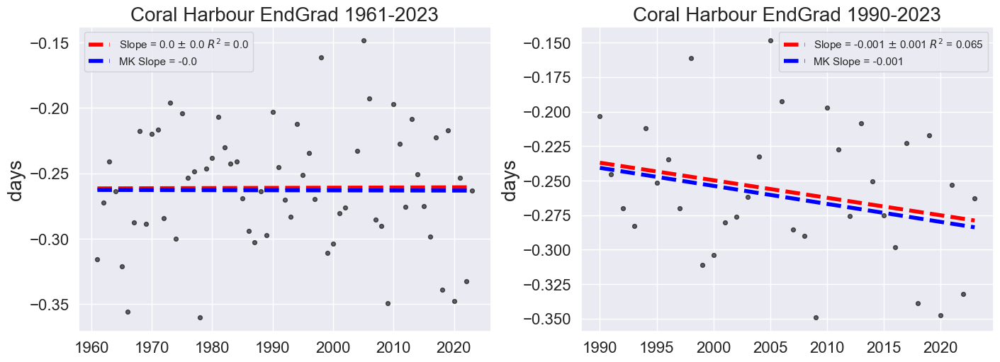

In [35]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Coral Harbour "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Coral Harbour "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

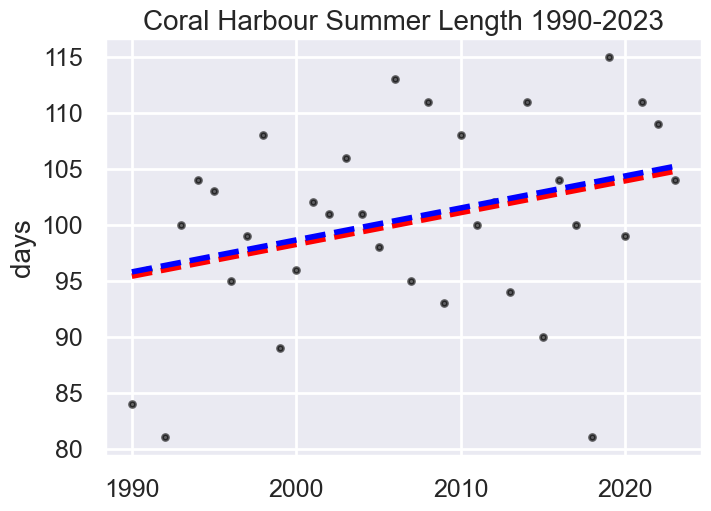

In [36]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Coral Harbour Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/coralharbour_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [406]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 64.25
    lon      float64 8B -83.25
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 64.25
    lon      float64 8B -83.25
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 2.84 +/- 1.44
OLS Slope ERA5: 2.96 +/- 1.56


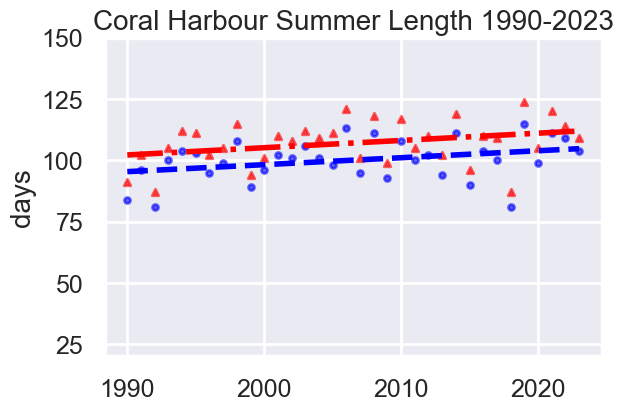

In [407]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Coral Harbour Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(20,150)
plt.savefig("../../../Data/GHCND/Plots/coralharbour_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/coralharbour_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [42]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.108
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     3.881
Date:                Fri, 15 May 2026   Prob (F-statistic):             0.0575
Time:                        15:37:55   Log-Likelihood:                -118.95
No. Observations:                  34   AIC:                             241.9
Df Residuals:                      32   BIC:                             245.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -469.8252    289.289     -1.624      0.1

In [43]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.101
Model:                            OLS   Adj. R-squared:                  0.073
Method:                 Least Squares   F-statistic:                     3.611
Date:                Fri, 15 May 2026   Prob (F-statistic):             0.0664
Time:                        15:37:58   Log-Likelihood:                -121.58
No. Observations:                  34   AIC:                             247.2
Df Residuals:                      32   BIC:                             250.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -486.7377    312.504     -1.558      0.1

#### Accumulated Heat with ERA5 data

OLS Slope: 40.9 +/- 17.16
OLS Slope ERA5: 48.879999999999995 +/- 18.65


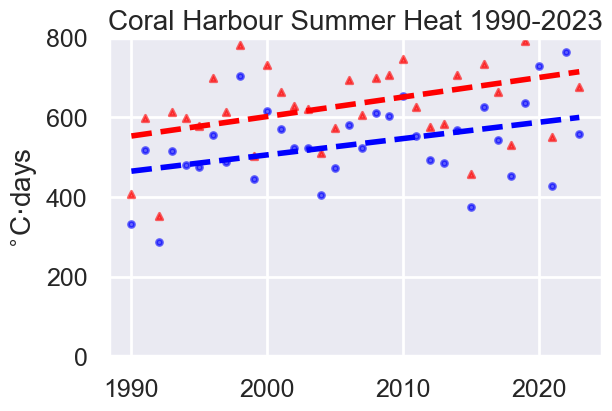

In [408]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Coral Harbour Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,800)
plt.savefig("../../../Data/GHCND/Plots/coralharbour_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/coralharbour_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [46]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.151
Model:                            OLS   Adj. R-squared:                  0.124
Method:                 Least Squares   F-statistic:                     5.679
Date:                Fri, 15 May 2026   Prob (F-statistic):             0.0233
Time:                        15:38:39   Log-Likelihood:                -203.16
No. Observations:                  34   AIC:                             410.3
Df Residuals:                      32   BIC:                             413.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7673.3209   3443.409     -2.228      0.0

In [47]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.177
Model:                            OLS   Adj. R-squared:                  0.151
Method:                 Least Squares   F-statistic:                     6.873
Date:                Fri, 15 May 2026   Prob (F-statistic):             0.0133
Time:                        15:38:41   Log-Likelihood:                -205.98
No. Observations:                  34   AIC:                             416.0
Df Residuals:                      32   BIC:                             419.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -9174.6497   3741.349     -2.452      0.0

#### End Gradient with ERA5 data

In [48]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 64.25
    lon      float64 8B -83.25
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 64.25
    lon      float64 8B -83.25
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.012700000000000001 +/- 0.008499999999999999
OLS Slope ERA5: -0.0062 +/- 0.005999999999999999


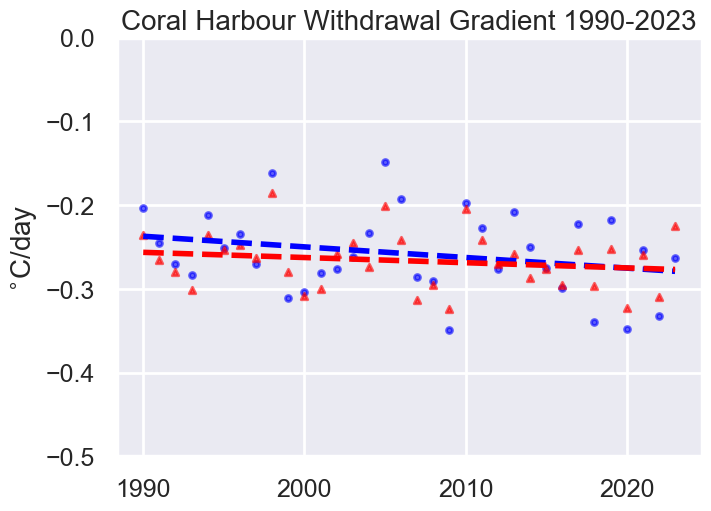

In [50]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Coral Harbour Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.5,0)
plt.savefig("../../../Data/GHCND/Plots/coralharbour_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/coralharbour_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: 0.0033 +/- 0.009600000000000001
OLS Slope ERA5: 0.0060999999999999995 +/- 0.007299999999999999


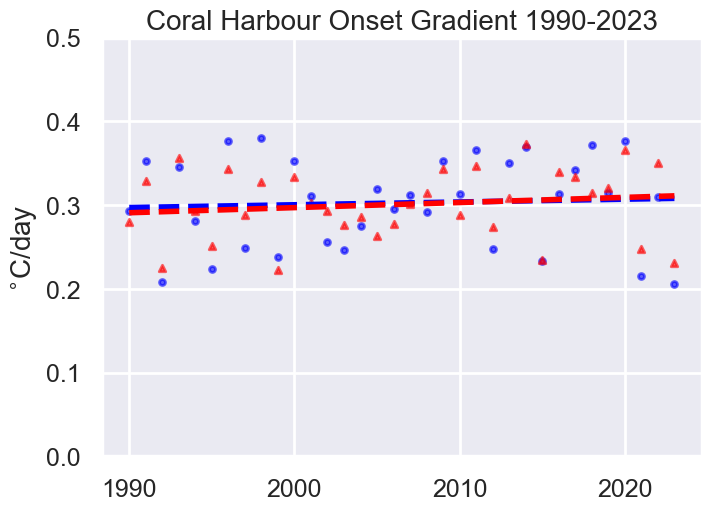

In [52]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Coral Harbour Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.5)
plt.savefig("../../../Data/GHCND/Plots/coralharbour_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/coralharbour_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

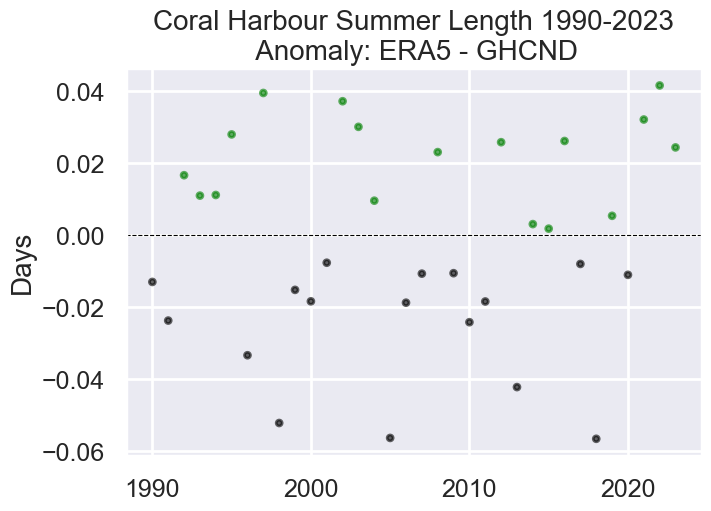

In [53]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Coral Harbour Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

## **Inuvik ** has complete data ?

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:CA002202570/detail

In [410]:

df = pd.read_csv("../../../Data/GHCND/Inuvik-2025-04-30T17-20-54.csv")
#df.reset_index()
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,1961-01-01,-38.1,-36.7,-40.0
1,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,1961-01-02,-39.6,-32.8,-41.7
2,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,1961-01-03,-37.8,-36.1,-41.7
3,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,1961-01-04,-36.4,-29.4,-42.2
4,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,1961-01-05,-30.4,-29.4,-32.8
...,...,...,...,...,...,...,...,...,...
23003,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,2023-12-27,-13.3,NaN,NaN
23004,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,2023-12-28,-17.2,NaN,NaN
23005,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,2023-12-29,-19.1,NaN,NaN
23006,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,2023-12-30,-13.2,NaN,NaN


In [ ]:
df.info()

### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [55]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,1961-01-01,-38.1,-36.7,-40.0
1,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,1961-01-02,-39.6,-32.8,-41.7
2,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,1961-01-03,-37.8,-36.1,-41.7
3,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,1961-01-04,-36.4,-29.4,-42.2
4,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,1961-01-05,-30.4,-29.4,-32.8
...,...,...,...,...,...,...,...,...,...
23003,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,2023-12-27,-13.3,NaN,NaN
23004,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,2023-12-28,-17.2,NaN,NaN
23005,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,2023-12-29,-19.1,NaN,NaN
23006,CA002202570,"INUVIK A, NT CA",68.3,-133.4833,68.0,2023-12-30,-13.2,NaN,NaN


In [56]:
# check counts again
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23008 entries, 0 to 23007
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    23008 non-null  str    
 1   NAME       23008 non-null  str    
 2   LATITUDE   23008 non-null  float64
 3   LONGITUDE  23008 non-null  float64
 4   ELEVATION  23008 non-null  float64
 5   DATE       23008 non-null  str    
 6   TAVG       23008 non-null  float64
 7   TMAX       17687 non-null  float64
 8   TMIN       17669 non-null  float64
dtypes: float64(6), str(3)
memory usage: 2.4 MB


In [57]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,235.05
1961-01-02,233.55
1961-01-03,235.35
1961-01-04,236.75
1961-01-05,242.75
...,...
2023-12-27,259.85
2023-12-28,255.95
2023-12-29,254.05


### Check for missing dates

In [58]:
#df_sub.tail(365)
#df_sub.loc['2020-01-01':'2021-12-31'].head(300)

# got help from https://www.geeksforgeeks.org/check-missing-dates-in-pandas/
print(pd.date_range(
  start="1961-01-01", end="2023-12-31").difference(df_sub.index))

DatetimeIndex(['2012-06-25', '2021-02-20'], dtype='datetime64[us]', freq=None)


#### looks like there are two

In [59]:
missingdates = (pd.date_range(start="1961-01-01", end="2023-12-31").difference(df_sub.index))
missingdates, len(missingdates)

(DatetimeIndex(['2012-06-25', '2021-02-20'], dtype='datetime64[us]', freq=None),
 2)

In [60]:
df_missing = pd.DataFrame({'time':pd.to_datetime(missingdates),
                            'tavg':np.repeat(np.nan, len(missingdates))})
df_missing = df_missing.set_index(['time'])
df_missing
                                                 

,tavg
time,
2012-06-25,NaN
2021-02-20,NaN


In [61]:
df_sub = pd.concat([df_sub, df_missing], axis=0).sort_index()
df_sub

,tavg
time,
1961-01-01,235.05
1961-01-02,233.55
1961-01-03,235.35
1961-01-04,236.75
1961-01-05,242.75
...,...
2023-12-27,259.85
2023-12-28,255.95
2023-12-29,254.05


In [62]:
# linear interpolation to fill the last few
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
df_sub.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 23010 entries, 1961-01-01 to 2023-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tavg    23010 non-null  float64
dtypes: float64(1)
memory usage: 359.5 KB


### Convert from Pandas to XArray

In [63]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 368kB
Dimensions:  (time: 23010)
Coordinates:
  * time     (time) datetime64[us] 184kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 184kB 235.0 233.5 235.3 236.7 ... 254.0 259.9 258.5

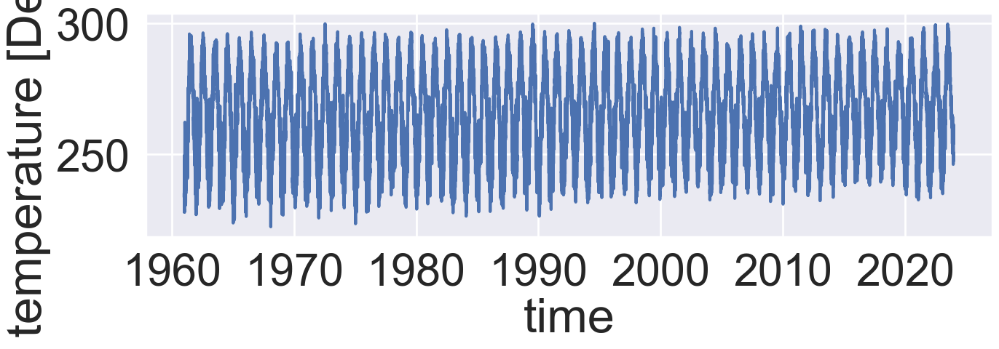

In [64]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

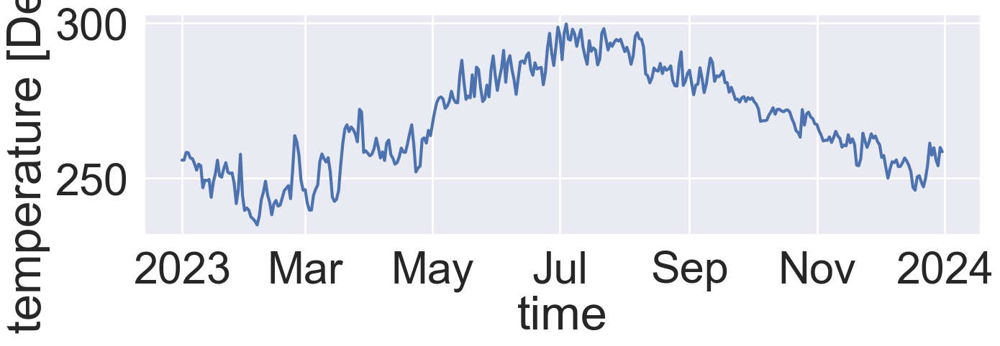

In [65]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('2023','2023')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [66]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(279.176392)
Coordinates:
    lat       float64 8B 68.25
    lon       float64 8B -133.5
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [67]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 3.23 ms, sys: 3.83 ms, total: 7.06 ms
Wall time: 4.28 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(279.8)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [68]:
thresh.values - stp_75.values

np.float64(-0.6236083984374545)

#### Inuvik 75th Percentile from GHCND data is 0.62 K warmer

### Try one year (2023) fit via Fourier

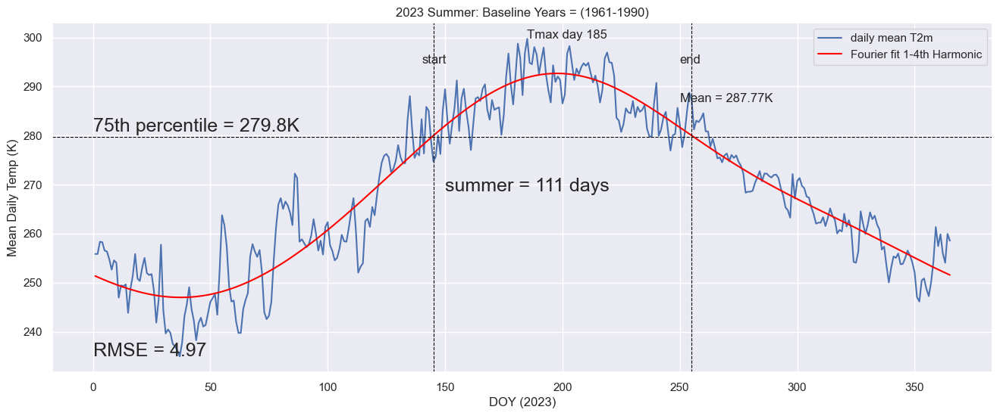

(145,
 255,
 0.4107823033423301,
 -0.32850791069455454,
 185,
 902.0999999999985,
 111,
 4.973687148057897,
 0.0,
 287.7743243243243,
 8.674038461538487)

In [69]:
input_year = 2023

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

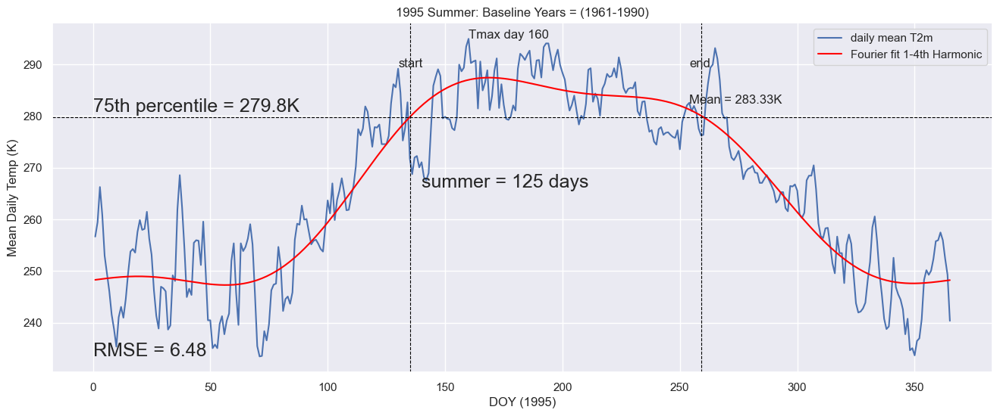

(135,
 259,
 0.457478977634338,
 -0.2789624331378775,
 160,
 592.1500000000015,
 125,
 6.483516637721877,
 0.0,
 283.3332,
 6.806321839080454)

In [70]:
# how about 1995
input_year = 1995
da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Looks to be working! 

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats

In [71]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [72]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 254 ms, sys: 21.5 ms, total: 275 ms
Wall time: 283 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,150,244,0.463952,-0.219098,95,532.55,158,284.932105
1,1962,153,254,0.362726,-0.289888,102,602.60,201,285.084314
2,1963,149,251,0.283392,-0.300239,103,545.30,227,284.540291
3,1964,156,247,0.344062,-0.185838,92,396.55,199,283.391304
4,1965,162,244,0.347511,-0.373895,83,500.30,190,285.470482
...,...,...,...,...,...,...,...,...,...
58,2019,147,249,0.331915,-0.133601,103,465.75,173,283.942233
59,2020,152,252,0.254012,-0.253315,101,501.75,212,284.607426
60,2021,143,257,0.394480,-0.273714,115,701.25,202,285.313478
61,2022,151,253,0.362173,-0.260061,103,652.70,185,285.609223


### write out resulting summer stats

In [73]:
# write out results
output_path = "../../../Data/GHCND/inuvik_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [411]:
# re-load 
input_path = "../../../Data/GHCND/inuvik_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,150,244,0.463952,-0.219098,95,532.55,158,284.932105
1,1,1962,153,254,0.362726,-0.289888,102,602.60,201,285.084314
2,2,1963,149,251,0.283392,-0.300239,103,545.30,227,284.540291
3,3,1964,156,247,0.344062,-0.185838,92,396.55,199,283.391304
4,4,1965,162,244,0.347511,-0.373895,83,500.30,190,285.470482
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,147,249,0.331915,-0.133601,103,465.75,173,283.942233
59,59,2020,152,252,0.254012,-0.253315,101,501.75,212,284.607426
60,60,2021,143,257,0.394480,-0.273714,115,701.25,202,285.313478
61,61,2022,151,253,0.362173,-0.260061,103,652.70,185,285.609223


### Inuvik: Plot the summer stats

In [76]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

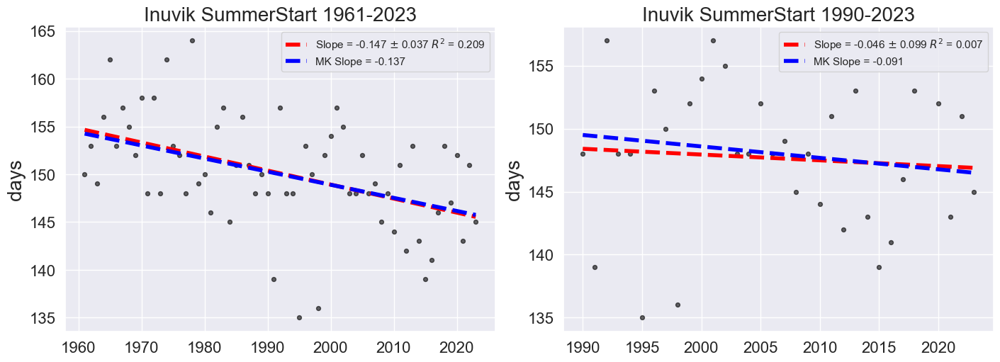

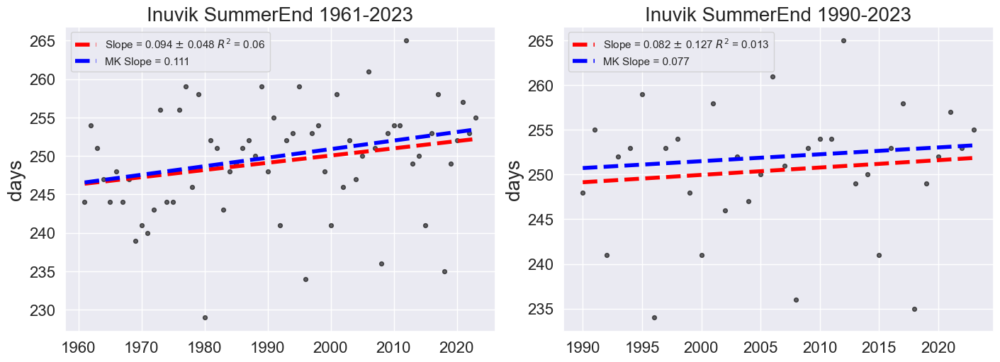

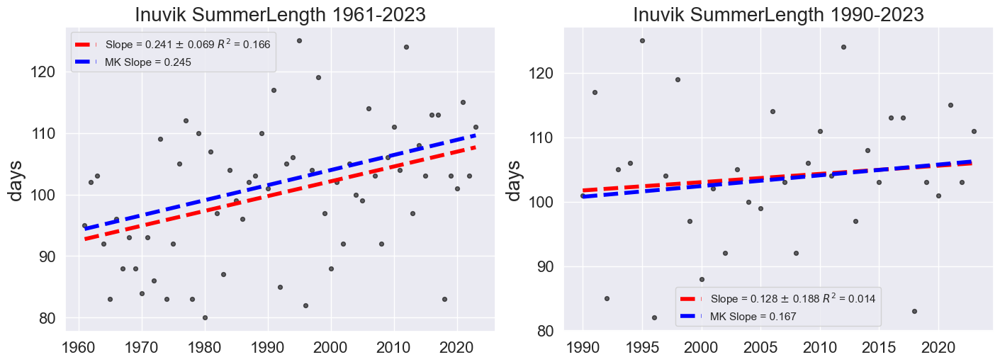

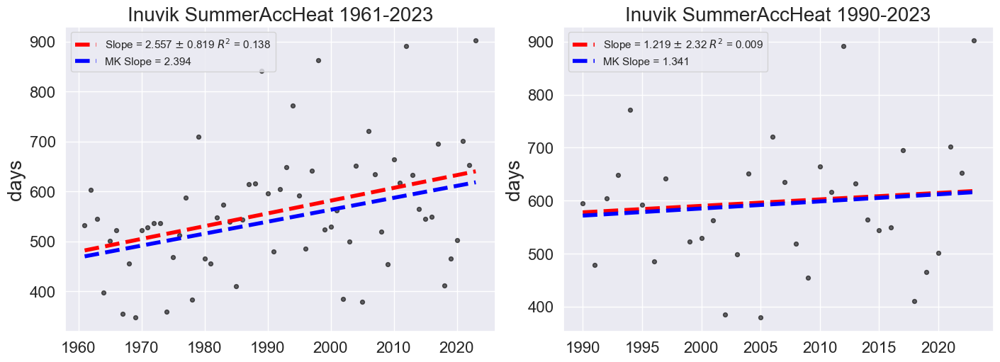

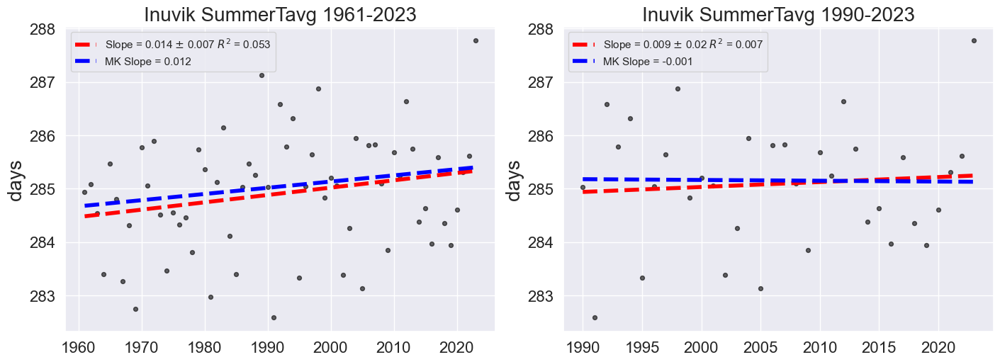

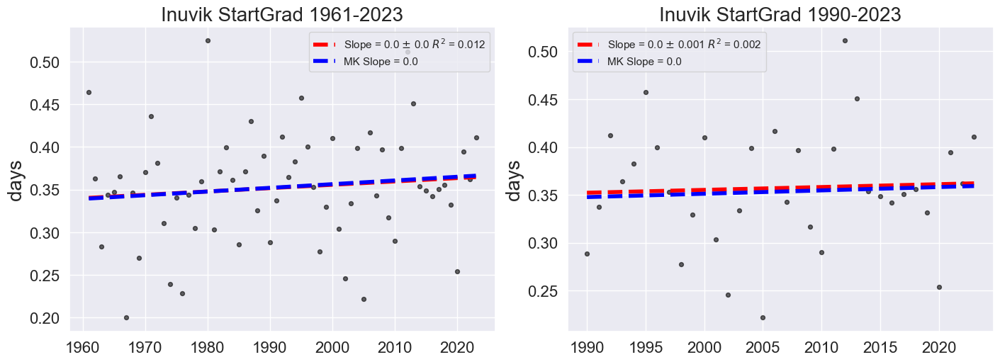

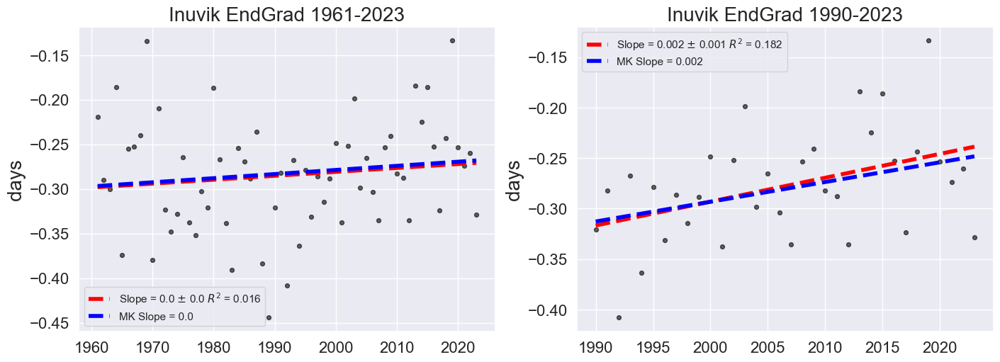

In [77]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Inuvik "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Inuvik "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

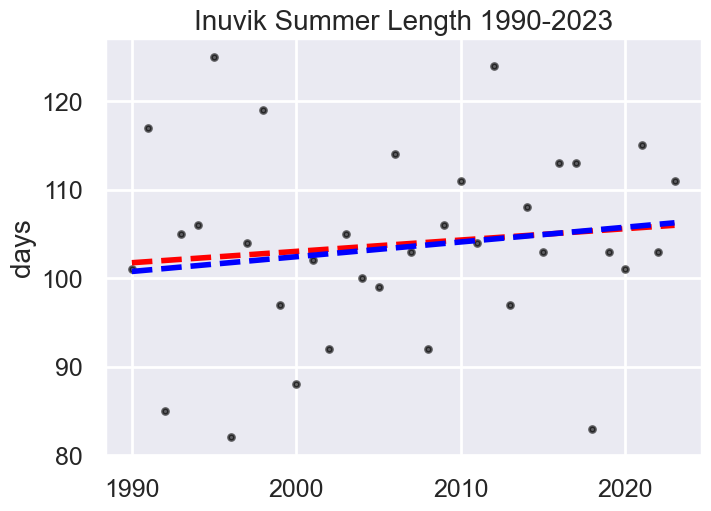

In [78]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Inuvik Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/inuvik_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [412]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 68.25
    lon      float64 8B -133.5
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 68.25
    lon      float64 8B -133.5
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 1.28 +/- 1.88
OLS Slope ERA5: 1.01 +/- 1.85


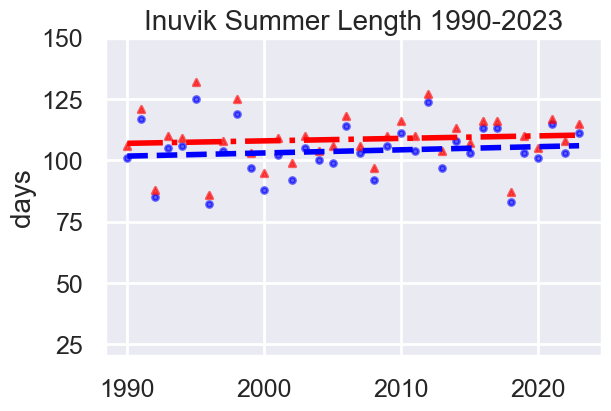

In [413]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Inuvik Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(20,150)
plt.savefig("../../../Data/GHCND/Plots/inuvik_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/inuvik_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [81]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                 -0.016
Method:                 Least Squares   F-statistic:                    0.4673
Date:                Fri, 15 May 2026   Prob (F-statistic):              0.499
Time:                        15:49:57   Log-Likelihood:                -127.89
No. Observations:                  34   AIC:                             259.8
Df Residuals:                      32   BIC:                             262.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -153.3592    376.271     -0.408      0.6

In [82]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                 -0.022
Method:                 Least Squares   F-statistic:                    0.2991
Date:                Fri, 15 May 2026   Prob (F-statistic):              0.588
Time:                        15:50:06   Log-Likelihood:                -127.47
No. Observations:                  34   AIC:                             258.9
Df Residuals:                      32   BIC:                             262.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -94.6382    371.642     -0.255      0.8

#### Accumulated Heat with ERA5 data

OLS Slope: 12.190000000000001 +/- 23.2
OLS Slope ERA5: 9.370000000000001 +/- 24.310000000000002


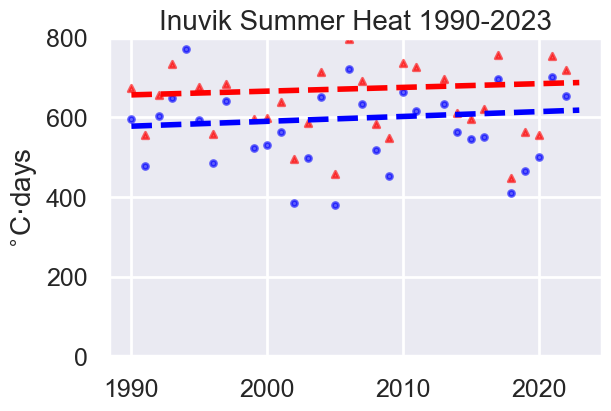

In [414]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Inuvik Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,800)
plt.savefig("../../../Data/GHCND/Plots/inuvik_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/inuvik_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [84]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                 -0.022
Method:                 Least Squares   F-statistic:                    0.2758
Date:                Fri, 15 May 2026   Prob (F-statistic):              0.603
Time:                        15:50:29   Log-Likelihood:                -213.42
No. Observations:                  34   AIC:                             430.8
Df Residuals:                      32   BIC:                             433.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1847.2402   4655.911     -0.397      0.6

In [85]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                 -0.026
Method:                 Least Squares   F-statistic:                    0.1486
Date:                Fri, 15 May 2026   Prob (F-statistic):              0.702
Time:                        15:50:31   Log-Likelihood:                -215.00
No. Observations:                  34   AIC:                             434.0
Df Residuals:                      32   BIC:                             437.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1208.7620   4878.189     -0.248      0.8

#### End Gradient with ERA5 data

In [86]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 68.25
    lon      float64 8B -133.5
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 68.25
    lon      float64 8B -133.5
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: 0.023600000000000003 +/- 0.0089
OLS Slope ERA5: 0.0193 +/- 0.0069


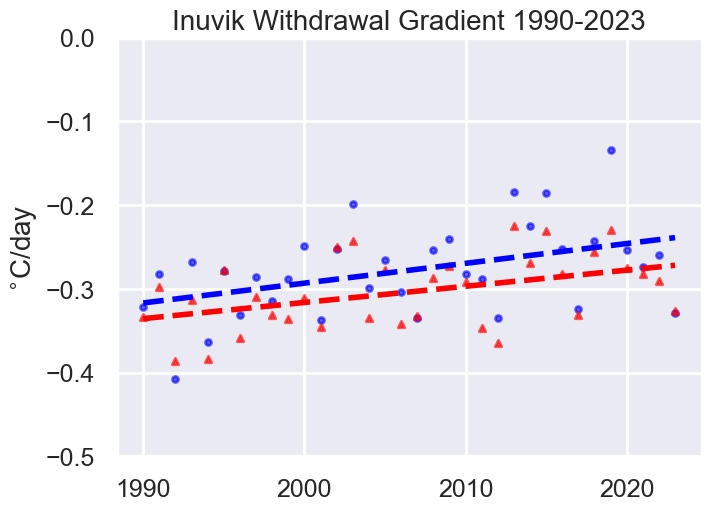

In [87]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Inuvik Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.5,0)
plt.savefig("../../../Data/GHCND/Plots/inuvik_summer_end_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/inuvik_summer_end_grad_plot_wERA5.pdf",bbox_inches='tight')



OLS Slope: 0.0029999999999999996 +/- 0.011000000000000001
OLS Slope ERA5: 0.0017000000000000001 +/- 0.008400000000000001


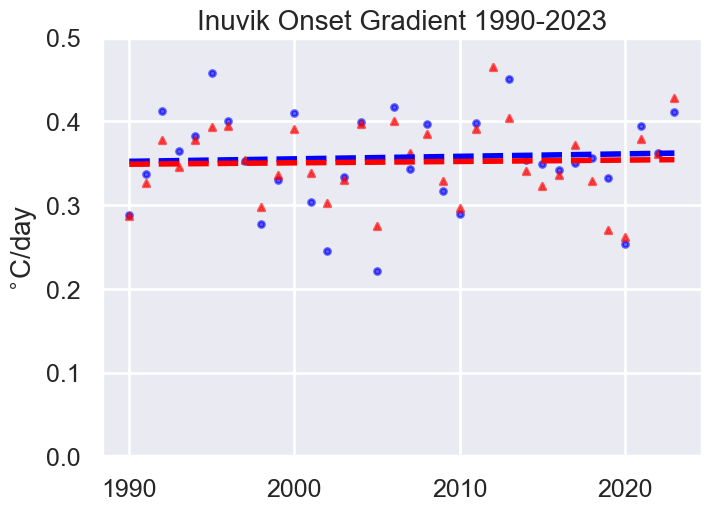

In [88]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Inuvik Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.5)
plt.savefig("../../../Data/GHCND/Plots/inuvik_summer_start_grad_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/inuvik_summer_start_grad_plot_wERA5.pdf",bbox_inches='tight')



### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

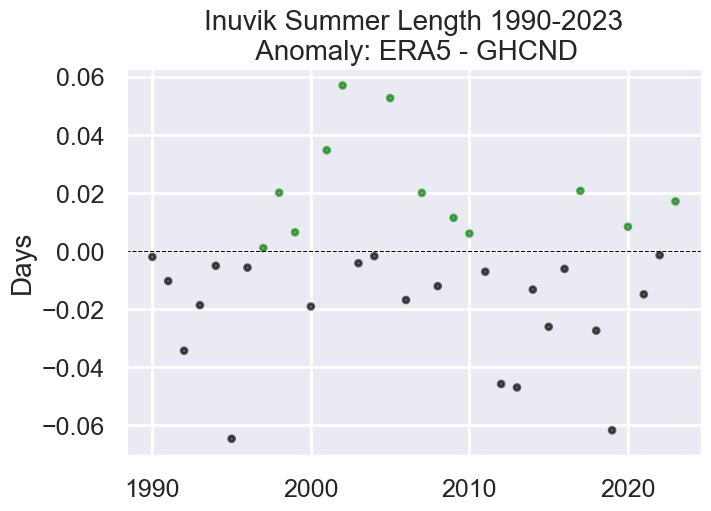

In [89]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Inuvik Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

# **** End High Latitude Canada Sites [not updated] 

# Iceland should show growth

## **Reykjavik ** has complete data 

### https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:IC000004030/detail

In [130]:

df = pd.read_csv("../../../Data/GHCND/reykjavik-2025-04-30T17-34-41.csv")
#df.reset_index()
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,1961-01-01,NaN,4.2,-0.5
1,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,1961-01-02,NaN,4.1,-2.7
2,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,1961-01-03,NaN,5.0,2.7
3,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,1961-01-04,NaN,3.5,0.8
4,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,1961-01-05,NaN,1.8,-5.3
...,...,...,...,...,...,...,...,...,...
23002,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,2023-12-27,-2.8,NaN,NaN
23003,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,2023-12-28,-2.5,-1.9,NaN
23004,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,2023-12-29,-4.2,NaN,NaN
23005,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,2023-12-30,-2.8,NaN,NaN


In [ ]:
df.info()

### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [500]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,1961-01-01,1.85,4.2,-0.5
1,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,1961-01-02,0.70,4.1,-2.7
2,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,1961-01-03,3.85,5.0,2.7
3,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,1961-01-04,2.15,3.5,0.8
4,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,1961-01-05,-1.75,1.8,-5.3
...,...,...,...,...,...,...,...,...,...
23002,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,2023-12-27,-2.80,NaN,NaN
23003,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,2023-12-28,-2.50,-1.9,NaN
23004,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,2023-12-29,-4.20,NaN,NaN
23005,IC000004030,"REYKJAVIK, IC",64.1269,-21.9025,52.0,2023-12-30,-2.80,NaN,NaN


In [ ]:
# check counts again
df.info()

In [501]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,275.00
1961-01-02,273.85
1961-01-03,277.00
1961-01-04,275.30
1961-01-05,271.40
...,...
2023-12-27,270.35
2023-12-28,270.65
2023-12-29,268.95


In [502]:
# linear interpolation to fill the last few
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
df_sub.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 23007 entries, 1961-01-01 to 2023-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tavg    23007 non-null  float64
dtypes: float64(1)
memory usage: 359.5 KB


### Convert from Pandas to XArray

In [503]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 368kB
Dimensions:  (time: 23007)
Coordinates:
  * time     (time) datetime64[ns] 184kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 184kB 275.0 273.8 277.0 275.3 ... 268.9 270.3 268.8

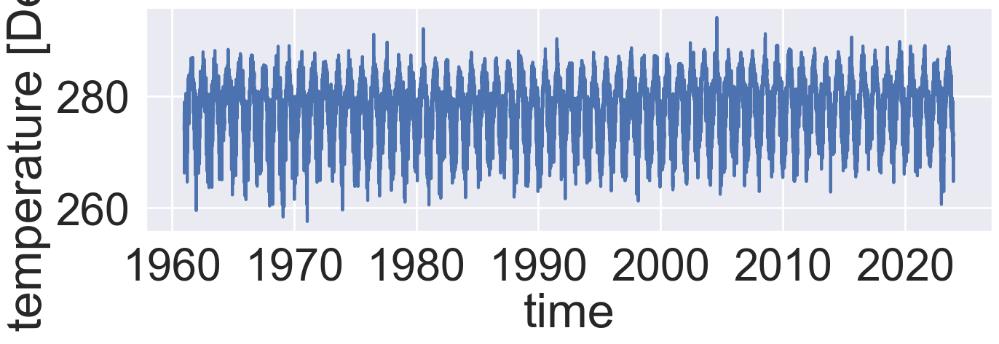

In [504]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

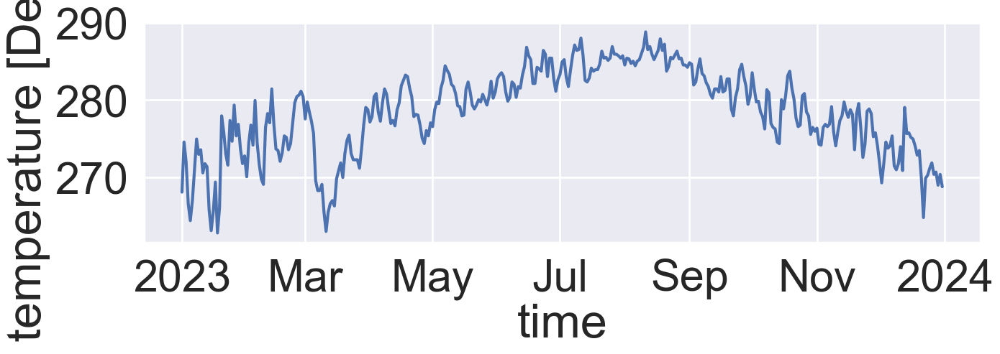

In [505]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('2023','2023')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [506]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(281.347595)
Coordinates:
    lat       float64 8B 64.25
    lon       float64 8B -22.0
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [507]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 2.72 ms, sys: 1.94 ms, total: 4.65 ms
Wall time: 3.14 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(282.35)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [508]:
thresh.values - stp_75.values

np.float64(-1.002404785156216)

#### Reykjavik 75th Percentile from GHCND data is 1 K warmer

### Try one year (2023) fit via Fourier

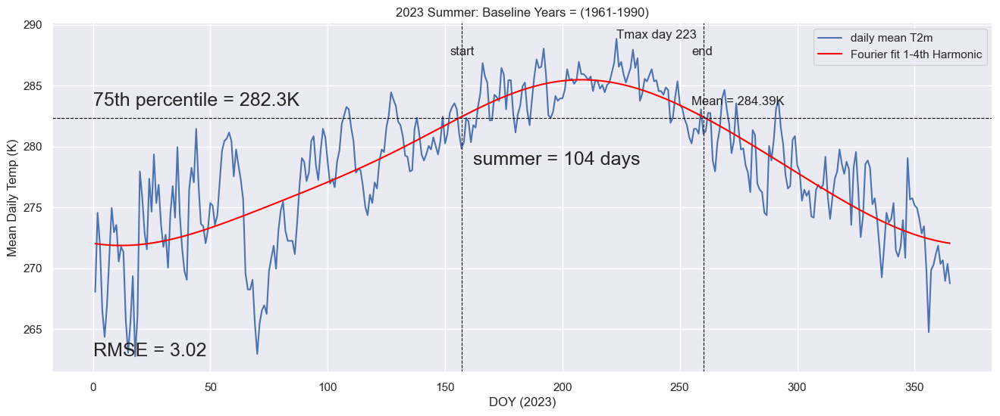

(157,
 260,
 0.09874056684088828,
 -0.10341728691960839,
 223,
 230.50000000000364,
 104,
 3.0164432139638366,
 0.0,
 284.39134615384614,
 2.7117647058823877)

In [511]:
input_year = 2023

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

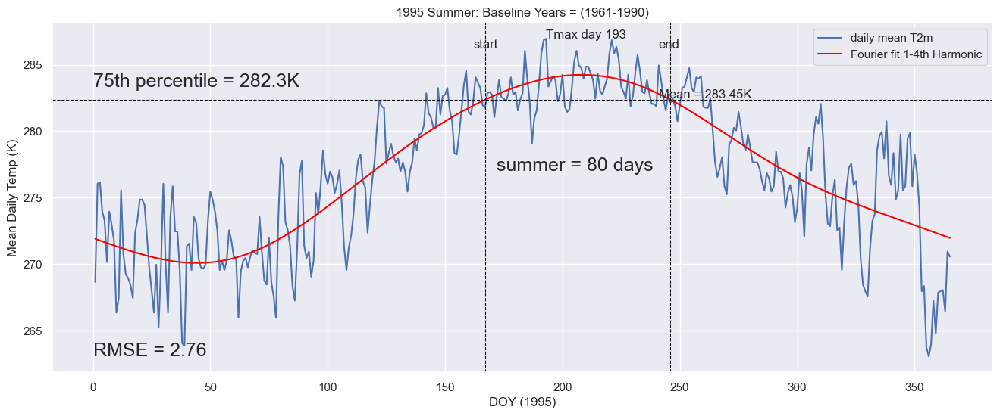

(167,
 246,
 0.0817591869370915,
 -0.09600008386914283,
 193,
 100.5,
 80,
 2.7634386849853136,
 0.0,
 283.44999999999993,
 1.5703125)

In [510]:
# how about 1995
input_year = 1995


da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Looks to be working! 

### Climatology plots, 1961-2023 and 1990-2023

In [512]:
da_daily_clim_full = da_stp.tavg.groupby("time.dayofyear").mean()
da_daily_clim_an = da_stp.tavg.sel(time=slice('1990','2023')).groupby("time.dayofyear").mean()
da_daily_clim_full, da_daily_clim_an


#da_daily_clim_30dayroll = da.DOYClim.rolling(dayofyear=30,center=True, min_periods=2).mean()

(<xarray.DataArray 'tavg' (dayofyear: 366)> Size: 3kB
 array([272.80873016, 273.20952381, 273.05952381, 272.93650794,
        272.9968254 , 273.32698413, 273.46666667, 273.83333333,
        273.42936508, 273.21349206, 273.23809524, 273.27460317,
        273.67380952, 273.25873016, 273.04047619, 272.95238095,
        272.95634921, 272.27380952, 272.88015873, 273.51428571,
        273.60714286, 273.74603175, 273.73730159, 273.63253968,
        273.68492063, 273.30714286, 273.03492063, 273.09285714,
        272.9984127 , 272.72142857, 273.08809524, 272.82539683,
        272.73253968, 272.83095238, 272.63888889, 273.08015873,
        273.24365079, 272.64603175, 273.08095238, 273.40793651,
        273.58015873, 273.74435484, 273.05806452, 273.59761905,
        274.08730159, 273.92936508, 274.18571429, 274.84761905,
        274.46825397, 274.87301587, 274.65322581, 274.02619048,
        273.86507937, 274.22380952, 274.00714286, 274.10873016,
        273.7547619 , 274.00396825, 273.7952381 , 

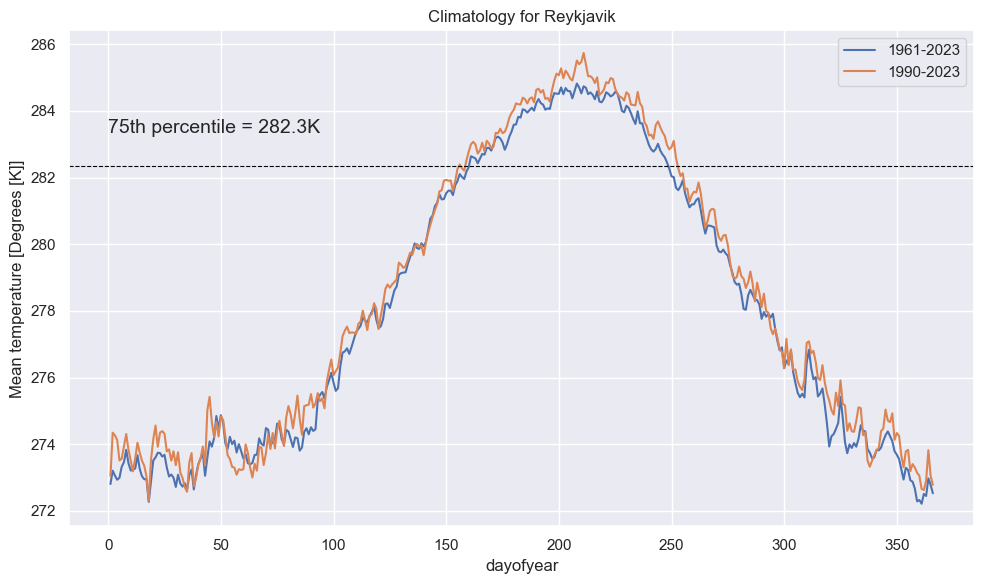

In [513]:
# plot both to compare
plt.figure(figsize=(10,6))
da_daily_clim_full.plot(label='1961-2023')
da_daily_clim_an.plot(label='1990-2023')
plt.axhline(stp_75.values, color="black", linewidth=0.8, linestyle="dashed")
plt.annotate('75th percentile = '+str(np.round(stp_75.values,1))+'K', xy=(0,stp_75.values+1), fontsize=14)
plt.legend()
plt.title("Climatology for Reykjavik")
plt.tight_layout()
plt.show()

### Run through all years now and then uuse ideas from "AnalyzeTrends" script to output the 1961-2023 summer stats aggregated file for analysis

### Main Loop: loop through multiple years to generate summer stats

In [514]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)

process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [515]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



CPU times: user 285 ms, sys: 16 ms, total: 301 ms
Wall time: 319 ms


,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,151,267,0.077688,-0.114953,117,137.95,256,283.332906
1,1962,159,256,0.044345,-0.119675,98,131.45,202,283.429592
2,1963,165,234,0.107974,-0.096191,70,91.50,190,283.474286
3,1964,156,226,0.094147,-0.056529,71,97.25,221,283.524648
4,1965,149,241,0.138692,-0.004724,93,144.70,221,283.571505
5,1966,157,250,0.106181,-0.102036,94,172.65,188,284.007979
6,1967,163,252,0.075573,-0.093619,90,99.25,192,283.138333
7,1968,163,248,0.132459,-0.105822,86,153.85,206,283.963372
8,1969,164,246,0.078050,-0.130211,83,150.35,217,284.121084
9,1970,177,249,0.029712,-0.095368,73,69.85,235,282.942466


### write out resulting summer stats

In [516]:
# write out results
output_path = "../../../Data/GHCND/reykjavik_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [131]:
# re-load 
input_path = "../../../Data/GHCND/reykjavik_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,151,267,0.077688,-0.114953,117,137.95,256,283.332906
1,1,1962,159,256,0.044345,-0.119675,98,131.45,202,283.429592
2,2,1963,165,234,0.107974,-0.096191,70,91.50,190,283.474286
3,3,1964,156,226,0.094147,-0.056529,71,97.25,221,283.524648
4,4,1965,149,241,0.138692,-0.004724,93,144.70,221,283.571505
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,146,260,0.074244,-0.127200,115,230.00,212,284.034348
59,59,2020,152,251,0.082298,-0.091491,100,160.20,172,283.781000
60,60,2021,166,255,0.122034,-0.136950,90,226.50,233,284.800000
61,61,2022,149,256,0.074869,-0.053850,108,141.60,253,283.532407


### Reykjavik: Plot the summer stats

In [518]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

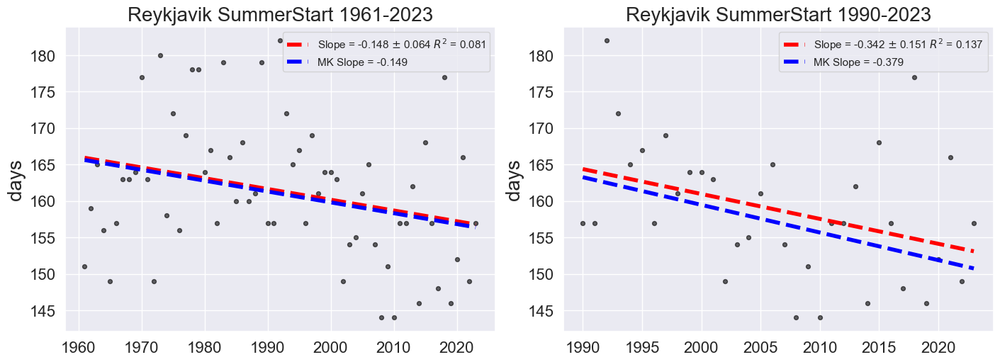

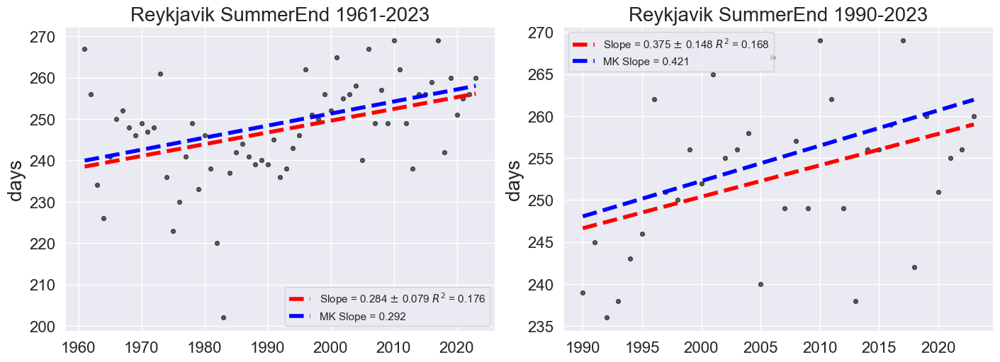

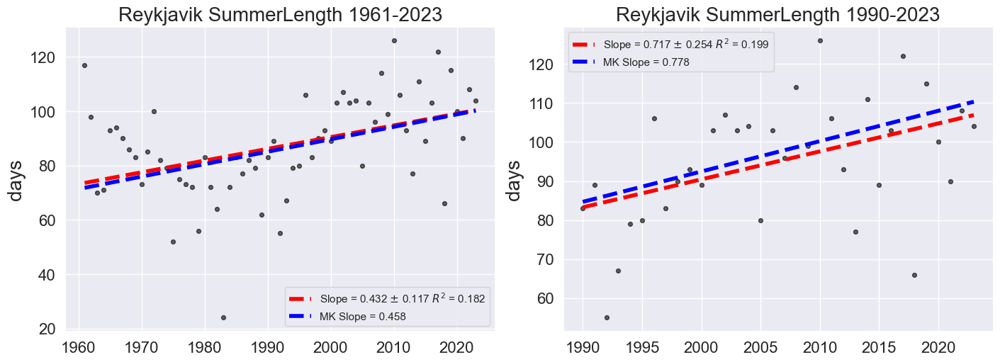

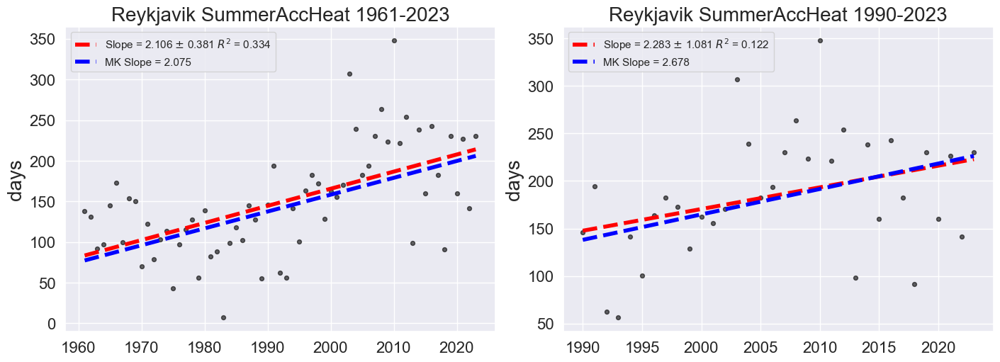

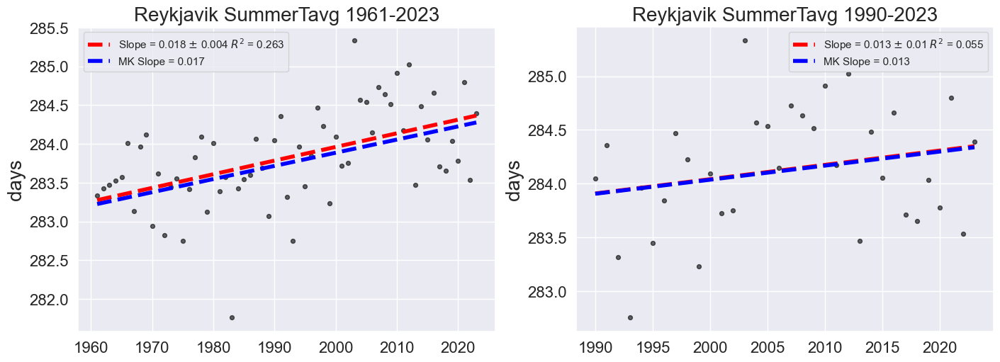

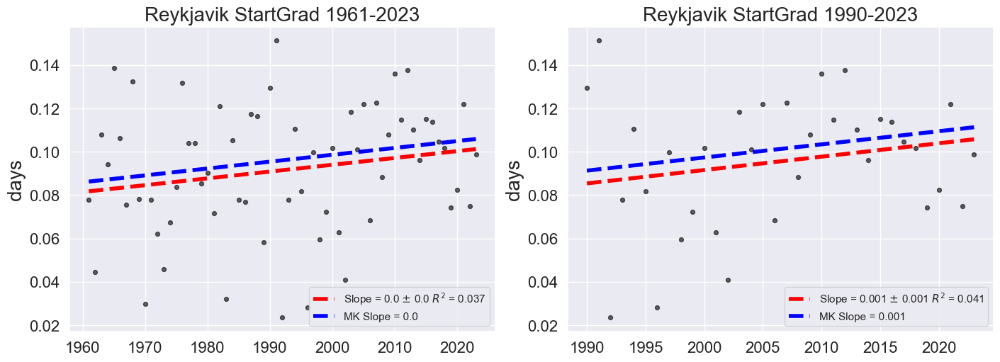

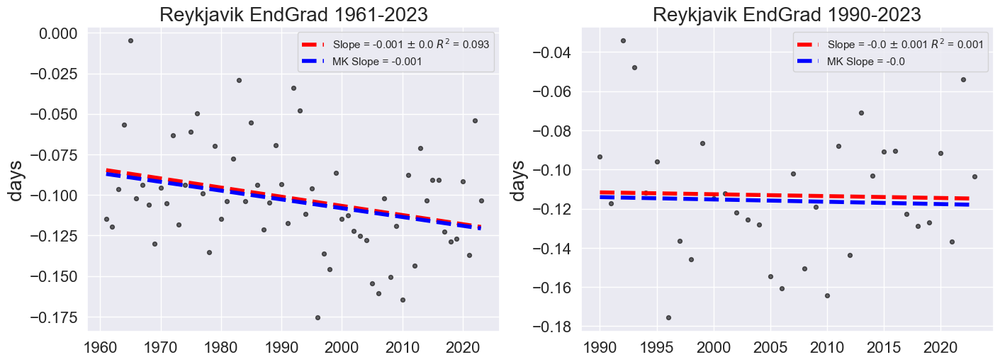

In [122]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Reykjavik "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Reykjavik "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

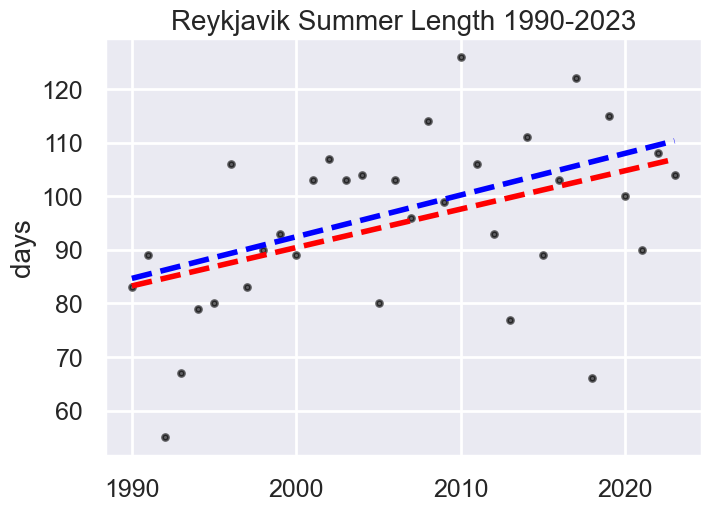

In [123]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Reykjavik Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/reykjavik_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [132]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 64.25
    lon      float64 8B -22.0
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 64.25
    lon      float64 8B -22.0
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 7.17 +/- 2.54
OLS Slope ERA5: 2.49 +/- 2.54


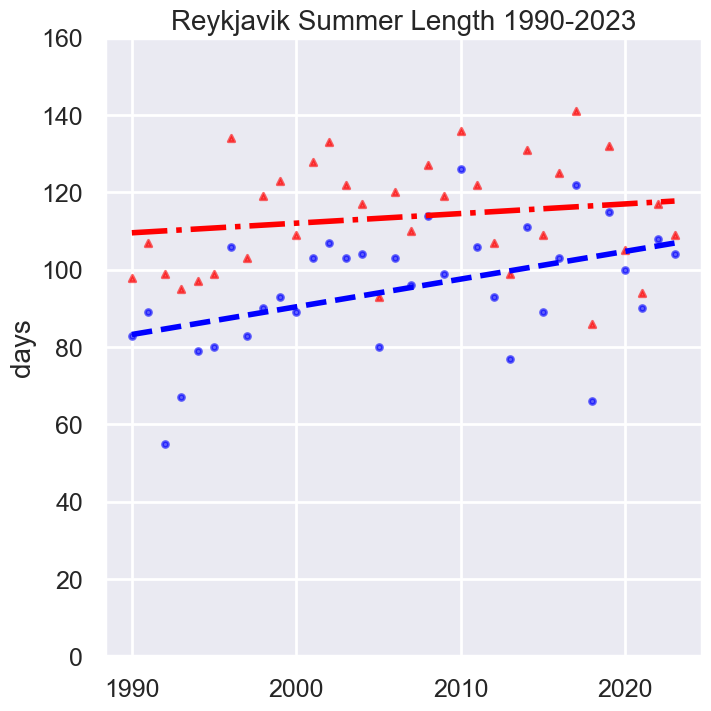

In [133]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,7), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Reykjavik Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(0,160)
plt.savefig("../../../Data/GHCND/Plots/reykjavik_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/reykjavik_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [134]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.199
Model:                            OLS   Adj. R-squared:                  0.174
Method:                 Least Squares   F-statistic:                     7.970
Date:                Wed, 11 Feb 2026   Prob (F-statistic):            0.00811
Time:                        10:50:46   Log-Likelihood:                -138.19
No. Observations:                  34   AIC:                             280.4
Df Residuals:                      32   BIC:                             283.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1343.0312    509.413     -2.636      0.0

In [135]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.9573
Date:                Wed, 11 Feb 2026   Prob (F-statistic):              0.335
Time:                        10:50:48   Log-Likelihood:                -138.26
No. Observations:                  34   AIC:                             280.5
Df Residuals:                      32   BIC:                             283.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -385.7259    510.434     -0.756      0.4

#### Accumulated Heat with ERA5 data

OLS Slope: 22.83 +/- 10.809999999999999
OLS Slope ERA5: 13.83 +/- 13.25


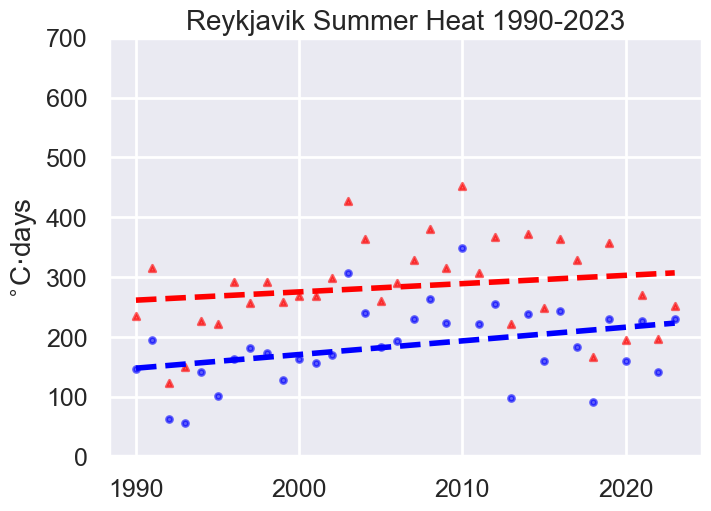

In [136]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Reykjavik Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/reykjavik_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/reykjavik_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [137]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.122
Model:                            OLS   Adj. R-squared:                  0.095
Method:                 Least Squares   F-statistic:                     4.462
Date:                Wed, 11 Feb 2026   Prob (F-statistic):             0.0426
Time:                        10:51:02   Log-Likelihood:                -187.45
No. Observations:                  34   AIC:                             378.9
Df Residuals:                      32   BIC:                             381.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -4396.2032   2169.043     -2.027      0.0

In [138]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.033
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     1.091
Date:                Wed, 11 Feb 2026   Prob (F-statistic):              0.304
Time:                        10:51:04   Log-Likelihood:                -194.36
No. Observations:                  34   AIC:                             392.7
Df Residuals:                      32   BIC:                             395.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2491.2701   2657.674     -0.937      0.3

#### End Gradient with ERA5 data

In [171]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 64.25
    lon      float64 8B -22.0
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
    lat      float64 8B 64.25
    lon      float64 8B -22.0
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.001 +/- 0.0058
OLS Slope ERA5: 0.0017000000000000001 +/- 0.0044


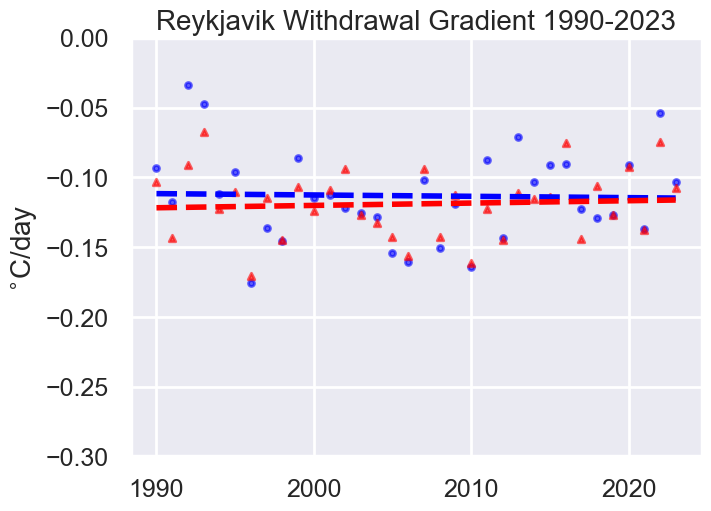

In [172]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Reykjavik Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/reykjavik_summer_end_grad_plot_wERA5.png", bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/reykjavik_summer_end_grad_plot_wERA5.pdf", bbox_inches='tight')



OLS Slope: 0.0062 +/- 0.0053
OLS Slope ERA5: -0.005900000000000001 +/- 0.0031


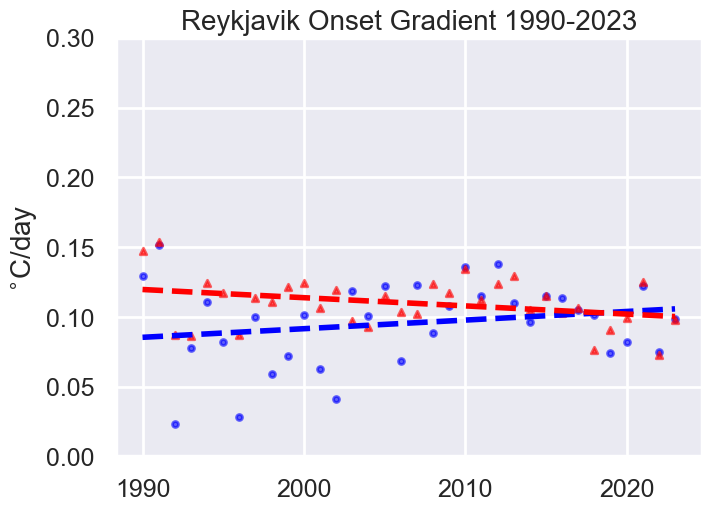

In [173]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Reykjavik Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/reykjavik_summer_start_grad_plot_wERA5.png", bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/reykjavik_summer_start_grad_plot_wERA5.pdf", bbox_inches='tight')




### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

Text(0, 0.5, 'Days')

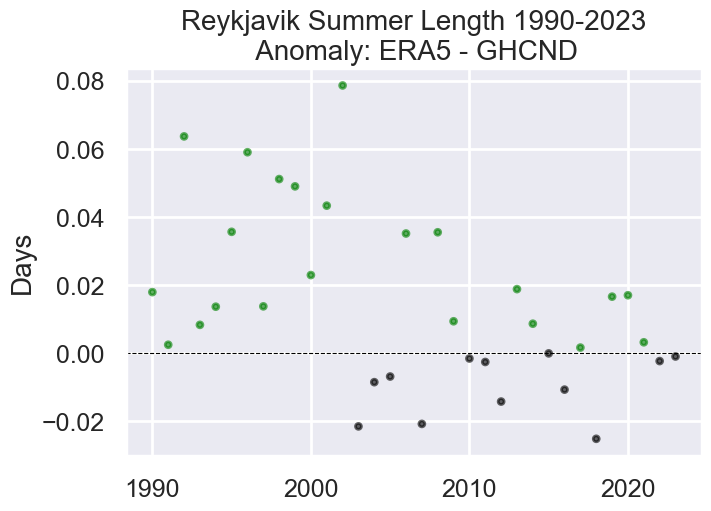

In [527]:
fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)

# ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
diff = y_era - y

ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

ax2.set_title("Reykjavik Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('Days', fontsize=fs)

# Notes from comparing ERA5 to GHCND data

## Site comparisons:
### Summer Length Trends
- St Petersburg OLS Slope: 4.37 +/- 1.92, OLS Slope ERA5: 10.67 +/- 1.73 ***
- New York (not in paper): OLS Slope: 3.31 +/- 1.73, OLS Slope ERA5: 1.1 +/- 1.43 
- Cordoba: OLS Slope: 2.98 +/- 4.01, OLS Slope ERA5: 10.42 +/- 3.42 
- Upington: OLS Slope: 3.05 +/- 4.55, OLS Slope ERA5: 12.19 +/- 3.68 ***
- Paris: OLS Slope: 7.12 +/- 2.03, OLS Slope ERA5: 8.18 +/- 2.11
- Minneapolis: OLS Slope: 9.32 +/- 2.19, OLS Slope ERA5: 6.79 +/- 1.80
- Sydney: OLS Slope: 14.75 +/- 3.86, OLS Slope ERA5: 11.0 +/- 3.09
- Tokyo: OLS Slope: 2.06 +/- 1.42, OLS Slope ERA5: 4.70 +/- 1.2 ***
- Toronto: OLS Slope: 8.37 +/- 2.11, OLS Slope ERA5: 5.5 +/- 1.99
- Bellingham: OLS Slope: 6.11 +/- 2.53, OLS Slope ERA5: 3.72 +/- 1.95
- Rekjavik: OLS Slope: 7.17 +/- 2.54, OLS Slope ERA5: 2.49 +/- 2.54

St Petersburg, Upington, and Tokyo have slopes that differ by 1 SE but the slopes would be within the 95% conf bands on each (2*SE)

### Summer Heat Trends
- St Petersburg OLS Slope: 32.38 +/- 17.55, OLS Slope ERA5: 104.59 +/- 16.39
- New York (not in paper): OLS Slope: 23.07 +/- 12.95, OLS Slope ERA5: 33.63 +/- 11.41
- Cordoba: OLS Slope: 17.89 +/- 10.2, OLS Slope ERA5: 48.25 +/- 9.81 
- Upington: OLS Slope: -2.81 +/- 15.89, OLS Slope ERA5: 36.34 +/- 13.20
- Paris: OLS Slope: 49.91 +/- 16.04, OLS Slope ERA5: 64.44 +/- 14.42
- Minneapolis: OLS Slope: 67.62 +/- 16.79, OLS Slope ERA5: 56.26 +/- 16.0
- Sydney: OLS Slope: 37.94 +/- 12.11, OLS Slope ERA5: 28.0 +/- 10.14
- Tokyo: OLS Slope: 17.75 +/- 15.07, OLS Slope ERA5: 40.34 +/- 14.85
- Toronto: OLS Slope: 57.91 +/- 18.65, OLS Slope ERA5: 33.56 +/- 17.43
- Bellingham: OLS Slope: 39.08 +/- 11.89, OLS Slope ERA5: 30.42 +/- 9.73
- Rekjavik: OLS Slope: 22.83 +/- 10.81, OLS Slope ERA5: 13.83 +/- 13.25

In [ ]:
# MK trend to ERA5
# res_mk_era = mk.original_test(y_era)
# mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
# print("MK Slope ERA5: "+str(res_mk_era.slope*10))
# ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

# *** Adding more Canadian Cities for CMOS 2026

# Montreal has one location with data up to March 2021

#### sites are CA007024745 and CA007025280

In [8]:
df1 = pd.read_csv("../../../Data/GHCND/api_downloads/montreal1-2026-05-18T16-49-49.csv")
df2 = pd.read_csv("../../../Data/GHCND/api_downloads/montreal2-2026-05-18T16-50-55.csv")
#df.reset_index()
df = pd.concat([df2, df1], axis=0, ignore_index=True)
#df.reset_index()
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA007025280,"MONTREAL MCGILL, QC CA",45.5,-73.5833,57.0,1961-01-01,NaN,-7.2,-12.2
1,CA007025280,"MONTREAL MCGILL, QC CA",45.5,-73.5833,57.0,1961-01-02,NaN,-8.9,-11.1
2,CA007025280,"MONTREAL MCGILL, QC CA",45.5,-73.5833,57.0,1961-01-03,NaN,-8.9,-12.8
3,CA007025280,"MONTREAL MCGILL, QC CA",45.5,-73.5833,57.0,1961-01-04,NaN,-8.9,-13.3
4,CA007025280,"MONTREAL MCGILL, QC CA",45.5,-73.5833,57.0,1961-01-05,NaN,-9.4,-16.1
...,...,...,...,...,...,...,...,...,...
21644,CA007024745,"MCTAVISH, QC CA",45.5,-73.5833,73.0,2023-12-27,2.3,3.6,1.0
21645,CA007024745,"MCTAVISH, QC CA",45.5,-73.5833,73.0,2023-12-28,2.0,3.2,0.9
21646,CA007024745,"MCTAVISH, QC CA",45.5,-73.5833,73.0,2023-12-29,1.3,2.0,0.5
21647,CA007024745,"MCTAVISH, QC CA",45.5,-73.5833,73.0,2023-12-30,-1.7,1.1,-4.5


In [94]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21649 entries, 0 to 21648
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    21649 non-null  str    
 1   NAME       21649 non-null  str    
 2   LATITUDE   21649 non-null  float64
 3   LONGITUDE  21649 non-null  float64
 4   ELEVATION  21649 non-null  float64
 5   DATE       21649 non-null  str    
 6   TAVG       3142 non-null   float64
 7   TMAX       21453 non-null  float64
 8   TMIN       21399 non-null  float64
dtypes: float64(6), str(3)
memory usage: 2.3 MB


### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [210]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA007025280,"MONTREAL MCGILL, QC CA",45.5,-73.5833,57.0,1961-01-01,-9.70,-7.2,-12.2
1,CA007025280,"MONTREAL MCGILL, QC CA",45.5,-73.5833,57.0,1961-01-02,-10.00,-8.9,-11.1
2,CA007025280,"MONTREAL MCGILL, QC CA",45.5,-73.5833,57.0,1961-01-03,-10.85,-8.9,-12.8
3,CA007025280,"MONTREAL MCGILL, QC CA",45.5,-73.5833,57.0,1961-01-04,-11.10,-8.9,-13.3
4,CA007025280,"MONTREAL MCGILL, QC CA",45.5,-73.5833,57.0,1961-01-05,-12.75,-9.4,-16.1
...,...,...,...,...,...,...,...,...,...
21644,CA007024745,"MCTAVISH, QC CA",45.5,-73.5833,73.0,2023-12-27,2.30,3.6,1.0
21645,CA007024745,"MCTAVISH, QC CA",45.5,-73.5833,73.0,2023-12-28,2.00,3.2,0.9
21646,CA007024745,"MCTAVISH, QC CA",45.5,-73.5833,73.0,2023-12-29,1.30,2.0,0.5
21647,CA007024745,"MCTAVISH, QC CA",45.5,-73.5833,73.0,2023-12-30,-1.70,1.1,-4.5


In [96]:
# check counts again
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21649 entries, 0 to 21648
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    21649 non-null  str    
 1   NAME       21649 non-null  str    
 2   LATITUDE   21649 non-null  float64
 3   LONGITUDE  21649 non-null  float64
 4   ELEVATION  21649 non-null  float64
 5   DATE       21649 non-null  str    
 6   TAVG       21358 non-null  float64
 7   TMAX       21453 non-null  float64
 8   TMIN       21399 non-null  float64
dtypes: float64(6), str(3)
memory usage: 2.3 MB


In [211]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,263.45
1961-01-02,263.15
1961-01-03,262.30
1961-01-04,262.05
1961-01-05,260.40
...,...
2023-12-27,275.45
2023-12-28,275.15
2023-12-29,274.45


#### dealing with some of the missing dates

In [212]:
#df_sub.tail(365)
#df_sub.loc['2020-01-01':'2021-12-31'].head(300)
start = "2000-01-01"
end = "2023-12-31"

# got help from https://www.geeksforgeeks.org/check-missing-dates-in-pandas/
print(pd.date_range(
  start=start, end=end).difference(df_sub.index))

print(pd.date_range(
  start=start, end=end).difference(df_sub.index).size)

DatetimeIndex(['2000-09-16', '2001-02-09', '2003-01-24', '2003-01-25',
               '2003-01-31', '2004-01-30', '2004-04-23', '2006-10-30',
               '2007-01-22', '2007-03-03', '2007-12-01', '2009-09-09',
               '2009-09-24', '2009-09-25', '2010-01-13', '2010-01-14',
               '2010-05-19', '2010-06-10', '2012-10-17', '2013-10-10',
               '2014-03-09', '2014-03-10', '2014-03-11', '2014-03-12',
               '2014-03-13', '2014-03-14', '2014-03-15', '2014-03-16',
               '2014-03-17', '2014-05-29', '2014-05-30', '2014-05-31',
               '2014-06-01', '2014-06-02', '2014-06-03', '2014-06-04',
               '2014-06-05', '2014-06-06', '2014-06-07', '2014-06-08',
               '2014-06-09', '2014-06-10', '2014-06-11', '2014-06-12',
               '2014-06-13', '2014-06-14', '2014-06-15', '2014-06-16',
               '2014-06-17', '2014-06-18', '2014-06-19', '2014-06-20',
               '2014-06-21', '2014-06-22', '2014-06-23', '2014-06-24',
      

In [216]:
df_missing = pd.DataFrame({'time':pd.to_datetime(['2000-09-16', '2001-02-09', '2003-01-24', '2003-01-25',
               '2003-01-31', '2004-01-30', '2004-04-23', '2006-10-30',
               '2007-01-22', '2007-03-03', '2007-12-01', '2009-09-09',
               '2009-09-24', '2009-09-25', '2010-01-13', '2010-01-14',
               '2010-05-19', '2010-06-10', '2012-10-17', '2013-10-10',
               '2015-01-06', '2015-01-07', '2015-06-01',
               '2015-06-02', '2017-02-27', '2017-02-28', '2017-03-01',
               '2017-03-02', '2017-03-03', '2018-07-24', '2018-07-27',
               '2018-10-15', '2018-11-01', '2019-10-16', '2020-06-10',
               '2020-09-11', '2021-07-15', '2021-09-16', '2022-07-15',
               '2022-11-25', '2022-11-26', '2022-11-27', '2022-11-28',
               '2023-05-17', '2023-06-05']),
                            'tavg':np.repeat(np.nan, 45)})
df_missing = df_missing.set_index(['time'])
df_missing
                                                 

,tavg
time,
2000-09-16,NaN
2001-02-09,NaN
2003-01-24,NaN
2003-01-25,NaN
2003-01-31,NaN
2004-01-30,NaN
2004-04-23,NaN
2006-10-30,NaN
2007-01-22,NaN


In [217]:
df_sub = pd.concat([df_sub, df_missing], axis=0).sort_index()
df_sub

,tavg
time,
1961-01-01,263.45
1961-01-02,263.15
1961-01-03,262.30
1961-01-04,262.05
1961-01-05,260.40
...,...
2023-12-27,275.45
2023-12-28,275.15
2023-12-29,274.45


In [218]:
# linear interpolation to fill the missing ones
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
print(df_sub[df_sub.isna().any(axis=1)])

Empty DataFrame
Columns: [tavg]
Index: []


#### all cleaned up!

In [219]:
# linear interpolation to fill the last few
#df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
df_sub.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 21694 entries, 1961-01-01 to 2023-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tavg    21694 non-null  float64
dtypes: float64(1)
memory usage: 339.0 KB


### Convert from Pandas to XArray

In [220]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 347kB
Dimensions:  (time: 21694)
Coordinates:
  * time     (time) datetime64[us] 174kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 174kB 263.4 263.1 262.3 262.0 ... 274.4 271.4 268.0

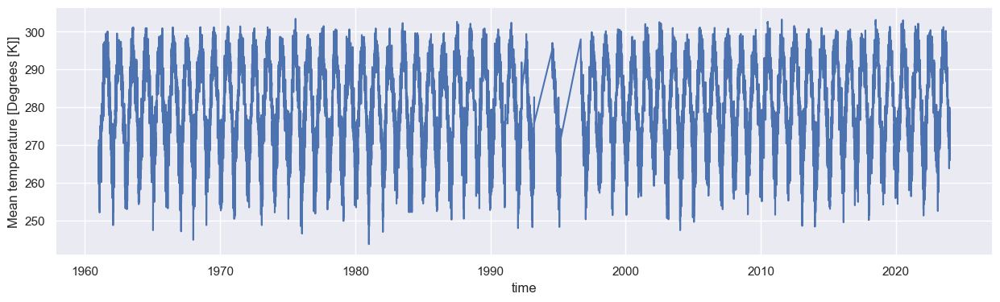

In [221]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

#### look at those missing years

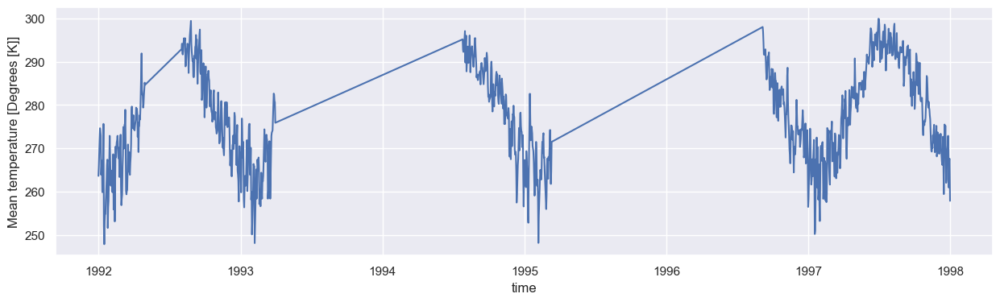

In [222]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1992','1997')).plot()

#### those are funky but the fourier fit might do well enough or I can interpolate later

### Calculate the threshold temp from 1961-1990, 75%-ile

In [223]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(289.870331)
Coordinates:
    lat       float64 8B 45.5
    lon       float64 8B -73.5
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [224]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 2.02 ms, sys: 7.01 ms, total: 9.03 ms
Wall time: 8.21 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(291.15)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [225]:
thresh.values - stp_75.values

np.float64(-1.2796691894531023)

#### Montreal 75th Percentile from GHCND data is 1.3 K warmer

### Try one year (2023) fit via Fourier

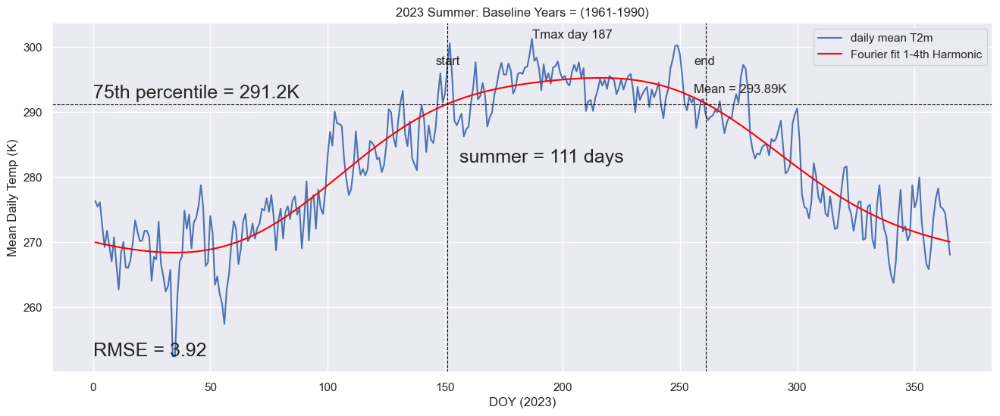

(151,
 261,
 0.14515878658372117,
 -0.1974935334200154,
 187,
 348.1999999999971,
 111,
 3.9198166860666337,
 0.0,
 293.8896396396396,
 3.8688888888888187)

In [226]:
input_year = 2023

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Main Loop: loop through multiple years to generate summer stats. Dropping 1990 and 1991, 1994, 1995, 1996

In [227]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 1990,1)
process_yrs2 = np.arange(1992,1994,1)
process_yrs3 = np.arange(1997,2024,1)

process_yrs_tmp = np.append(process_yrs, process_yrs2)
process_yrs = np.append(process_yrs_tmp, process_yrs3)
process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1992, 1993, 1997, 1998,
       1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009,
       2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020,
       2021, 2022, 2023])

In [228]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    print("Processing year: "+str(input_year))
    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



Processing year: 1961
Processing year: 1962
Processing year: 1963
Processing year: 1964
Processing year: 1965
Processing year: 1966
Processing year: 1967
Processing year: 1968
Processing year: 1969
Processing year: 1970
Processing year: 1971
Processing year: 1972
Processing year: 1973
Processing year: 1974
Processing year: 1975
Processing year: 1976
Processing year: 1977
Processing year: 1978
Processing year: 1979
Processing year: 1980
Processing year: 1981
Processing year: 1982
Processing year: 1983
Processing year: 1984
Processing year: 1985
Processing year: 1986
Processing year: 1987
Processing year: 1988
Processing year: 1989
Processing year: 1992
Processing year: 1993
Processing year: 1997
Processing year: 1998
Processing year: 1999
Processing year: 2000
Processing year: 2001
Processing year: 2002
Processing year: 2003
Processing year: 2004
Processing year: 2005
Processing year: 2006
Processing year: 2007
Processing year: 2008
Processing year: 2009
Processing year: 2010
Processing

,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,170,263,0.155713,-0.180622,94,303.050000,247,294.011702
1,1962,155,242,0.121100,-0.144712,88,212.150000,189,293.242045
2,1963,154,233,0.203207,-0.121691,80,260.050000,209,293.761875
3,1964,147,241,0.177692,-0.112052,95,257.100000,181,292.879474
4,1965,156,243,0.127488,-0.134544,88,208.250000,227,292.873295
5,1966,160,239,0.226310,-0.182865,80,255.500000,184,294.073125
6,1967,161,252,0.158636,-0.211193,92,284.900000,202,293.942391
7,1968,167,257,0.103949,-0.143386,91,213.850000,196,292.768681
8,1969,163,252,0.188152,-0.179670,90,318.350000,198,294.121111
9,1970,155,254,0.213661,-0.129582,100,364.600000,211,294.366500


#### keep them for now

In [204]:
# df_tmp = pd.DataFrame({"Year":[1990,1991],
#                         "SummerStart":[np.nan, np.nan],
#                         "SummerEnd":[np.nan, np.nan],
#                         "StartGrad":[np.nan, np.nan,],
#                         "EndGrad":[np.nan, np.nan,],
#                         "SummerLength":[np.nan, np.nan,],
#                         "SummerAccHeat":[np.nan, np.nan,],
#                         "SummerTmaxDay":[np.nan, np.nan,],
#                         "SummerTavg":[np.nan, np.nan,]
#                           })
# df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)
# df_summ = df_summ.sort_values('Year')
# df_summ = df_summ.interpolate(method='linear')
# df_summ.reset_index(drop=True, inplace=True)

# df_summ.query("Year >= 1990 & Year <= 2000")

#### all filled in

### write out resulting summer stats

In [229]:
# write out results
output_path = "../../../Data/GHCND/montreal_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [9]:
# re-load 
input_path = "../../../Data/GHCND/montreal_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,170,263,0.155713,-0.180622,94,303.050000,247,294.011702
1,1,1962,155,242,0.121100,-0.144712,88,212.150000,189,293.242045
2,2,1963,154,233,0.203207,-0.121691,80,260.050000,209,293.761875
3,3,1964,147,241,0.177692,-0.112052,95,257.100000,181,292.879474
4,4,1965,156,243,0.127488,-0.134544,88,208.250000,227,292.873295
5,5,1966,160,239,0.226310,-0.182865,80,255.500000,184,294.073125
6,6,1967,161,252,0.158636,-0.211193,92,284.900000,202,293.942391
7,7,1968,167,257,0.103949,-0.143386,91,213.850000,196,292.768681
8,8,1969,163,252,0.188152,-0.179670,90,318.350000,198,294.121111
9,9,1970,155,254,0.213661,-0.129582,100,364.600000,211,294.366500


#### drop 1988 and 1993

In [10]:
df_summ = df_summ.query('Year != 1988 & Year != 1993')
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,170,263,0.155713,-0.180622,94,303.050000,247,294.011702
1,1,1962,155,242,0.121100,-0.144712,88,212.150000,189,293.242045
2,2,1963,154,233,0.203207,-0.121691,80,260.050000,209,293.761875
3,3,1964,147,241,0.177692,-0.112052,95,257.100000,181,292.879474
4,4,1965,156,243,0.127488,-0.134544,88,208.250000,227,292.873295
5,5,1966,160,239,0.226310,-0.182865,80,255.500000,184,294.073125
6,6,1967,161,252,0.158636,-0.211193,92,284.900000,202,293.942391
7,7,1968,167,257,0.103949,-0.143386,91,213.850000,196,292.768681
8,8,1969,163,252,0.188152,-0.179670,90,318.350000,198,294.121111
9,9,1970,155,254,0.213661,-0.129582,100,364.600000,211,294.366500


### Montreal: Plot the summer stats

In [11]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

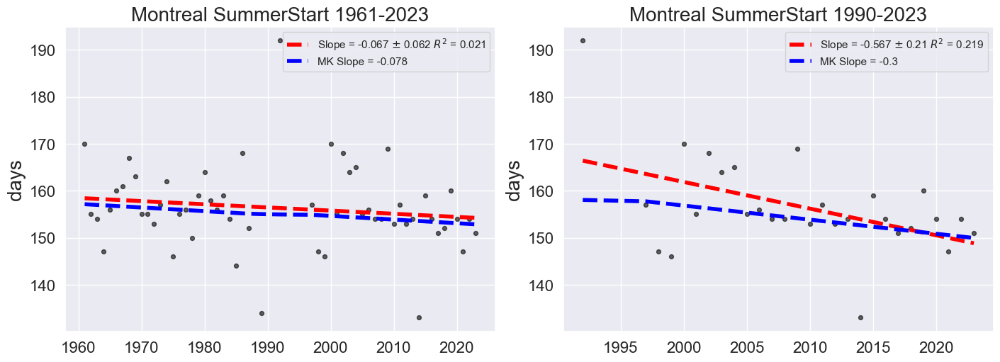

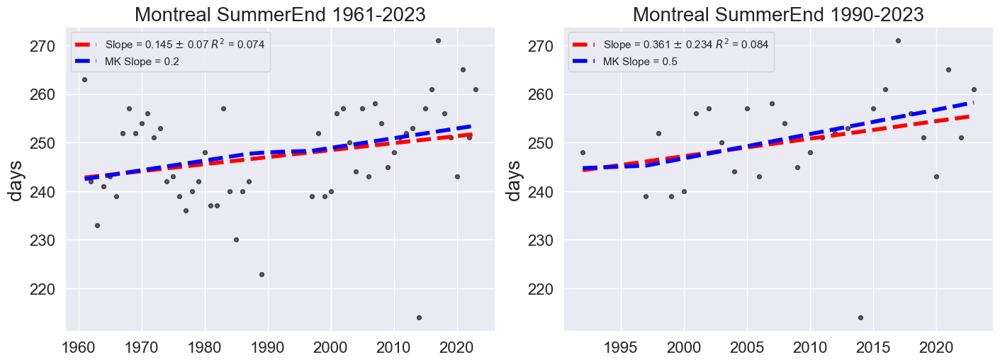

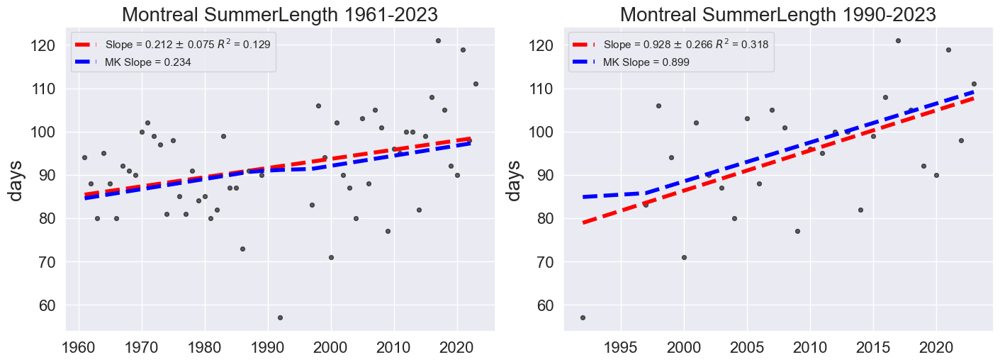

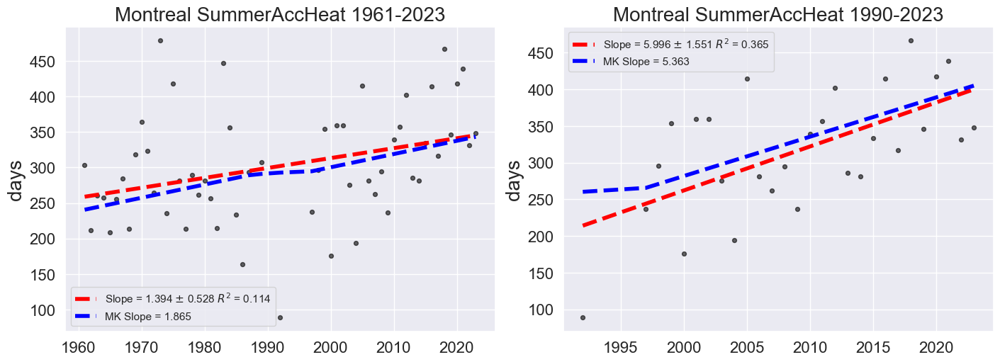

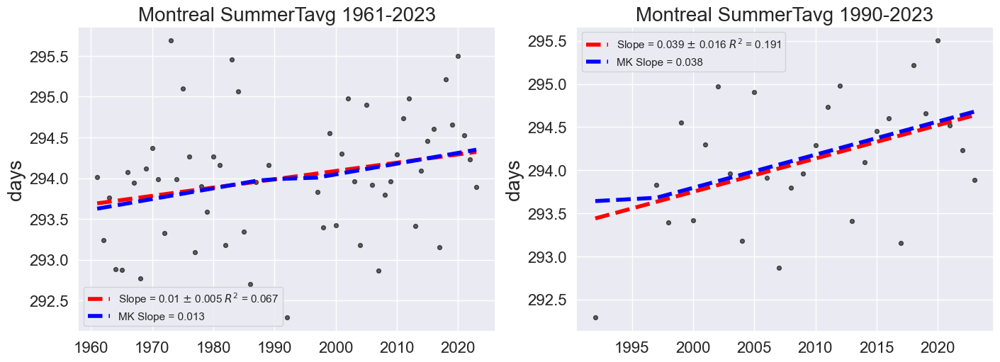

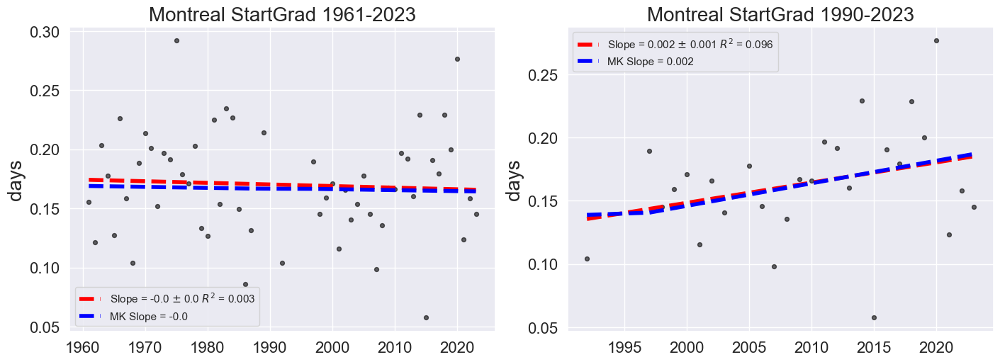

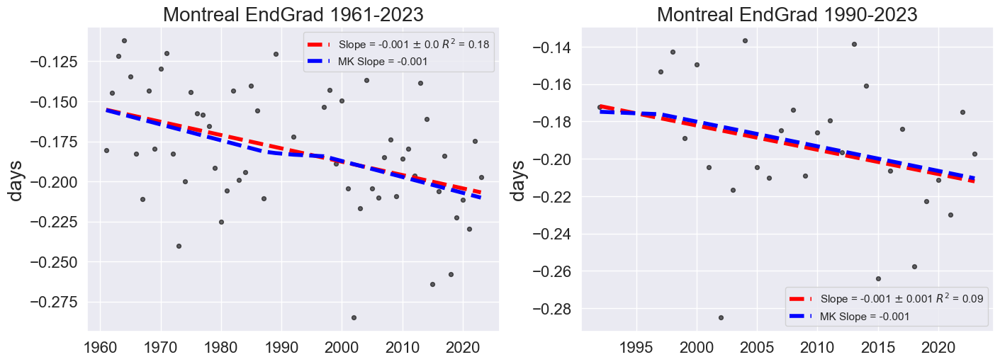

In [12]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Montreal "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Montreal "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

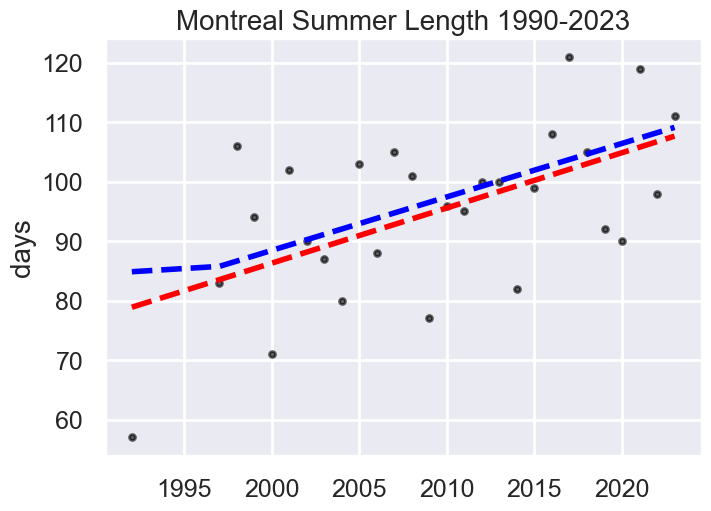

In [13]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Montreal Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/Montreal_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [14]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 45.5
    lon      float64 8B -73.5
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 45.5
    lon      float64 8B -73.5
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 9.280000000000001 +/- 2.66
OLS Slope ERA5: 4.61 +/- 1.7199999999999998


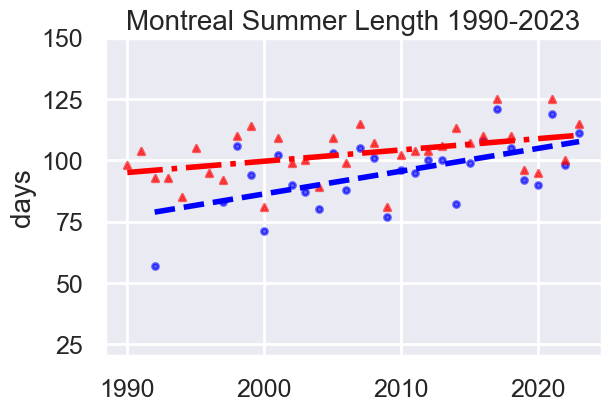

In [15]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Montreal Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(20,150)
plt.savefig("../../../Data/GHCND/Plots/Montreal_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Montreal_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [240]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.318
Model:                            OLS   Adj. R-squared:                  0.292
Method:                 Least Squares   F-statistic:                     12.14
Date:                Mon, 18 May 2026   Prob (F-statistic):            0.00177
Time:                        11:38:48   Log-Likelihood:                -107.71
No. Observations:                  28   AIC:                             219.4
Df Residuals:                      26   BIC:                             222.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1769.6858    535.253     -3.306      0.0

In [241]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.183
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     7.146
Date:                Mon, 18 May 2026   Prob (F-statistic):             0.0117
Time:                        11:38:50   Log-Likelihood:                -125.00
No. Observations:                  34   AIC:                             254.0
Df Residuals:                      32   BIC:                             257.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -821.3546    345.665     -2.376      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: 59.96000000000001 +/- 15.51
OLS Slope ERA5: 27.46 +/- 11.89


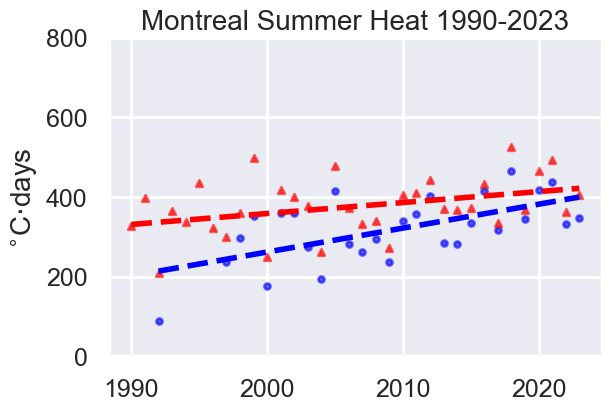

In [16]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Montreal Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,800)
plt.savefig("../../../Data/GHCND/Plots/Montreal_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Montreal_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [243]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.365
Model:                            OLS   Adj. R-squared:                  0.341
Method:                 Least Squares   F-statistic:                     14.94
Date:                Mon, 18 May 2026   Prob (F-statistic):           0.000664
Time:                        11:38:59   Log-Likelihood:                -157.05
No. Observations:                  28   AIC:                             318.1
Df Residuals:                      26   BIC:                             320.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.173e+04   3117.159     -3.763      0.0

In [244]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.143
Model:                            OLS   Adj. R-squared:                  0.116
Method:                 Least Squares   F-statistic:                     5.334
Date:                Mon, 18 May 2026   Prob (F-statistic):             0.0275
Time:                        11:39:01   Log-Likelihood:                -190.68
No. Observations:                  34   AIC:                             385.4
Df Residuals:                      32   BIC:                             388.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -5132.7744   2385.550     -2.152      0.0

#### End Gradient with ERA5 data

In [245]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 45.5
    lon      float64 8B -73.5
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 45.5
    lon      float64 8B -73.5
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.013 +/- 0.0081
OLS Slope ERA5: -0.0057 +/- 0.0048000000000000004


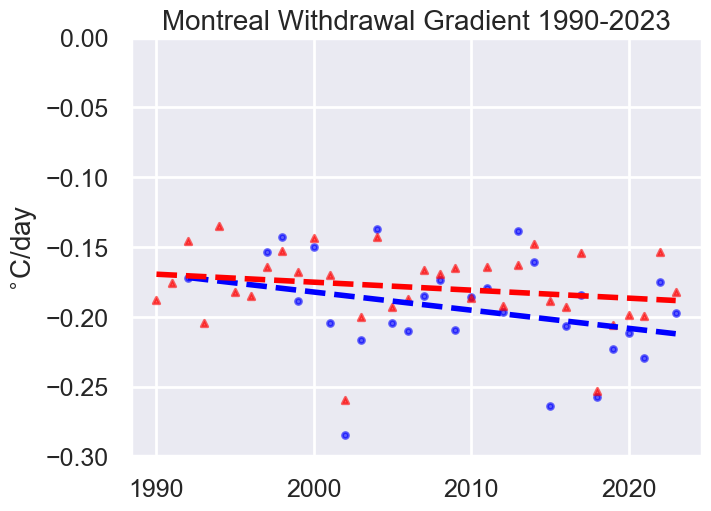

In [246]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Montreal Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/Montreal_summer_end_grad_plot_wERA5.png", bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Montreal_summer_end_grad_plot_wERA5.pdf", bbox_inches='tight')



OLS Slope: 0.016 +/- 0.009600000000000001
OLS Slope ERA5: 0.0044 +/- 0.0048000000000000004


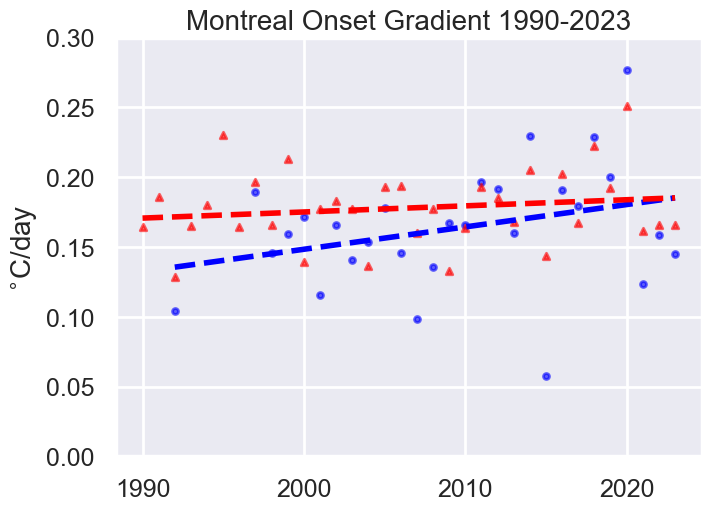

In [247]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Montreal Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/Montreal_summer_start_grad_plot_wERA5.png", bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Montreal_summer_start_grad_plot_wERA5.pdf", bbox_inches='tight')




### Plot the difference between ERA5 and GHCND summer lengths to assess bias (Simon suggestion)

In [177]:
# fig = plt.figure(figsize=(7,5), layout='constrained')
# ax2 = fig.add_subplot(1,1,1)

# # ERA5 summer length - GHCND summer length. Positive value means ERA5 length is longer
# diff = y_era - y

# ax2.scatter(x, diff, label="", color=(np.where(diff >= 0, 'green', 'black')), s=s, alpha=alpha)
# plt.axhline(0.0, color="black", linewidth=0.8, linestyle="dashed")

# ax2.set_title("Montreal Summer Length 1990-2023\n Anomaly: ERA5 - GHCND", fontsize=fs)
# #ax2.legend(loc="best")
# ax2.tick_params('x', labelsize=18)
# ax2.tick_params('y', labelsize=18)
# ax2.set_ylabel('Days', fontsize=fs)

# Winnipeg looks to have a decent station with complete data

#### site is CA005023261

In [17]:
df = pd.read_csv("../../../Data/GHCND/api_downloads/winnipeg-2026-05-18T16-52-59.csv")
#df2 = pd.read_csv("../../../Data/GHCND/api_downloads/montreal2-2026-05-18T16-50-55.csv")
#df.reset_index()
#df = pd.concat([df2, df1], axis=0, ignore_index=True)
#df.reset_index()
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,1961-01-01,-27.1,-17.8,-32.2
1,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,1961-01-02,-24.4,NaN,NaN
2,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,1961-01-03,-25.6,NaN,-33.3
3,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,1961-01-04,-12.9,NaN,-17.2
4,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,1961-01-05,-8.3,NaN,-13.9
...,...,...,...,...,...,...,...,...,...
22822,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,2023-12-27,-7.6,NaN,NaN
22823,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,2023-12-28,-8.3,NaN,NaN
22824,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,2023-12-29,-6.6,NaN,NaN
22825,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,2023-12-30,-5.2,NaN,NaN


In [179]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22827 entries, 0 to 22826
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    22827 non-null  str    
 1   NAME       22827 non-null  str    
 2   LATITUDE   22827 non-null  float64
 3   LONGITUDE  22827 non-null  float64
 4   ELEVATION  22827 non-null  float64
 5   DATE       22827 non-null  str    
 6   TAVG       17518 non-null  float64
 7   TMAX       13101 non-null  float64
 8   TMIN       14169 non-null  float64
dtypes: float64(6), str(3)
memory usage: 2.4 MB


### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [249]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,1961-01-01,-27.1,-17.8,-32.2
1,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,1961-01-02,-24.4,NaN,NaN
2,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,1961-01-03,-25.6,NaN,-33.3
3,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,1961-01-04,-12.9,NaN,-17.2
4,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,1961-01-05,-8.3,NaN,-13.9
...,...,...,...,...,...,...,...,...,...
22822,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,2023-12-27,-7.6,NaN,NaN
22823,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,2023-12-28,-8.3,NaN,NaN
22824,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,2023-12-29,-6.6,NaN,NaN
22825,CA005023261,"WINNIPEG STP, MB CA",49.95,-97.1,233.0,2023-12-30,-5.2,NaN,NaN


In [96]:
# check counts again
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21649 entries, 0 to 21648
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    21649 non-null  str    
 1   NAME       21649 non-null  str    
 2   LATITUDE   21649 non-null  float64
 3   LONGITUDE  21649 non-null  float64
 4   ELEVATION  21649 non-null  float64
 5   DATE       21649 non-null  str    
 6   TAVG       21358 non-null  float64
 7   TMAX       21453 non-null  float64
 8   TMIN       21399 non-null  float64
dtypes: float64(6), str(3)
memory usage: 2.3 MB


In [250]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,246.05
1961-01-02,248.75
1961-01-03,247.55
1961-01-04,260.25
1961-01-05,264.85
...,...
2023-12-27,265.55
2023-12-28,264.85
2023-12-29,266.55


#### dealing with some of the missing dates?

In [251]:
#df_sub.tail(365)
#df_sub.loc['2020-01-01':'2021-12-31'].head(300)
start = "1961-01-01"
end = "2023-12-31"

# got help from https://www.geeksforgeeks.org/check-missing-dates-in-pandas/
print(pd.date_range(
  start=start, end=end).difference(df_sub.index))


DatetimeIndex(['1978-02-01', '1978-02-02', '1978-02-03', '1978-02-04',
               '1978-02-05', '1978-02-06', '1978-02-07', '1978-02-08',
               '1978-02-09', '1978-02-10',
               ...
               '1979-03-26', '1979-03-27', '1979-03-28', '1979-03-29',
               '1979-03-30', '1979-03-31', '1999-01-10', '2000-11-30',
               '2007-08-28', '2021-02-20'],
              dtype='datetime64[us]', length=183, freq=None)


#### looks like 1978 and 1979 may need to be dropped, fix the rest

In [252]:
df_missing = pd.DataFrame({'time':pd.to_datetime(['1999-01-10', '2000-11-30',
               '2007-08-28', '2021-02-20']),
                            'tavg':np.repeat(np.nan, 4)})
df_missing = df_missing.set_index(['time'])
df_missing
                                                 

,tavg
time,
1999-01-10,NaN
2000-11-30,NaN
2007-08-28,NaN
2021-02-20,NaN


In [253]:
df_sub = pd.concat([df_sub, df_missing], axis=0).sort_index()
df_sub

,tavg
time,
1961-01-01,246.05
1961-01-02,248.75
1961-01-03,247.55
1961-01-04,260.25
1961-01-05,264.85
...,...
2023-12-27,265.55
2023-12-28,264.85
2023-12-29,266.55


In [254]:
# linear interpolation to fill the missing ones
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
print(df_sub[df_sub.isna().any(axis=1)])

Empty DataFrame
Columns: [tavg]
Index: []


#### all cleaned up!

In [255]:
# linear interpolation to fill the last few
#df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
df_sub.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 22831 entries, 1961-01-01 to 2023-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tavg    22831 non-null  float64
dtypes: float64(1)
memory usage: 356.7 KB


### Convert from Pandas to XArray

In [256]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 365kB
Dimensions:  (time: 22831)
Coordinates:
  * time     (time) datetime64[us] 183kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 183kB 246.0 248.7 247.5 260.2 ... 266.5 267.9 262.8

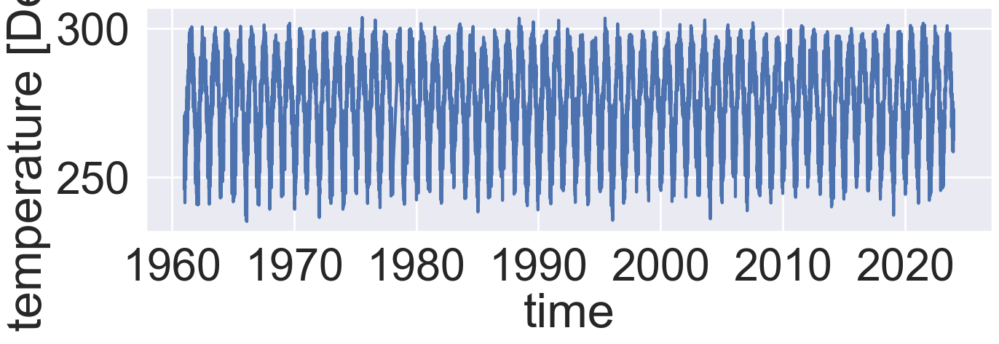

In [257]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

#### look at those missing years

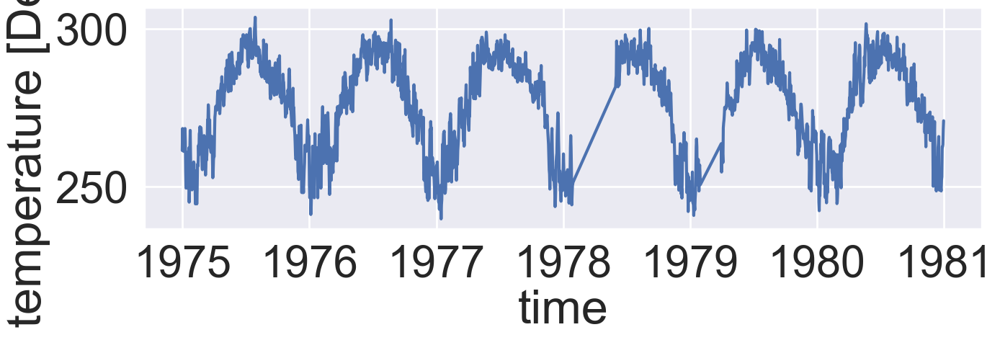

In [258]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1975','1980')).plot()

#### yeah, 1978 & 1979 will need to be dropped or interpolated

### Calculate the threshold temp from 1961-1990, 75%-ile

In [259]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(288.656219)
Coordinates:
    lat       float64 8B 50.0
    lon       float64 8B -97.0
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [260]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 2.14 ms, sys: 3.59 ms, total: 5.73 ms
Wall time: 4.18 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(288.85)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [261]:
thresh.values - stp_75.values

np.float64(-0.1937805175780909)

#### Winnipeg 75th Percentile from GHCND data is 0.2 K warmer

### Try one year (2023) fit via Fourier

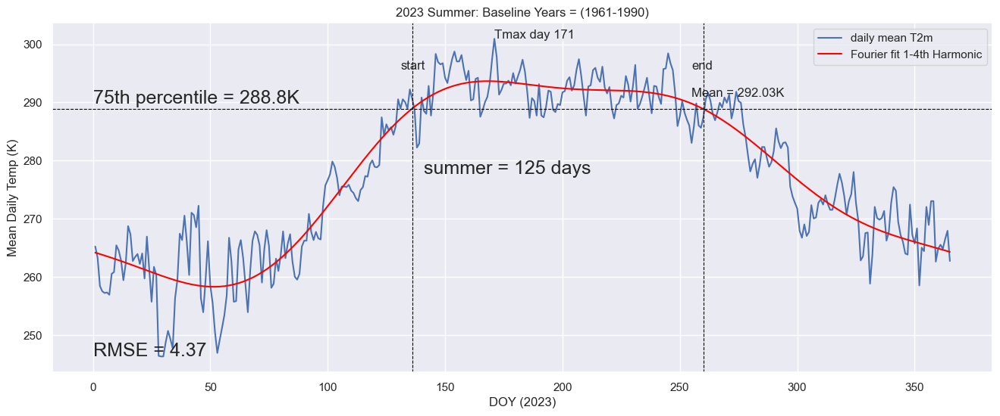

(136,
 260,
 0.31243708115835034,
 -0.21208428400407797,
 171,
 448.2999999999993,
 125,
 4.365451889417409,
 0.0,
 292.03,
 4.574489795918339)

In [262]:
input_year = 2023

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Main Loop: loop through multiple years to generate summer stats.

In [263]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)
# process_yrs2 = np.arange(1992,1994,1)
# process_yrs3 = np.arange(1997,2024,1)

# process_yrs_tmp = np.append(process_yrs, process_yrs2)
# process_yrs = np.append(process_yrs_tmp, process_yrs3)
process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [264]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    print("Processing year: "+str(input_year))
    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



Processing year: 1961
Processing year: 1962
Processing year: 1963
Processing year: 1964
Processing year: 1965
Processing year: 1966
Processing year: 1967
Processing year: 1968
Processing year: 1969
Processing year: 1970
Processing year: 1971
Processing year: 1972
Processing year: 1973
Processing year: 1974
Processing year: 1975
Processing year: 1976
Processing year: 1977
Processing year: 1978
Processing year: 1979
Processing year: 1980
Processing year: 1981
Processing year: 1982
Processing year: 1983
Processing year: 1984
Processing year: 1985
Processing year: 1986
Processing year: 1987
Processing year: 1988
Processing year: 1989
Processing year: 1990
Processing year: 1991
Processing year: 1992
Processing year: 1993
Processing year: 1994
Processing year: 1995
Processing year: 1996
Processing year: 1997
Processing year: 1998
Processing year: 1999
Processing year: 2000
Processing year: 2001
Processing year: 2002
Processing year: 2003
Processing year: 2004
Processing year: 2005
Processing

,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,151,250,0.289355,-0.192471,100,499.1,229,293.734000
1,1962,153,242,0.198158,-0.146118,90,301.6,179,292.104444
2,1963,153,262,0.239048,-0.130034,110,485.1,205,292.702727
3,1964,148,236,0.240226,-0.084839,89,281.7,179,290.835393
4,1965,159,233,0.158651,-0.173538,75,232.1,225,291.612667
...,...,...,...,...,...,...,...,...,...
58,2019,159,248,0.144036,-0.302183,90,334.9,216,292.262222
59,2020,152,245,0.238321,-0.251533,94,426.8,168,293.080851
60,2021,150,257,0.231872,-0.196075,108,509.3,184,293.326852
61,2022,157,252,0.206699,-0.209385,96,380.3,170,292.692708


In [265]:
df_summ.query('Year > 1975 & Year < 1980')

,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
15,1976,146,253,0.204050,-0.202012,108,426.30,236,292.399074
16,1977,134,219,0.227162,-0.103413,86,272.85,145,291.848837
17,1978,51,139,0.629237,-0.189896,89,296.30,128,291.551685
18,1979,99,183,0.179125,-0.241578,85,313.40,131,291.894118


#### all filled in

### write out resulting summer stats

In [157]:
# write out results
output_path = "../../../Data/GHCND/Winnipeg_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [18]:
# re-load 
input_path = "../../../Data/GHCND/Winnipeg_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,151,250,0.289355,-0.192471,100,499.1,229,293.734000
1,1,1962,153,242,0.198158,-0.146118,90,301.6,179,292.104444
2,2,1963,153,262,0.239048,-0.130034,110,485.1,205,292.702727
3,3,1964,148,236,0.240226,-0.084839,89,281.7,179,290.835393
4,4,1965,159,233,0.158651,-0.173538,75,232.1,225,291.612667
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,159,248,0.144036,-0.302183,90,334.9,216,292.262222
59,59,2020,152,245,0.238321,-0.251533,94,426.8,168,293.080851
60,60,2021,150,257,0.231872,-0.196075,108,509.3,184,293.326852
61,61,2022,157,252,0.206699,-0.209385,96,380.3,170,292.692708


### Winnipeg: Plot the summer stats

In [267]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

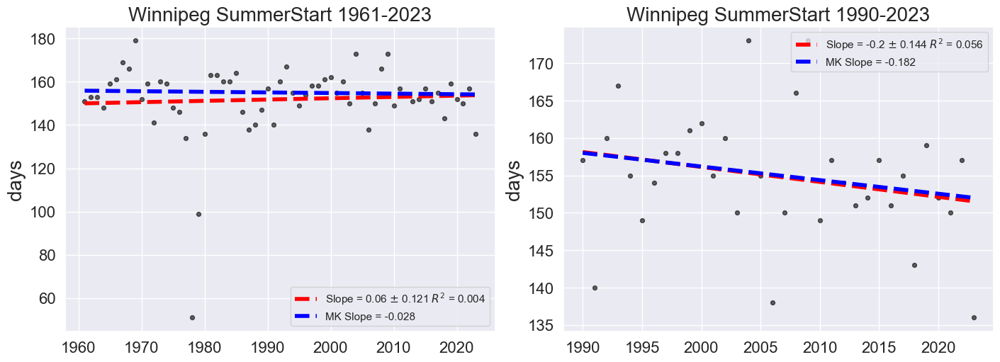

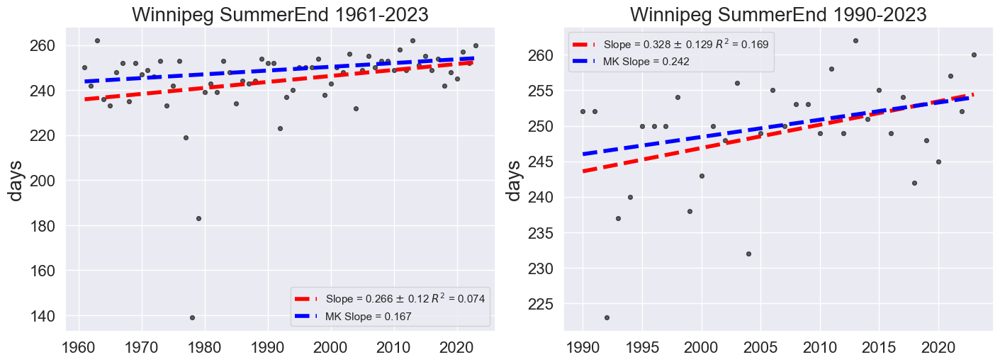

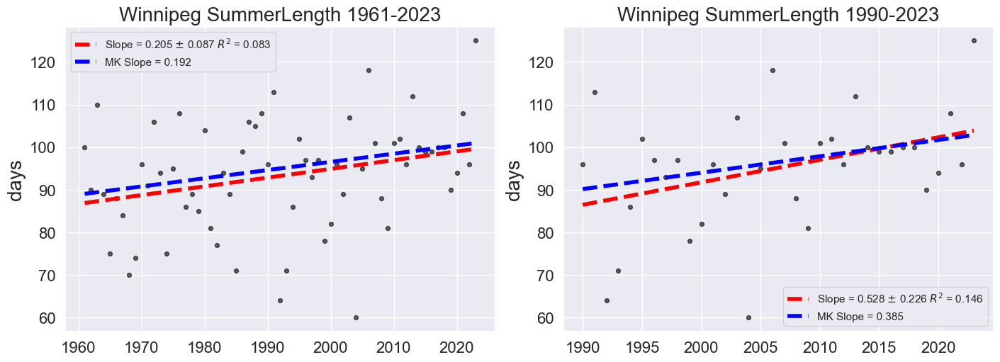

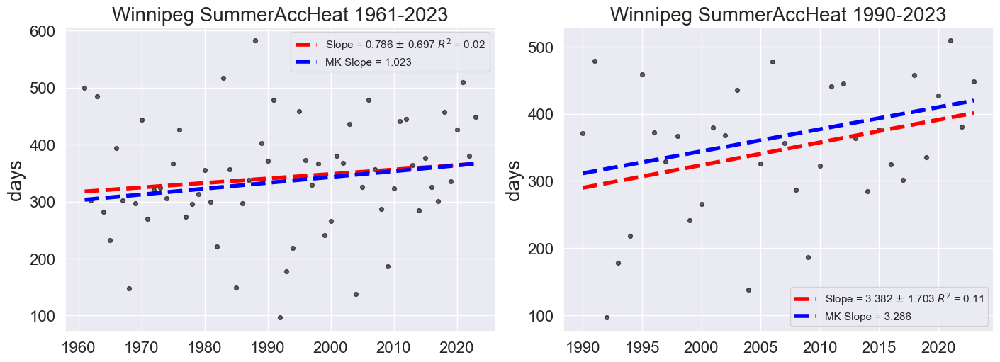

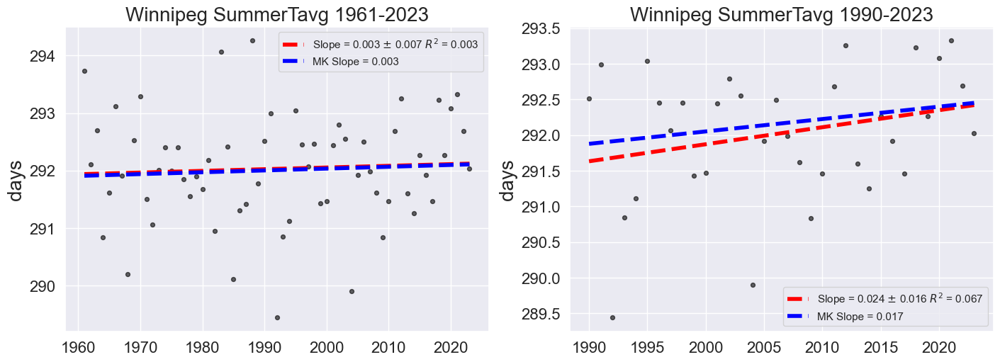

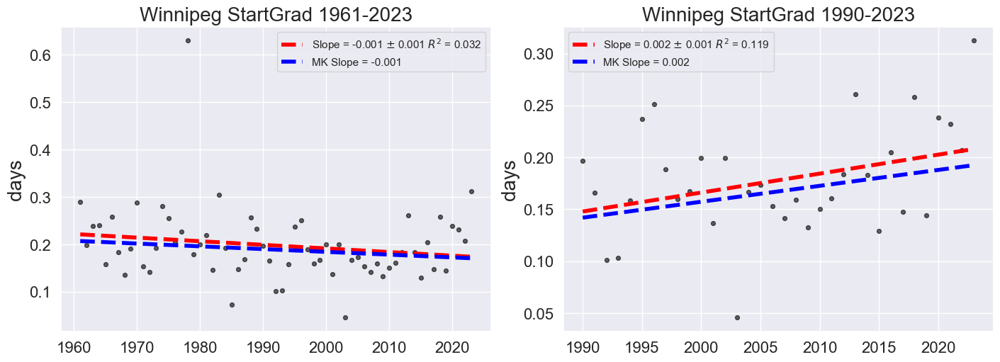

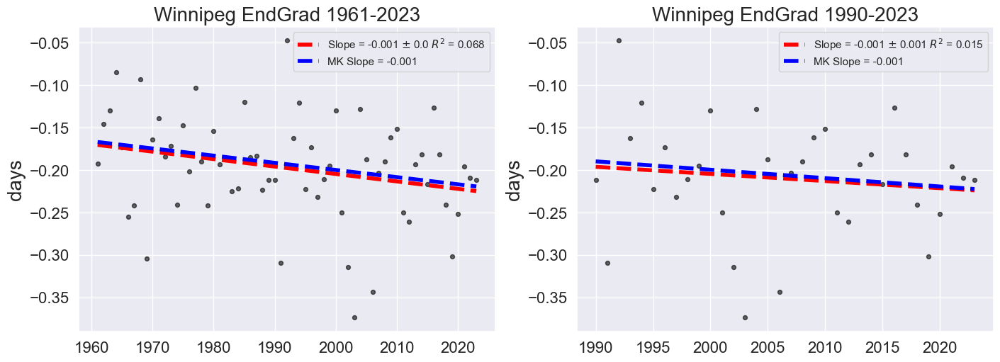

In [19]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Winnipeg "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Winnipeg "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

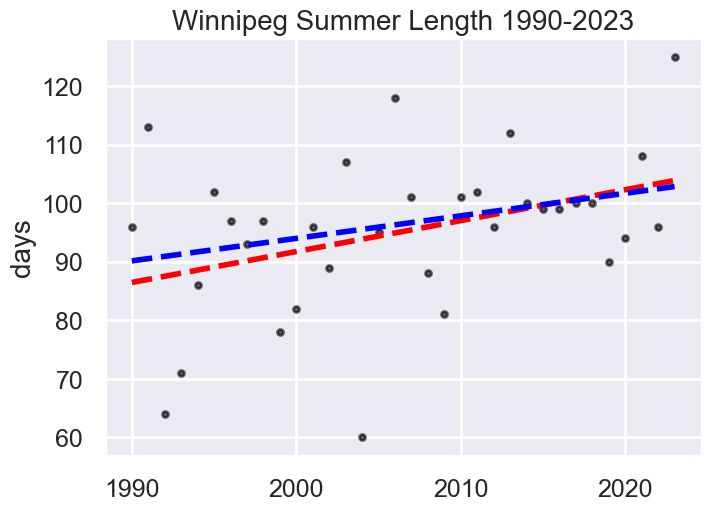

In [269]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Winnipeg Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/Winnipeg_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [422]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 50.0
    lon      float64 8B -97.0
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 50.0
    lon      float64 8B -97.0
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 5.28 +/- 2.2600000000000002
OLS Slope ERA5: 5.44 +/- 2.45


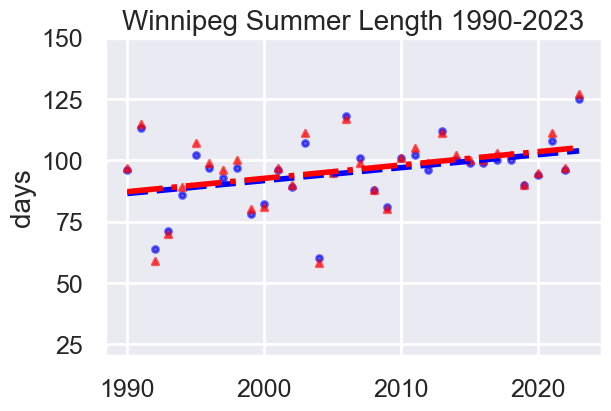

In [423]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Winnipeg Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(20,150)
plt.savefig("../../../Data/GHCND/Plots/Winnipeg_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Winnipeg_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [272]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.146
Model:                            OLS   Adj. R-squared:                  0.119
Method:                 Least Squares   F-statistic:                     5.458
Date:                Mon, 18 May 2026   Prob (F-statistic):             0.0259
Time:                        11:43:52   Log-Likelihood:                -134.22
No. Observations:                  34   AIC:                             272.4
Df Residuals:                      32   BIC:                             275.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -963.7160    453.257     -2.126      0.0

In [273]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.133
Model:                            OLS   Adj. R-squared:                  0.106
Method:                 Least Squares   F-statistic:                     4.922
Date:                Mon, 18 May 2026   Prob (F-statistic):             0.0337
Time:                        11:43:54   Log-Likelihood:                -137.03
No. Observations:                  34   AIC:                             278.1
Df Residuals:                      32   BIC:                             281.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -996.1027    492.377     -2.023      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: 33.82 +/- 17.03
OLS Slope ERA5: 36.28 +/- 17.77


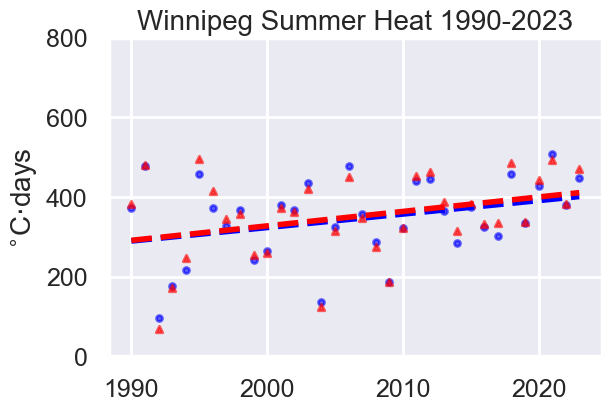

In [424]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Winnipeg Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,800)
plt.savefig("../../../Data/GHCND/Plots/Winnipeg_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Winnipeg_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [275]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.110
Model:                            OLS   Adj. R-squared:                  0.082
Method:                 Least Squares   F-statistic:                     3.943
Date:                Mon, 18 May 2026   Prob (F-statistic):             0.0557
Time:                        11:44:03   Log-Likelihood:                -202.90
No. Observations:                  34   AIC:                             409.8
Df Residuals:                      32   BIC:                             412.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -6440.3449   3417.393     -1.885      0.0

In [276]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.115
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     4.168
Date:                Mon, 18 May 2026   Prob (F-statistic):             0.0495
Time:                        11:44:05   Log-Likelihood:                -204.35
No. Observations:                  34   AIC:                             412.7
Df Residuals:                      32   BIC:                             415.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -6928.9380   3566.104     -1.943      0.0

#### End Gradient with ERA5 data

In [277]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 50.0
    lon      float64 8B -97.0
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 50.0
    lon      float64 8B -97.0
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.008400000000000001 +/- 0.0119
OLS Slope ERA5: -0.0079 +/- 0.009


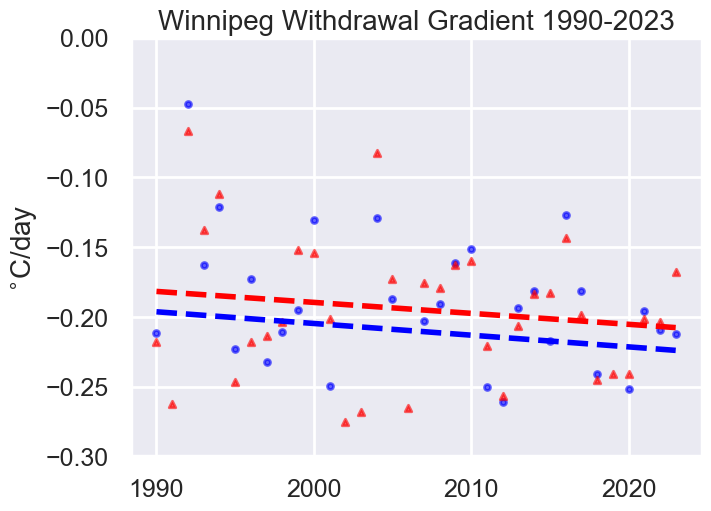

In [278]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Winnipeg Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/Winnipeg_summer_end_grad_plot_wERA5.png", bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Winnipeg_summer_end_grad_plot_wERA5.pdf", bbox_inches='tight')



OLS Slope: 0.0183 +/- 0.0088
OLS Slope ERA5: 0.018500000000000003 +/- 0.008400000000000001


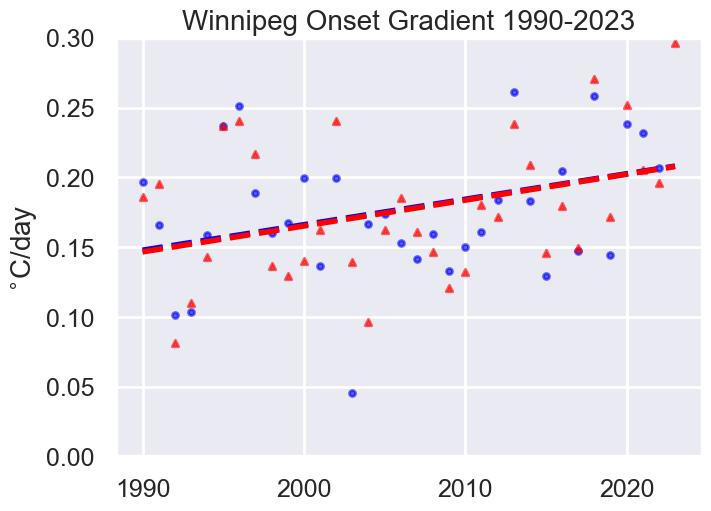

In [279]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Winnipeg Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/Winnipeg_summer_start_grad_plot_wERA5.png", bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Winnipeg_summer_start_grad_plot_wERA5.pdf", bbox_inches='tight')




# Edmonton looks to have one station with complete data

#### sites are CA003012210 and CA003012212 - only up until end of 2021 though

In [ ]:
#https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&dataTypes=TAVG,TMAX,TMIN&stations=CA001108395&startDate=1961-01-01&endDate=2023-12-31&includeStationLocation=1&units=metric&includeStationName=true&format=csv

In [20]:
df1 = pd.read_csv("../../../Data/GHCND/api_downloads/edmonton1-2026-05-18T16-55-39.csv")
df2 = pd.read_csv("../../../Data/GHCND/api_downloads/edmonton2-2026-05-18T16-56-13.csv")
#df.reset_index()
df = pd.concat([df1, df2], axis=0, ignore_index=True)
#df.reset_index()
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA003012210,"EDMONTON NAMAO A, AB CA",53.6667,-113.4667,688.0,1961-01-01,NaN,-5.0,-21.1
1,CA003012210,"EDMONTON NAMAO A, AB CA",53.6667,-113.4667,688.0,1961-01-02,NaN,4.4,-18.9
2,CA003012210,"EDMONTON NAMAO A, AB CA",53.6667,-113.4667,688.0,1961-01-03,NaN,3.3,-2.8
3,CA003012210,"EDMONTON NAMAO A, AB CA",53.6667,-113.4667,688.0,1961-01-04,NaN,5.6,-6.7
4,CA003012210,"EDMONTON NAMAO A, AB CA",53.6667,-113.4667,688.0,1961-01-05,NaN,3.3,-1.7
...,...,...,...,...,...,...,...,...,...
20909,CA003012212,"EDMONTON NAMAO AWOS A, AB CA",53.6667,-113.4667,688.0,2022-01-01,-20.6,-8.4,-32.8
20910,CA003012212,"EDMONTON NAMAO AWOS A, AB CA",53.6667,-113.4667,688.0,2022-01-02,-13.0,-2.4,-23.5
20911,CA003012212,"EDMONTON NAMAO AWOS A, AB CA",53.6667,-113.4667,688.0,2022-01-03,-24.2,-22.9,-25.5
20912,CA003012212,"EDMONTON NAMAO AWOS A, AB CA",53.6667,-113.4667,688.0,2022-01-04,-28.3,-25.2,-31.3


In [282]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20914 entries, 0 to 20913
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    20914 non-null  str    
 1   NAME       20914 non-null  str    
 2   LATITUDE   20914 non-null  float64
 3   LONGITUDE  20914 non-null  float64
 4   ELEVATION  20914 non-null  float64
 5   DATE       20914 non-null  str    
 6   TAVG       2316 non-null   float64
 7   TMAX       20709 non-null  float64
 8   TMIN       20654 non-null  float64
dtypes: float64(6), str(3)
memory usage: 2.3 MB


### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [283]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA003012210,"EDMONTON NAMAO A, AB CA",53.6667,-113.4667,688.0,1961-01-01,-13.05,-5.0,-21.1
1,CA003012210,"EDMONTON NAMAO A, AB CA",53.6667,-113.4667,688.0,1961-01-02,-7.25,4.4,-18.9
2,CA003012210,"EDMONTON NAMAO A, AB CA",53.6667,-113.4667,688.0,1961-01-03,0.25,3.3,-2.8
3,CA003012210,"EDMONTON NAMAO A, AB CA",53.6667,-113.4667,688.0,1961-01-04,-0.55,5.6,-6.7
4,CA003012210,"EDMONTON NAMAO A, AB CA",53.6667,-113.4667,688.0,1961-01-05,0.80,3.3,-1.7
...,...,...,...,...,...,...,...,...,...
20909,CA003012212,"EDMONTON NAMAO AWOS A, AB CA",53.6667,-113.4667,688.0,2022-01-01,-20.60,-8.4,-32.8
20910,CA003012212,"EDMONTON NAMAO AWOS A, AB CA",53.6667,-113.4667,688.0,2022-01-02,-13.00,-2.4,-23.5
20911,CA003012212,"EDMONTON NAMAO AWOS A, AB CA",53.6667,-113.4667,688.0,2022-01-03,-24.20,-22.9,-25.5
20912,CA003012212,"EDMONTON NAMAO AWOS A, AB CA",53.6667,-113.4667,688.0,2022-01-04,-28.30,-25.2,-31.3


In [284]:
# check counts again
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20914 entries, 0 to 20913
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    20914 non-null  str    
 1   NAME       20914 non-null  str    
 2   LATITUDE   20914 non-null  float64
 3   LONGITUDE  20914 non-null  float64
 4   ELEVATION  20914 non-null  float64
 5   DATE       20914 non-null  str    
 6   TAVG       20600 non-null  float64
 7   TMAX       20709 non-null  float64
 8   TMIN       20654 non-null  float64
dtypes: float64(6), str(3)
memory usage: 2.3 MB


In [285]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,260.10
1961-01-02,265.90
1961-01-03,273.40
1961-01-04,272.60
1961-01-05,273.95
...,...
2022-01-01,252.55
2022-01-02,260.15
2022-01-03,248.95


#### dealing with some of the missing dates - 1995, 1996-1999 (all), 2018 is especially bad and will need to be dropped

In [315]:
#df_sub.tail(365)
#df_sub.loc['2020-01-01':'2021-12-31'].head(300)
start = "2019-01-01"
end = "2021-12-31"

# got help from https://www.geeksforgeeks.org/check-missing-dates-in-pandas/
gaps = pd.date_range(
  start=start, end=end).difference(df_sub.index)

print(gaps)

DatetimeIndex(['2019-01-09', '2019-01-24', '2019-02-14', '2019-05-15',
               '2019-06-05', '2019-07-08', '2019-07-22', '2020-03-10',
               '2020-03-20', '2020-03-21', '2020-04-17', '2020-06-17',
               '2020-10-21', '2021-02-24', '2021-12-16'],
              dtype='datetime64[us]', freq=None)


In [316]:
df_missing = pd.DataFrame({'time':pd.to_datetime(
              ['1992-12-03', '1992-12-07', '1992-12-09', '1992-12-17',
               '1992-12-23', '1992-12-24', '1992-12-27', '1992-12-28',
               '1993-01-03', '1993-01-06', '1993-01-13', '1993-01-14',
               '1993-02-11', '1993-02-12', '1993-02-20', '1993-02-21',
               '1993-02-22', '1993-03-12', '1993-03-16', '1993-03-23',
               '1993-04-02', '1993-04-06', '1993-04-09', '1993-04-22',
               '1993-04-25', '1993-04-26', '1993-04-30', '1993-05-01',
               '1993-05-07', '1993-05-12', '1993-05-17', '1993-05-30',
               '1993-06-04', '1993-06-06', '1993-06-07', '1993-06-08',
               '1993-06-09', '1993-06-13', '1993-06-16', '1993-06-17',
               '1993-06-22', '1993-06-23', '1993-08-12', '1993-09-11',
               '1993-11-04', '1993-11-22', '1993-11-23', '1993-11-29',
               '1993-12-01', '1993-12-14', '1993-12-20', '1993-12-26',
               '2000-01-18', '2000-02-01', '2000-02-27', '2000-02-28',
               '2000-07-15', '2000-08-26', '2001-03-03', '2001-03-11',
               '2001-03-17', '2001-07-18', '2003-03-03', '2003-04-14',
               '2004-04-01', '2004-04-02', '2004-04-03', '2004-04-04',
               '2004-04-05', '2004-04-06', '2004-04-07', '2004-04-08',
               '2007-10-13', '2008-08-06', '2008-08-07', '2008-11-26',
               '2010-04-14', '2010-04-15', '2010-04-21', '2010-06-10',
               '2010-08-09', '2010-08-10', '2010-08-11', '2010-10-14',
               '2010-11-25', '2010-04-14', '2010-04-15', '2010-04-21', '2010-06-10',
               '2010-08-09', '2010-08-10', '2010-08-11', '2010-10-14',
               '2010-11-25', '2011-06-21', '2011-06-22', '2011-07-22',
               '2012-02-11', '2012-02-12', '2012-02-13', '2012-02-28',
               '2012-05-22', '2012-05-23', '2012-07-23', '2012-09-20',
               '2012-09-21', '2013-06-20', '2013-06-30', '2013-07-03',
               '2013-07-05', '2013-07-30', '2013-08-19', '2013-08-20',
               '2013-08-28', '2013-09-02', '2013-09-13', '2013-09-30',
               '2013-10-04', '2013-10-30', '2013-11-07', '2013-11-18',
               '2013-11-23', '2013-12-13', '2013-12-20', '2013-12-21',
               '2013-12-26', '2013-12-31', '2014-01-01', '2014-01-02',
               '2014-01-03', '2014-01-04', '2014-01-05', '2014-01-06',
               '2014-01-14', '2014-03-08', '2014-03-09', '2014-03-28',
               '2014-04-09', '2014-05-08', '2014-08-03', '2014-08-18',
               '2014-12-31', '2015-06-01', '2015-06-02', '2017-02-27',
               '2017-02-28', '2017-03-01', '2017-03-02', '2017-03-03',
               '2019-01-09', '2019-01-24', '2019-02-14', '2019-05-15',
               '2019-06-05', '2019-07-08', '2019-07-22', '2020-03-10',
               '2020-03-20', '2020-03-21', '2020-04-17', '2020-06-17',
               '2020-10-21', '2021-02-24', '2021-12-16']),
                            'tavg':np.repeat(np.nan, 41*4)})
df_missing = df_missing.set_index(['time'])
df_missing
                                                 

,tavg
time,
1992-12-03,NaN
1992-12-07,NaN
1992-12-09,NaN
1992-12-17,NaN
1992-12-23,NaN
...,...
2020-04-17,NaN
2020-06-17,NaN
2020-10-21,NaN


In [317]:
df_sub = pd.concat([df_sub, df_missing], axis=0).sort_index()
df_sub

,tavg
time,
1961-01-01,260.10
1961-01-02,265.90
1961-01-03,273.40
1961-01-04,272.60
1961-01-05,273.95
...,...
2022-01-01,252.55
2022-01-02,260.15
2022-01-03,248.95


In [318]:
# linear interpolation to fill the missing ones
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
print(df_sub[df_sub.isna().any(axis=1)])

Empty DataFrame
Columns: [tavg]
Index: []


#### all cleaned up!

In [319]:
# linear interpolation to fill the last few
#df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
df_sub.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 21078 entries, 1961-01-01 to 2022-01-05
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tavg    21078 non-null  float64
dtypes: float64(1)
memory usage: 329.3 KB


### Convert from Pandas to XArray

In [320]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 337kB
Dimensions:  (time: 21078)
Coordinates:
  * time     (time) datetime64[us] 169kB 1961-01-01 1961-01-02 ... 2022-01-05
Data variables:
    tavg     (time) float64 169kB 260.1 265.9 273.4 272.6 ... 248.9 244.8 242.3

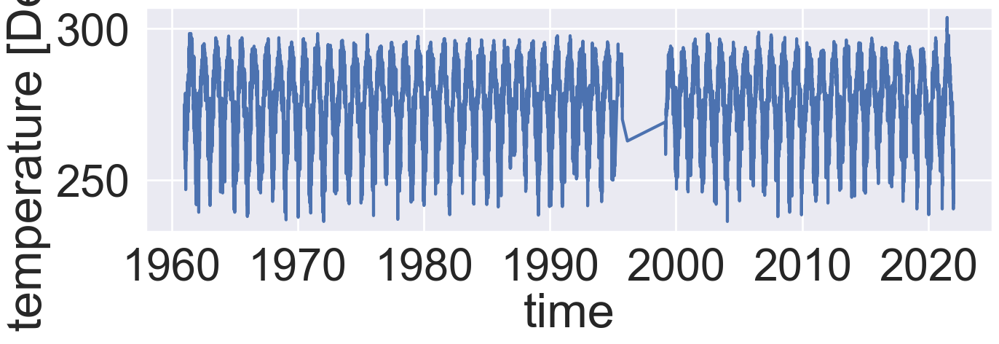

In [321]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

#### look at those missing years

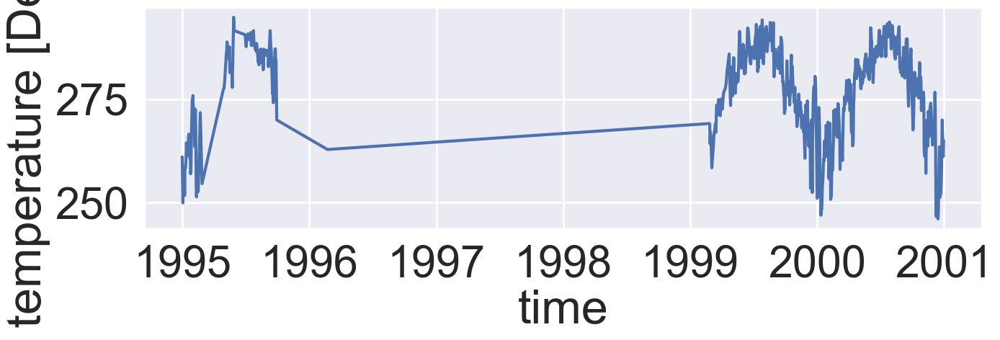

In [322]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1995','2000')).plot()

#### yeah, 1995-1999 will need to be dropped, and 2018

### Calculate the threshold temp from 1961-1990, 75%-ile

In [323]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(286.318146)
Coordinates:
    lat       float64 8B 53.75
    lon       float64 8B -113.5
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [324]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 1.98 ms, sys: 3.26 ms, total: 5.25 ms
Wall time: 3.38 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(286.35)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [325]:
thresh.values - stp_75.values

np.float64(-0.031854248046840894)

#### Edmonton 75th Percentile from GHCND data is the same

### Try one year (2021) fit via Fourier

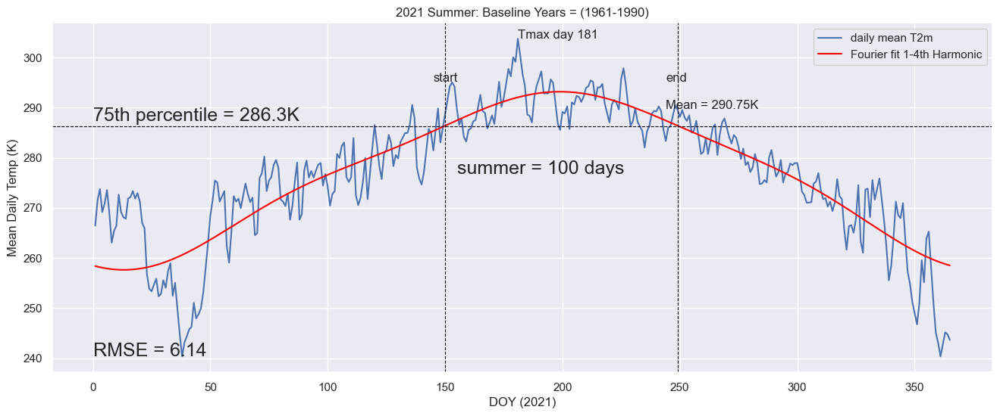

(150,
 249,
 0.21311849577085695,
 -0.20424977280032408,
 181,
 459.00000000000364,
 100,
 6.136748899542854,
 0.0,
 290.74899999999997,
 5.337209302325618)

In [326]:
input_year = 2021

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Main Loop: loop through multiple years to generate summer stats.

In [329]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 1995,1)
process_yrs2 = np.arange(2000,2018,1)
process_yrs3 = np.arange(2019,2022,1)

process_yrs_tmp = np.append(process_yrs, process_yrs2)
process_yrs = np.append(process_yrs_tmp, process_yrs3)
process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009,
       2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2019, 2020, 2021])

In [330]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    print("Processing year: "+str(input_year))
    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



Processing year: 1961
Processing year: 1962
Processing year: 1963
Processing year: 1964
Processing year: 1965
Processing year: 1966
Processing year: 1967
Processing year: 1968
Processing year: 1969
Processing year: 1970
Processing year: 1971
Processing year: 1972
Processing year: 1973
Processing year: 1974
Processing year: 1975
Processing year: 1976
Processing year: 1977
Processing year: 1978
Processing year: 1979
Processing year: 1980
Processing year: 1981
Processing year: 1982
Processing year: 1983
Processing year: 1984
Processing year: 1985
Processing year: 1986
Processing year: 1987
Processing year: 1988
Processing year: 1989
Processing year: 1990
Processing year: 1991
Processing year: 1992
Processing year: 1993
Processing year: 1994
Processing year: 2000
Processing year: 2001
Processing year: 2002
Processing year: 2003
Processing year: 2004
Processing year: 2005
Processing year: 2006
Processing year: 2007
Processing year: 2008
Processing year: 2009
Processing year: 2010
Processing

,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,139,249,0.275095,-0.165265,111,532.250000,155,290.912613
1,1962,145,250,0.124519,-0.140612,106,254.500000,213,287.978302
2,1963,153,264,0.176869,-0.198221,112,411.400000,186,289.572321
3,1964,144,221,0.305251,-0.090519,78,229.000000,193,289.117308
4,1965,154,237,0.226260,-0.159035,84,327.550000,214,289.949405
5,1966,163,252,0.091821,-0.188079,90,206.200000,200,288.216111
6,1967,158,263,0.169847,-0.223814,106,381.700000,244,289.480660
7,1968,156,224,0.200955,-0.144927,69,164.450000,186,288.021739
8,1969,165,240,0.125930,-0.249773,76,208.000000,191,288.831579
9,1970,143,239,0.258212,-0.081413,97,327.950000,172,289.372165


#### all filled in

### write out resulting summer stats

In [331]:
# write out results
output_path = "../../../Data/GHCND/Edmonton_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [21]:
# re-load 
input_path = "../../../Data/GHCND/Edmonton_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,139,249,0.275095,-0.165265,111,532.250000,155,290.912613
1,1,1962,145,250,0.124519,-0.140612,106,254.500000,213,287.978302
2,2,1963,153,264,0.176869,-0.198221,112,411.400000,186,289.572321
3,3,1964,144,221,0.305251,-0.090519,78,229.000000,193,289.117308
4,4,1965,154,237,0.226260,-0.159035,84,327.550000,214,289.949405
5,5,1966,163,252,0.091821,-0.188079,90,206.200000,200,288.216111
6,6,1967,158,263,0.169847,-0.223814,106,381.700000,244,289.480660
7,7,1968,156,224,0.200955,-0.144927,69,164.450000,186,288.021739
8,8,1969,165,240,0.125930,-0.249773,76,208.000000,191,288.831579
9,9,1970,143,239,0.258212,-0.081413,97,327.950000,172,289.372165


### Edmonton: Plot the summer stats

In [333]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

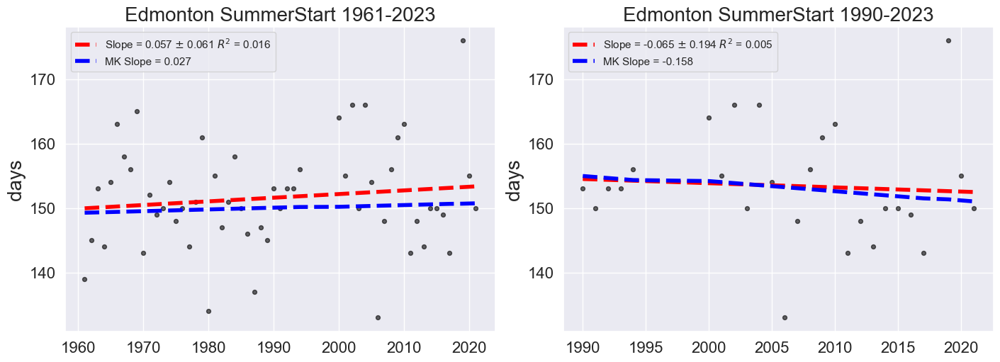

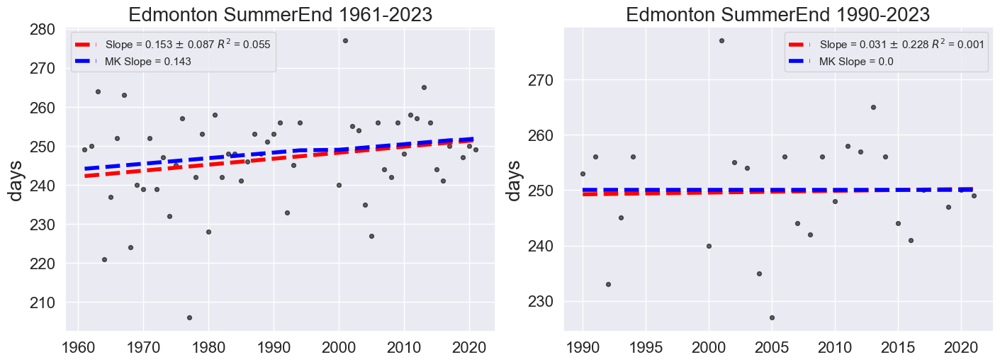

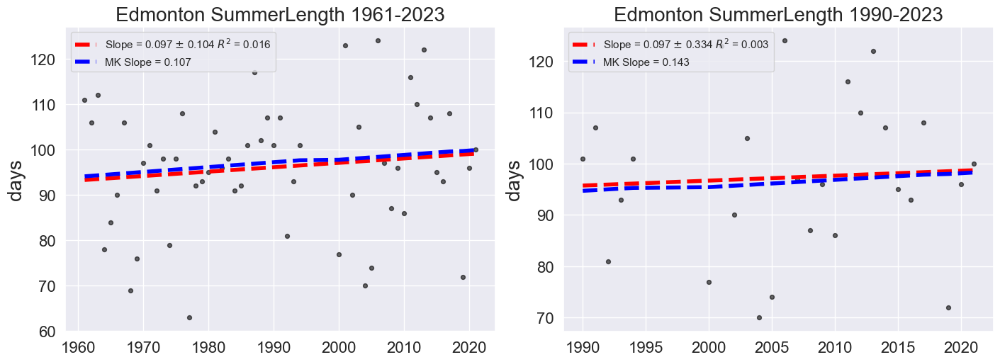

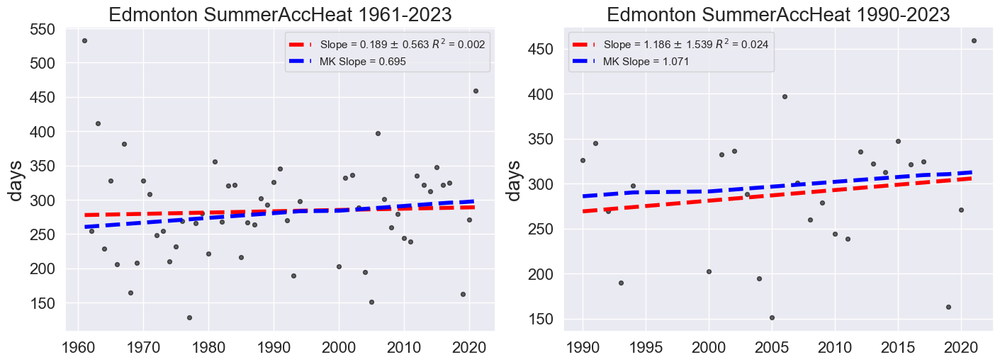

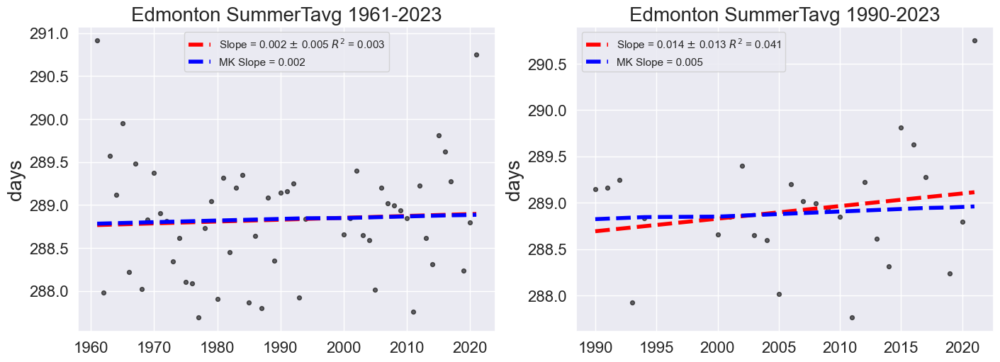

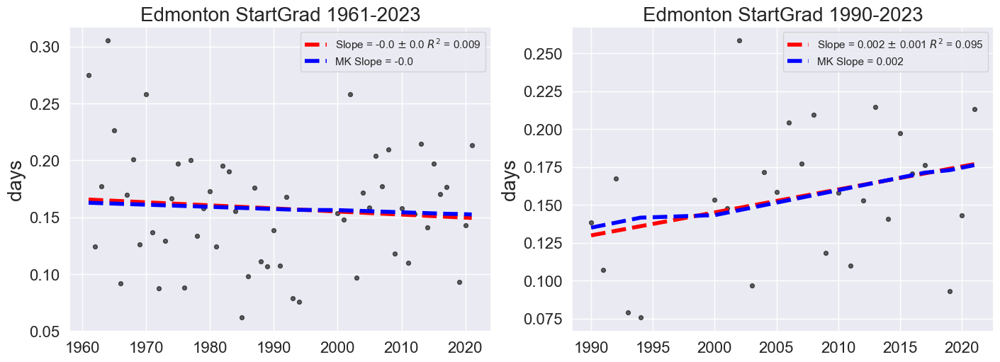

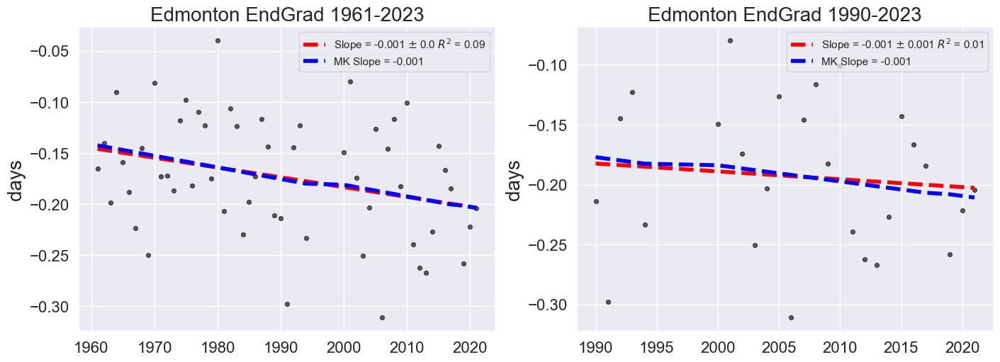

In [22]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Edmonton "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Edmonton "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

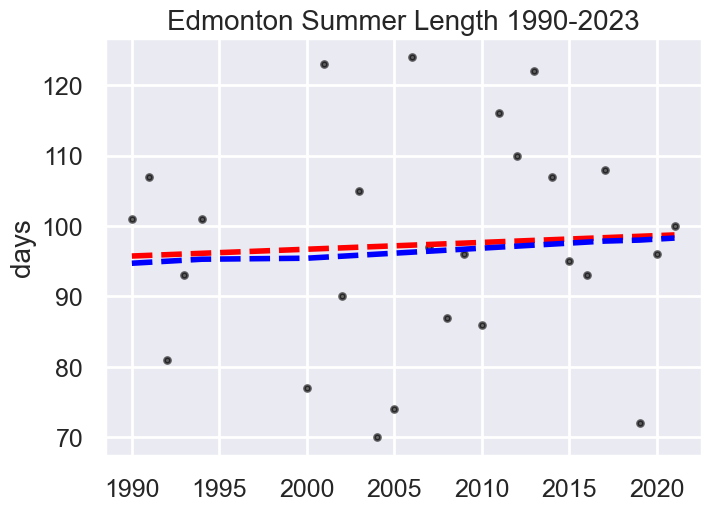

In [335]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Edmonton Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/Edmonton_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [23]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 53.75
    lon      float64 8B -113.5
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 53.75
    lon      float64 8B -113.5
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 0.97 +/- 3.3400000000000003
OLS Slope ERA5: 2.0 +/- 2.64


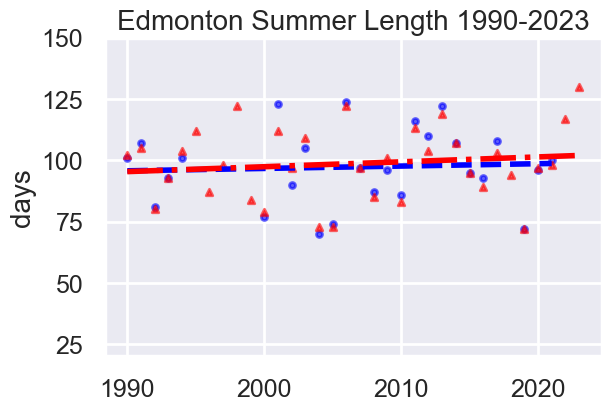

In [24]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Edmonton Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(20,150)
plt.savefig("../../../Data/GHCND/Plots/Edmonton_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Edmonton_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [338]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.038
Method:                 Least Squares   F-statistic:                   0.08341
Date:                Mon, 18 May 2026   Prob (F-statistic):              0.775
Time:                        13:55:08   Log-Likelihood:                -107.21
No. Observations:                  26   AIC:                             218.4
Df Residuals:                      24   BIC:                             220.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -96.3956    670.858     -0.144      0.8

In [339]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.018
Model:                            OLS   Adj. R-squared:                 -0.013
Method:                 Least Squares   F-statistic:                    0.5748
Date:                Mon, 18 May 2026   Prob (F-statistic):              0.454
Time:                        13:55:15   Log-Likelihood:                -139.47
No. Observations:                  34   AIC:                             282.9
Df Residuals:                      32   BIC:                             286.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -302.2875    528.916     -0.572      0.5

#### Accumulated Heat with ERA5 data

OLS Slope: 11.86 +/- 15.389999999999999
OLS Slope ERA5: 11.579999999999998 +/- 13.86


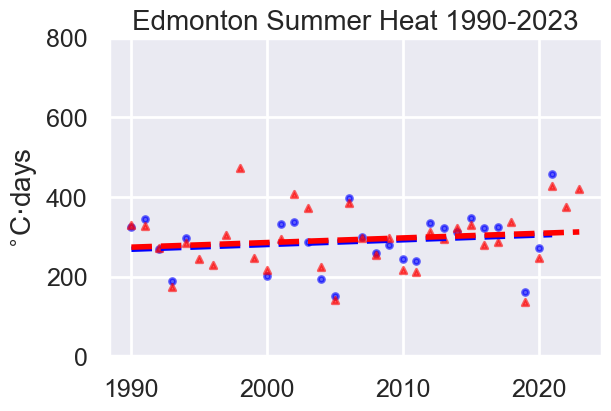

In [25]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Edmonton Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,800)
plt.savefig("../../../Data/GHCND/Plots/Edmonton_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Edmonton_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [341]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.024
Model:                            OLS   Adj. R-squared:                 -0.017
Method:                 Least Squares   F-statistic:                    0.5939
Date:                Mon, 18 May 2026   Prob (F-statistic):              0.448
Time:                        13:55:24   Log-Likelihood:                -146.91
No. Observations:                  26   AIC:                             297.8
Df Residuals:                      24   BIC:                             300.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2090.8198   3087.895     -0.677      0.5

In [342]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                 -0.009
Method:                 Least Squares   F-statistic:                    0.6984
Date:                Mon, 18 May 2026   Prob (F-statistic):              0.410
Time:                        13:55:34   Log-Likelihood:                -195.89
No. Observations:                  34   AIC:                             395.8
Df Residuals:                      32   BIC:                             398.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2030.1873   2780.371     -0.730      0.4

#### End Gradient with ERA5 data

In [343]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 53.75
    lon      float64 8B -113.5
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 53.75
    lon      float64 8B -113.5
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.0066 +/- 0.013500000000000002
OLS Slope ERA5: -0.0022 +/- 0.0078


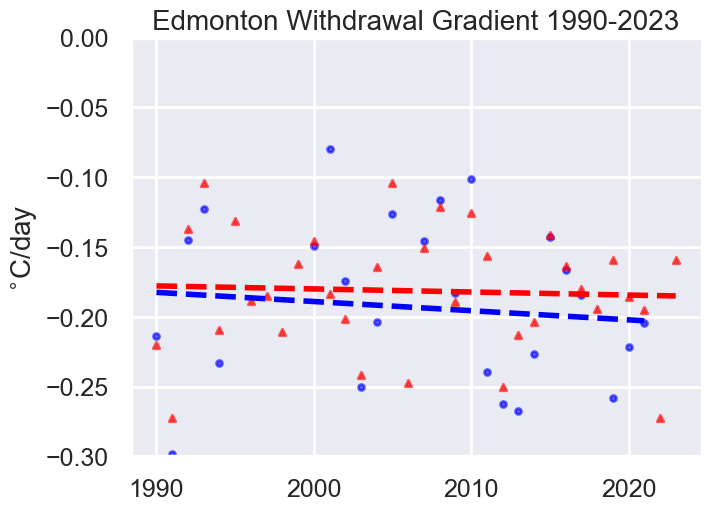

In [344]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Edmonton Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/Edmonton_summer_end_grad_plot_wERA5.png", bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Edmonton_summer_end_grad_plot_wERA5.pdf", bbox_inches='tight')



OLS Slope: 0.0151 +/- 0.0095
OLS Slope ERA5: 0.0167 +/- 0.0071


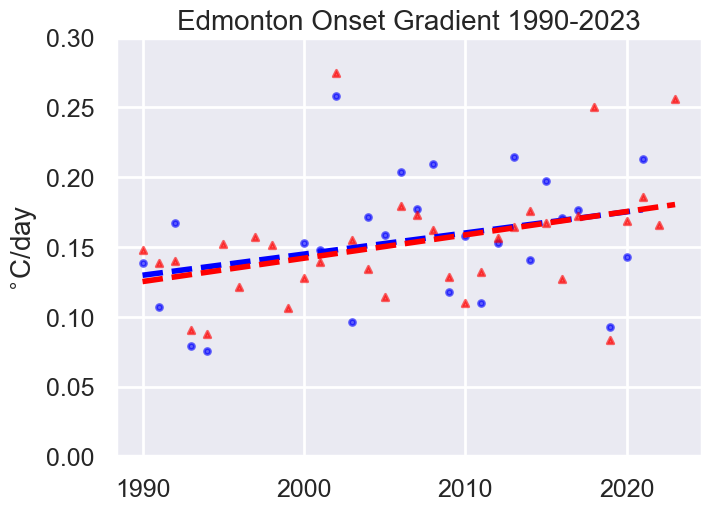

In [345]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Edmonton Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/Edmonton_summer_start_grad_plot_wERA5.png", bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Edmonton_summer_start_grad_plot_wERA5.pdf", bbox_inches='tight')




# Vancouver has complete data

#### site is CA001108395 and CA001108447

In [26]:
df2 = pd.read_csv("../../../Data/GHCND/api_downloads/vancouver2-2026-05-18T21-01-33.csv")
df2

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-01,NaN,6.7,2.2
1,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-02,NaN,6.7,-1.1
2,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-03,NaN,7.2,-1.1
3,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-04,NaN,7.2,3.9
4,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-05,NaN,7.2,5.0
...,...,...,...,...,...,...,...,...,...
19124,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2013-06-08,NaN,19.2,10.4
19125,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2013-06-09,NaN,18.2,11.5
19126,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2013-06-10,NaN,19.0,9.2
19127,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2013-06-11,NaN,18.9,11.9


In [27]:
df1 = pd.read_csv("../../../Data/GHCND/api_downloads/vancouver1-2026-05-18T16-57-49.csv")
df1

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1977-07-01,17.5,22.0,10.0
1,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1977-07-02,16.0,20.0,13.0
2,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1977-07-03,13.1,18.0,11.0
3,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1977-07-04,12.7,16.0,10.0
4,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1977-07-05,13.9,17.0,10.0
...,...,...,...,...,...,...,...,...,...
16606,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-27,9.2,11.9,6.5
16607,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-28,10.7,12.1,9.2
16608,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-29,10.0,12.4,7.5
16609,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-30,10.8,13.2,8.4


In [28]:
# reduce df1 to append to df2
df1['DATE'] = pd.to_datetime(df1['DATE'], format='%Y-%m-%d')
#filter_date = pd.to_datetime('2013-06-12')
df1 = df1.query("DATE > '2013-06-12'")
#df.reset_index()
df = pd.concat([df2, df1], axis=0, ignore_index=True)
#df.reset_index()
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-01,NaN,6.7,2.2
1,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-02,NaN,6.7,-1.1
2,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-03,NaN,7.2,-1.1
3,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-04,NaN,7.2,3.9
4,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-05,NaN,7.2,5.0
...,...,...,...,...,...,...,...,...,...
22971,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-27 00:00:00,9.2,11.9,6.5
22972,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-28 00:00:00,10.7,12.1,9.2
22973,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-29 00:00:00,10.0,12.4,7.5
22974,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-30 00:00:00,10.8,13.2,8.4


Timestamp('2013-06-12 00:00:00')

In [358]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22976 entries, 0 to 22975
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    22976 non-null  str    
 1   NAME       22976 non-null  str    
 2   LATITUDE   22976 non-null  float64
 3   LONGITUDE  22976 non-null  float64
 4   ELEVATION  22976 non-null  float64
 5   DATE       22976 non-null  object 
 6   TAVG       3813 non-null   float64
 7   TMAX       22930 non-null  float64
 8   TMIN       22936 non-null  float64
dtypes: float64(6), object(1), str(2)
memory usage: 2.5+ MB


### for this site TAVG must be calc from TMAX and TMIN if TAVG is empty

In [359]:
# can either use a lambda or fillna per https://datascience.stackexchange.com/questions/17769/how-to-fill-missing-value-based-on-other-columns-in-pandas-dataframe
df['TAVG'] = df['TAVG'].fillna((df['TMAX'] + df['TMIN'])/2.0)
df

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,TAVG,TMAX,TMIN
0,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-01,4.45,6.7,2.2
1,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-02,2.80,6.7,-1.1
2,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-03,3.05,7.2,-1.1
3,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-04,5.55,7.2,3.9
4,CA001108447,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,1961-01-05,6.10,7.2,5.0
...,...,...,...,...,...,...,...,...,...
22971,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-27 00:00:00,9.20,11.9,6.5
22972,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-28 00:00:00,10.70,12.1,9.2
22973,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-29 00:00:00,10.00,12.4,7.5
22974,CA001108395,"VANCOUVER INTERNATIONAL A, BC CA",49.2,-123.1833,4.0,2023-12-30 00:00:00,10.80,13.2,8.4


In [360]:
# check counts again
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22976 entries, 0 to 22975
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    22976 non-null  str    
 1   NAME       22976 non-null  str    
 2   LATITUDE   22976 non-null  float64
 3   LONGITUDE  22976 non-null  float64
 4   ELEVATION  22976 non-null  float64
 5   DATE       22976 non-null  object 
 6   TAVG       22938 non-null  float64
 7   TMAX       22930 non-null  float64
 8   TMIN       22936 non-null  float64
dtypes: float64(6), object(1), str(2)
memory usage: 2.5+ MB


In [361]:
df['DATE'] = pd.to_datetime(df['DATE'])
df_sub = pd.DataFrame({'time':df['DATE'],
                      #'lat':df['LATITUDE'],
                      #'lon':df['LONGITUDE'],
                      'tavg':df['TAVG'].to_list()})
df_sub = df_sub.set_index(['time'])#,'lat','lon'])

# convert to Kelvin
df_sub['tavg'] = df_sub['tavg'] + 273.15
df_sub

,tavg
time,
1961-01-01,277.60
1961-01-02,275.95
1961-01-03,276.20
1961-01-04,278.70
1961-01-05,279.25
...,...
2023-12-27,282.35
2023-12-28,283.85
2023-12-29,283.15


#### dealing with some of the missing dates?

In [363]:
#df_sub.tail(365)
#df_sub.loc['2020-01-01':'2021-12-31'].head(300)
start = "1961-01-01"
end = "2023-12-31"

# got help from https://www.geeksforgeeks.org/check-missing-dates-in-pandas/
print(pd.date_range(
  start=start, end=end).difference(df_sub.index))

print(pd.date_range(
  start=start, end=end).difference(df_sub.index).size)


DatetimeIndex(['1992-12-05', '1992-12-12', '1992-12-18', '1992-12-27',
               '1993-01-03', '1993-01-04', '1993-01-20', '1993-02-19',
               '1993-02-21', '1993-03-08', '1993-04-19', '1993-05-14',
               '1993-05-29', '1993-06-03', '1993-06-24', '1993-07-14',
               '1993-07-18', '1993-07-23', '1993-08-21', '1993-09-05',
               '1993-10-17', '1993-12-04', '1993-12-31', '1995-12-01',
               '1995-12-02', '1995-12-03', '1995-12-04', '2015-06-01',
               '2015-06-02', '2017-02-27', '2017-02-28', '2017-03-01',
               '2017-03-02', '2017-03-03'],
              dtype='datetime64[us]', freq=None)
34


#### just a few missing dates

In [364]:
df_missing = pd.DataFrame({'time':pd.to_datetime(['1992-12-05', '1992-12-12', '1992-12-18', '1992-12-27',
               '1993-01-03', '1993-01-04', '1993-01-20', '1993-02-19',
               '1993-02-21', '1993-03-08', '1993-04-19', '1993-05-14',
               '1993-05-29', '1993-06-03', '1993-06-24', '1993-07-14',
               '1993-07-18', '1993-07-23', '1993-08-21', '1993-09-05',
               '1993-10-17', '1993-12-04', '1993-12-31', '1995-12-01',
               '1995-12-02', '1995-12-03', '1995-12-04', '2015-06-01',
               '2015-06-02', '2017-02-27', '2017-02-28', '2017-03-01',
               '2017-03-02', '2017-03-03']),
                            'tavg':np.repeat(np.nan, 34)})
df_missing = df_missing.set_index(['time'])
df_missing
                                                 

,tavg
time,
1992-12-05,NaN
1992-12-12,NaN
1992-12-18,NaN
1992-12-27,NaN
1993-01-03,NaN
1993-01-04,NaN
1993-01-20,NaN
1993-02-19,NaN
1993-02-21,NaN


In [365]:
df_sub = pd.concat([df_sub, df_missing], axis=0).sort_index()
df_sub

,tavg
time,
1961-01-01,277.60
1961-01-02,275.95
1961-01-03,276.20
1961-01-04,278.70
1961-01-05,279.25
...,...
2023-12-27,282.35
2023-12-28,283.85
2023-12-29,283.15


In [366]:
# linear interpolation to fill the missing ones
df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
print(df_sub[df_sub.isna().any(axis=1)])

Empty DataFrame
Columns: [tavg]
Index: []


#### all cleaned up!

In [367]:
# linear interpolation to fill the last few
#df_sub['tavg'] = df_sub['tavg'].interpolate(method='linear')
df_sub.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 23010 entries, 1961-01-01 to 2023-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tavg    23010 non-null  float64
dtypes: float64(1)
memory usage: 359.5 KB


### Convert from Pandas to XArray

In [368]:
da_stp = df_sub.to_xarray()
da_stp.tavg.attrs['units'] = "Degrees [K]"
da_stp.tavg.attrs['long_name'] = "Mean temperature"
da_stp

<xarray.Dataset> Size: 368kB
Dimensions:  (time: 23010)
Coordinates:
  * time     (time) datetime64[us] 184kB 1961-01-01 1961-01-02 ... 2023-12-31
Data variables:
    tavg     (time) float64 184kB 277.6 275.9 276.2 278.7 ... 283.1 283.9 280.4

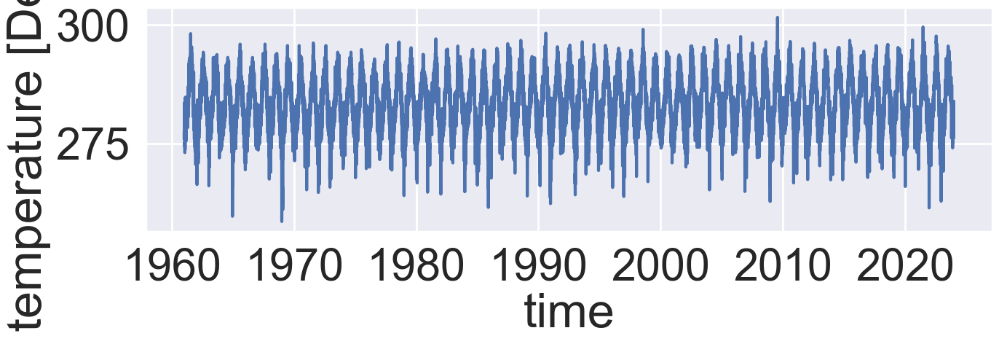

In [369]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('1961','2023')).plot()

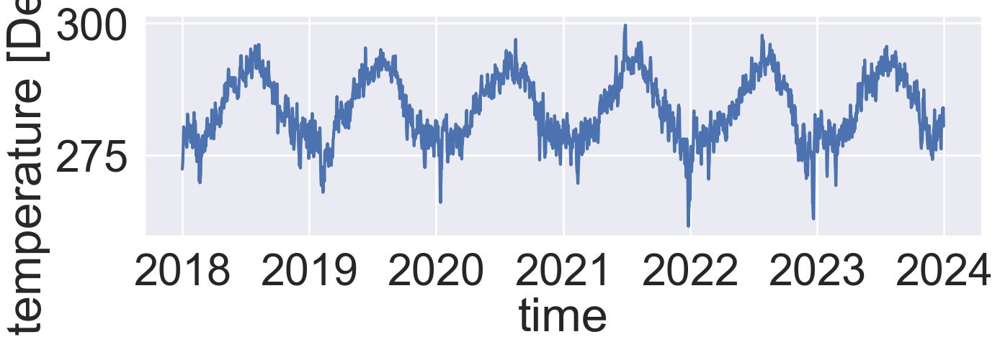

In [370]:
plt.figure(figsize=(15,4))
da_stp.tavg.sel(time=slice('2018','2023')).plot()

### Calculate the threshold temp from 1961-1990, 75%-ile

In [371]:
# get threshold for this location
thresh = c_75.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(thresh)

<xarray.DataArray 't2m' ()> Size: 8B
array(287.43515)
Coordinates:
    lat       float64 8B 49.25
    lon       float64 8B -123.2
    quantile  float64 8B ...
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K


####  Calculate it from the observational data instead for comparison

In [372]:
%%time
#c_75 = ds.t2m.where(ds.t2m != 0).quantile(0.75, dim=('time'))
stp_75 = da_stp.tavg.quantile(0.75, dim=('time'))
stp_75.attrs["long_name"] = "75th percentile 2m Temperature for the data across available time dimension"
stp_75.attrs["units"] = "K"
stp_75

CPU times: user 3.23 ms, sys: 1.96 ms, total: 5.19 ms
Wall time: 3.43 ms


<xarray.DataArray 'tavg' ()> Size: 8B
array(288.25)
Coordinates:
    quantile  float64 8B 0.75
Attributes:
    long_name:  75th percentile 2m Temperature for the data across available ...
    units:      K

In [373]:
thresh.values - stp_75.values

np.float64(-0.814849853515625)

#### Vancouver 75th Percentile from GHCND data is 0.8 K warmer

### Try one year (2023) fit via Fourier

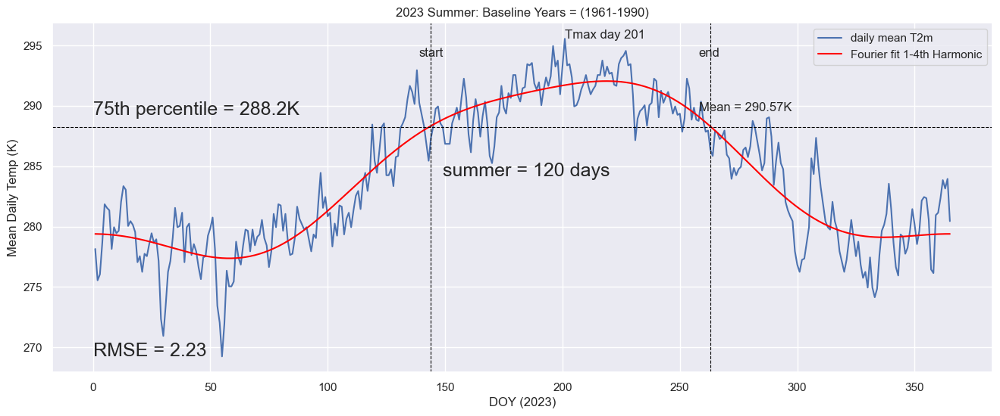

(144,
 263,
 0.10859465650813149,
 -0.17372251677193162,
 201,
 299.09999999999854,
 120,
 2.2336592595496616,
 0.0,
 290.5658333333333,
 2.848571428571404)

In [374]:
input_year = 2023

da = da_stp.sel(time=str(input_year))
# since this is in the NH don't really need a next year
da_next = da_stp.sel(time=str(input_year))
da = HandleLeapYears(da)
da_next = HandleLeapYears(da_next)

curr = da.tavg
nxt = da_next.tavg
thresh = stp_75
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, True, True, True, True)
start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs

### Main Loop: loop through multiple years to generate summer stats.

In [375]:
# process_yrs = [1990,1991,1992,1993, 1994, 1995, 1996, 1997, 1998, 1999, 2002, 2004, 2005, 2006, 2007, 2008,
#               2009, 2010, 2011, 2012, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
process_yrs = np.arange(1961, 2024,1)
# process_yrs2 = np.arange(1992,1994,1)
# process_yrs3 = np.arange(1997,2024,1)

# process_yrs_tmp = np.append(process_yrs, process_yrs2)
# process_yrs = np.append(process_yrs_tmp, process_yrs3)
process_yrs

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [376]:
%%time

# Runtime: XX min for 1 year
# XXX for 10 years
# XXX for 64 years

# empty dataframe for the results
df_summ = pd.DataFrame({"Year":[],
                        "SummerStart":[],
                        "SummerEnd":[],
                        "StartGrad":[],
                        "EndGrad":[],
                        "SummerLength":[],
                        "SummerAccHeat":[],
                        "SummerTmaxDay":[],
                        "SummerTavg":[]})#.set_index(["Year"])


# loop thru the years in the defined array above
for input_year in process_yrs:

    print("Processing year: "+str(input_year))
    da = da_stp.sel(time=str(input_year))
    # since this is in the NH don't really need a next year
    da_next = da_stp.sel(time=str(input_year))
    da = HandleLeapYears(da)
    da_next = HandleLeapYears(da_next)
    
    curr = da.tavg
    nxt = da_next.tavg
    thresh = stp_75
    start_day, last_day, grad_start, grad_end, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs = SummerStatsFourier(curr, nxt, thresh, False, True, True, True)

    #print(start_day, last_day, day_of_max, acc_heat, summer_length, rmse, r2, mean_temp, mean_hs)
    #### Build up a dataframe of the values for later plotting ####
    df_tmp = pd.DataFrame({"Year":[(input_year)],
                        "SummerStart":[(start_day)],
                        "SummerEnd":[(last_day)],
                        "StartGrad":[(grad_start)],
                        "EndGrad":[(grad_end)],
                        "SummerLength":[(summer_length)],
                        "SummerAccHeat":[(acc_heat)],
                        "SummerTmaxDay":[(day_of_max)],
                        "SummerTavg":[(mean_temp)]
                          })#.set_index(["Year"])
    df_summ = pd.concat([df_summ, df_tmp], ignore_index=True)


# output results
df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]] = df_summ[["Year","SummerStart","SummerEnd","SummerLength","SummerTmaxDay"]].astype(int)
df_summ



Processing year: 1961
Processing year: 1962
Processing year: 1963
Processing year: 1964
Processing year: 1965
Processing year: 1966
Processing year: 1967
Processing year: 1968
Processing year: 1969
Processing year: 1970
Processing year: 1971
Processing year: 1972
Processing year: 1973
Processing year: 1974
Processing year: 1975
Processing year: 1976
Processing year: 1977
Processing year: 1978
Processing year: 1979
Processing year: 1980
Processing year: 1981
Processing year: 1982
Processing year: 1983
Processing year: 1984
Processing year: 1985
Processing year: 1986
Processing year: 1987
Processing year: 1988
Processing year: 1989
Processing year: 1990
Processing year: 1991
Processing year: 1992
Processing year: 1993
Processing year: 1994
Processing year: 1995
Processing year: 1996
Processing year: 1997
Processing year: 1998
Processing year: 1999
Processing year: 2000
Processing year: 2001
Processing year: 2002
Processing year: 2003
Processing year: 2004
Processing year: 2005
Processing

,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,1961,154,253,0.123576,-0.177354,100,289.40,194,291.028500
1,1962,169,253,0.091743,-0.101305,85,154.45,209,289.911176
2,1963,166,266,0.063076,-0.124475,101,159.90,252,289.566337
3,1964,173,240,0.072807,-0.063401,68,79.15,209,289.211029
4,1965,166,244,0.131419,-0.095127,79,166.65,213,289.999367
...,...,...,...,...,...,...,...,...,...
58,2019,151,258,0.054287,-0.213384,108,297.90,163,290.962037
59,2020,157,265,0.064539,-0.172634,109,243.50,229,290.341743
60,2021,152,255,0.161800,-0.149793,104,366.00,180,291.612500
61,2022,163,270,0.124206,-0.207908,108,318.60,208,291.067593


#### all filled in

### write out resulting summer stats

In [377]:
# write out results
output_path = "../../../Data/GHCND/Vancouver_summer_stats.csv"
df_summ.to_csv(output_path)

### read back in for adding MK slopes (2025-04-21)

In [29]:
# re-load 
input_path = "../../../Data/GHCND/Vancouver_summer_stats.csv"
df_summ = pd.read_csv(input_path)
df_summ

,Unnamed: 0,Year,SummerStart,SummerEnd,StartGrad,EndGrad,SummerLength,SummerAccHeat,SummerTmaxDay,SummerTavg
0,0,1961,154,253,0.123576,-0.177354,100,289.40,194,291.028500
1,1,1962,169,253,0.091743,-0.101305,85,154.45,209,289.911176
2,2,1963,166,266,0.063076,-0.124475,101,159.90,252,289.566337
3,3,1964,173,240,0.072807,-0.063401,68,79.15,209,289.211029
4,4,1965,166,244,0.131419,-0.095127,79,166.65,213,289.999367
...,...,...,...,...,...,...,...,...,...,...
58,58,2019,151,258,0.054287,-0.213384,108,297.90,163,290.962037
59,59,2020,157,265,0.064539,-0.172634,109,243.50,229,290.341743
60,60,2021,152,255,0.161800,-0.149793,104,366.00,180,291.612500
61,61,2022,163,270,0.124206,-0.207908,108,318.60,208,291.067593


### Vancouver: Plot the summer stats

In [379]:
plot_vars = ["SummerStart","SummerEnd","SummerLength","SummerAccHeat","SummerTavg","StartGrad","EndGrad"]

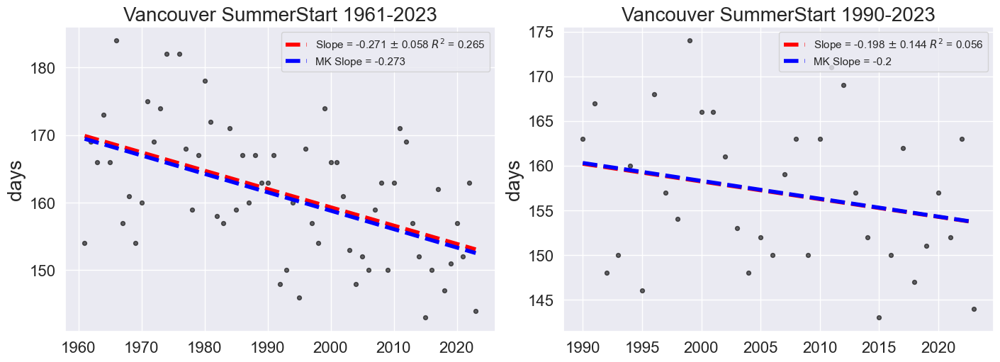

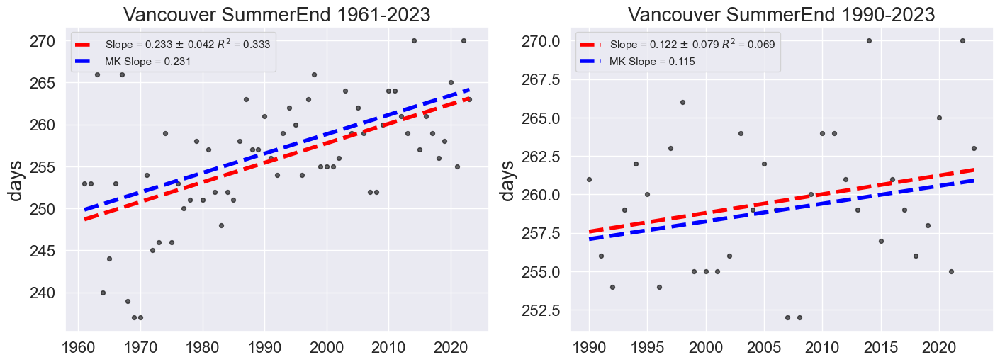

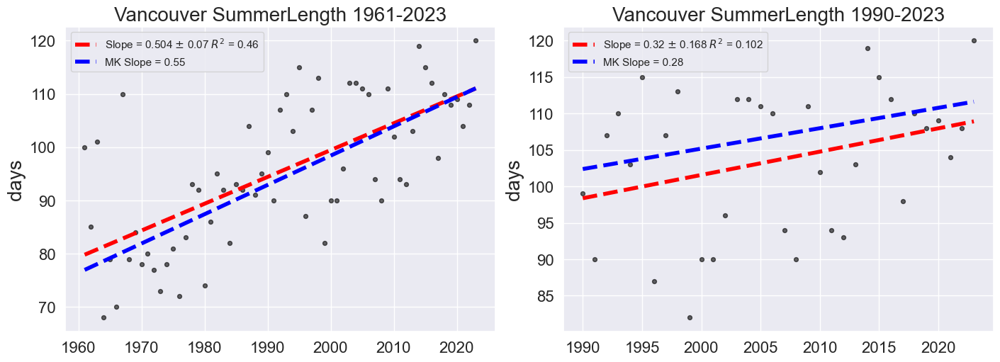

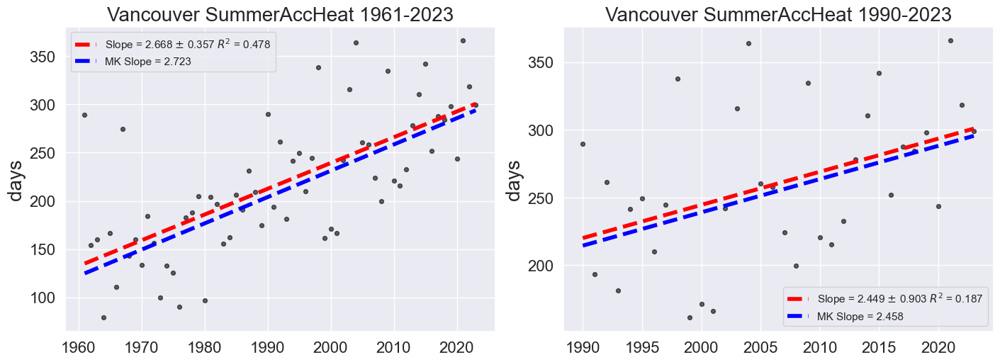

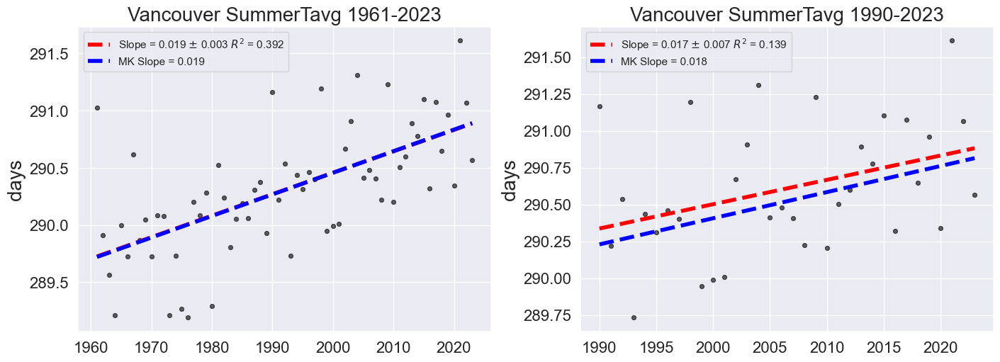

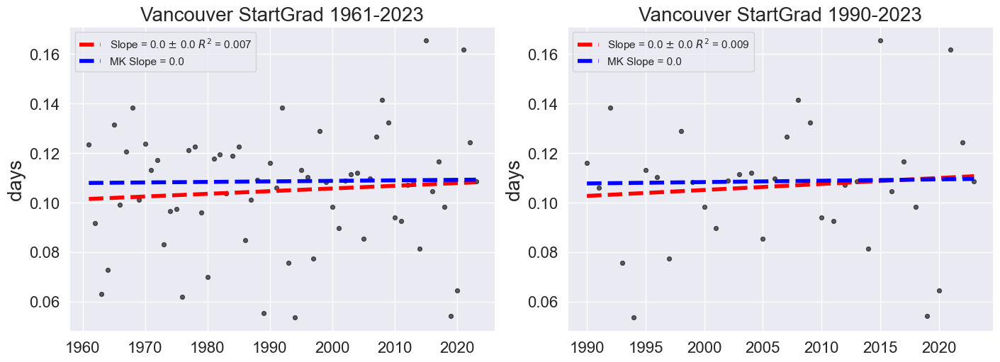

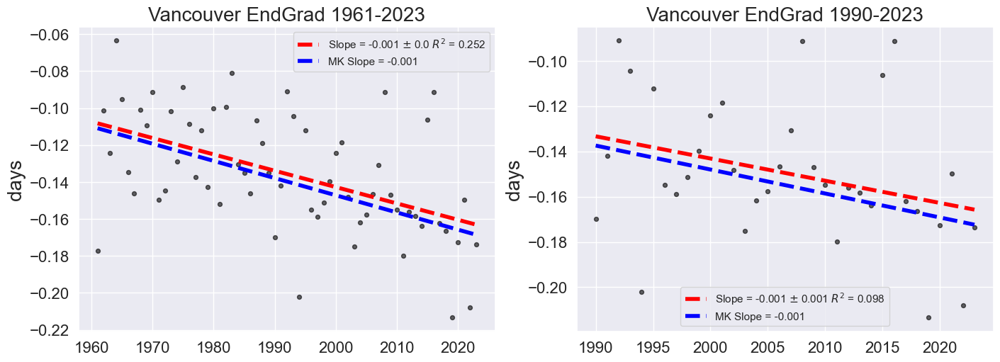

In [30]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")


# loop through all plot variables
for i,v in enumerate(plot_vars):


    # variables for plot
    x = df_summ.Year
    y = df_summ[v]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    # plot data for full period
    fig = plt.figure(figsize=(14,5), layout='constrained')
    
    ax1 = fig.add_subplot(1,2,1)
    ax1.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax1.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax1.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax1.set_title("Vancouver "+v+" 1961-2023", fontsize=fs)
    ax1.legend(loc="best")
    plt.tick_params('x', labelsize=16)
    plt.tick_params('y', labelsize=16)
    ax1.set_ylabel('days', fontsize=fs)
    
    
    # analysis period 1990-2023
    # variables for plot
    x = df_summ.Year[df_summ.Year >= 1990]
    y = df_summ[v][df_summ.Year >= 1990]
    
    # get linear fit and plot it with data
    coefs, V = np.polyfit(x, y, 1, cov=True)
    poly = np.poly1d(coefs)
    slope = np.round(coefs[0],3)
    slope_sd = np.round(np.sqrt(V[0][0]),3)  
    # add in R^2 and RMSE
    ymean = np.mean(y)
    ss_total = np.sum((y - ymean)**2)
    ss_res = np.sum((y - poly(x))**2)
    #rmse = np.sqrt(ss_res/365.0)
    r_squared = np.round(1 - (ss_res / ss_total),3)

    # add MK slope
    res_mk = mk.original_test(y)
    mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept
    
    ax2 = fig.add_subplot(1,2,2)
    ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
    ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
         label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
    ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
    ax2.set_title("Vancouver "+v+" 1990-2023", fontsize=fs)
    ax2.legend(loc="best")
    ax2.tick_params('x', labelsize=16)
    ax2.tick_params('y', labelsize=16)
    ax2.set_ylabel('days', fontsize=fs)
    


#### Summer Length Plot for Paper

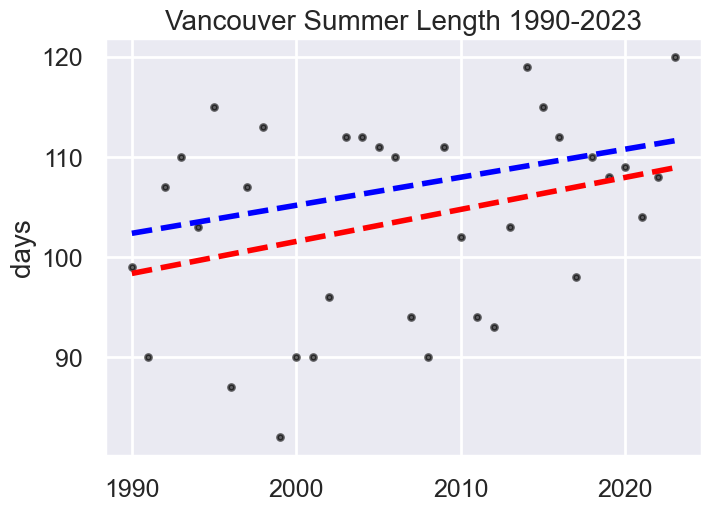

In [381]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  
# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="black", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='red', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))
ax2.set_title("Vancouver Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
plt.savefig("../../../Data/GHCND/Plots/Vancouver_summer_plot.png")



#### Plot with OLS fit to the ERA5 derived results for the nearest lat,lon

In [31]:
# get the ERA5 lengths
ds_len = ds.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_ht = ds_heat.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 49.25
    lon      float64 8B -123.2
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 49.25
    lon      float64 8B -123.2
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


OLS Slope: 3.2 +/- 1.6800000000000002
OLS Slope ERA5: 4.58 +/- 1.87


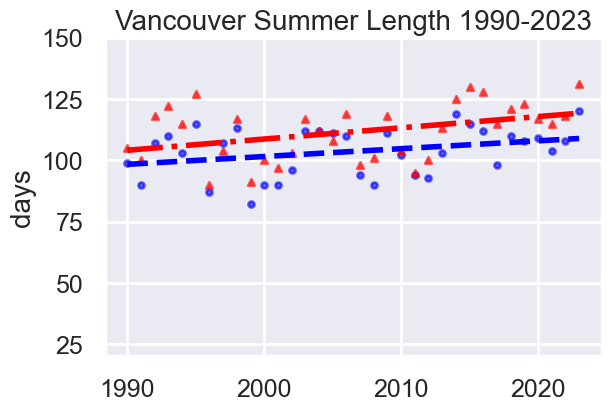

In [32]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerLength[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(6,4), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)

ax2.set_title("Vancouver Summer Length 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('days', fontsize=fs)
ax2.set_ylim(20,150)
plt.savefig("../../../Data/GHCND/Plots/Vancouver_summer_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Vancouver_summer_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [384]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           SummerLength   R-squared:                       0.102
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     3.630
Date:                Mon, 18 May 2026   Prob (F-statistic):             0.0658
Time:                        14:22:10   Log-Likelihood:                -124.10
No. Observations:                  34   AIC:                             252.2
Df Residuals:                      32   BIC:                             255.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -537.6972    336.629     -1.597      0.1

In [385]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.157
Model:                            OLS   Adj. R-squared:                  0.131
Method:                 Least Squares   F-statistic:                     5.975
Date:                Mon, 18 May 2026   Prob (F-statistic):             0.0202
Time:                        14:22:17   Log-Likelihood:                -127.83
No. Observations:                  34   AIC:                             259.7
Df Residuals:                      32   BIC:                             262.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -806.5004    375.641     -2.147      0.0

#### Accumulated Heat with ERA5 data

OLS Slope: 24.49 +/- 9.030000000000001
OLS Slope ERA5: 47.1 +/- 11.16


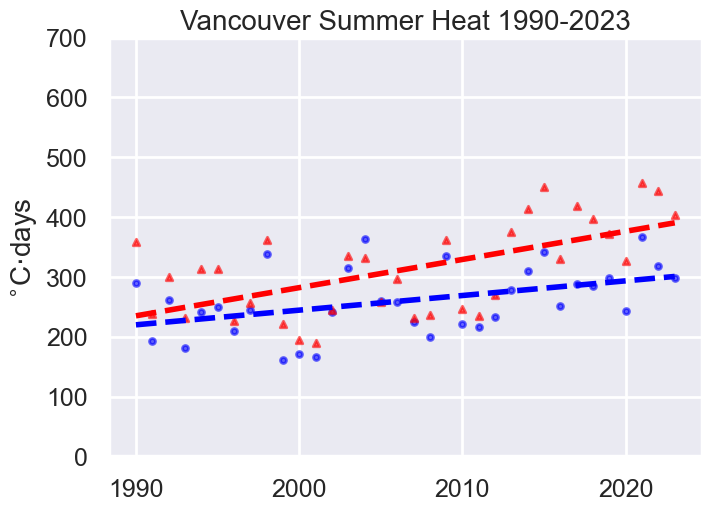

In [33]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.SummerAccHeat[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],3)
slope_sd = np.round(np.sqrt(V[0][0]),3)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_ht.time.dt.year.values
y_era = ds_ht.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Vancouver Summer Heat 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C$\cdot$days', fontsize=fs)
ax2.set_ylim(0,700)
plt.savefig("../../../Data/GHCND/Plots/Vancouver_summerheat_plot_wERA5.png",bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Vancouver_summerheat_plot_wERA5.pdf",bbox_inches='tight')



#### Statsmodels OLS for p-values

In [387]:
X_ols = sm.add_constant(x)          
y_ols = y                                  

# Fit the model
model = sm.OLS(y_ols, X_ols).fit()

# Show the summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          SummerAccHeat   R-squared:                       0.187
Model:                            OLS   Adj. R-squared:                  0.161
Method:                 Least Squares   F-statistic:                     7.353
Date:                Mon, 18 May 2026   Prob (F-statistic):             0.0107
Time:                        14:22:33   Log-Likelihood:                -181.34
No. Observations:                  34   AIC:                             366.7
Df Residuals:                      32   BIC:                             369.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -4654.1758   1812.478     -2.568      0.0

In [388]:
X_ols2 = sm.add_constant(x_era)          
y_ols2 = y_era                                  

# Fit the model
model2 = sm.OLS(y_ols2, X_ols2).fit()

# Show the summary
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.358
Model:                            OLS   Adj. R-squared:                  0.338
Method:                 Least Squares   F-statistic:                     17.83
Date:                Mon, 18 May 2026   Prob (F-statistic):           0.000187
Time:                        14:22:36   Log-Likelihood:                -188.52
No. Observations:                  34   AIC:                             381.0
Df Residuals:                      32   BIC:                             384.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -9138.2274   2238.352     -4.083      0.0

#### End Gradient with ERA5 data

In [389]:
ds_end = ds_grad.GradientSummEndFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
ds_start = ds_grad.GradientSummStartFourier.sel(lat=df.LATITUDE[0], lon=df.LONGITUDE[0], method="nearest")
print(ds_end, ds_start)

<xarray.DataArray 'GradientSummEndFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 49.25
    lon      float64 8B -123.2
Attributes:
    long_name:  Gradient of Fourier Fit at Summer End
    units:      Deg/Day <xarray.DataArray 'GradientSummStartFourier' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 49.25
    lon      float64 8B -123.2
Attributes:
    long_name:  Gradient of Fourier Fit at Summer Start
    units:      Deg/Day


OLS Slope: -0.0098 +/- 0.0053
OLS Slope ERA5: -0.0087 +/- 0.0035


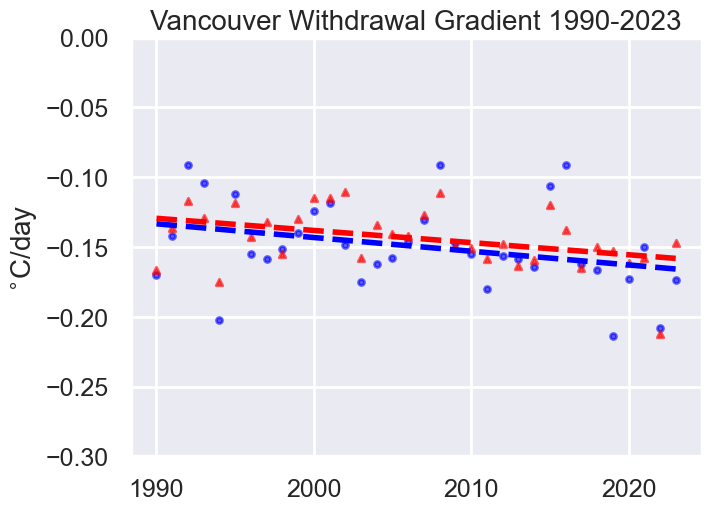

In [390]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.EndGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_end.time.dt.year.values
y_era = ds_end.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Vancouver Withdrawal Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(-0.3,0)
plt.savefig("../../../Data/GHCND/Plots/Vancouver_summer_end_grad_plot_wERA5.png", bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Vancouver_summer_end_grad_plot_wERA5.pdf", bbox_inches='tight')



OLS Slope: 0.0024000000000000002 +/- 0.0046
OLS Slope ERA5: 0.0086 +/- 0.0029999999999999996


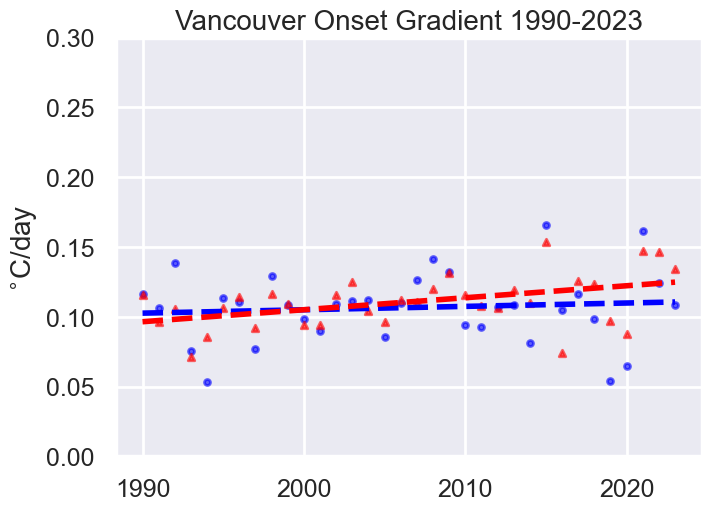

In [391]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('poster', font_scale = 2)


# analysis period 1990-2023
# variables for plot
x = df_summ.Year[df_summ.Year >= 1990]
y = df_summ.StartGrad[df_summ.Year >= 1990]

# get linear fit and plot it with data
coefs, V = np.polyfit(x, y, 1, cov=True)
poly = np.poly1d(coefs)
slope = np.round(coefs[0],5)
slope_sd = np.round(np.sqrt(V[0][0]),5)  

print("OLS Slope: "+str(slope*10)+" +/- "+str(slope_sd*10))

# add in R^2 and RMSE
ymean = np.mean(y)
ss_total = np.sum((y - ymean)**2)
ss_res = np.sum((y - poly(x))**2)
#rmse = np.sqrt(ss_res/365.0)
r_squared = np.round(1 - (ss_res / ss_total),3)

# add MK slope
res_mk = mk.original_test(y)
mk_trend = np.arange(len(y)) * res_mk.slope + res_mk.intercept

# ERA5 OLS fit as well
x_era = ds_start.time.dt.year.values
y_era = ds_start.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],5)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),5)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(7,5), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.scatter(x, y, label="", c="blue", s=s, alpha=alpha)
ax2.plot(x, poly(x), linestyle="dashed", linewidth=lw, color='blue', 
     label="Slope = "+str(slope)+" $\pm$ "+str(slope_sd)+" $R^2$ = "+str(r_squared))
#ax2.plot(x, mk_trend, linestyle="dashed", linewidth=lw, color='blue', label="MK Slope = "+str(np.round(res_mk.slope,3)))

# MK trend to ERA5
#res_mk_era = mk.original_test(y_era)
#mk_trend_era = np.arange(len(y_era)) * res_mk_era.slope + res_mk_era.intercept
#print("MK Slope ERA5: "+str(res_mk_era.slope*10))
#ax2.plot(x_era, mk_trend_era, linestyle="dotted", linewidth=lw, color='purple', label="")

ax2.plot(x_era, poly_era(x_era), linestyle="dashed", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^', alpha=alpha)

ax2.set_title("Vancouver Onset Gradient 1990-2023", fontsize=fs)
#ax2.legend(loc="best")
ax2.tick_params('x', labelsize=18)
ax2.tick_params('y', labelsize=18)
ax2.set_ylabel('$^{\circ}$C/day', fontsize=fs)
ax2.set_ylim(0,0.3)
plt.savefig("../../../Data/GHCND/Plots/Vancouver_summer_start_grad_plot_wERA5.png", bbox_inches='tight')
plt.savefig("../../../Data/GHCND/Plots/Vancouver_summer_start_grad_plot_wERA5.pdf", bbox_inches='tight')




# Prince George

#### site is CA001096439 and CA001096450 but there may be overlap?

In [3]:
pg_lat = 54
pg_lon = -122.75

# get the ERA5 lengths
ds_len = ds.sel(lat=pg_lat, lon=pg_lon, method="nearest")
ds_ht = ds_heat.sel(lat=pg_lat, lon=pg_lon, method="nearest")
print(ds_len, ds_ht)

<xarray.DataArray 'SummerLength' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 54.0
    lon      float64 8B -122.8
Attributes:
    long_name:  Duration of summer for the year
    units:      Days <xarray.DataArray 'SummerHeat' (time: 34)> Size: 272B
[34 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 272B 1990-01-01 1991-01-01 ... 2023-01-01
    lat      float64 8B 54.0
    lon      float64 8B -122.8
Attributes:
    long_name:  Accumulated heat during summer for the year
    units:      Degree-Days


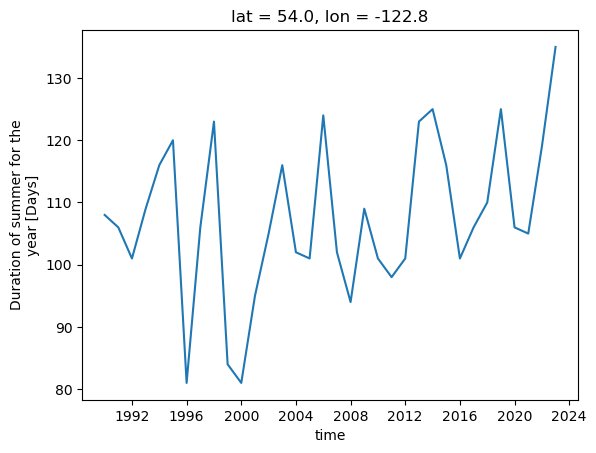

In [4]:
ds_len.plot()

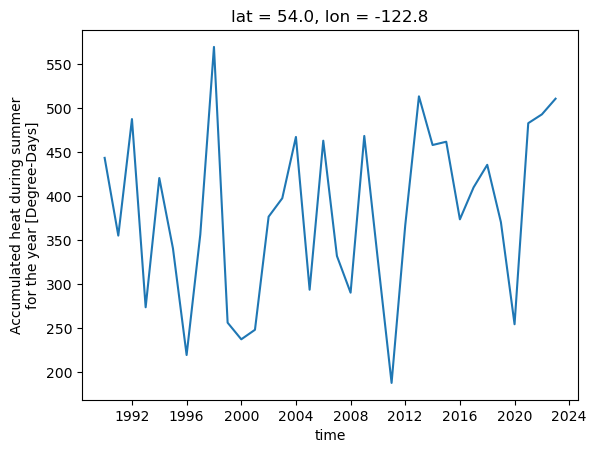

In [5]:
ds_ht.plot()

OLS Slope ERA5: 4.1 +/- 2.13


Text(0.5, 1.0, 'Prince George Length from ERA5')

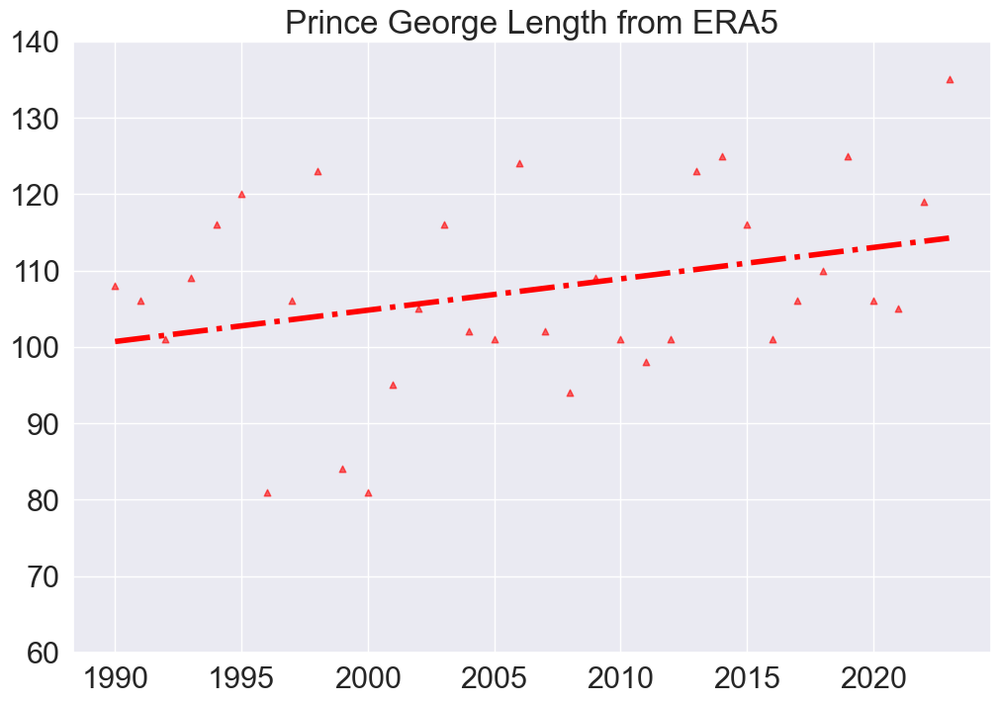

In [15]:
# plot properties so I can more easily tweak them
s = 18
lw = 4
alpha = 0.6
fs = 20
sns.set_theme(style="darkgrid")
sns.set_context('notebook', font_scale = 2)

# ERA5 OLS fit as well
x_era = ds_len.time.dt.year.values
y_era = ds_len.values

coefs_era, V_era = np.polyfit(x_era, y_era, 1, cov=True)
poly_era = np.poly1d(coefs_era)
slope_era = np.round(coefs_era[0],3)
slope_sd_era = np.round(np.sqrt(V_era[0][0]),3)
print("OLS Slope ERA5: "+str(slope_era*10)+" +/- "+str(slope_sd_era*10))

fig = plt.figure(figsize=(10,7), layout='constrained')
ax2 = fig.add_subplot(1,1,1)
ax2.plot(x_era, poly_era(x_era), linestyle="-.", linewidth=lw, color='red')
ax2.scatter(x_era, y_era, label="", c="red", s=s+4, marker='^',alpha=alpha)
ax2.set_ylim(60,140)
ax2.set_title("Prince George Length from ERA5")